In [2]:
from pathlib import Path

# Корень подключенного S3-бакета
S3_ROOT = Path("/home/jupyter/s3/neuralinterfaces-train")

print("S3 существует:", S3_ROOT.exists())
print("Путь:", S3_ROOT)

# Показываем содержимое
files = list(S3_ROOT.rglob("*"))

print(f"\nВсего объектов: {len(files)}")

for path in files[:30]:
    print(path)

S3 существует: True
Путь: /home/jupyter/s3/neuralinterfaces-train

Всего объектов: 65
/home/jupyter/s3/neuralinterfaces-train/Data
/home/jupyter/s3/neuralinterfaces-train/Montage.mat
/home/jupyter/s3/neuralinterfaces-train/example.py
/home/jupyter/s3/neuralinterfaces-train/solution
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.01.16.04.01_N01.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.04.13.29.33_N01.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.08.14.19.05_N02.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.09.12.52.43_N01.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.11.12.13.46_N03.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.11.15.27.59_N02.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.11.15.43.58_N02.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.15.12.52.57_N03.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.15.13.16.37_N03.mat
/home/jupyter/s3/neuralinterfaces-train/Data/2025.12.18.12.0

In [3]:
from pathlib import Path
from scipy.io import loadmat

# Путь к одному эксперименту
DATA_DIR = Path("/home/jupyter/s3/neuralinterfaces-train/Data")

FILE_PATH = DATA_DIR / "2025.12.01.16.04.01_N01.mat"

print("Файл:", FILE_PATH)
print("Существует:", FILE_PATH.exists())

if FILE_PATH.exists():
    print(f"Размер: {FILE_PATH.stat().st_size / 1024**2:.2f} MB")


# Загружаем MATLAB-файл
try:
    mat = loadmat(
        FILE_PATH,
        simplify_cells=True
    )

    print("\nФайл успешно загружен через scipy.io.loadmat")

    print("\nОбъекты верхнего уровня:")
    for key, value in mat.items():
        if not key.startswith("__"):
            print(f"  {key}: {type(value)}")

except NotImplementedError:
    print("\nЭтот .mat имеет формат MATLAB v7.3.")
    print("Будем читать его через h5py.")

Файл: /home/jupyter/s3/neuralinterfaces-train/Data/2025.12.01.16.04.01_N01.mat
Существует: True
Размер: 22.02 MB

Файл успешно загружен через scipy.io.loadmat

Объекты верхнего уровня:
  EEG: <class 'dict'>
  NIRS: <class 'dict'>


In [4]:
import numpy as np

# Проверяем верхний уровень
print("EEG fields:")
for key, value in mat["EEG"].items():
    if isinstance(value, np.ndarray):
        print(f"  {key:12s} | shape={value.shape} | dtype={value.dtype}")
    else:
        print(f"  {key:12s} | type={type(value)}")


print("\nNIRS fields:")
for key, value in mat["NIRS"].items():
    if isinstance(value, np.ndarray):
        print(f"  {key:12s} | shape={value.shape} | dtype={value.dtype}")
    else:
        print(f"  {key:12s} | type={type(value)}")

EEG fields:
  Raw          | shape=(149550, 21) | dtype=float64
  States       | shape=(149550,) | dtype=uint8
  Blocks       | shape=(149550,) | dtype=uint8
  Frq          | type=<class 'int'>

NIRS fields:
  HbO          | shape=(7480, 18) | dtype=float64
  HbR          | shape=(7480, 18) | dtype=float64
  States       | shape=(7480,) | dtype=uint8
  Blocks       | shape=(7480,) | dtype=uint8
  Frq          | type=<class 'float'>
  Frame        | shape=(7480,) | dtype=int32


In [5]:
import numpy as np

eeg = mat["EEG"]
nirs = mat["NIRS"]

# =========================
# 1. Частоты дискретизации
# =========================

eeg_fs = float(eeg["Frq"])
nirs_fs = float(nirs["Frq"])

print("=== SAMPLING RATES ===")
print(f"EEG:  {eeg_fs} Hz")
print(f"NIRS: {nirs_fs} Hz")


# =========================
# 2. Размеры и длительность
# =========================

n_eeg_samples, n_eeg_channels = eeg["Raw"].shape
n_nirs_samples, n_nirs_channels = nirs["HbO"].shape

eeg_duration = n_eeg_samples / eeg_fs
nirs_duration = n_nirs_samples / nirs_fs

print("\n=== DATA SIZE ===")
print(f"EEG samples:    {n_eeg_samples}")
print(f"EEG channels:   {n_eeg_channels}")
print(f"EEG duration:   {eeg_duration:.3f} s")

print(f"\nNIRS samples:   {n_nirs_samples}")
print(f"NIRS channels:  {n_nirs_channels}")
print(f"NIRS duration:  {nirs_duration:.3f} s")


# =========================
# 3. EEG States
# =========================

eeg_states = eeg["States"]

unique_eeg_states, eeg_state_counts = np.unique(
    eeg_states,
    return_counts=True
)

print("\n=== EEG STATES ===")

for state, count in zip(unique_eeg_states, eeg_state_counts):
    print(
        f"State {int(state)}: "
        f"{count:6d} samples "
        f"({100 * count / len(eeg_states):6.2f}%)"
    )


# =========================
# 4. NIRS States
# =========================

nirs_states = nirs["States"]

unique_nirs_states, nirs_state_counts = np.unique(
    nirs_states,
    return_counts=True
)

print("\n=== NIRS STATES ===")

for state, count in zip(unique_nirs_states, nirs_state_counts):
    print(
        f"State {int(state)}: "
        f"{count:6d} samples "
        f"({100 * count / len(nirs_states):6.2f}%)"
    )


# =========================
# 5. EEG Blocks
# =========================

eeg_blocks = eeg["Blocks"]

unique_eeg_blocks, eeg_block_counts = np.unique(
    eeg_blocks,
    return_counts=True
)

print("\n=== EEG BLOCKS ===")

for block, count in zip(unique_eeg_blocks, eeg_block_counts):
    print(
        f"Block {int(block)}: "
        f"{count:6d} samples "
        f"({100 * count / len(eeg_blocks):6.2f}%)"
    )


# =========================
# 6. NIRS Blocks
# =========================

nirs_blocks = nirs["Blocks"]

unique_nirs_blocks, nirs_block_counts = np.unique(
    nirs_blocks,
    return_counts=True
)

print("\n=== NIRS BLOCKS ===")

for block, count in zip(unique_nirs_blocks, nirs_block_counts):
    print(
        f"Block {int(block)}: "
        f"{count:6d} samples "
        f"({100 * count / len(nirs_blocks):6.2f}%)"
    )


# =========================
# 7. NIRS -> EEG mapping
# =========================

frame = nirs["Frame"]

print("\n=== NIRS FRAME ===")

print(f"Frame dtype: {frame.dtype}")
print(f"Frame shape: {frame.shape}")

print(f"Frame min:   {frame.min()}")
print(f"Frame max:   {frame.max()}")

print("\nFirst 20 Frame values:")
print(frame[:20])

print("\nLast 20 Frame values:")
print(frame[-20:])


# =========================
# 8. Проверяем соответствие
# =========================

print("\n=== CONSISTENCY CHECKS ===")

print(
    "EEG duration vs NIRS duration:",
    abs(eeg_duration - nirs_duration),
    "seconds difference"
)

print(
    "Frame within EEG range:",
    frame.min() >= 1 and frame.max() <= n_eeg_samples
)

print(
    "EEG States length correct:",
    len(eeg_states) == n_eeg_samples
)

print(
    "NIRS States length correct:",
    len(nirs_states) == n_nirs_samples
)

print(
    "EEG Blocks length correct:",
    len(eeg_blocks) == n_eeg_samples
)

print(
    "NIRS Blocks length correct:",
    len(nirs_blocks) == n_nirs_samples
)

=== SAMPLING RATES ===
EEG:  250.0 Hz
NIRS: 12.5 Hz

=== DATA SIZE ===
EEG samples:    149550
EEG channels:   21
EEG duration:   598.200 s

NIRS samples:   7480
NIRS channels:  18
NIRS duration:  598.400 s

=== EEG STATES ===
State 0:  23556 samples ( 15.75%)
State 1:  62997 samples ( 42.12%)
State 2:  31500 samples ( 21.06%)
State 3:  31497 samples ( 21.06%)

=== NIRS STATES ===
State 0:   1181 samples ( 15.79%)
State 1:   3150 samples ( 42.11%)
State 2:   1567 samples ( 20.95%)
State 3:   1582 samples ( 21.15%)

=== EEG BLOCKS ===
Block 1:  22254 samples ( 14.88%)
Block 2:  21303 samples ( 14.24%)
Block 3:  21144 samples ( 14.14%)
Block 4:  21072 samples ( 14.09%)
Block 5:  21072 samples ( 14.09%)
Block 6:  21102 samples ( 14.11%)
Block 7:  21603 samples ( 14.45%)

=== NIRS BLOCKS ===
Block 1:   1116 samples ( 14.92%)
Block 2:   1068 samples ( 14.28%)
Block 3:   1056 samples ( 14.12%)
Block 4:   1055 samples ( 14.10%)
Block 5:   1050 samples ( 14.04%)
Block 6:   1055 samples ( 14.10%

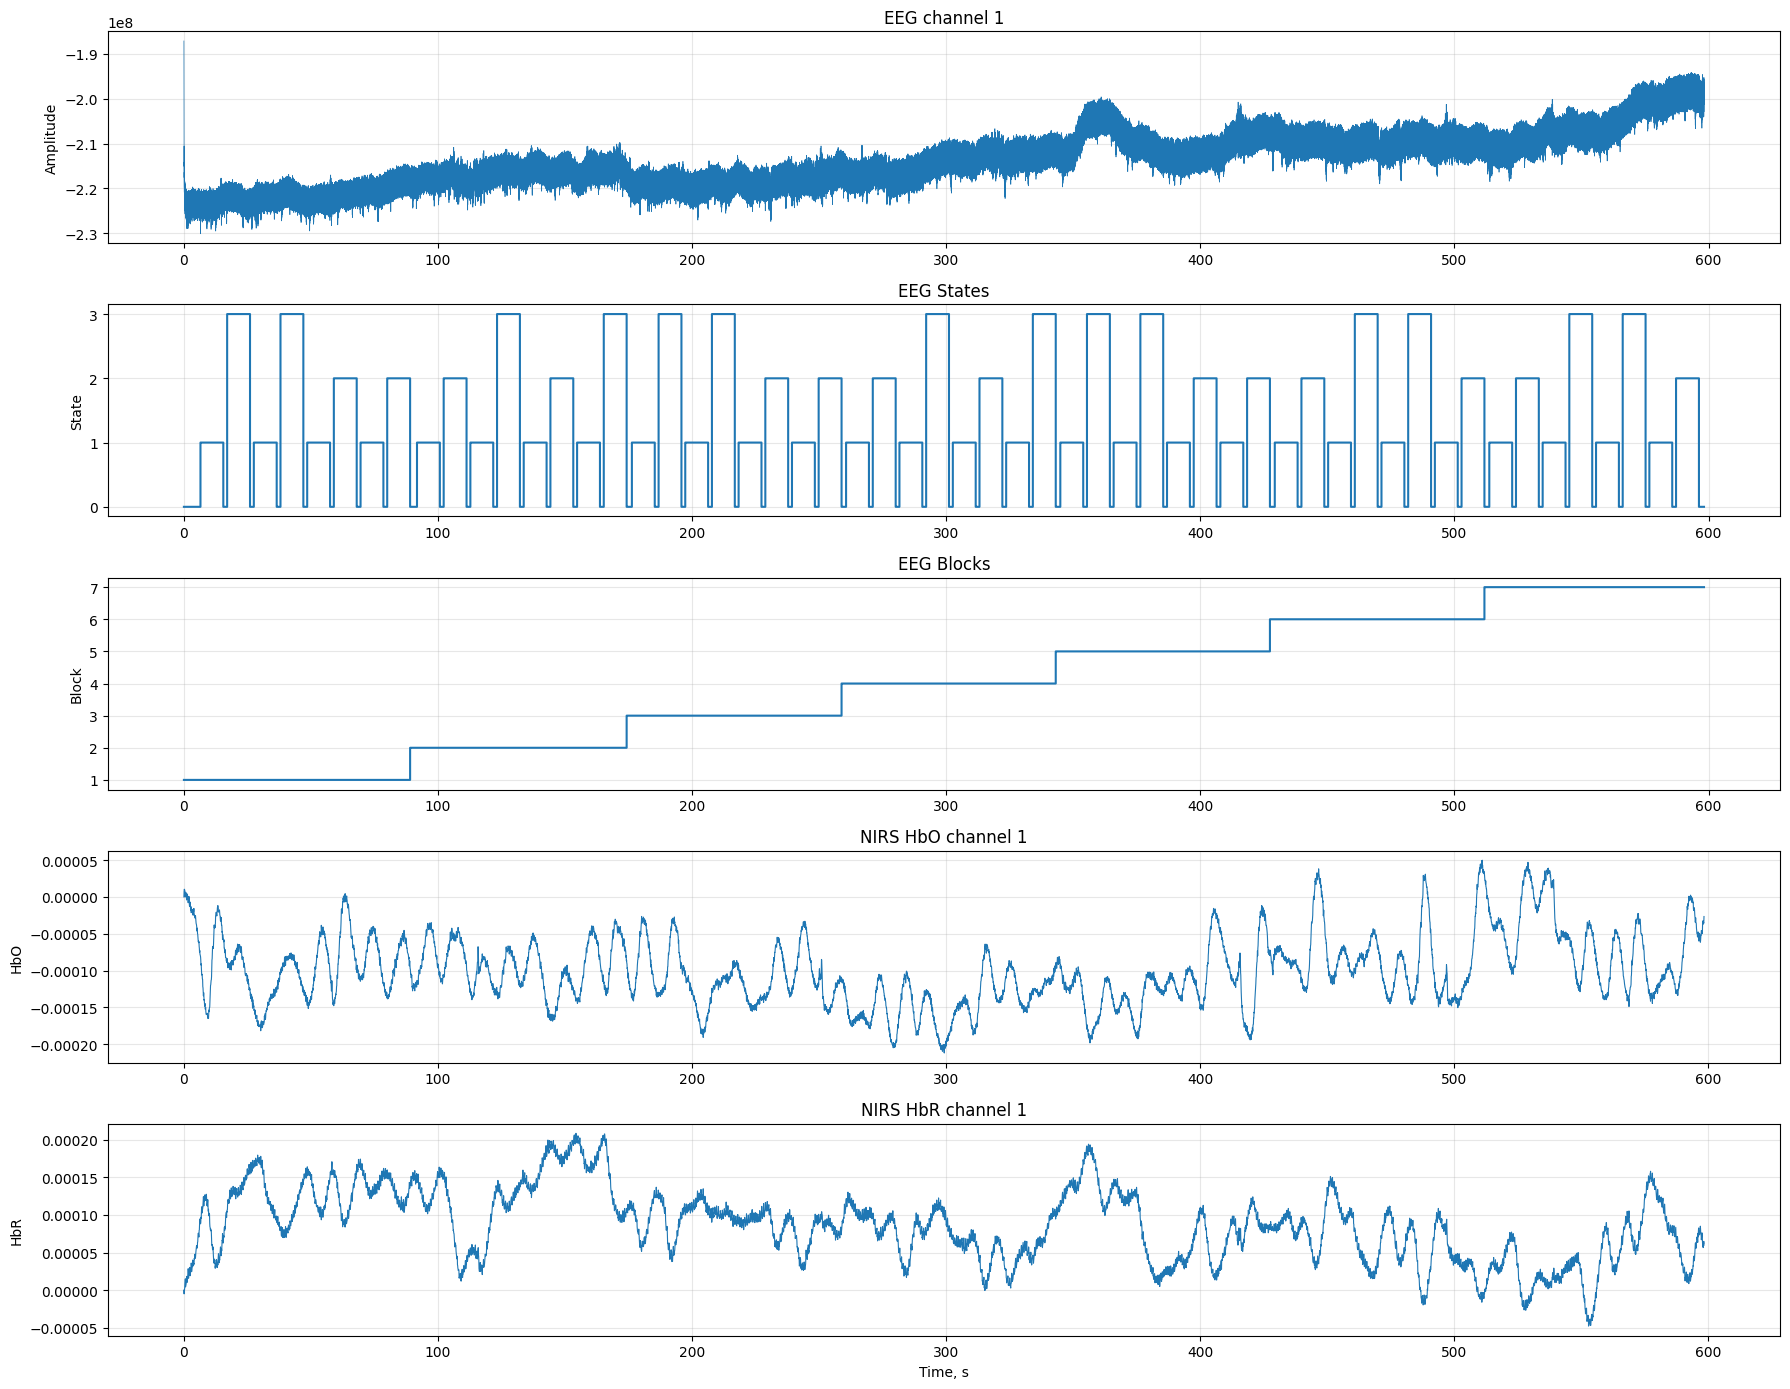

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Данные
# =========================

eeg_raw = eeg["Raw"]
eeg_states = eeg["States"]
eeg_blocks = eeg["Blocks"]

nirs_hbo = nirs["HbO"]
nirs_hbr = nirs["HbR"]
nirs_states = nirs["States"]
nirs_blocks = nirs["Blocks"]

frame = nirs["Frame"]

# Временные оси
eeg_time = np.arange(len(eeg_states)) / eeg_fs
nirs_time = np.arange(len(nirs_states)) / nirs_fs


# =========================
# Выбираем каналы
# =========================

eeg_channel = 0
nirs_channel = 0

eeg_signal = eeg_raw[:, eeg_channel]
hbo_signal = nirs_hbo[:, nirs_channel]
hbr_signal = nirs_hbr[:, nirs_channel]


# =========================
# Визуализация
# =========================

fig, axes = plt.subplots(
    5,
    1,
    figsize=(18, 14),
    sharex=False
)


# ---- EEG signal ----

axes[0].plot(
    eeg_time,
    eeg_signal,
    linewidth=0.5
)

axes[0].set_title(
    f"EEG channel {eeg_channel + 1}"
)

axes[0].set_ylabel("Amplitude")
axes[0].grid(alpha=0.3)


# ---- EEG States ----

axes[1].step(
    eeg_time,
    eeg_states,
    where="post"
)

axes[1].set_title("EEG States")
axes[1].set_ylabel("State")
axes[1].set_yticks([0, 1, 2, 3])
axes[1].grid(alpha=0.3)


# ---- EEG Blocks ----

axes[2].step(
    eeg_time,
    eeg_blocks,
    where="post"
)

axes[2].set_title("EEG Blocks")
axes[2].set_ylabel("Block")
axes[2].set_yticks(np.unique(eeg_blocks))
axes[2].grid(alpha=0.3)


# ---- NIRS HbO ----

axes[3].plot(
    nirs_time,
    hbo_signal,
    linewidth=0.8
)

axes[3].set_title(
    f"NIRS HbO channel {nirs_channel + 1}"
)

axes[3].set_ylabel("HbO")
axes[3].grid(alpha=0.3)


# ---- NIRS HbR ----

axes[4].plot(
    nirs_time,
    hbr_signal,
    linewidth=0.8
)

axes[4].set_title(
    f"NIRS HbR channel {nirs_channel + 1}"
)

axes[4].set_ylabel("HbR")
axes[4].set_xlabel("Time, s")
axes[4].grid(alpha=0.3)


plt.tight_layout()
plt.savefig('123.png', dpi=300)
plt.show()


In [7]:
import numpy as np
import pandas as pd


def get_runs(values):
    """
    Находит непрерывные участки одинаковых значений.

    Возвращает:
        value
        start_idx
        end_idx
        length
    """
    
    values = np.asarray(values)

    change_points = np.flatnonzero(values[1:] != values[:-1]) + 1

    starts = np.r_[0, change_points]
    ends = np.r_[change_points - 1, len(values) - 1]

    result = []

    for start, end in zip(starts, ends):
        result.append({
            "value": values[start],
            "start_idx": start,
            "end_idx": end,
            "length": end - start + 1
        })

    return pd.DataFrame(result)


# ==========================================
# EEG: непрерывные состояния
# ==========================================

state_runs = get_runs(eeg_states)

state_runs["start_time"] = state_runs["start_idx"] / eeg_fs
state_runs["end_time"] = (state_runs["end_idx"] + 1) / eeg_fs
state_runs["duration_sec"] = state_runs["length"] / eeg_fs


# Добавляем block для каждого участка
state_runs["block"] = eeg_blocks[state_runs["start_idx"]].astype(int)


# Переименовываем
state_runs = state_runs.rename(
    columns={"value": "state"}
)


print("Количество непрерывных state-участков:")
print(len(state_runs))

print("\nПервые 30 участков:")
display(
    state_runs[
        [
            "block",
            "state",
            "start_time",
            "end_time",
            "duration_sec",
            "length"
        ]
    ].head(30)
)


# ==========================================
# Статистика длительностей по состояниям
# ==========================================

print("\n=== DURATION BY STATE ===")

duration_stats = (
    state_runs
    .groupby("state")["duration_sec"]
    .agg(["count", "min", "max", "mean", "median", "std"])
)

display(duration_stats)


# ==========================================
# Последовательность состояний
# ==========================================

print("\n=== STATE SEQUENCE ===")

print(
    state_runs["state"]
    .astype(int)
    .tolist()
)


# ==========================================
# Последовательность внутри каждого блока
# ==========================================

print("\n=== STATES BY BLOCK ===")

for block in sorted(state_runs["block"].unique()):

    block_states = state_runs.loc[
        state_runs["block"] == block,
        "state"
    ].astype(int).tolist()

    print(
        f"Block {block}: "
        f"{block_states}"
    )

Количество непрерывных state-участков:
113

Первые 30 участков:


,block,state,start_time,end_time,duration_sec,length
0,1,0,0.000,6.516,6.516,1629
1,1,1,6.516,15.504,8.988,2247
2,1,0,15.504,17.016,1.512,378
3,1,3,17.016,26.016,9.000,2250
4,1,0,26.016,27.516,1.500,375
5,1,1,27.516,36.516,9.000,2250
6,1,0,36.516,38.004,1.488,372
7,1,3,38.004,47.004,9.000,2250
8,1,0,47.004,48.516,1.512,378
9,1,1,48.516,57.516,9.000,2250



=== DURATION BY STATE ===


,count,min,max,mean,median,std
state,,,,,,
0,57,1.476,6.516,1.653053,1.5,0.686178
1,28,8.988,9.012,8.999571,9.0,0.006094
2,14,8.988,9.012,9.000000,9.0,0.009414
3,14,8.988,9.012,8.999143,9.0,0.008761



=== STATE SEQUENCE ===
[0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0]

=== STATES BY BLOCK ===
Block 1: [0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2]
Block 2: [0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 3]
Block 3: [0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2]
Block 4: [0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 3]
Block 5: [0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0, 1, 0, 2]
Block 6: [0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2]
Block 7: [0, 1, 0, 2, 0, 1, 0, 3, 0, 1, 0, 3, 0, 1, 0, 2, 0]


=== EEG CHANNEL STATISTICS ===


,mean,std,min,max,median,range
channel,,,,,,
1,-2.140441e+08,6.356083e+06,-2.301324e+08,-1.871226e+08,-2.145060e+08,4.300980e+07
2,2.417504e+07,1.638451e+07,-1.279560e+07,1.024152e+08,2.440650e+07,1.152108e+08
3,-5.345692e+08,1.206796e+07,-5.719398e+08,-4.737222e+08,-5.352918e+08,9.821760e+07
4,-1.901506e+08,5.882356e+06,-2.078922e+08,-1.541166e+08,-1.899798e+08,5.377560e+07
5,-3.704144e+08,6.578215e+06,-3.883506e+08,-3.218700e+08,-3.702504e+08,6.648060e+07
6,1.082430e+08,1.198459e+08,-1.056972e+08,3.894756e+08,1.025397e+08,4.951728e+08
7,1.952470e+08,5.831938e+06,1.822122e+08,2.108010e+08,1.950900e+08,2.858880e+07
8,2.217094e+09,5.282022e+09,-6.813851e+09,6.813850e+09,5.164633e+09,1.362770e+10
9,-3.942209e+08,6.348715e+06,-4.107774e+08,-3.496896e+08,-3.945066e+08,6.108780e+07



=== NIRS HbO CHANNEL STATISTICS ===


,mean,std,min,max,median,range
channel,,,,,,
1,-0.000100,0.000048,-0.000212,0.000050,-0.000107,0.000262
2,-0.000074,0.000049,-0.000204,0.000082,-0.000078,0.000286
3,-0.000074,0.000051,-0.000226,0.000099,-0.000078,0.000325
4,-0.000059,0.000041,-0.000181,0.000080,-0.000060,0.000261
5,-0.000023,0.000056,-0.000189,0.000161,-0.000025,0.000350
6,-0.000082,0.000050,-0.000217,0.000094,-0.000086,0.000311
7,-0.000107,0.000066,-0.000383,0.000156,-0.000109,0.000539
8,-0.000011,0.000037,-0.000115,0.000095,-0.000012,0.000210
9,-0.000050,0.000035,-0.000305,0.000050,-0.000047,0.000355



=== NIRS HbR CHANNEL STATISTICS ===


,mean,std,min,max,median,range
channel,,,,,,
1,0.000087,0.000048,-0.000048,0.000208,8.901000e-05,0.000256
2,0.000013,0.000034,-0.000074,0.000107,1.257000e-05,0.000182
3,0.000007,0.000029,-0.000059,0.000104,5.680000e-06,0.000163
4,0.000009,0.000029,-0.000053,0.000101,3.590000e-06,0.000155
5,0.000002,0.000027,-0.000096,0.000097,2.190000e-06,0.000193
6,-0.000103,0.000026,-0.000162,0.000003,-1.058900e-04,0.000166
7,-0.000051,0.000061,-0.000248,0.000173,-5.370000e-05,0.000422
8,-0.000012,0.000018,-0.000061,0.000044,-1.279000e-05,0.000105
9,0.000008,0.000011,-0.000114,0.000042,9.830000e-06,0.000156


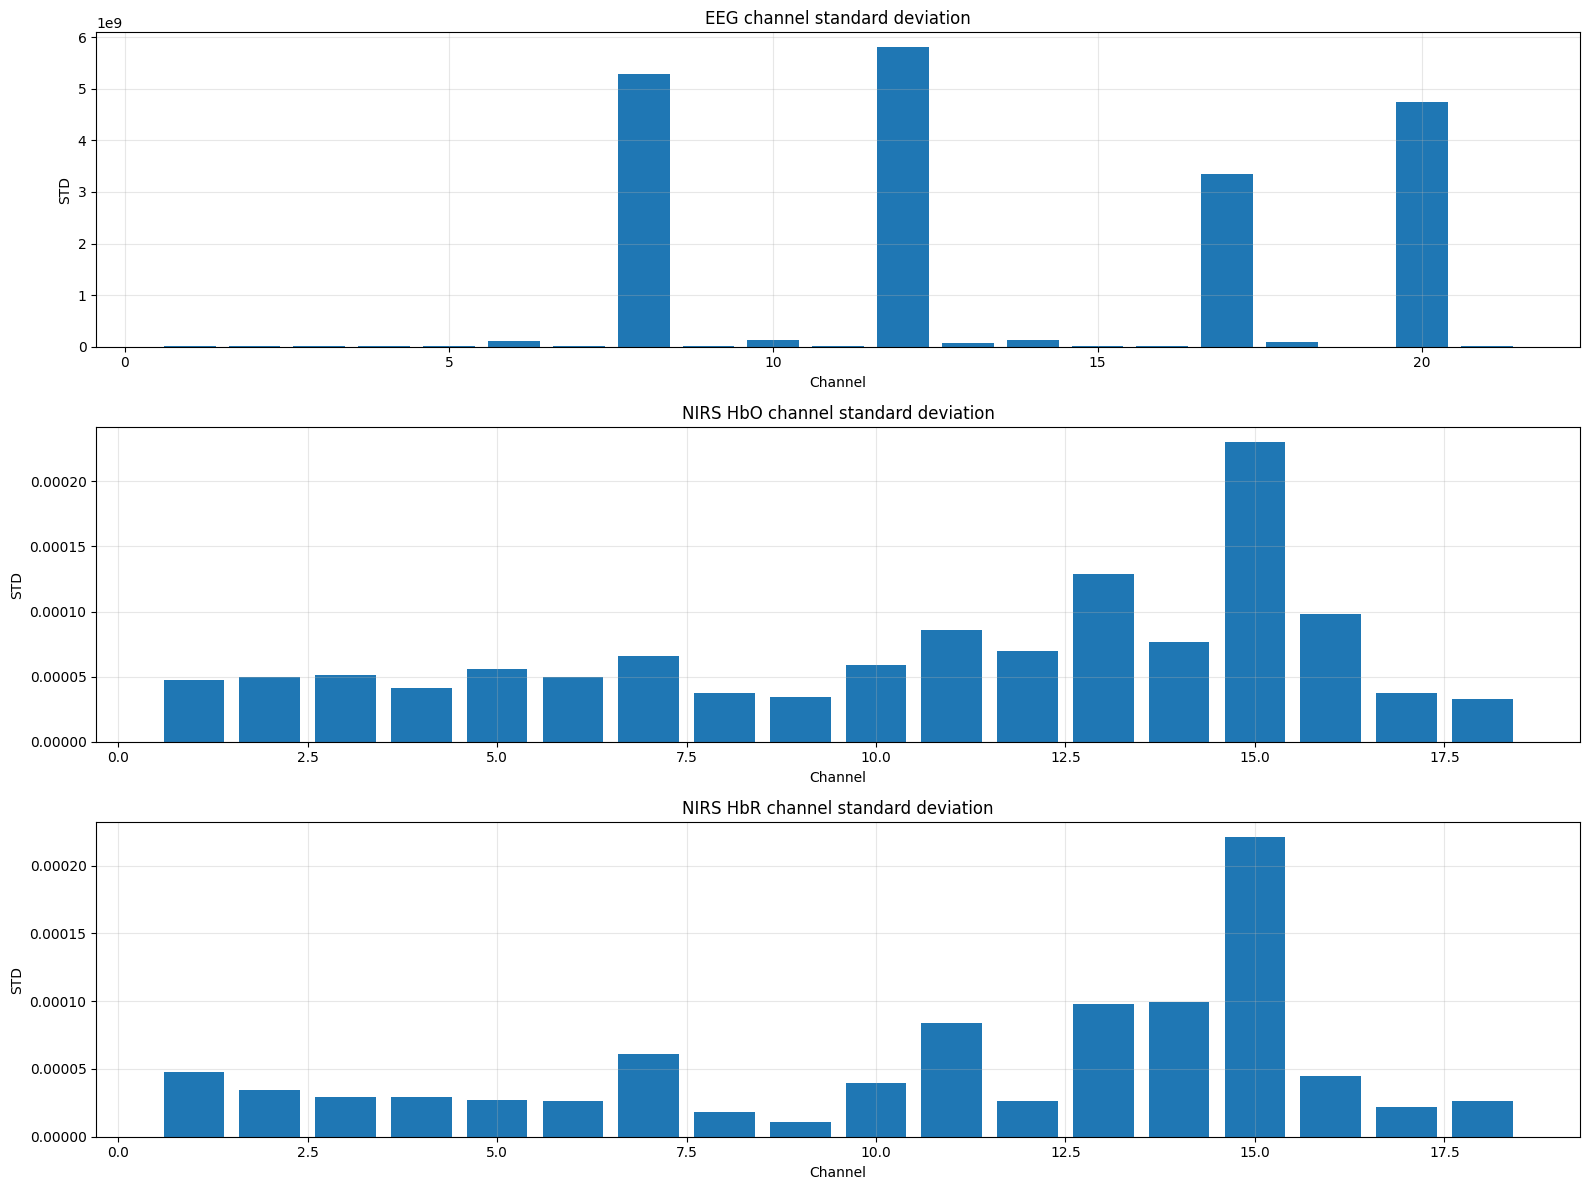

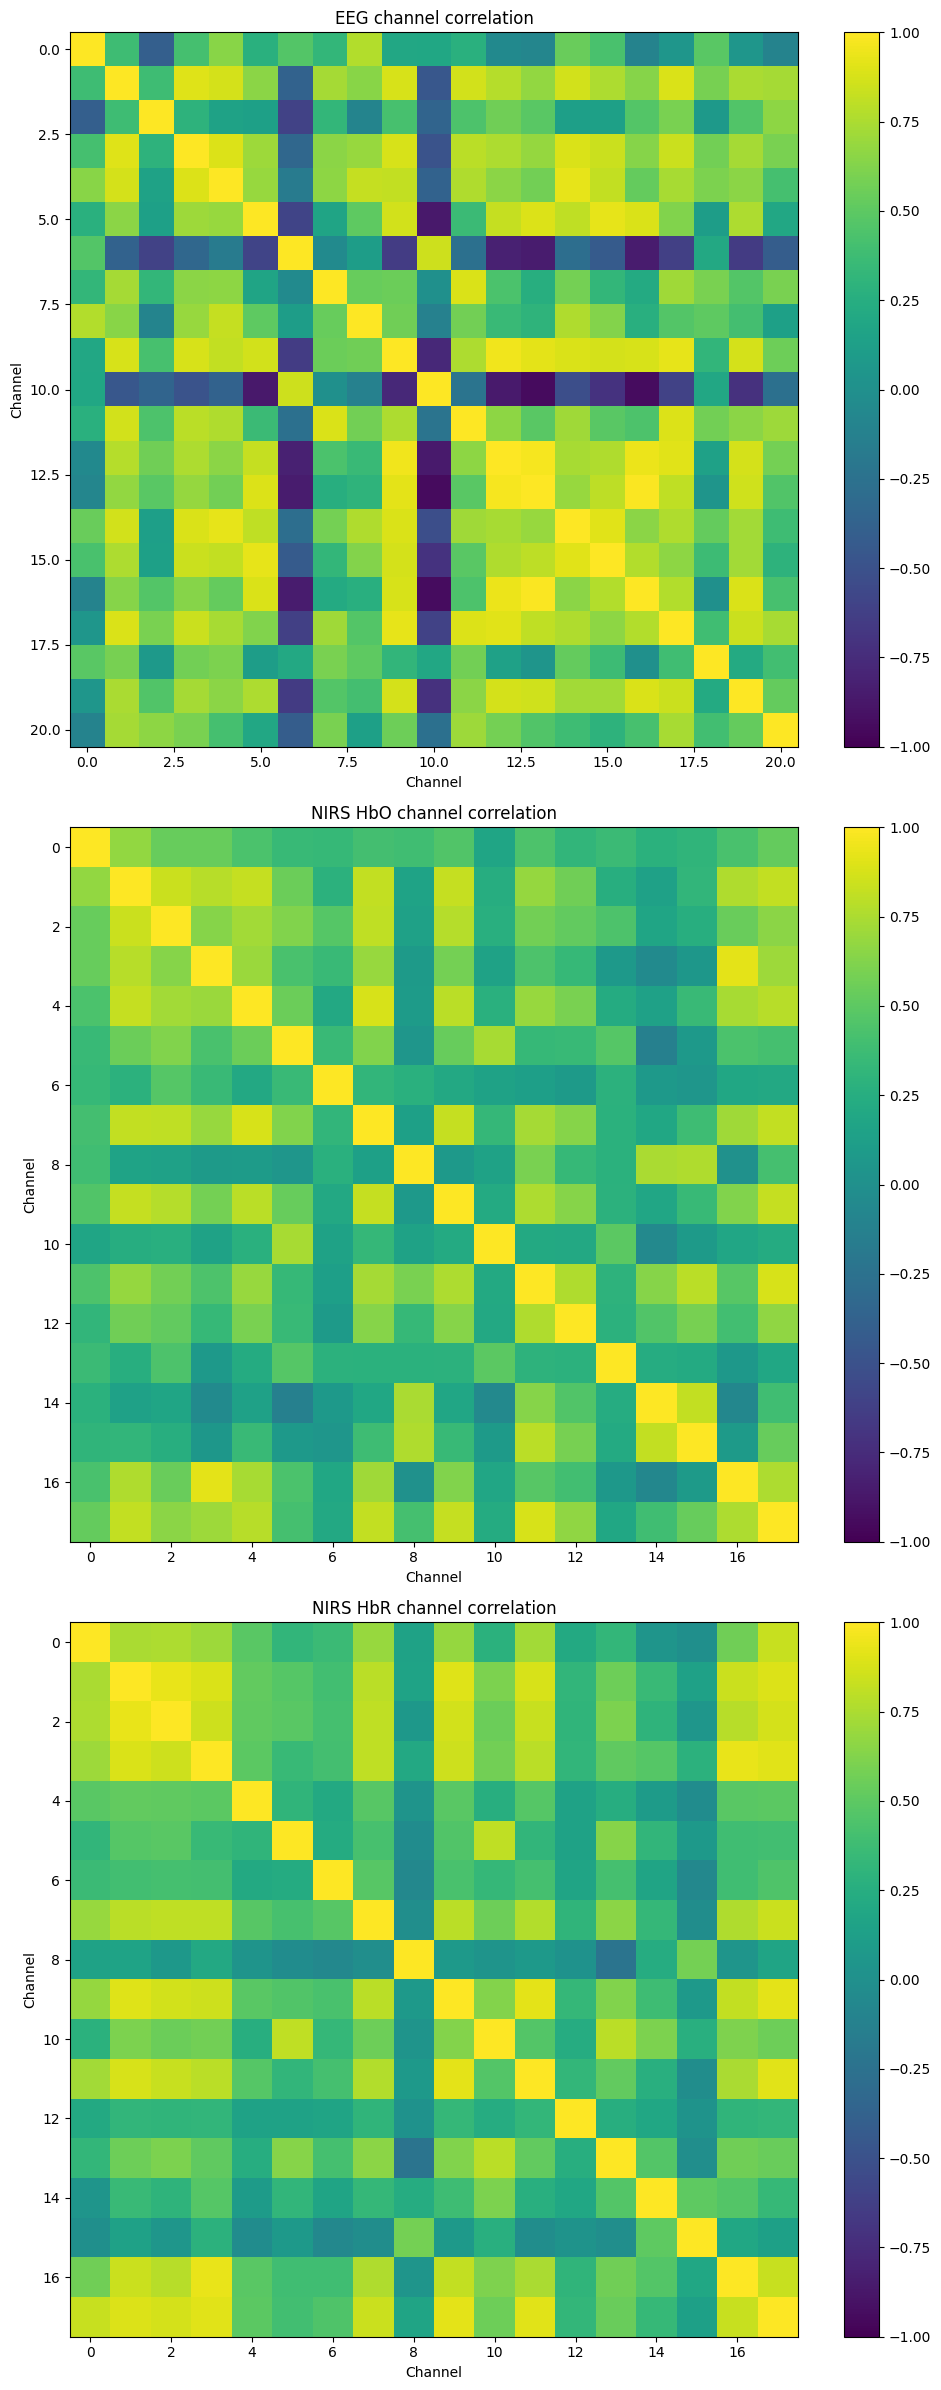

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Подготовка данных
# ============================================================

eeg = mat["EEG"]
nirs = mat["NIRS"]

eeg_raw = eeg["Raw"]
nirs_hbo = nirs["HbO"]
nirs_hbr = nirs["HbR"]

n_eeg_channels = eeg_raw.shape[1]
n_nirs_channels = nirs_hbo.shape[1]


# ============================================================
# EEG CHANNEL STATISTICS
# ============================================================

eeg_stats = pd.DataFrame({
    "mean": np.mean(eeg_raw, axis=0),
    "std": np.std(eeg_raw, axis=0),
    "min": np.min(eeg_raw, axis=0),
    "max": np.max(eeg_raw, axis=0),
    "median": np.median(eeg_raw, axis=0),
})

eeg_stats["range"] = eeg_stats["max"] - eeg_stats["min"]

eeg_stats.index = np.arange(1, n_eeg_channels + 1)
eeg_stats.index.name = "channel"

print("=== EEG CHANNEL STATISTICS ===")
display(eeg_stats.round(3))
eeg_stats.to_csv("EEG_CHANNEL_STATISTICS.csv")

# ============================================================
# NIRS HbO STATISTICS
# ============================================================

hbo_stats = pd.DataFrame({
    "mean": np.mean(nirs_hbo, axis=0),
    "std": np.std(nirs_hbo, axis=0),
    "min": np.min(nirs_hbo, axis=0),
    "max": np.max(nirs_hbo, axis=0),
    "median": np.median(nirs_hbo, axis=0),
})

hbo_stats["range"] = hbo_stats["max"] - hbo_stats["min"]

hbo_stats.index = np.arange(1, n_nirs_channels + 1)
hbo_stats.index.name = "channel"

print("\n=== NIRS HbO CHANNEL STATISTICS ===")
display(hbo_stats.round(8))

hbo_stats.to_csv("NIRS_HbO_STATISTICS.csv")

# ============================================================
# NIRS HbR STATISTICS
# ============================================================

hbr_stats = pd.DataFrame({
    "mean": np.mean(nirs_hbr, axis=0),
    "std": np.std(nirs_hbr, axis=0),
    "min": np.min(nirs_hbr, axis=0),
    "max": np.max(nirs_hbr, axis=0),
    "median": np.median(nirs_hbr, axis=0),
})

hbr_stats["range"] = hbr_stats["max"] - hbr_stats["min"]

hbr_stats.index = np.arange(1, n_nirs_channels + 1)
hbr_stats.index.name = "channel"

print("\n=== NIRS HbR CHANNEL STATISTICS ===")
display(hbr_stats.round(8))
hbr_stats.to_csv("NIRS_HbR_STATISTICS.csv")


# ============================================================
# STANDARD DEVIATION
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(16, 12)
)


# EEG
axes[0].bar(
    eeg_stats.index,
    eeg_stats["std"]
)

axes[0].set_title("EEG channel standard deviation")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("STD")
axes[0].grid(alpha=0.3)


# HbO
axes[1].bar(
    hbo_stats.index,
    hbo_stats["std"]
)

axes[1].set_title("NIRS HbO channel standard deviation")
axes[1].set_xlabel("Channel")
axes[1].set_ylabel("STD")
axes[1].grid(alpha=0.3)


# HbR
axes[2].bar(
    hbr_stats.index,
    hbr_stats["std"]
)

axes[2].set_title("NIRS HbR channel standard deviation")
axes[2].set_xlabel("Channel")
axes[2].set_ylabel("STD")
axes[2].grid(alpha=0.3)


plt.tight_layout()
plt.savefig("STANDARD DEVIATION destr", dpi = 300)
plt.show()


# ============================================================
# CORRELATION MATRICES
# ============================================================

eeg_corr = np.corrcoef(eeg_raw.T)
hbo_corr = np.corrcoef(nirs_hbo.T)
hbr_corr = np.corrcoef(nirs_hbr.T)


fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 24)
)


# EEG
im0 = axes[0].imshow(
    eeg_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

axes[0].set_title("EEG channel correlation")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Channel")

fig.colorbar(im0, ax=axes[0])


# HbO
im1 = axes[1].imshow(
    hbo_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

axes[1].set_title("NIRS HbO channel correlation")
axes[1].set_xlabel("Channel")
axes[1].set_ylabel("Channel")

fig.colorbar(im1, ax=axes[1])


# HbR
im2 = axes[2].imshow(
    hbr_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

axes[2].set_title("NIRS HbR channel correlation")
axes[2].set_xlabel("Channel")
axes[2].set_ylabel("Channel")

fig.colorbar(im2, ax=axes[2])


plt.tight_layout()
plt.savefig("CORRELATION MATRICES", dpi = 300)

plt.show()

In [9]:
import numpy as np
import pandas as pd

eeg_raw = mat["EEG"]["Raw"]

suspect_channels = [8, 12, 17, 20]

print("=== Проверка EEG каналов 8, 12, 17, 20 ===")

for ch in suspect_channels:
    x = eeg_raw[:, ch - 1]

    print(f"\nКанал {ch}")
    print(f"  min = {x.min():.6e}")
    print(f"  max = {x.max():.6e}")
    print(f"  mean = {x.mean():.6e}")
    print(f"  std = {x.std():.6e}")

    # точные совпадения с экстремальными значениями
    n_min = np.sum(x == x.min())
    n_max = np.sum(x == x.max())

    print(f"  count(min) = {n_min}")
    print(f"  count(max) = {n_max}")

    # NaN / Inf
    print(f"  NaN = {np.isnan(x).sum()}")
    print(f"  Inf = {np.isinf(x).sum()}")

    # несколько самых частых значений
    values, counts = np.unique(x, return_counts=True)
    idx = np.argsort(counts)[-10:][::-1]

    print("  10 самых частых значений:")
    for i in idx:
        print(f"    {values[i]:.6e}  ->  {counts[i]} раз")

=== Проверка EEG каналов 8, 12, 17, 20 ===

Канал 8
  min = -6.813851e+09
  max = 6.813850e+09
  mean = 2.217094e+09
  std = 5.282022e+09
  count(min) = 3552
  count(max) = 54598
  NaN = 0
  Inf = 0
  10 самых частых значений:
    6.813850e+09  ->  54598 раз
    -6.813851e+09  ->  3552 раз
    6.813850e+09  ->  77 раз
    6.813849e+09  ->  41 раз
    -6.813850e+09  ->  37 раз
    -6.813848e+09  ->  36 раз
    6.813848e+09  ->  34 раз
    -6.813850e+09  ->  31 раз
    -6.813849e+09  ->  28 раз
    6.813847e+09  ->  26 раз

Канал 12
  min = -6.813851e+09
  max = 6.813850e+09
  mean = 6.440521e+06
  std = 5.804796e+09
  count(min) = 37689
  count(max) = 37578
  NaN = 0
  Inf = 0
  10 самых частых значений:
    -6.813851e+09  ->  37689 раз
    6.813850e+09  ->  37578 раз
    6.813850e+09  ->  42 раз
    -6.813850e+09  ->  40 раз
    -6.813850e+09  ->  34 раз
    -6.813848e+09  ->  26 раз
    -6.813849e+09  ->  23 раз
    6.813849e+09  ->  21 раз
    6.813848e+09  ->  18 раз
    -6.813847e+

,channel,bad_samples,bad_fraction,bad_percent
0,1,0,0.000,0.000
1,2,0,0.000,0.000
2,3,0,0.000,0.000
3,4,0,0.000,0.000
4,5,0,0.000,0.000
5,6,0,0.000,0.000
6,7,0,0.000,0.000
7,8,90160,0.603,60.288
8,9,0,0.000,0.000
9,10,0,0.000,0.000


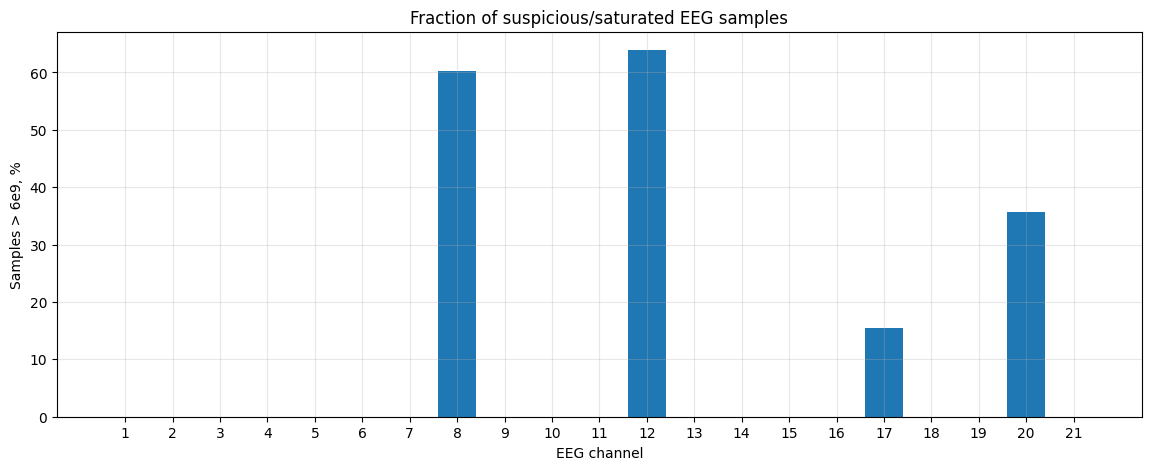

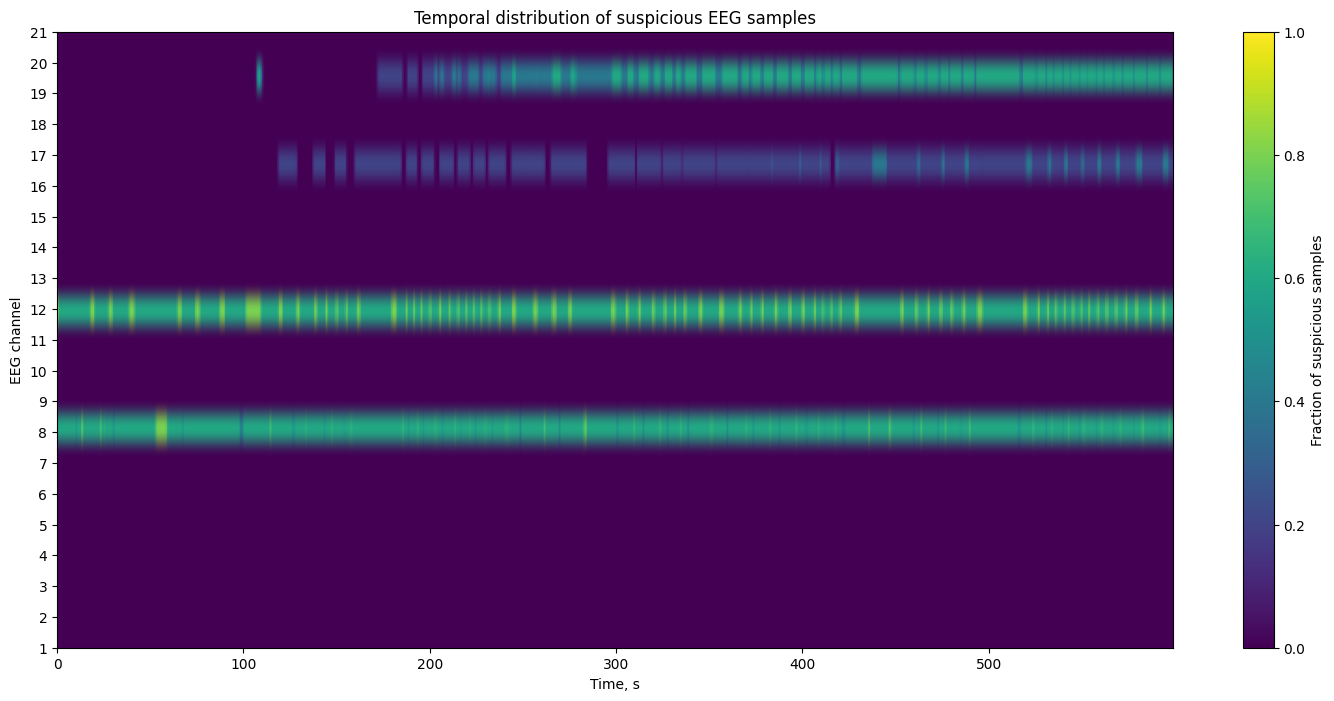

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

eeg_raw = mat["EEG"]["Raw"]
fs = mat["EEG"]["Frq"]

# Значения порядка 6.8e9 явно отделены от нормального диапазона.
# Используем консервативный порог для QC, НЕ для окончательной очистки.
threshold = 6e9

bad_mask = np.abs(eeg_raw) > threshold

# Доля подозрительных samples по каждому каналу
bad_fraction = bad_mask.mean(axis=0)

bad_stats = pd.DataFrame({
    "channel": np.arange(1, eeg_raw.shape[1] + 1),
    "bad_samples": bad_mask.sum(axis=0),
    "bad_fraction": bad_fraction,
})

bad_stats["bad_percent"] = 100 * bad_stats["bad_fraction"]

display(bad_stats.round(3))
bad_stats.to_csv('bad_stats.csv')


# ------------------------------------------------------------
# Визуализация доли подозрительных значений
# ------------------------------------------------------------

plt.figure(figsize=(14, 5))
plt.bar(bad_stats["channel"], bad_stats["bad_percent"])
plt.xlabel("EEG channel")
plt.ylabel("Samples > 6e9, %")
plt.title("Fraction of suspicious/saturated EEG samples")
plt.xticks(np.arange(1, eeg_raw.shape[1] + 1))
plt.grid(alpha=0.3)
plt.savefig('viz', dpi = 300)
plt.show()


# ------------------------------------------------------------
# Временная карта подозрительных значений
# ------------------------------------------------------------

# Чтобы график был компактным, агрегируем по 1 секунде
n_seconds = int(np.ceil(len(eeg_raw) / fs))

bad_per_second = np.zeros((eeg_raw.shape[1], n_seconds))

for sec in range(n_seconds):
    start = int(sec * fs)
    end = min(int((sec + 1) * fs), len(eeg_raw))
    bad_per_second[:, sec] = bad_mask[start:end].mean(axis=0)

plt.figure(figsize=(18, 8))

plt.imshow(
    bad_per_second,
    aspect="auto",
    origin="lower",
    extent=[0, n_seconds, 1, eeg_raw.shape[1]],
    vmin=0,
    vmax=1
)

plt.colorbar(label="Fraction of suspicious samples")
plt.xlabel("Time, s")
plt.ylabel("EEG channel")
plt.title("Temporal distribution of suspicious EEG samples")
plt.yticks(np.arange(1, eeg_raw.shape[1] + 1))
plt.savefig('time_map', dpi = 300)

plt.show()

In [11]:
import numpy as np
import pandas as pd

eeg_raw = mat["EEG"]["Raw"]
eeg_states = mat["EEG"]["States"]
eeg_blocks = mat["EEG"]["Blocks"]

fs = mat["EEG"]["Frq"]

threshold = 6e9
bad_mask = np.abs(eeg_raw) > threshold

channels = [8, 12, 17, 20]

# ============================================================
# 1. Доля плохих samples по блокам
# ============================================================

rows = []

for block in np.unique(eeg_blocks):
    block_mask = eeg_blocks == block

    for ch in channels:
        ch_idx = ch - 1

        fraction = bad_mask[block_mask, ch_idx].mean()

        rows.append({
            "block": int(block),
            "channel": ch,
            "bad_percent": 100 * fraction
        })

block_qc = pd.DataFrame(rows)

block_table = block_qc.pivot(
    index="block",
    columns="channel",
    values="bad_percent"
)

print("=== Доля подозрительных EEG samples по блокам (%) ===")
display(block_table.round(2))


# ============================================================
# 2. Доля плохих samples по состояниям
# ============================================================

rows = []

for state in [0, 1, 2, 3]:
    state_mask = eeg_states == state

    for ch in channels:
        ch_idx = ch - 1

        fraction = bad_mask[state_mask, ch_idx].mean()

        rows.append({
            "state": state,
            "channel": ch,
            "bad_percent": 100 * fraction
        })

state_qc = pd.DataFrame(rows)

state_table = state_qc.pivot(
    index="state",
    columns="channel",
    values="bad_percent"
)

print("\n=== Доля подозрительных EEG samples по состояниям (%) ===")
display(state_table.round(2))


# ============================================================
# 3. Качество всех 21 каналов по блокам
# ============================================================

all_block_rows = []

for block in np.unique(eeg_blocks):
    block_mask = eeg_blocks == block

    for ch in range(eeg_raw.shape[1]):
        all_block_rows.append({
            "block": int(block),
            "channel": ch + 1,
            "bad_percent": 100 * bad_mask[block_mask, ch].mean()
        })

all_block_qc = pd.DataFrame(all_block_rows)

all_block_table = all_block_qc.pivot(
    index="channel",
    columns="block",
    values="bad_percent"
)

print("\n=== Все EEG-каналы: % подозрительных samples ===")
display(all_block_table.round(2))

=== Доля подозрительных EEG samples по блокам (%) ===


channel,8,12,17,20
block,,,,
1,61.48,63.32,0.00,0.00
2,59.74,64.59,8.90,2.33
3,60.04,64.52,16.33,29.24
4,60.13,63.47,16.07,49.08
5,59.92,64.07,19.85,55.09
6,60.45,63.33,22.93,57.96
7,60.20,64.05,24.25,58.16



=== Доля подозрительных EEG samples по состояниям (%) ===


channel,8,12,17,20
state,,,,
0,60.43,62.74,14.53,33.21
1,60.55,63.87,14.62,35.39
2,59.86,64.41,16.51,38.71
3,60.08,64.32,16.38,35.28



=== Все EEG-каналы: % подозрительных samples ===


block,1,2,3,4,5,6,7
channel,,,,,,,
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00
5,0.00,0.00,0.00,0.00,0.00,0.00,0.00
6,0.00,0.00,0.00,0.00,0.00,0.00,0.00
7,0.00,0.00,0.00,0.00,0.00,0.00,0.00
8,61.48,59.74,60.04,60.13,59.92,60.45,60.20
9,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [12]:
from scipy.io import loadmat
from pathlib import Path

montage_path = DATA_DIR.parent / "Montage.mat"

print("Path:", montage_path)
print("Exists:", montage_path.exists())

montage = loadmat(montage_path, simplify_cells=True)

print("\nKeys:")
print(montage.keys())

for key, value in montage.items():
    if not key.startswith("__"):
        print(f"\n{key}:")
        print("type:", type(value))

        if isinstance(value, dict):
            for k, v in value.items():
                print(f"  {k}: type={type(v)}, shape={getattr(v, 'shape', None)}")
        else:
            print("shape:", getattr(value, "shape", None))
            print("value:", value)

Path: /home/jupyter/s3/neuralinterfaces-train/Montage.mat
Exists: True

Keys:
dict_keys(['__header__', '__version__', '__globals__', 'Montage'])

Montage:
type: <class 'dict'>
  EEG_positions: type=<class 'numpy.ndarray'>, shape=(21, 2)
  EEG_labels: type=<class 'numpy.ndarray'>, shape=(21,)
  NIRS_positions: type=<class 'numpy.ndarray'>, shape=(18, 2)


In [13]:
montage_data = montage["Montage"]

eeg_labels = montage_data["EEG_labels"]
eeg_positions = montage_data["EEG_positions"]

print("=== EEG montage ===")

for i, (label, pos) in enumerate(zip(eeg_labels, eeg_positions), start=1):
    print(
        f"Channel {i:2d}: "
        f"{str(label):>6s}   "
        f"position = ({pos[0]: .3f}, {pos[1]: .3f})"
    )

=== EEG montage ===
Channel  1:    fp1   position = (-0.263,  0.930)
Channel  2:    fp2   position = ( 0.268,  0.928)
Channel  3:     f3   position = (-0.431,  0.561)
Channel  4:     f4   position = ( 0.433,  0.554)
Channel  5:     c3   position = (-0.542, -0.000)
Channel  6:     c4   position = ( 0.534,  0.000)
Channel  7:     p3   position = (-0.443, -0.528)
Channel  8:     p4   position = ( 0.422, -0.524)
Channel  9:     o1   position = (-0.277, -0.924)
Channel 10:     o2   position = ( 0.265, -0.924)
Channel 11:     f7   position = (-0.757,  0.662)
Channel 12:     f8   position = ( 0.771,  0.640)
Channel 13:     c7   position = (-1.030, -0.000)
Channel 14:     c8   position = ( 1.014,  0.000)
Channel 15:     p7   position = (-0.773, -0.635)
Channel 16:     p8   position = ( 0.739, -0.649)
Channel 17:    lpa   position = (-1.162,  0.102)
Channel 18:    rpa   position = ( 1.162,  0.102)
Channel 19:     fz   position = ( 0.000,  0.540)
Channel 20:     cz   position = ( 0.000,  0.000)


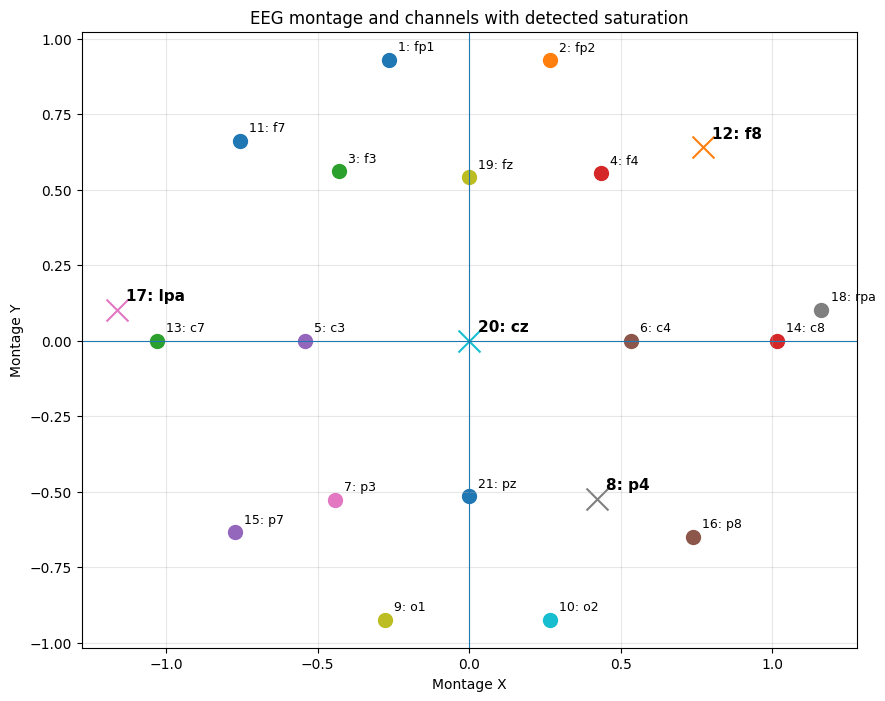

In [14]:
import numpy as np
import matplotlib.pyplot as plt

labels = np.asarray(montage["Montage"]["EEG_labels"])
positions = np.asarray(montage["Montage"]["EEG_positions"])

bad_channels = {8, 12, 17, 20}

plt.figure(figsize=(10, 8))

for i, (label, pos) in enumerate(zip(labels, positions), start=1):
    x, y = pos

    if i in bad_channels:
        plt.scatter(x, y, s=250, marker="x")
        plt.text(
            x + 0.03,
            y + 0.03,
            f"{i}: {label}",
            fontsize=11,
            fontweight="bold"
        )
    else:
        plt.scatter(x, y, s=100)
        plt.text(
            x + 0.03,
            y + 0.03,
            f"{i}: {label}",
            fontsize=9
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Montage X")
plt.ylabel("Montage Y")
plt.title("EEG montage and channels with detected saturation")
plt.axis("equal")
plt.grid(alpha=0.3)

plt.show()

In [15]:
import sys
# Добавляем путь к локальным пакетам пользователя jupyter
user_site = '/home/jupyter/.local/lib/python3.10/site-packages'
if user_site not in sys.path:
    sys.path.insert(0, user_site)

import mne
print("Успешно! Версия MNE:", mne.__version__)


Успешно! Версия MNE: 1.12.1


In [16]:
import mne
import numpy as np

# Данные
eeg_raw = mat["EEG"]["Raw"]
fs = float(mat["EEG"]["Frq"])

# Названия каналов из Montage.mat
eeg_labels = [
    str(x).strip()
    for x in np.asarray(montage["Montage"]["EEG_labels"]).ravel()
]

# MNE любит стандартный регистр названий
eeg_labels = [label.upper() for label in eeg_labels]

print("Channels:", eeg_labels)
print("Sampling frequency:", fs)
print("Data shape:", eeg_raw.shape)

# Информация о каналах
info = mne.create_info(
    ch_names=eeg_labels,
    sfreq=fs,
    ch_types="eeg"
)

# MNE ожидает shape = (n_channels, n_times)
raw_mne = mne.io.RawArray(
    eeg_raw.T,
    info,
    verbose=False
)

print(raw_mne)

Channels: ['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'C7', 'C8', 'P7', 'P8', 'LPA', 'RPA', 'FZ', 'CZ', 'PZ']
Sampling frequency: 250.0
Data shape: (149550, 21)
<RawArray | 21 x 149550 (598.2 s), ~24.0 MiB, data loaded>


In [17]:
# Координаты из Montage.mat
positions = np.asarray(
    montage["Montage"]["EEG_positions"],
    dtype=float
)

# Создаём montage вручную из координат датасета.
# Координаты нормализуем только по масштабу для MNE:
# направление и взаимное расположение сохраняются.
pos_3d = np.column_stack([
    positions[:, 0],
    positions[:, 1],
    np.zeros(len(positions))
])

ch_pos = {
    label: pos
    for label, pos in zip(eeg_labels, pos_3d)
}

custom_montage = mne.channels.make_dig_montage(
    ch_pos=ch_pos,
    coord_frame="head"
)

raw_mne.set_montage(
    custom_montage,
    on_missing="warn"
)

print(raw_mne.get_montage())

<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 21 channels>


/tmp/ipykernel_5720/262687962.py:2: RuntimeWarning: Estimated head radius (86.1 cm) is above the 99th percentile for adult head size.
  fig = raw_mne.plot_sensors(


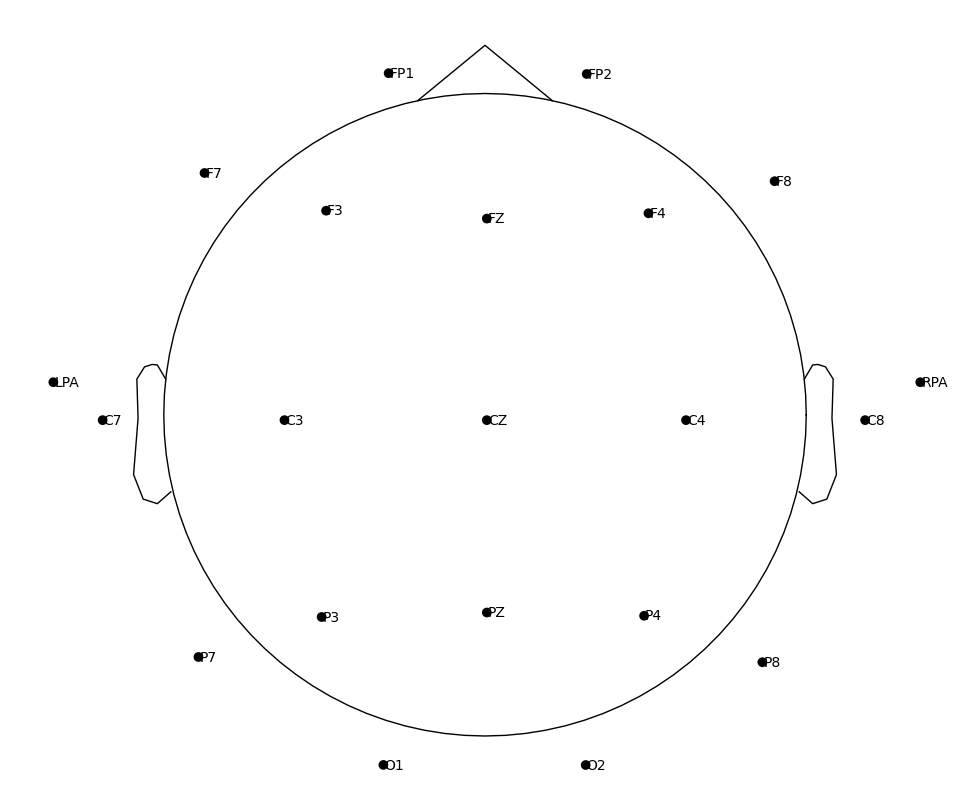

In [18]:
# Визуализация EEG montage через MNE
fig = raw_mne.plot_sensors(
    kind="topomap",
    show_names=True,
    sphere="auto",
    show=False
)

fig.set_size_inches(10, 8)
fig.show()

In [19]:
# Копия для спектрального EDA
raw_psd = raw_mne.copy()

# Каналы с обнаруженным техническим насыщением
bad_channels = ["P4", "F8", "LPA", "CZ"]

raw_psd.info["bads"] = bad_channels

print("Bad channels:", raw_psd.info["bads"])
print("Remaining channels:", len(raw_psd.ch_names) - len(raw_psd.info["bads"]))

Bad channels: ['P4', 'F8', 'LPA', 'CZ']
Remaining channels: 17


In [20]:
# Явно выбираем только исправные каналы
good_channels = [
    ch for ch in raw_mne.ch_names
    if ch not in bad_channels
]

print("Good channels:")
print(good_channels)
print("Number of good channels:", len(good_channels))

spectrum = raw_mne.compute_psd(
    method="welch",
    fmin=1,
    fmax=40,
    n_fft=1024,
    n_overlap=512,
    picks=good_channels,
    verbose=False
)

psd = spectrum.get_data()
freqs = spectrum.freqs

print("\nPSD shape:", psd.shape)
print("PSD channels:", spectrum.ch_names)
print("Frequency range:", freqs[0], "—", freqs[-1], "Hz")

Good channels:
['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'P3', 'O1', 'O2', 'F7', 'C7', 'C8', 'P7', 'P8', 'RPA', 'FZ', 'PZ']
Number of good channels: 17

PSD shape: (17, 159)
PSD channels: ['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'P3', 'O1', 'O2', 'F7', 'C7', 'C8', 'P7', 'P8', 'RPA', 'FZ', 'PZ']
Frequency range: 1.220703125 — 39.794921875 Hz


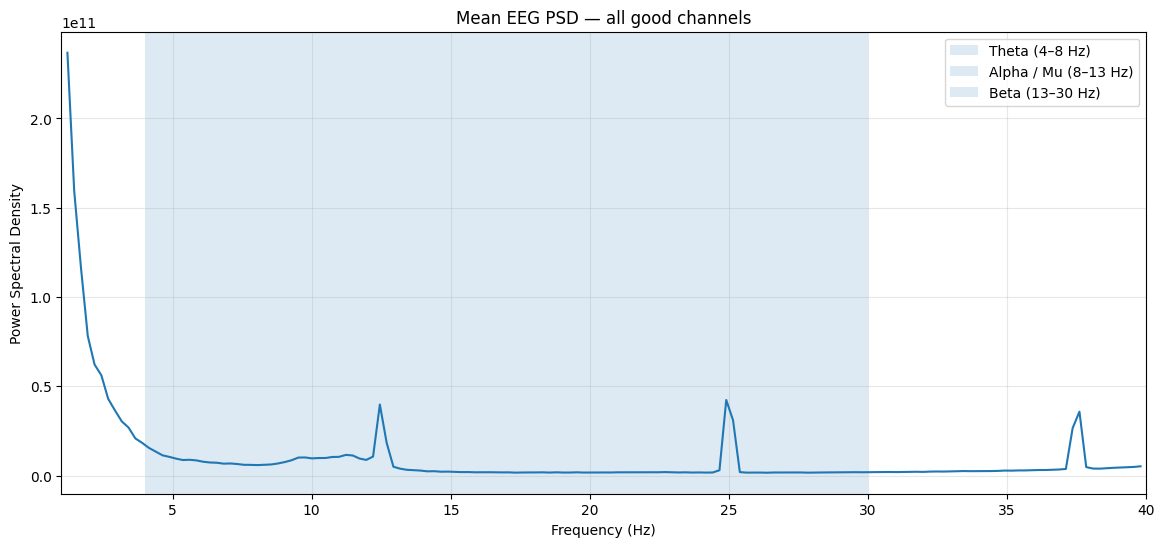

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Средняя PSD по 17 исправным каналам
mean_psd = psd.mean(axis=0)

plt.figure(figsize=(14, 6))

plt.plot(freqs, mean_psd)

# EEG frequency bands
bands = {
    "Theta (4–8 Hz)": (4, 8),
    "Alpha / Mu (8–13 Hz)": (8, 13),
    "Beta (13–30 Hz)": (13, 30),
}

for name, (fmin, fmax) in bands.items():
    plt.axvspan(fmin, fmax, alpha=0.15, label=name)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Mean EEG PSD — all good channels")
plt.xlim(1, 40)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

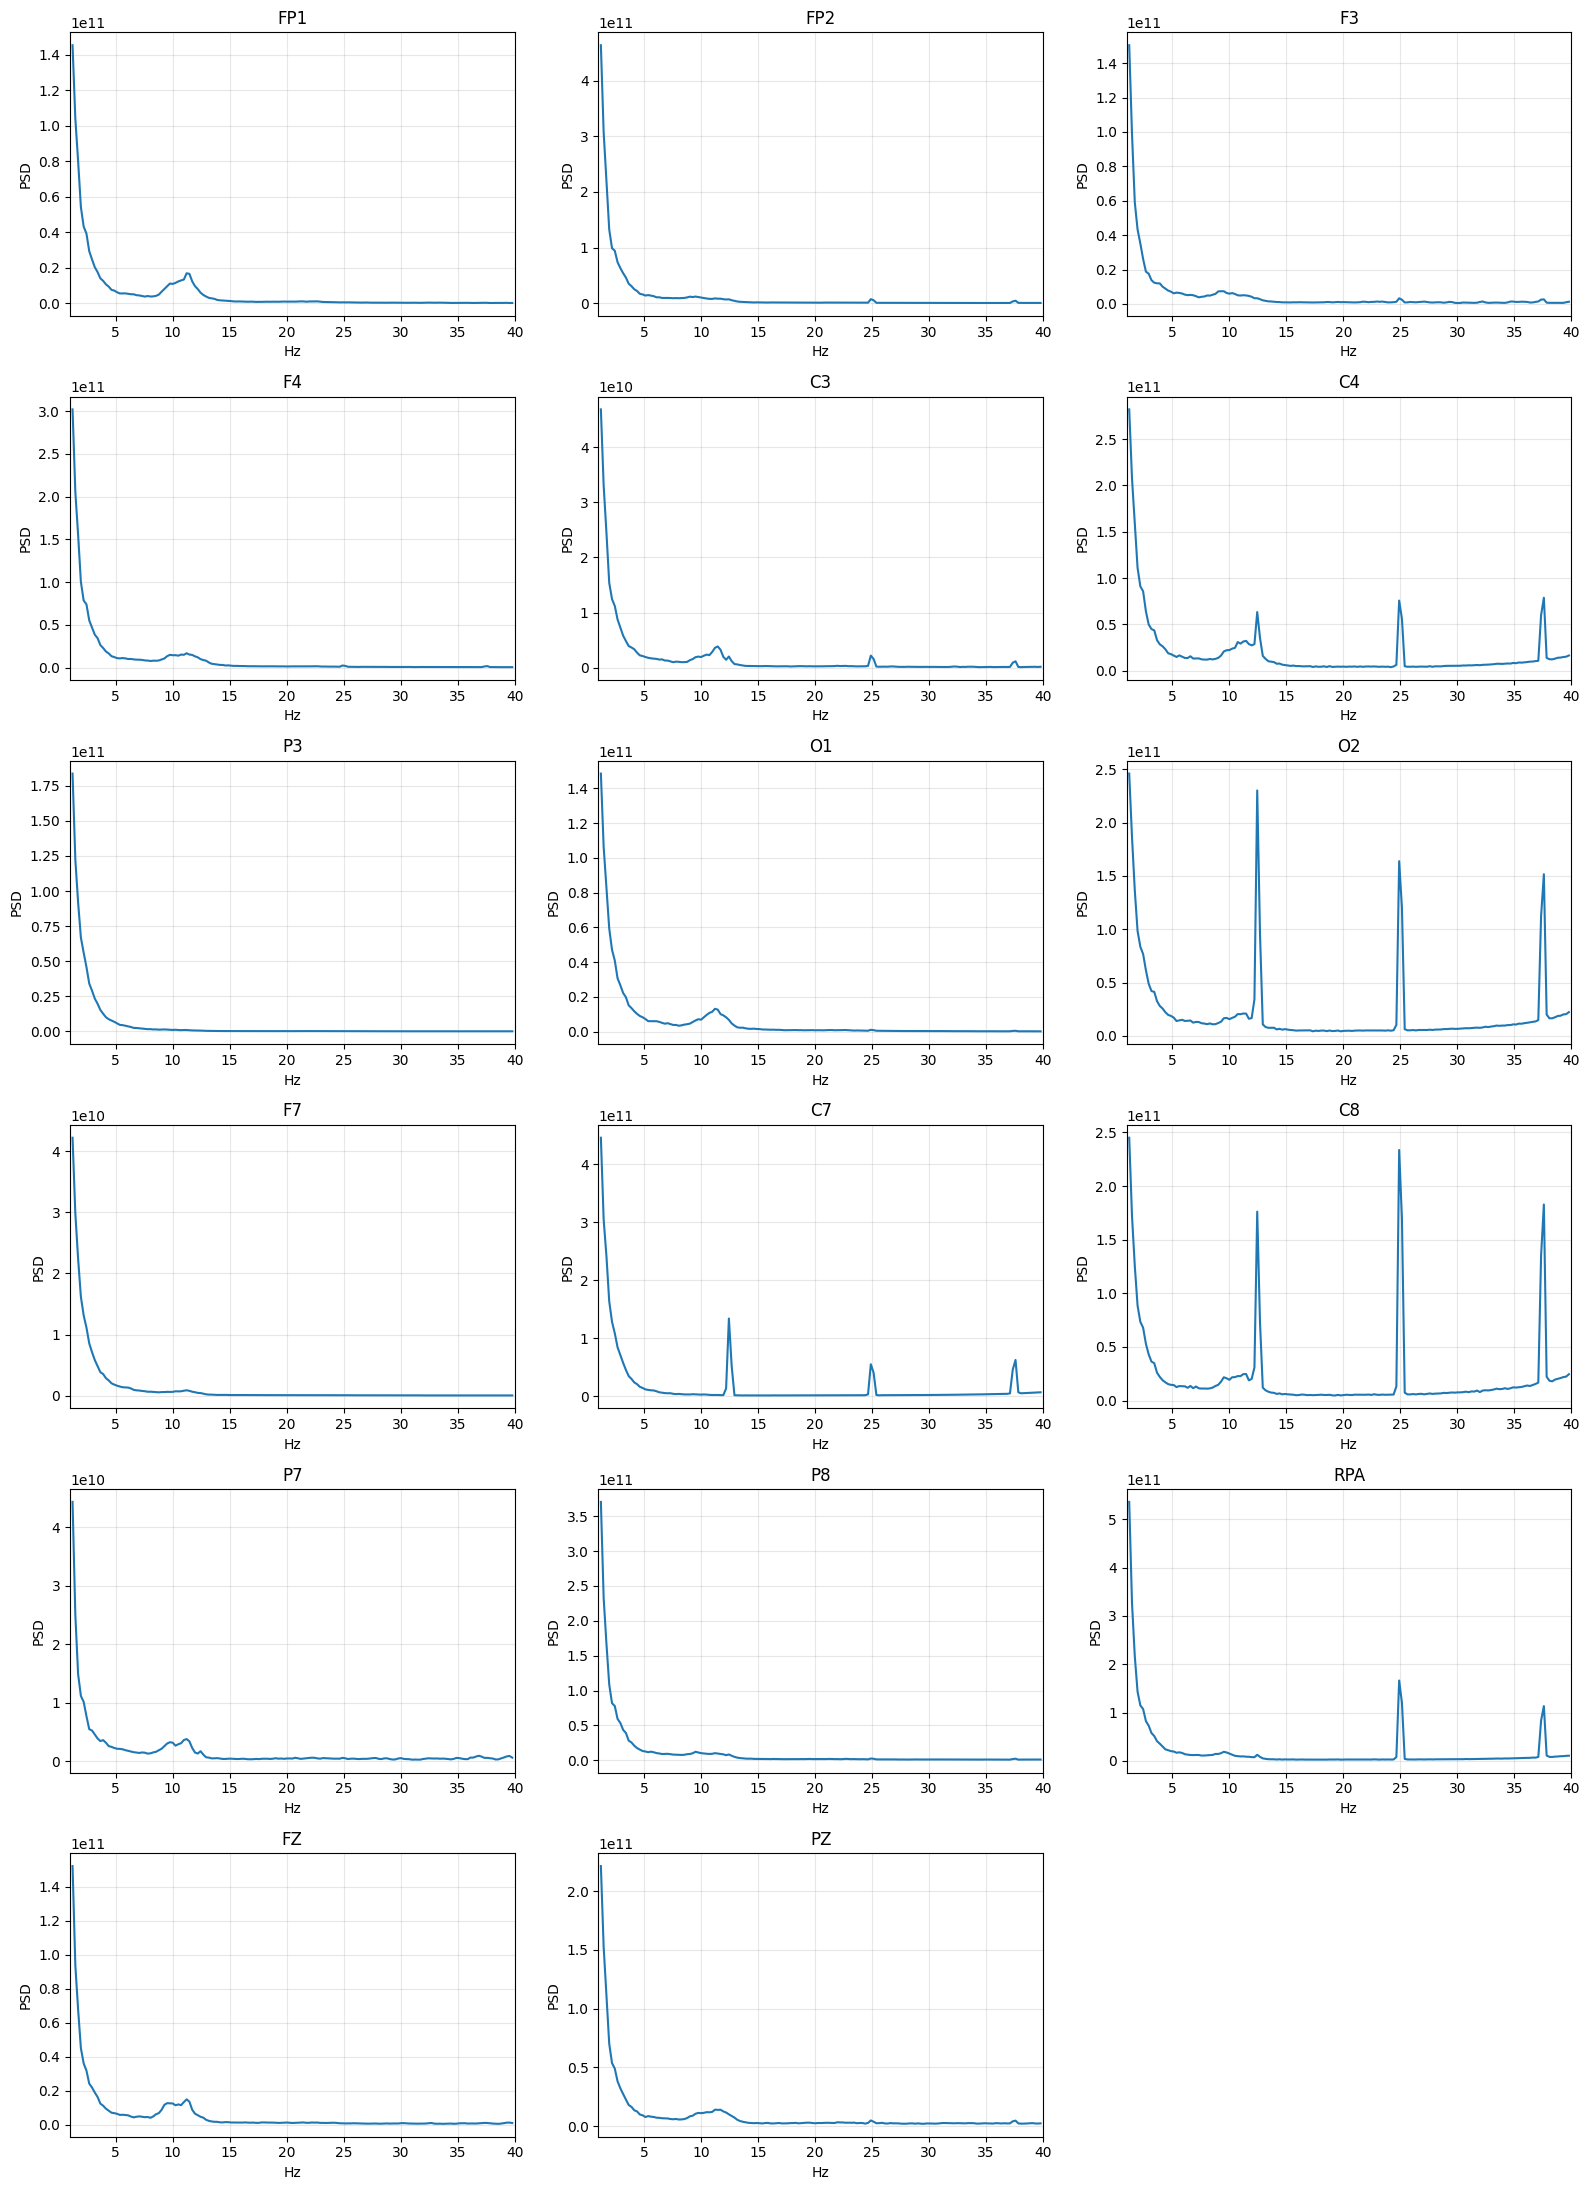

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Рисуем PSD каждого исправного канала
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
axes = axes.ravel()

for i, ch_name in enumerate(spectrum.ch_names):
    axes[i].plot(freqs, psd[i])
    axes[i].set_title(ch_name)
    axes[i].set_xlim(1, 40)
    axes[i].set_xlabel("Hz")
    axes[i].set_ylabel("PSD")
    axes[i].grid(alpha=0.3)

# Удаляем лишние панели
for j in range(len(spectrum.ch_names), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

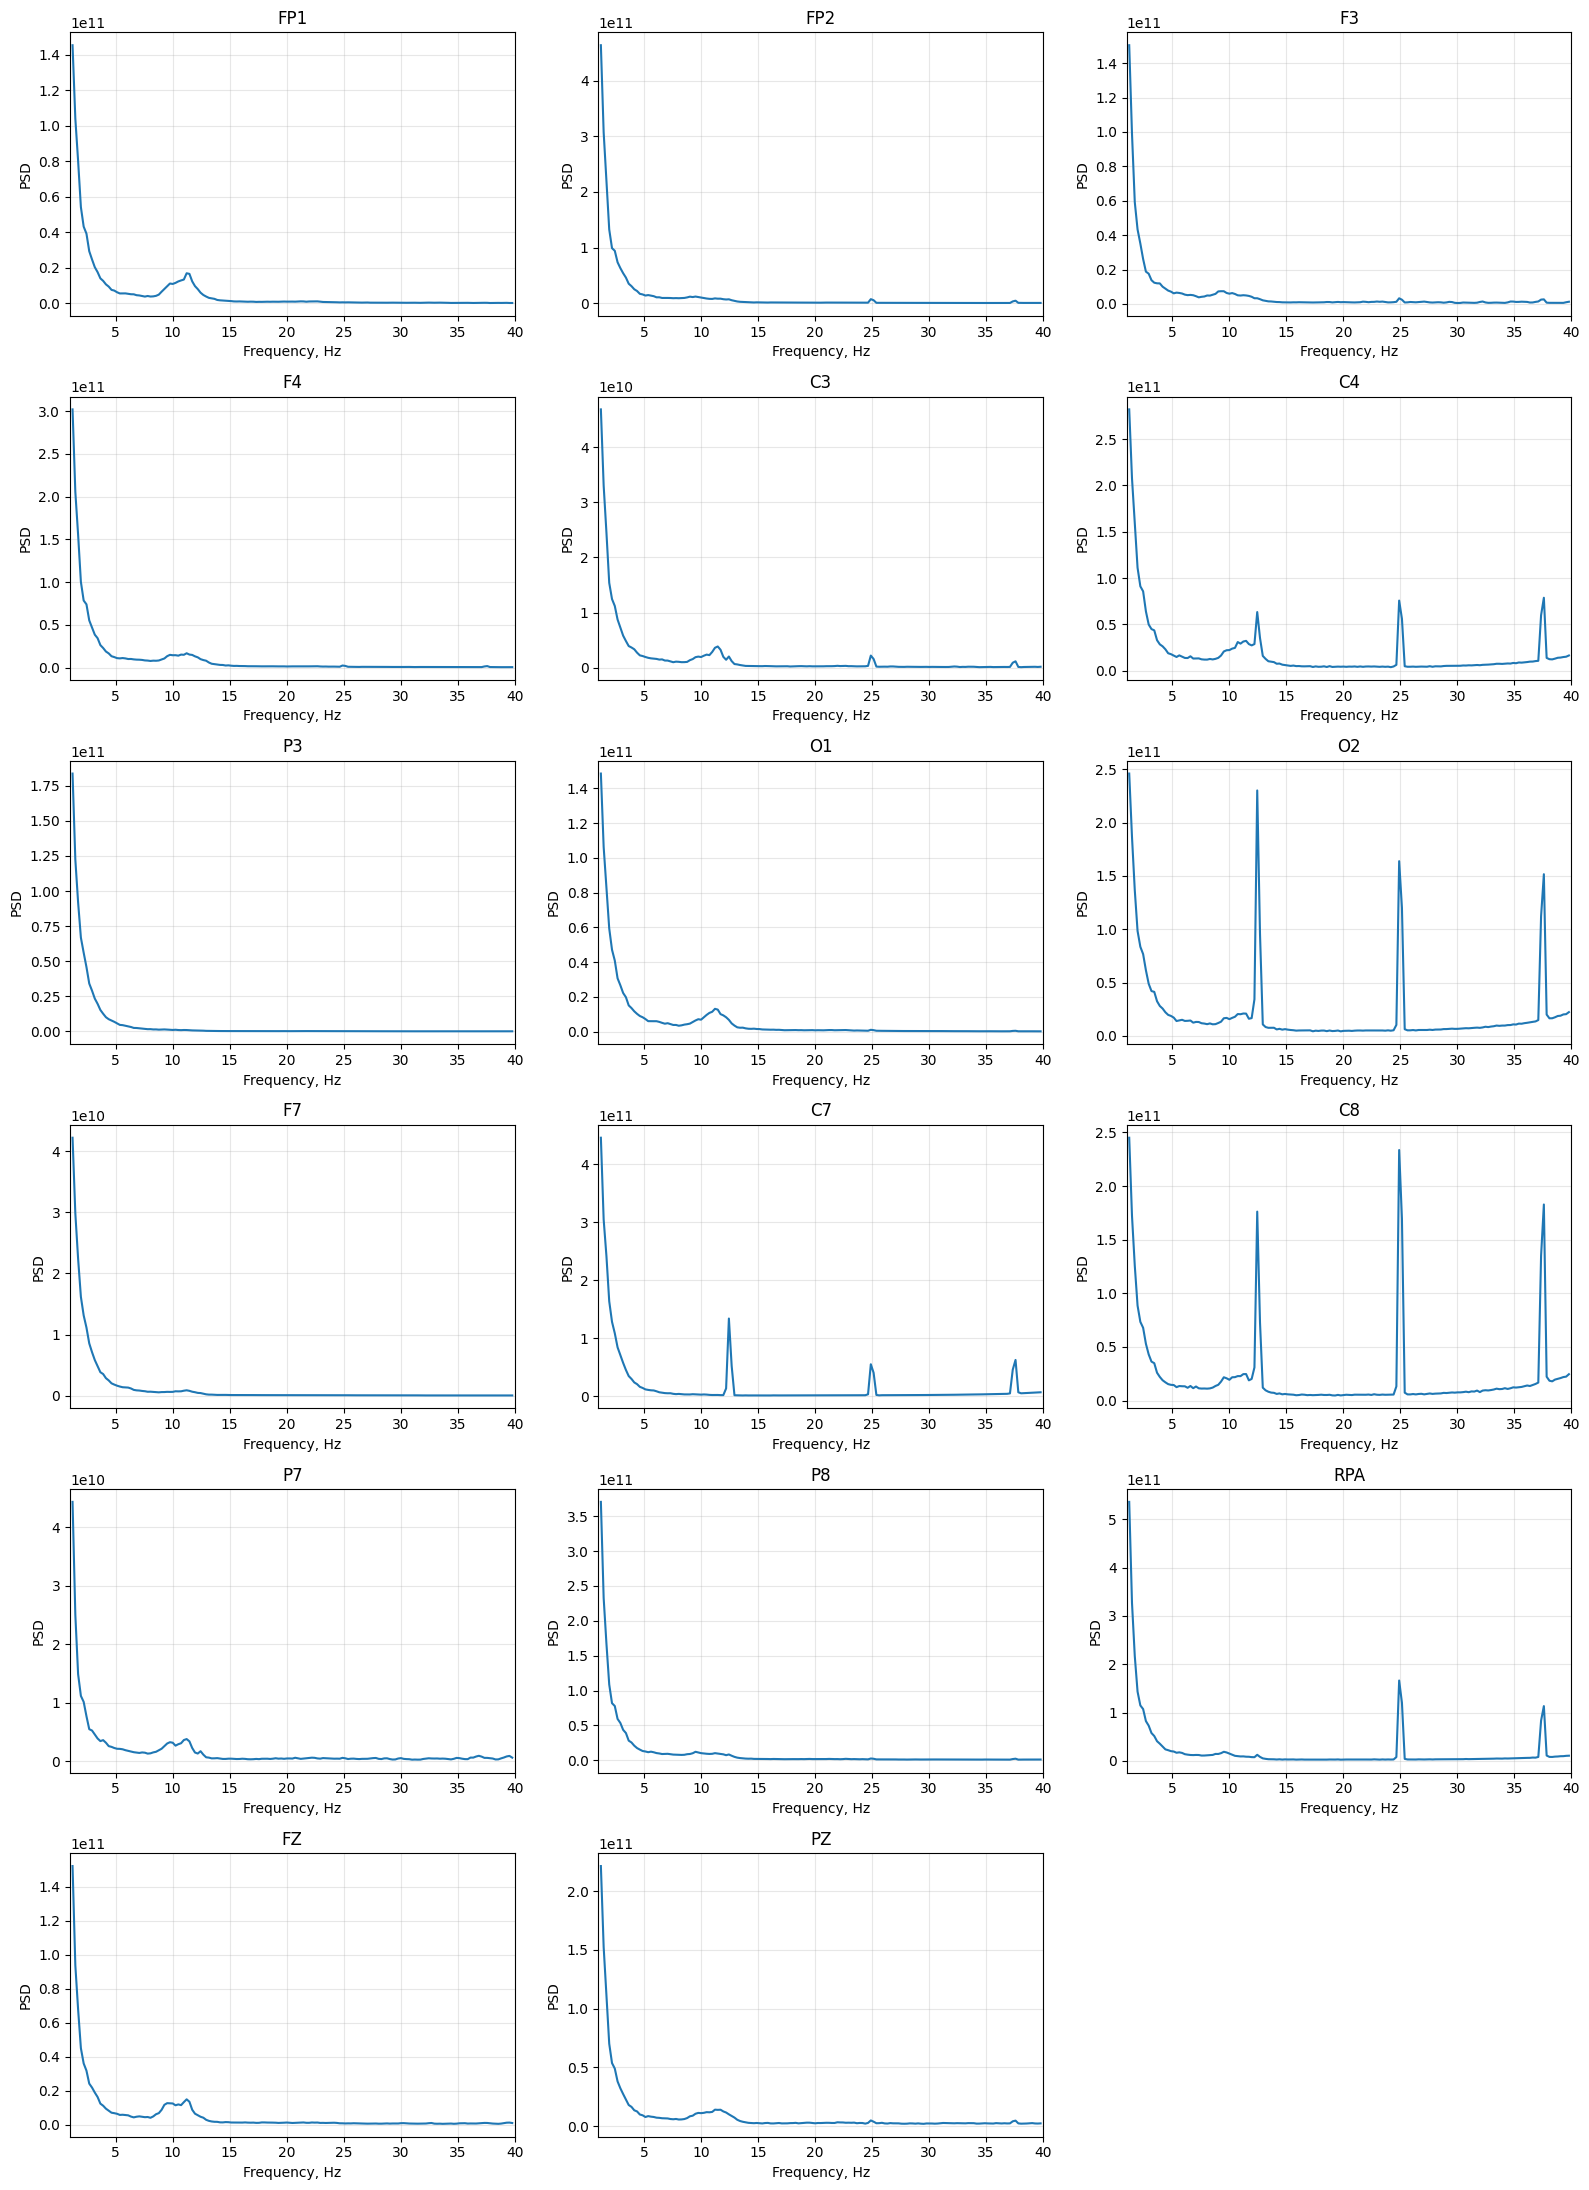

In [23]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
axes = axes.ravel()

for i, ch_name in enumerate(spectrum.ch_names):
    axes[i].plot(freqs, psd[i])
    axes[i].set_title(ch_name)
    axes[i].set_xlim(1, 40)
    axes[i].set_xlabel("Frequency, Hz")
    axes[i].set_ylabel("PSD")
    axes[i].grid(alpha=0.3)

for j in range(len(spectrum.ch_names), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()



In [24]:
def get_runs(states):
    states = np.asarray(states)
    changes = np.where(np.diff(states) != 0)[0] + 1
    starts = np.r_[0, changes]
    ends = np.r_[changes, len(states)]
    
    runs = []
    for start, end in zip(starts, ends):
        runs.append({
            "start": start,
            "end": end,
            "state": int(states[start]),
            "duration_sec": (end - start) / fs
        })
    return pd.DataFrame(runs)

runs = get_runs(eeg["States"])

# Только классифицируемые состояния
trial_runs = runs[runs["state"].isin([1, 2, 3])].copy()

print(trial_runs.groupby("state")["duration_sec"].agg(
    ["count", "min", "max", "mean", "std"]
))

       count    min    max      mean       std
state                                         
1         28  8.988  9.012  8.999571  0.006094
2         14  8.988  9.012  9.000000  0.009414
3         14  8.988  9.012  8.999143  0.008761


In [25]:
# Извлекаем 6 секунд из середины каждого trial
# 2–8 сек от начала состояния

eeg_data = eeg["Raw"]

trial_data = {
    1: [],  # rest
    2: [],  # left MI
    3: []   # right MI
}

for _, row in trial_runs.iterrows():
    start = int(row["start"] + 2 * fs)
    end = int(row["start"] + 8 * fs)
    
    trial_data[int(row["state"])].append(eeg_data[start:end, :])

for state in trial_data:
    trial_data[state] = np.stack(trial_data[state])

    print(
        f"State {state}: "
        f"{trial_data[state].shape[0]} trials × "
        f"{trial_data[state].shape[1]} samples × "
        f"{trial_data[state].shape[2]} channels"
    )

State 1: 28 trials × 1500 samples × 21 channels
State 2: 14 trials × 1500 samples × 21 channels
State 3: 14 trials × 1500 samples × 21 channels


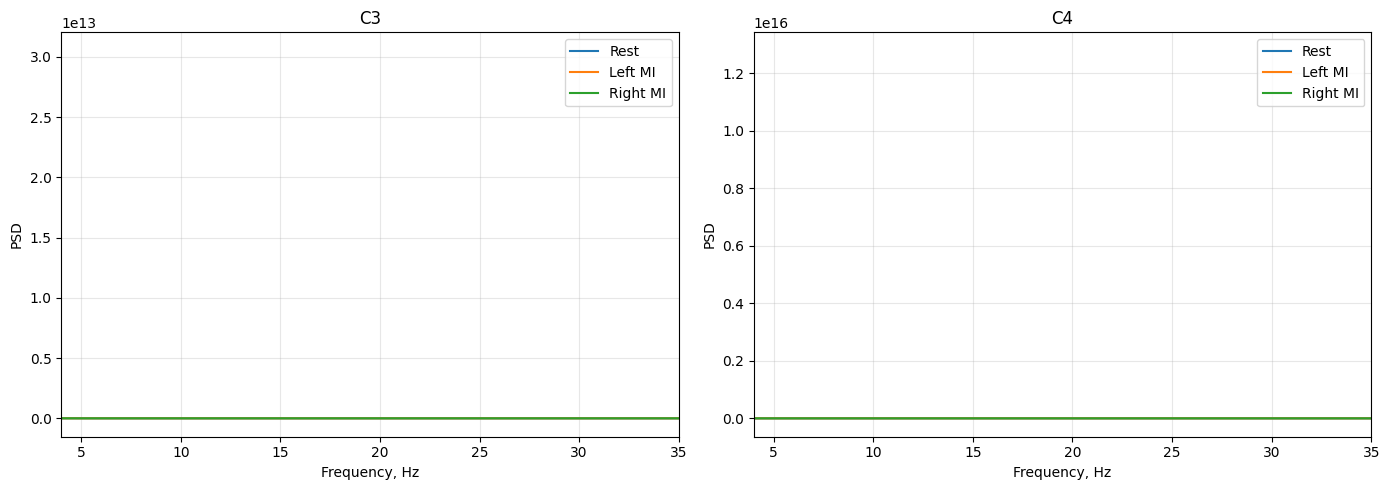

In [26]:
from scipy.signal import welch

channels_to_plot = ["C3", "C4"]
channel_idx = {ch: i for i, ch in enumerate(eeg_labels)}

state_names = {
    1: "Rest",
    2: "Left MI",
    3: "Right MI"
}

state_psd = {}

for state in [1, 2, 3]:
    state_psd[state] = {}

    for ch in channels_to_plot:
        idx = channel_idx[ch]

        # trials × samples
        x = trial_data[state][:, :, idx]

        f, pxx = welch(
            x,
            fs=fs,
            nperseg=512,
            noverlap=256,
            axis=1
        )

        # Средний PSD по trials
        state_psd[state][ch] = pxx.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ch in zip(axes, channels_to_plot):
    for state in [1, 2, 3]:
        ax.plot(
            f,
            state_psd[state][ch],
            label=state_names[state]
        )

    ax.set_title(ch)
    ax.set_xlim(4, 35)
    ax.set_xlabel("Frequency, Hz")
    ax.set_ylabel("PSD")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [27]:
for ch in ["C3", "C4"]:
    idx = channel_idx[ch]

    print(f"\n{ch}")
    for state in [1, 2, 3]:
        x = trial_data[state][:, :, idx]

        print(
            f"  State {state}: "
            f"min={x.min():.3e}, "
            f"max={x.max():.3e}, "
            f"mean={x.mean():.3e}, "
            f"std={x.std():.3e}"
        )


C3
  State 1: min=-3.866e+08, max=-3.532e+08, mean=-3.707e+08, std=6.448e+06
  State 2: min=-3.843e+08, max=-3.553e+08, mean=-3.704e+08, std=6.416e+06
  State 3: min=-3.873e+08, max=-3.534e+08, mean=-3.702e+08, std=6.879e+06

C4
  State 1: min=-1.043e+08, max=3.835e+08, mean=1.069e+08, std=1.193e+08
  State 2: min=-9.718e+07, max=3.863e+08, mean=1.124e+08, std=1.208e+08
  State 3: min=-9.374e+07, max=3.748e+08, mean=1.107e+08, std=1.196e+08


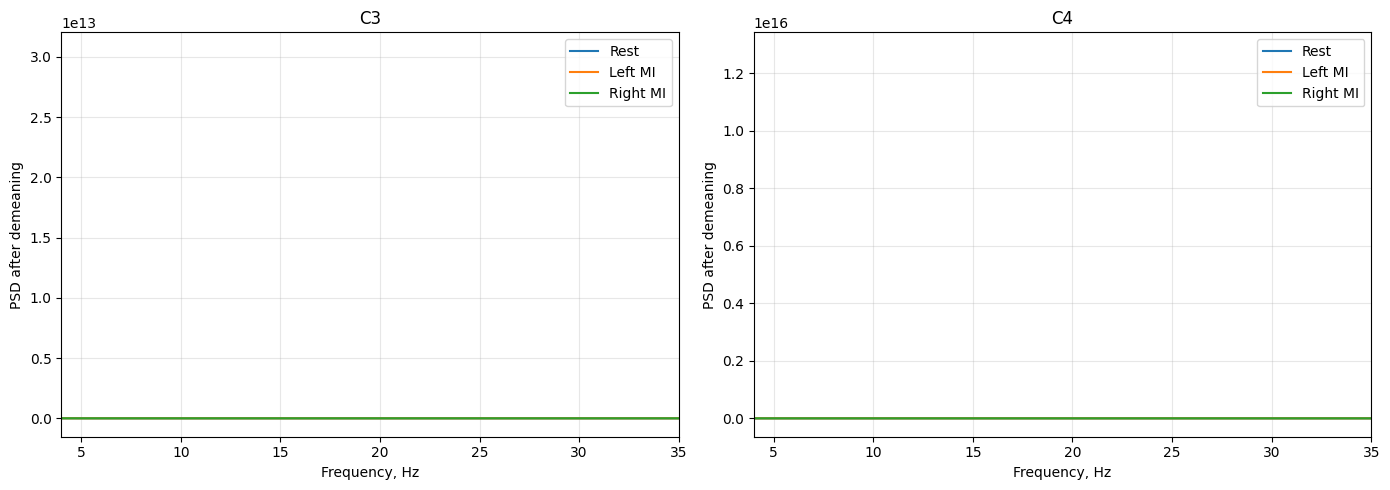

In [28]:
state_psd_demeaned = {}

for state in [1, 2, 3]:
    state_psd_demeaned[state] = {}

    for ch in ["C3", "C4"]:
        idx = channel_idx[ch]

        # trials × samples
        x = trial_data[state][:, :, idx]

        # Убираем DC-offset отдельно для каждого trial
        x = x - x.mean(axis=1, keepdims=True)

        f, pxx = welch(
            x,
            fs=fs,
            nperseg=512,
            noverlap=256,
            axis=1
        )

        state_psd_demeaned[state][ch] = pxx.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ch in zip(axes, ["C3", "C4"]):
    for state in [1, 2, 3]:
        ax.plot(
            f,
            state_psd_demeaned[state][ch],
            label=state_names[state]
        )

    ax.set_title(ch)
    ax.set_xlim(4, 35)
    ax.set_xlabel("Frequency, Hz")
    ax.set_ylabel("PSD after demeaning")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [29]:
for ch in ["C3", "C4"]:
    print(f"\n{ch}")

    for state in [1, 2, 3]:
        p = state_psd_demeaned[state][ch]

        print(
            f"  State {state}: "
            f"min PSD = {p.min():.3e}, "
            f"max PSD = {p.max():.3e}, "
            f"mean PSD = {p.mean():.3e}"
        )

    # Проверяем конкретные частоты
    for target_freq in [8, 10, 13, 20, 25, 30]:
        idx = np.argmin(np.abs(f - target_freq))
        values = [
            state_psd_demeaned[state][ch][idx]
            for state in [1, 2, 3]
        ]

        print(
            f"  {target_freq} Hz: "
            + ", ".join(f"{v:.3e}" for v in values)
        )


C3
  State 1: min PSD = 6.738e+07, max PSD = 3.051e+13, mean PSD = 2.225e+11
  State 2: min PSD = 2.656e+07, max PSD = 3.034e+13, mean PSD = 2.203e+11
  State 3: min PSD = 1.685e+07, max PSD = 3.038e+13, mean PSD = 2.211e+11
  8 Hz: 1.035e+09, 1.255e+09, 8.467e+08
  10 Hz: 2.690e+09, 1.463e+09, 1.124e+09
  13 Hz: 6.628e+08, 5.353e+08, 5.711e+08
  20 Hz: 2.517e+08, 1.896e+08, 2.670e+08
  25 Hz: 1.251e+09, 1.369e+09, 1.266e+09
  30 Hz: 1.708e+08, 1.053e+08, 9.853e+07

C4
  State 1: min PSD = 2.652e+08, max PSD = 1.252e+16, mean PSD = 9.034e+13
  State 2: min PSD = 2.232e+08, max PSD = 1.278e+16, mean PSD = 9.219e+13
  State 3: min PSD = 2.120e+08, max PSD = 1.266e+16, mean PSD = 9.109e+13
  8 Hz: 1.053e+10, 1.182e+10, 1.092e+10
  10 Hz: 2.509e+10, 2.122e+10, 1.269e+10
  13 Hz: 1.378e+10, 1.197e+10, 1.431e+10
  20 Hz: 2.350e+09, 2.082e+09, 2.295e+09
  25 Hz: 4.299e+10, 3.881e+10, 4.378e+10
  30 Hz: 1.036e+09, 7.419e+08, 9.683e+08


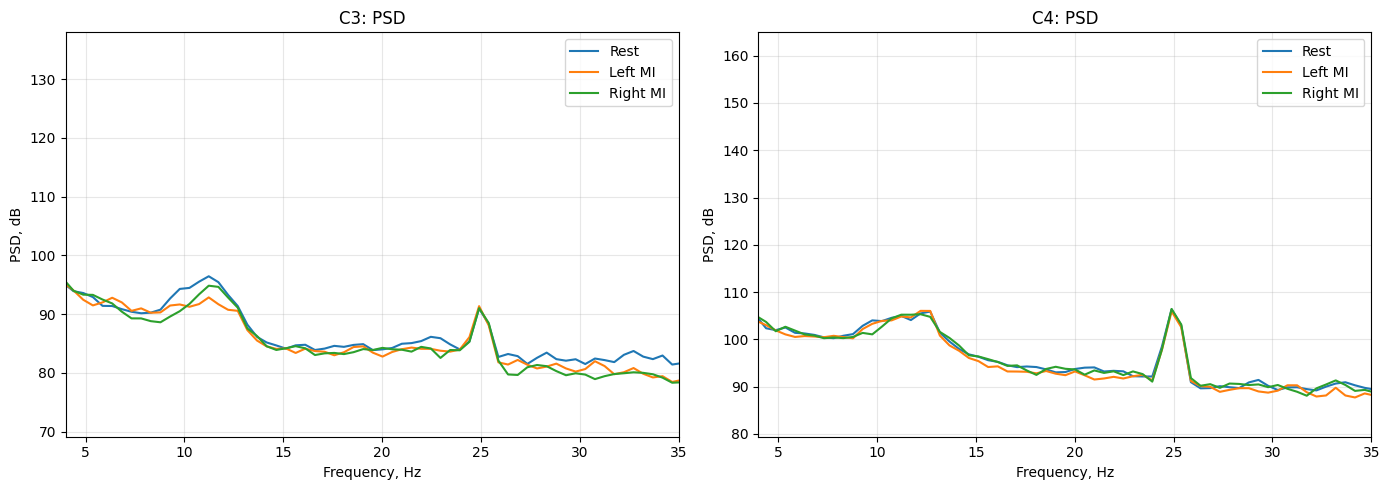

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, ch in zip(axes, ["C3", "C4"]):
    for state in [1, 2, 3]:
        p = state_psd_demeaned[state][ch]

        # PSD в dB
        p_db = 10 * np.log10(p)

        ax.plot(
            f,
            p_db,
            label=state_names[state]
        )

    ax.set_title(f"{ch}: PSD")
    ax.set_xlim(4, 35)
    ax.set_xlabel("Frequency, Hz")
    ax.set_ylabel("PSD, dB")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [31]:
from scipy.signal import welch

bands = {
    "mu": (8, 13),
    "beta": (13, 30)
}

band_power = []

for state in [1, 2, 3]:
    for trial_id in range(trial_data[state].shape[0]):
        row = {
            "state": state,
            "trial": trial_id
        }

        for ch in ["C3", "C4"]:
            idx = channel_idx[ch]

            x = trial_data[state][trial_id, :, idx]

            # Убираем DC для конкретного trial
            x = x - x.mean()

            f_trial, pxx = welch(
                x,
                fs=fs,
                nperseg=512,
                noverlap=256
            )

            total_mask = (f_trial >= 4) & (f_trial <= 35)
            total_power = np.trapz(
                pxx[total_mask],
                f_trial[total_mask]
            )

            for band_name, (low, high) in bands.items():
                mask = (f_trial >= low) & (f_trial <= high)

                power = np.trapz(
                    pxx[mask],
                    f_trial[mask]
                )

                # Относительная мощность
                relative_power = power / total_power

                row[f"{ch}_{band_name}"] = relative_power

        band_power.append(row)

band_power = pd.DataFrame(band_power)

print(band_power.groupby("state").mean(numeric_only=True))

       trial     C3_mu   C3_beta     C4_mu   C4_beta
state                                               
1       13.5  0.470130  0.230130  0.424710  0.295468
2        6.5  0.342467  0.272323  0.455302  0.270994
3        6.5  0.407544  0.254150  0.413376  0.319598


/tmp/ipykernel_5720/2901934573.py:12: MatplotlibDeprecationWarning: Passing the notch parameter of boxplot() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax.boxplot(
/tmp/ipykernel_5720/2901934573.py:12: MatplotlibDeprecationWarning: Passing the notch parameter of boxplot() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  ax.boxplot(


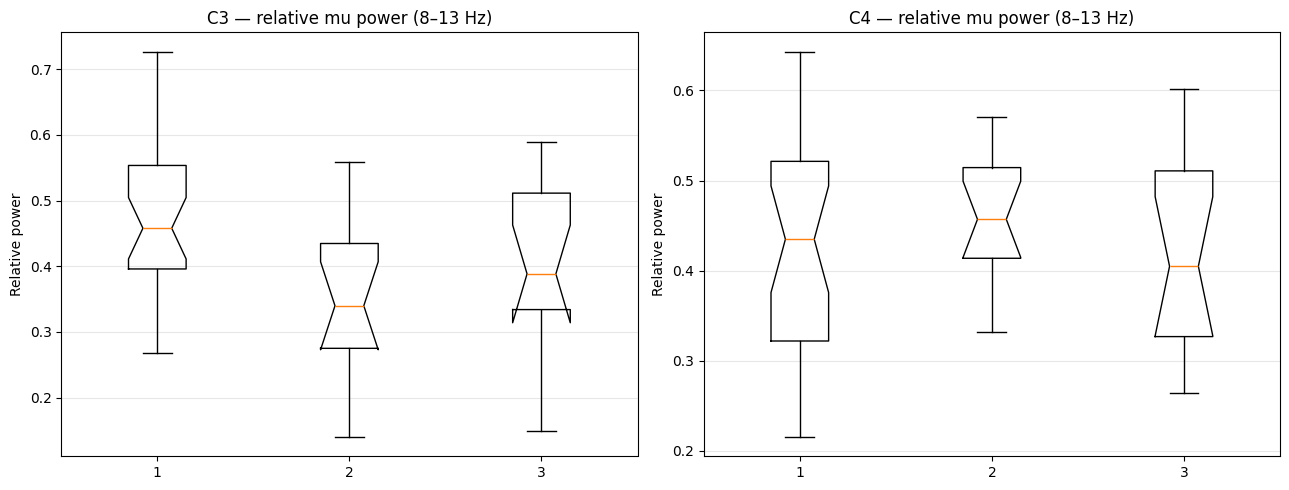

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tick_labels=["Rest", "Left MI", "Right MI"]

for ax, ch in zip(axes, ["C3", "C4"]):
    columns = [f"{ch}_mu"]

    data_to_plot = [
        band_power.loc[band_power["state"] == state, columns[0]].values
        for state in [1, 2, 3]
    ]

    ax.boxplot(
        data_to_plot,
        tick_labels
    )

    ax.set_title(f"{ch} — relative mu power (8–13 Hz)")
    ax.set_ylabel("Relative power")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
from scipy.signal import butter, sosfiltfilt

good_idx = [
    i for i, ch in enumerate(eeg_labels)
    if ch not in bad_channels
]

print("Good channels:", [eeg_labels[i] for i in good_idx])

# Полосовой фильтр 8–30 Гц
sos = butter(
    4,
    [8, 30],
    btype="bandpass",
    fs=fs,
    output="sos"
)

csp_data = {}

for state in [1, 2, 3]:
    x = trial_data[state][:, :, good_idx]

    # Фильтрация каждого trial/channel
    x_filtered = sosfiltfilt(
        sos,
        x,
        axis=1
    )

    csp_data[state] = x_filtered

    print(
        f"State {state}: "
        f"{x_filtered.shape}, "
        f"std={x_filtered.std():.3e}"
    )

Good channels: ['FP1', 'FP2', 'F3', 'F4', 'C3', 'C4', 'P3', 'O1', 'O2', 'F7', 'C7', 'C8', 'P7', 'P8', 'RPA', 'FZ', 'PZ']
State 1: (28, 1500, 17), std=3.442e+06
State 2: (14, 1500, 17), std=3.605e+06
State 3: (14, 1500, 17), std=3.706e+06


In [34]:
from mne.decoding import CSP

# Объединяем trials
X = np.concatenate(
    [csp_data[1], csp_data[2], csp_data[3]],
    axis=0
)

y = np.concatenate([
    np.full(len(csp_data[1]), 1),
    np.full(len(csp_data[2]), 2),
    np.full(len(csp_data[3]), 3)
])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts:", np.bincount(y)[1:])

X_csp_input = X.transpose(0, 2, 1)

print("Before:", X.shape)
print("For CSP:", X_csp_input.shape)

X shape: (56, 1500, 17)
y shape: (56,)
Class counts: [28 14 14]
Before: (56, 1500, 17)
For CSP: (56, 17, 1500)


In [35]:
csp = CSP(
    n_components=6,
    reg="ledoit_wolf",
    log=True,
    norm_trace=False
)

X_csp = csp.fit_transform(X_csp_input, y)

print("CSP features:", X_csp.shape)
print("Feature means:")
print(np.round(X_csp.mean(axis=0), 3))

Computing rank from data with rank=None
    Using tolerance 1.6e+07 (2.2e-16 eps * 17 dim * 4.1e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
CSP features: (56, 6)
Feature means:
[-4.166 -3.225 -3.398 -2.615 -2.694 -2.467]


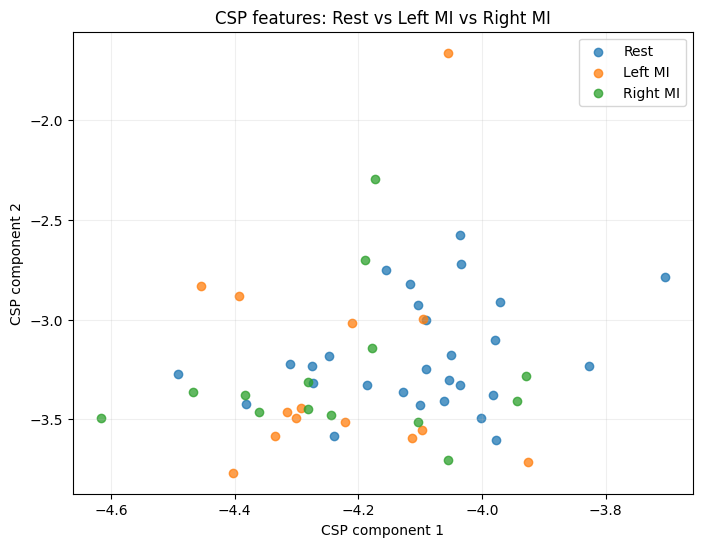

In [36]:
plt.figure(figsize=(8, 6))

for state, label in [
    (1, "Rest"),
    (2, "Left MI"),
    (3, "Right MI")
]:
    mask = y == state

    plt.scatter(
        X_csp[mask, 0],
        X_csp[mask, 1],
        label=label,
        alpha=0.75
    )

plt.xlabel("CSP component 1")
plt.ylabel("CSP component 2")
plt.title("CSP features: Rest vs Left MI vs Right MI")
plt.legend()
plt.grid(alpha=0.2)
plt.savefig('csp_features', dpi = 300)
plt.show()

In [37]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lda = LinearDiscriminantAnalysis(
    solver="lsqr",
    shrinkage="auto"
)

lda.fit(X_csp, y)

y_pred = lda.predict(X_csp)

print("Training accuracy:", accuracy_score(y, y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y, y_pred, labels=[1, 2, 3]))

print("\nClassification report:")
print(
    classification_report(
        y,
        y_pred,
        labels=[1, 2, 3],
        target_names=["Rest", "Left MI", "Right MI"],
        digits=3
    )
)

Training accuracy: 0.6428571428571429

Confusion matrix:
[[23  3  2]
 [ 4  9  1]
 [ 9  1  4]]

Classification report:
              precision    recall  f1-score   support

        Rest      0.639     0.821     0.719        28
     Left MI      0.692     0.643     0.667        14
    Right MI      0.571     0.286     0.381        14

    accuracy                          0.643        56
   macro avg      0.634     0.583     0.589        56
weighted avg      0.635     0.643     0.621        56



In [38]:
trial_blocks = []

for _, row in trial_runs.iterrows():
    trial_blocks.append(
        int(eeg["Blocks"][int(row["start"])])
    )

trial_blocks = np.array(trial_blocks)

print("Trial blocks:", trial_blocks)
print("Counts by block:")
print(pd.Series(trial_blocks).value_counts().sort_index())

Trial blocks: [1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 4 4 4 4 4 4 4 4 5 5 5 5 5
 5 5 5 6 6 6 6 6 6 6 6 7 7 7 7 7 7 7 7]
Counts by block:
1    8
2    8
3    8
4    8
5    8
6    8
7    8
dtype: int64


In [39]:
from sklearn.metrics import accuracy_score, recall_score, f1_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from mne.decoding import CSP

blocks = np.unique(trial_blocks)

results = []

for test_block in blocks:
    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    X_train = X_csp_input[train_mask]
    y_train = y[train_mask]

    X_test = X_csp_input[test_mask]
    y_test = y[test_mask]

    # CSP обучаем ТОЛЬКО на train
    csp_block = CSP(
        n_components=6,
        reg="ledoit_wolf",
        log=True,
        norm_trace=False
    )

    X_train_csp = csp_block.fit_transform(X_train, y_train)
    X_test_csp = csp_block.transform(X_test)

    # LDA обучаем ТОЛЬКО на train
    lda_block = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda_block.fit(X_train_csp, y_train)
    y_pred = lda_block.predict(X_test_csp)

    results.append({
        "test_block": test_block,
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_recall": recall_score(
            y_test, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_test, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

print("\nMean:")
print(results_df[["accuracy", "macro_recall", "macro_f1"]].mean())

print("\nStd:")
print(results_df[["accuracy", "macro_recall", "macro_f1"]].std())

Computing rank from data with rank=None
    Using tolerance 1.5e+07 (2.2e-16 eps * 17 dim * 3.9e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 1.4e+07 (2.2e-16 eps * 17 dim * 3.8e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 1.4e+07 (2.2e-16 eps * 17 dim * 3.8e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 compu

In [40]:
from scipy.signal import butter, sosfiltfilt
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import recall_score

bands = {
    "8-12 Hz": (8, 12),
    "13-30 Hz": (13, 30),
    "8-30 Hz": (8, 30)
}

band_results = []

for band_name, (low, high) in bands.items():

    print(f"\n===== {band_name} =====")

    # Фильтр
    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    X_band = sosfiltfilt(
        sos,
        X,              # (56, 1500, 17)
        axis=1
    ).transpose(0, 2, 1)  # -> (56, 17, 1500)

    for test_block in blocks:

        train_mask = trial_blocks != test_block
        test_mask = trial_blocks == test_block

        X_train = X_band[train_mask]
        X_test = X_band[test_mask]

        y_train = y[train_mask]
        y_test = y[test_mask]

        # CSP только на train
        csp_band = CSP(
            n_components=6,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False
        )

        X_train_csp = csp_band.fit_transform(
            X_train,
            y_train
        )

        X_test_csp = csp_band.transform(
            X_test
        )

        # LDA только на train
        lda_band = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )

        lda_band.fit(
            X_train_csp,
            y_train
        )

        y_pred = lda_band.predict(
            X_test_csp
        )

        macro_recall = recall_score(
            y_test,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        band_results.append({
            "band": band_name,
            "test_block": test_block,
            "macro_recall": macro_recall
        })

band_results_df = pd.DataFrame(band_results)

print("\n===== RESULTS =====")
print(
    band_results_df
    .pivot(
        index="test_block",
        columns="band",
        values="macro_recall"
    )
    .round(3)
)

print("\n===== MEAN =====")
print(
    band_results_df
    .groupby("band")["macro_recall"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)


===== 8-12 Hz =====
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
  

In [41]:
# QC каналов по блокам
# Проверяем долю экстремальных значений |EEG| > 6e9
# среди 17 каналов, которые сейчас считаем пригодными.

qc_threshold = 6e9

# EEG: samples x channels
eeg_raw = np.asarray(eeg["Raw"])

# Только 17 "хороших" каналов
good_idx = [i for i, ch in enumerate(eeg_labels) if ch not in bad_channels]
good_labels = [eeg_labels[i] for i in good_idx]

# Номера блоков
blocks = np.asarray(eeg["Blocks"]).ravel()

# Таблица: строки = каналы, столбцы = блоки
qc_by_block = pd.DataFrame(
    index=good_labels,
    columns=sorted(np.unique(blocks)),
    dtype=float
)

for block in sorted(np.unique(blocks)):
    mask = blocks == block
    
    for ch_idx, ch_name in zip(good_idx, good_labels):
        x = eeg_raw[mask, ch_idx]
        qc_by_block.loc[ch_name, block] = np.mean(np.abs(x) > qc_threshold) * 100

print("Доля экстремальных значений |x| > 6e9, %")
display(qc_by_block.round(2))

print("\nСредняя доля экстремальных значений по каналам:")
display(
    qc_by_block.mean(axis=1)
    .sort_values(ascending=False)
    .round(2)
)

print("\nСредняя доля экстремальных значений по блокам:")
display(
    qc_by_block.mean(axis=0).round(2)
)

Доля экстремальных значений |x| > 6e9, %


,1,2,3,4,5,6,7
FP1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
FP2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
F3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
F4,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
C4,0.0,0.0,0.0,0.0,0.0,0.0,0.0
P3,0.0,0.0,0.0,0.0,0.0,0.0,0.0
O1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
O2,0.0,0.0,0.0,0.0,0.0,0.0,0.0
F7,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Средняя доля экстремальных значений по каналам:


FP1    0.0
FP2    0.0
F3     0.0
F4     0.0
C3     0.0
C4     0.0
P3     0.0
O1     0.0
O2     0.0
F7     0.0
C7     0.0
C8     0.0
P7     0.0
P8     0.0
RPA    0.0
FZ     0.0
PZ     0.0
dtype: float64


Средняя доля экстремальных значений по блокам:


1    0.0
2    0.0
3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
dtype: float64

In [42]:
# RMS EEG по блокам для 17 оставшихся каналов

rms_by_block = pd.DataFrame(
    index=good_labels,
    columns=sorted(np.unique(blocks)),
    dtype=float
)

for block in sorted(np.unique(blocks)):
    mask = blocks == block
    
    for ch_idx, ch_name in zip(good_idx, good_labels):
        x = eeg_raw[mask, ch_idx].astype(float)
        
        # Убираем DC-составляющую перед RMS
        x = x - np.mean(x)
        
        rms_by_block.loc[ch_name, block] = np.sqrt(np.mean(x**2))

print("RMS по каналам и блокам:")
display(rms_by_block.round(2))

print("\nОтносительное изменение RMS: блок 7 / блок 1")
rms_change = (rms_by_block[7] / rms_by_block[1]).sort_values(ascending=False)

display(rms_change.round(3))

RMS по каналам и блокам:


,1,2,3,4,5,6,7
FP1,2.647548e+06,2.556365e+06,2.630468e+06,3.260055e+06,3.907884e+06,2.844595e+06,5.044307e+06
FP2,1.511926e+07,1.910891e+07,1.532334e+07,1.522996e+07,1.510354e+07,1.504064e+07,1.484874e+07
F3,7.924041e+06,1.065304e+07,9.604051e+06,7.320406e+06,9.456018e+06,7.750752e+06,6.672524e+06
F4,5.743249e+06,5.800034e+06,5.443383e+06,5.354438e+06,5.213632e+06,5.066868e+06,5.301119e+06
C3,5.638449e+06,5.627750e+06,5.547578e+06,5.422505e+06,5.384994e+06,5.236183e+06,5.899927e+06
C4,8.874582e+07,9.519463e+07,1.007860e+08,1.060978e+08,1.117233e+08,1.174951e+08,1.250495e+08
P3,4.991561e+06,5.081953e+06,5.257249e+06,5.245601e+06,5.296821e+06,5.496935e+06,5.479255e+06
O1,4.129441e+06,3.981021e+06,4.104589e+06,6.217309e+06,4.114250e+06,4.183720e+06,5.490056e+06
O2,1.297654e+08,1.295955e+08,1.301937e+08,1.291194e+08,1.279058e+08,1.268246e+08,1.261663e+08
F7,4.234154e+06,4.206670e+06,4.328052e+06,4.393481e+06,4.520300e+06,4.626961e+06,4.658844e+06



Относительное изменение RMS: блок 7 / блок 1


FP1    1.905
C4     1.409
O1     1.329
C8     1.209
F7     1.100
P3     1.098
C3     1.046
RPA    1.008
C7     0.983
FP2    0.982
O2     0.972
FZ     0.951
P7     0.930
P8     0.928
F4     0.923
PZ     0.896
F3     0.842
dtype: float64

In [43]:
# RMS EEG отдельно для каждого состояния и блока
# Считаем после удаления DC-компоненты.

states_to_check = [1, 2, 3]

rms_state_block = {}

for state in states_to_check:
    table = pd.DataFrame(
        index=good_labels,
        columns=sorted(np.unique(blocks)),
        dtype=float
    )
    
    for block in sorted(np.unique(blocks)):
        mask = (blocks == block) & (eeg["States"].ravel() == state)
        
        for ch_idx, ch_name in zip(good_idx, good_labels):
            x = eeg_raw[mask, ch_idx].astype(float)
            
            if len(x) > 0:
                x = x - np.mean(x)
                table.loc[ch_name, block] = np.sqrt(np.mean(x**2))
    
    rms_state_block[state] = table

    print(f"\n===== STATE {state} =====")
    display(table.round(2))

    print(f"Изменение RMS: блок 7 / блок 1")
    change = (table[7] / table[1]).sort_values(ascending=False)
    display(change.round(3))


===== STATE 1 =====


,1,2,3,4,5,6,7
FP1,2.396995e+06,2.574019e+06,2.600300e+06,3.137416e+06,3.591389e+06,2.883120e+06,4.814714e+06
FP2,1.506983e+07,1.585517e+07,1.525835e+07,1.517823e+07,1.510697e+07,1.504702e+07,1.484941e+07
F3,7.692433e+06,1.049450e+07,1.017493e+07,7.292871e+06,1.004341e+07,7.932561e+06,6.500577e+06
F4,5.670978e+06,5.637036e+06,5.456910e+06,5.309813e+06,5.231915e+06,5.061823e+06,5.177320e+06
C3,5.532340e+06,5.629873e+06,5.508923e+06,5.416127e+06,5.374558e+06,5.207883e+06,5.958265e+06
C4,8.850889e+07,9.506473e+07,1.003606e+08,1.056404e+08,1.115804e+08,1.172752e+08,1.246325e+08
P3,4.997383e+06,5.093174e+06,5.320325e+06,5.238611e+06,5.310416e+06,5.514635e+06,5.519617e+06
O1,3.905342e+06,3.950134e+06,4.074566e+06,6.502457e+06,4.006365e+06,4.330463e+06,4.155012e+06
O2,1.298882e+08,1.294734e+08,1.301648e+08,1.291738e+08,1.280371e+08,1.268400e+08,1.262072e+08
F7,4.186783e+06,4.211190e+06,4.318935e+06,4.376670e+06,4.526856e+06,4.650160e+06,4.668229e+06


Изменение RMS: блок 7 / блок 1


FP1    2.009
C4     1.408
C8     1.208
F7     1.115
P3     1.105
C3     1.077
O1     1.064
FZ     1.012
RPA    1.009
FP2    0.985
C7     0.982
O2     0.972
PZ     0.953
P7     0.935
P8     0.929
F4     0.913
F3     0.845
dtype: float64


===== STATE 2 =====


,1,2,3,4,5,6,7
FP1,2.513742e+06,2.488706e+06,2.732518e+06,3.485759e+06,3.386506e+06,2.683029e+06,6.066737e+06
FP2,1.492950e+07,2.468348e+07,1.525190e+07,1.517948e+07,1.503274e+07,1.495031e+07,1.486339e+07
F3,7.653096e+06,8.047636e+06,7.976906e+06,6.818257e+06,6.652426e+06,8.304199e+06,6.860292e+06
F4,5.473704e+06,5.548604e+06,5.353145e+06,5.309611e+06,5.020477e+06,5.026429e+06,5.394413e+06
C3,5.394692e+06,5.546174e+06,5.577005e+06,5.354316e+06,5.273000e+06,5.217546e+06,5.807019e+06
C4,9.079136e+07,9.467488e+07,1.025908e+08,1.059175e+08,1.132653e+08,1.180842e+08,1.254146e+08
P3,4.891549e+06,5.038556e+06,5.138513e+06,5.187138e+06,5.284178e+06,5.396715e+06,5.468032e+06
O1,3.997403e+06,3.990983e+06,4.021090e+06,4.069552e+06,4.047956e+06,4.169514e+06,6.485118e+06
O2,1.291194e+08,1.295380e+08,1.300534e+08,1.291446e+08,1.274431e+08,1.269371e+08,1.260085e+08
F7,4.197955e+06,4.230353e+06,4.381811e+06,4.378452e+06,4.521560e+06,4.575417e+06,4.639661e+06


... (2 outputs left out)


===== STATE 3 =====


,1,2,3,4,5,6,7
FP1,2.212398e+06,2.406085e+06,2.441866e+06,2.695039e+06,4.222412e+06,2.726174e+06,3.769734e+06
FP2,1.501284e+07,1.660807e+07,1.532728e+07,1.513495e+07,1.506000e+07,1.494014e+07,1.478268e+07
F3,7.189872e+06,1.252248e+07,8.298557e+06,7.476131e+06,7.973720e+06,6.540591e+06,6.531672e+06
F4,5.542895e+06,5.965770e+06,5.410625e+06,5.225646e+06,5.170944e+06,4.959930e+06,5.312596e+06
C3,5.480127e+06,5.484116e+06,5.472124e+06,5.369778e+06,5.406807e+06,5.280341e+06,5.935695e+06
C4,8.801337e+07,9.598871e+07,9.954587e+07,1.071088e+08,1.105850e+08,1.175116e+08,1.251885e+08
P3,4.965309e+06,5.053501e+06,5.080231e+06,5.219294e+06,5.225825e+06,5.367238e+06,5.426721e+06
O1,3.820043e+06,4.101236e+06,3.887156e+06,6.704477e+06,3.797485e+06,3.739135e+06,3.734112e+06
O2,1.302105e+08,1.299893e+08,1.301388e+08,1.287709e+08,1.280234e+08,1.266315e+08,1.261064e+08
F7,4.131687e+06,4.193919e+06,4.276867e+06,4.404150e+06,4.481854e+06,4.602327e+06,4.658443e+06


Изменение RMS: блок 7 / блок 1


FP1    1.704
C4     1.422
C8     1.205
F7     1.127
P3     1.093
C3     1.083
FZ     1.027
RPA    1.006
FP2    0.985
C7     0.981
O1     0.978
O2     0.968
F4     0.958
P8     0.945
P7     0.941
PZ     0.923
F3     0.908
dtype: float64

In [44]:
from scipy.signal import butter, sosfiltfilt

# 8–12 Hz
sos_mu = butter(
    4,
    [8, 12],
    btype="bandpass",
    fs=fs,
    output="sos"
)

motor_channels = ["C3", "C4"]

mu_by_block_state = []

for block in sorted(np.unique(blocks)):
    for state in [1, 2, 3]:
        mask = (blocks == block) & (eeg["States"].ravel() == state)

        row = {
            "block": block,
            "state": state
        }

        for ch_name in motor_channels:
            ch_idx = eeg_labels.index(ch_name)
            x = eeg_raw[mask, ch_idx].astype(float)

            # Убираем DC
            x = x - np.mean(x)

            # 8–12 Hz
            x_mu = sosfiltfilt(sos_mu, x)

            # Средняя мощность
            power = np.mean(x_mu ** 2)

            row[f"{ch_name}_mu_power"] = power

        mu_by_block_state.append(row)

mu_df = pd.DataFrame(mu_by_block_state)

print("8–12 Hz power по блокам и состояниям:")
display(mu_df.round(2))

8–12 Hz power по блокам и состояниям:


,block,state,C3_mu_power,C4_mu_power
0,1,1,9.377564e+09,9.538291e+11
1,1,2,2.297951e+10,3.948812e+12
2,1,3,1.053011e+10,3.314935e+12
3,2,1,9.864768e+09,1.760815e+12
4,2,2,1.128997e+10,1.357816e+12
5,2,3,2.301403e+10,1.289712e+12
6,3,1,1.252051e+10,3.908750e+11
7,3,2,1.192661e+10,5.695071e+12
8,3,3,1.217829e+10,5.943961e+12
9,4,1,1.617355e+10,1.473583e+12


In [45]:
# Относительная моторная асимметрия в диапазоне 8–12 Hz

pivot = mu_df.pivot(
    index="block",
    columns="state",
    values=["C3_mu_power", "C4_mu_power"]
)

# Отношение C3 / C4
asymmetry = pd.DataFrame(index=sorted(mu_df["block"].unique()))

for state in [1, 2, 3]:
    c3 = pivot[("C3_mu_power", state)]
    c4 = pivot[("C4_mu_power", state)]
    asymmetry[f"state_{state}_C3_C4_ratio"] = c3 / c4

print("C3/C4 ratio в 8–12 Hz:")
display(asymmetry.round(4))

print("\nСреднее отношение C3/C4 по состояниям:")
display(
    asymmetry.mean(axis=0).round(4)
)

C3/C4 ratio в 8–12 Hz:


,state_1_C3_C4_ratio,state_2_C3_C4_ratio,state_3_C3_C4_ratio
1,0.0098,0.0058,0.0032
2,0.0056,0.0083,0.0178
3,0.0320,0.0021,0.0020
4,0.0110,0.0014,0.0020
5,0.0393,0.0009,0.0200
6,0.0273,0.0123,0.0045
7,0.0038,0.0012,0.0015



Среднее отношение C3/C4 по состояниям:


state_1_C3_C4_ratio    0.0184
state_2_C3_C4_ratio    0.0046
state_3_C3_C4_ratio    0.0073
dtype: float64

In [46]:
# Динамика C3/C4 в 8–12 Hz по блокам
# и изменение MI относительно Rest

ratio_df = asymmetry.copy()

# MI относительно Rest
ratio_df["Left_vs_Rest"] = (
    ratio_df["state_2_C3_C4_ratio"] /
    ratio_df["state_1_C3_C4_ratio"]
)

ratio_df["Right_vs_Rest"] = (
    ratio_df["state_3_C3_C4_ratio"] /
    ratio_df["state_1_C3_C4_ratio"]
)

print("C3/C4 ratio по блокам:")
display(ratio_df.round(4))

print("\nИзменение MI/Rest по блокам:")
display(
    ratio_df[
        ["Left_vs_Rest", "Right_vs_Rest"]
    ].round(3)
)

print("\nСредние и SD:")
display(
    ratio_df[
        [
            "state_1_C3_C4_ratio",
            "state_2_C3_C4_ratio",
            "state_3_C3_C4_ratio",
            "Left_vs_Rest",
            "Right_vs_Rest"
        ]
    ].agg(["mean", "std"]).round(4)
)

C3/C4 ratio по блокам:


,state_1_C3_C4_ratio,state_2_C3_C4_ratio,state_3_C3_C4_ratio,Left_vs_Rest,Right_vs_Rest
1,0.0098,0.0058,0.0032,0.5919,0.3231
2,0.0056,0.0083,0.0178,1.4842,3.1851
3,0.0320,0.0021,0.0020,0.0654,0.0640
4,0.0110,0.0014,0.0020,0.1301,0.1850
5,0.0393,0.0009,0.0200,0.0238,0.5089
6,0.0273,0.0123,0.0045,0.4512,0.1663
7,0.0038,0.0012,0.0015,0.3055,0.3869



Изменение MI/Rest по блокам:


,Left_vs_Rest,Right_vs_Rest
1,0.592,0.323
2,1.484,3.185
3,0.065,0.064
4,0.130,0.185
5,0.024,0.509
6,0.451,0.166
7,0.306,0.387



Средние и SD:


,state_1_C3_C4_ratio,state_2_C3_C4_ratio,state_3_C3_C4_ratio,Left_vs_Rest,Right_vs_Rest
mean,0.0184,0.0046,0.0073,0.4360,0.6885
std,0.0142,0.0044,0.0080,0.5068,1.1110


In [47]:
from scipy.stats import pearsonr

# ============================================================
# CSP stability across leave-one-block-out folds
# ============================================================

# Используем тот же диапазон 8–12 Hz, который сейчас дал
# наибольший средний macro-recall.
band = (8, 12)

sos = butter(
    4,
    band,
    btype="bandpass",
    fs=fs,
    output="sos"
)

# X: trials × samples × channels
X_band = sosfiltfilt(sos, X, axis=1)
X_band = X_band.transpose(0, 2, 1)   # trials × channels × samples

blocks_unique = np.sort(np.unique(trial_blocks))

csp_models = {}
spatial_patterns = {}

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block

    X_train = X_band[train_mask]
    y_train = y[train_mask]

    csp_model = CSP(
        n_components=6,
        reg="ledoit_wolf",
        log=True,
        norm_trace=False
    )

    csp_model.fit(X_train, y_train)

    csp_models[test_block] = csp_model

    # Spatial patterns: channels × components
    spatial_patterns[test_block] = csp_model.patterns_.copy()

# ------------------------------------------------------------
# Сравниваем spatial patterns между соседними LOBO folds
# ------------------------------------------------------------

stability_rows = []

for b1, b2 in zip(blocks_unique[:-1], blocks_unique[1:]):

    p1 = spatial_patterns[b1]
    p2 = spatial_patterns[b2]

    correlations = []

    for component in range(p1.shape[1]):
        r = np.corrcoef(p1[:, component], p2[:, component])[0, 1]
        correlations.append(abs(r))

    stability_rows.append({
        "fold_1": b1,
        "fold_2": b2,
        "CSP1": correlations[0],
        "CSP2": correlations[1],
        "CSP3": correlations[2],
        "CSP4": correlations[3],
        "CSP5": correlations[4],
        "CSP6": correlations[5],
        "mean_abs_corr": np.mean(correlations)
    })

stability_df = pd.DataFrame(stability_rows)

print("Стабильность CSP spatial patterns между соседними LOBO-моделями:")
display(stability_df.round(3))

print("\nСредняя абсолютная корреляция по компонентам:")
display(
    stability_df[
        ["CSP1", "CSP2", "CSP3", "CSP4", "CSP5", "CSP6"]
    ].mean().round(3)
)

print("\nСредняя стабильность всех компонентов:")
print(
    round(stability_df["mean_abs_corr"].mean(), 3)
)

Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 compu

,fold_1,fold_2,CSP1,CSP2,CSP3,CSP4,CSP5,CSP6,mean_abs_corr
0,1,2,0.246,0.413,0.062,0.347,0.082,0.058,0.254
1,2,3,0.053,0.518,0.072,0.388,0.307,0.125,0.255
2,3,4,0.143,0.496,0.542,0.329,0.324,0.967,0.489
3,4,5,0.196,0.181,0.513,0.484,0.098,0.111,0.209
4,5,6,0.656,0.649,0.207,0.499,0.266,0.170,0.403
5,6,7,0.419,0.012,0.124,0.305,0.243,0.408,0.342



Средняя абсолютная корреляция по компонентам:


CSP1    0.286
CSP2    0.378
CSP3    0.254
CSP4    0.392
CSP5    0.220
CSP6    0.307
dtype: float64


Средняя стабильность всех компонентов:
0.325


In [48]:
# ============================================================
# FILTER-BANK CSP + LOBO
# ============================================================

from scipy.signal import butter, sosfiltfilt
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Частотные полосы
# ------------------------------------------------------------

bands = {
    "8-12": (8, 12),
    "12-16": (12, 16),
    "16-20": (16, 20),
    "20-24": (20, 24),
    "24-30": (24, 30),
}

n_components = 4

print("Filter bank:")
for name, (low, high) in bands.items():
    print(f"  {name} Hz")


# ------------------------------------------------------------
# 2. Фильтрация каждого диапазона
# ------------------------------------------------------------

X_band_dict = {}

for band_name, (low, high) in bands.items():

    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    # X: trials × samples × channels
    X_filtered = sosfiltfilt(
        sos,
        X,
        axis=1
    )

    # MNE CSP ожидает:
    # trials × channels × samples
    X_band_dict[band_name] = X_filtered.transpose(0, 2, 1)

    print(
        f"{band_name} Hz -> "
        f"{X_band_dict[band_name].shape}"
    )


# ------------------------------------------------------------
# 3. Leave-One-Block-Out
# ------------------------------------------------------------

results = []
confusions = []

blocks_unique = np.sort(np.unique(trial_blocks))

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    y_train = y[train_mask]
    y_test = y[test_mask]

    train_features = []
    test_features = []

    # --------------------------------------------------------
    # Отдельный CSP для каждой частотной полосы
    # --------------------------------------------------------

    for band_name in bands:

        X_train = X_band_dict[band_name][train_mask]
        X_test = X_band_dict[band_name][test_mask]

        csp = CSP(
            n_components=n_components,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False
        )

        # CSP обучается ТОЛЬКО на train blocks
        X_train_csp = csp.fit_transform(
            X_train,
            y_train
        )

        # Применяем тот же CSP к test block
        X_test_csp = csp.transform(X_test)

        train_features.append(X_train_csp)
        test_features.append(X_test_csp)

    # --------------------------------------------------------
    # Объединяем признаки всех частотных полос
    # --------------------------------------------------------

    X_train_features = np.concatenate(
        train_features,
        axis=1
    )

    X_test_features = np.concatenate(
        test_features,
        axis=1
    )

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_features,
        y_train
    )

    y_pred = lda.predict(X_test_features)

    # --------------------------------------------------------
    # Метрики
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    confusions.append(cm)

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )


# ------------------------------------------------------------
# 4. Итог
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n===== FILTER-BANK CSP + LDA =====")
display(results_df.round(3))

print("\n===== MEAN =====")
display(
    results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Filter bank:
  8-12 Hz
  12-16 Hz
  16-20 Hz
  20-24 Hz
  24-30 Hz
8-12 Hz -> (56, 17, 1500)
12-16 Hz -> (56, 17, 1500)
16-20 Hz -> (56, 17, 1500)
20-24 Hz -> (56, 17, 1500)
24-30 Hz -> (56, 17, 1500)
Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 4.8e+06 (2.2e-16 eps * 17 dim * 1.3e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covarian

,test_block,accuracy,macro_recall,macro_f1
0,1,0.750,0.250,0.286
1,2,0.375,0.125,0.182
2,3,0.625,0.208,0.256
3,4,0.375,0.250,0.200
4,5,0.000,0.000,0.000
5,6,0.125,0.056,0.074
6,7,0.000,0.000,0.000



===== MEAN =====


,accuracy,macro_recall,macro_f1
mean,0.321,0.127,0.143
std,0.296,0.111,0.118


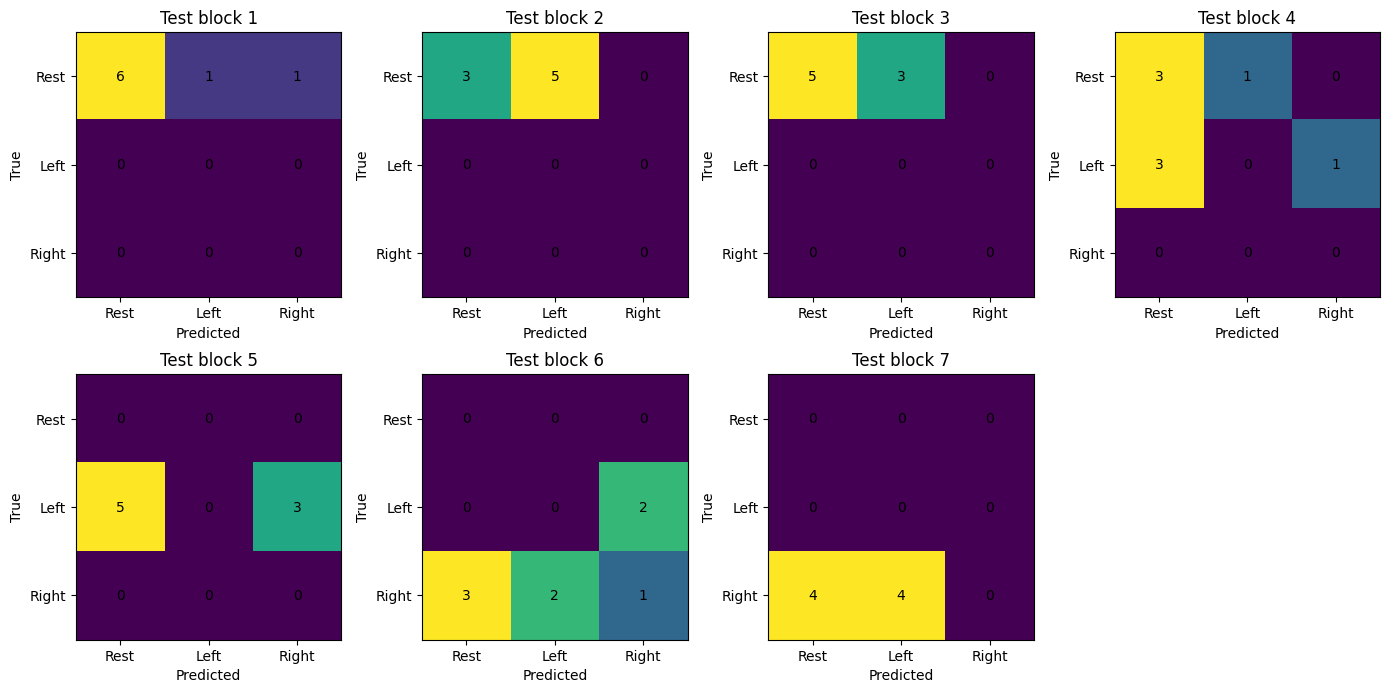


===== CLASS RECALL BY BLOCK =====


/tmp/ipykernel_5720/1869463723.py:84: RuntimeWarning: invalid value encountered in divide
  class_recall = np.diag(cm) / cm.sum(axis=1)


,block,Rest,Left MI,Right MI
0,1,0.750,NaN,NaN
1,2,0.375,NaN,NaN
2,3,0.625,NaN,NaN
3,4,0.750,0.0,NaN
4,5,NaN,0.0,NaN
5,6,NaN,0.0,0.167
6,7,NaN,NaN,0.000


In [49]:
# ============================================================
# CONFUSION MATRICES: FILTER-BANK CSP + LDA
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

class_names = {
    1: "Rest",
    2: "Left MI",
    3: "Right MI"
}

# ------------------------------------------------------------
# Перерисовываем confusion matrices, которые уже сохранили
# в переменной confusions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

axes = axes.ravel()

for i, (block, cm) in enumerate(
    zip(blocks_unique, confusions)
):

    ax = axes[i]

    im = ax.imshow(cm)

    # Значения внутри ячеек
    for row in range(3):
        for col in range(3):
            ax.text(
                col,
                row,
                cm[row, col],
                ha="center",
                va="center"
            )

    ax.set_title(f"Test block {block}")

    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])

    ax.set_xticklabels([
        "Rest",
        "Left",
        "Right"
    ])

    ax.set_yticklabels([
        "Rest",
        "Left",
        "Right"
    ])

    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

# Последний subplot оставляем пустым
axes[-1].axis("off")

plt.tight_layout()
plt.savefig('confusion_matrix')
plt.show()


# ------------------------------------------------------------
# Дополнительно: recall каждого класса по блокам
# ------------------------------------------------------------

print("\n===== CLASS RECALL BY BLOCK =====")

recall_rows = []

for block, cm in zip(blocks_unique, confusions):

    # recall = TP / количество истинных объектов класса
    class_recall = np.diag(cm) / cm.sum(axis=1)

    recall_rows.append({
        "block": block,
        "Rest": class_recall[0],
        "Left MI": class_recall[1],
        "Right MI": class_recall[2]
    })

recall_df = pd.DataFrame(recall_rows)

display(
    recall_df.round(3)
)

In [50]:
# ============================================================
# FILTER-BANK CSP (2 components per band) + LOBO
# ============================================================

n_components = 2

results_2csp = []
confusions_2csp = []

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    y_train = y[train_mask]
    y_test = y[test_mask]

    train_features = []
    test_features = []

    # --------------------------------------------------------
    # CSP отдельно для каждой частотной полосы
    # --------------------------------------------------------
    for band_name in bands:

        X_train = X_band_dict[band_name][train_mask]
        X_test = X_band_dict[band_name][test_mask]

        csp = CSP(
            n_components=n_components,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False,
        )

        X_train_csp = csp.fit_transform(
            X_train,
            y_train
        )

        X_test_csp = csp.transform(
            X_test
        )

        train_features.append(X_train_csp)
        test_features.append(X_test_csp)

    # --------------------------------------------------------
    # 5 полос × 2 CSP = 10 признаков
    # --------------------------------------------------------
    X_train_features = np.concatenate(
        train_features,
        axis=1
    )

    X_test_features = np.concatenate(
        test_features,
        axis=1
    )

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_features,
        y_train
    )

    y_pred = lda.predict(
        X_test_features
    )

    # --------------------------------------------------------
    # Метрики
    # --------------------------------------------------------
    acc = accuracy_score(y_test, y_pred)

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    results_2csp.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    confusions_2csp.append(cm)

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )


# ------------------------------------------------------------
# Итог
# ------------------------------------------------------------

results_2csp_df = pd.DataFrame(results_2csp)

print("\n===== FILTER-BANK 2-CSP + LDA =====")
display(
    results_2csp_df.round(3)
)

print("\n===== MEAN ± STD =====")
display(
    results_2csp_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 4.8e+06 (2.2e-16 eps * 17 dim * 1.3e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 17 dim * 1e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 compute

,test_block,accuracy,macro_recall,macro_f1
0,1,0.875,0.292,0.311
1,2,0.500,0.167,0.222
2,3,0.875,0.292,0.311
3,4,0.500,0.333,0.222
4,5,0.000,0.000,0.000
5,6,0.000,0.000,0.000
6,7,0.000,0.000,0.000



===== MEAN ± STD =====


,accuracy,macro_recall,macro_f1
mean,0.393,0.155,0.152
std,0.398,0.153,0.147


In [51]:
# ============================================================
# FILTER-BANK 2-CSP + TRAIN-ONLY STANDARDIZATION + LOBO
# ============================================================

from sklearn.preprocessing import StandardScaler

n_components = 2

results_norm = []
confusions_norm = []

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    y_train = y[train_mask]
    y_test = y[test_mask]

    train_features = []
    test_features = []

    # --------------------------------------------------------
    # 1. CSP по каждой частотной полосе
    # --------------------------------------------------------

    for band_name in bands:

        X_train = X_band_dict[band_name][train_mask]
        X_test = X_band_dict[band_name][test_mask]

        csp = CSP(
            n_components=n_components,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False
        )

        X_train_csp = csp.fit_transform(
            X_train,
            y_train
        )

        X_test_csp = csp.transform(
            X_test
        )

        train_features.append(X_train_csp)
        test_features.append(X_test_csp)

    # --------------------------------------------------------
    # 2. Объединяем 5 полос × 2 CSP = 10 признаков
    # --------------------------------------------------------

    X_train_features = np.concatenate(
        train_features,
        axis=1
    )

    X_test_features = np.concatenate(
        test_features,
        axis=1
    )

    # --------------------------------------------------------
    # 3. НОРМАЛИЗАЦИЯ
    #
    # scaler видит ТОЛЬКО train block'и.
    # Test block вообще не участвует в расчёте mean/std.
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_features
    )

    X_test_scaled = scaler.transform(
        X_test_features
    )

    # --------------------------------------------------------
    # 4. LDA
    # --------------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    y_pred = lda.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # 5. Метрики
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    results_norm.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    confusions_norm.append(cm)

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )


# ------------------------------------------------------------
# 6. Итог
# ------------------------------------------------------------

results_norm_df = pd.DataFrame(results_norm)

print("\n===== FILTER-BANK 2-CSP + STANDARDIZATION + LDA =====")
display(
    results_norm_df.round(3)
)

print("\n===== MEAN ± STD =====")
display(
    results_norm_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Computing rank from data with rank=None
    Using tolerance 5.9e+06 (2.2e-16 eps * 17 dim * 1.6e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 4.8e+06 (2.2e-16 eps * 17 dim * 1.3e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 17 dim * 1e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 compute

,test_block,accuracy,macro_recall,macro_f1
0,1,0.875,0.292,0.311
1,2,0.500,0.167,0.222
2,3,0.875,0.292,0.311
3,4,0.500,0.333,0.222
4,5,0.000,0.000,0.000
5,6,0.000,0.000,0.000
6,7,0.000,0.000,0.000



===== MEAN ± STD =====


,accuracy,macro_recall,macro_f1
mean,0.393,0.155,0.152
std,0.398,0.153,0.147


In [52]:
# ============================================================
# ПРОВЕРКА КЛАССОВ В КАЖДОМ БЛОКЕ
# ============================================================

block_class_counts = pd.crosstab(
    trial_blocks,
    y
)

block_class_counts.columns = [
    "Rest",
    "Left MI",
    "Right MI"
]

print("Количество trials каждого класса в каждом блоке:")
display(block_class_counts)

print("\nТолько блоки, где присутствуют все 3 класса:")

valid_blocks = block_class_counts[
    (block_class_counts > 0).all(axis=1)
].index.to_numpy()

print(valid_blocks)

Количество trials каждого класса в каждом блоке:


,Rest,Left MI,Right MI
row_0,,,
1,8,0,0
2,8,0,0
3,8,0,0
4,4,4,0
5,0,8,0
6,0,2,6
7,0,0,8



Только блоки, где присутствуют все 3 класса:
[]


Computing rank from data with rank=None
    Using tolerance 6.3e+06 (2.2e-16 eps * 17 dim * 1.7e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 5e+06 (2.2e-16 eps * 17 dim * 1.3e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 4e+06 (2.2e-16 eps * 17 dim * 1.1e+21  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed 

,8-12_CSP1,8-12_CSP2,12-16_CSP1,12-16_CSP2,16-20_CSP1,16-20_CSP2,20-24_CSP1,20-24_CSP2,24-30_CSP1,24-30_CSP2
block,,,,,,,,,,
1,-2.484,-2.693,-2.546,-3.163,-2.633,-3.044,-2.584,-2.991,-3.049,-2.363
2,-1.517,-2.923,-1.539,-2.850,-1.727,-3.115,-1.654,-3.033,-3.074,-2.282
3,-0.757,-2.996,-1.057,-2.763,-0.908,-2.844,-0.968,-2.884,-2.805,-2.213
4,-1.482,-2.928,-1.739,-2.938,-1.808,-2.882,-1.874,-2.881,-2.685,-2.188
5,-0.617,-2.954,-0.664,-2.945,-0.770,-2.938,-0.714,-3.230,-2.732,-2.275
6,-1.057,-2.847,-1.177,-2.927,-1.044,-2.850,-1.060,-3.112,-2.602,-2.197
7,-0.088,-2.903,-0.362,-2.899,-0.244,-2.812,-0.166,-3.081,-2.315,-2.295


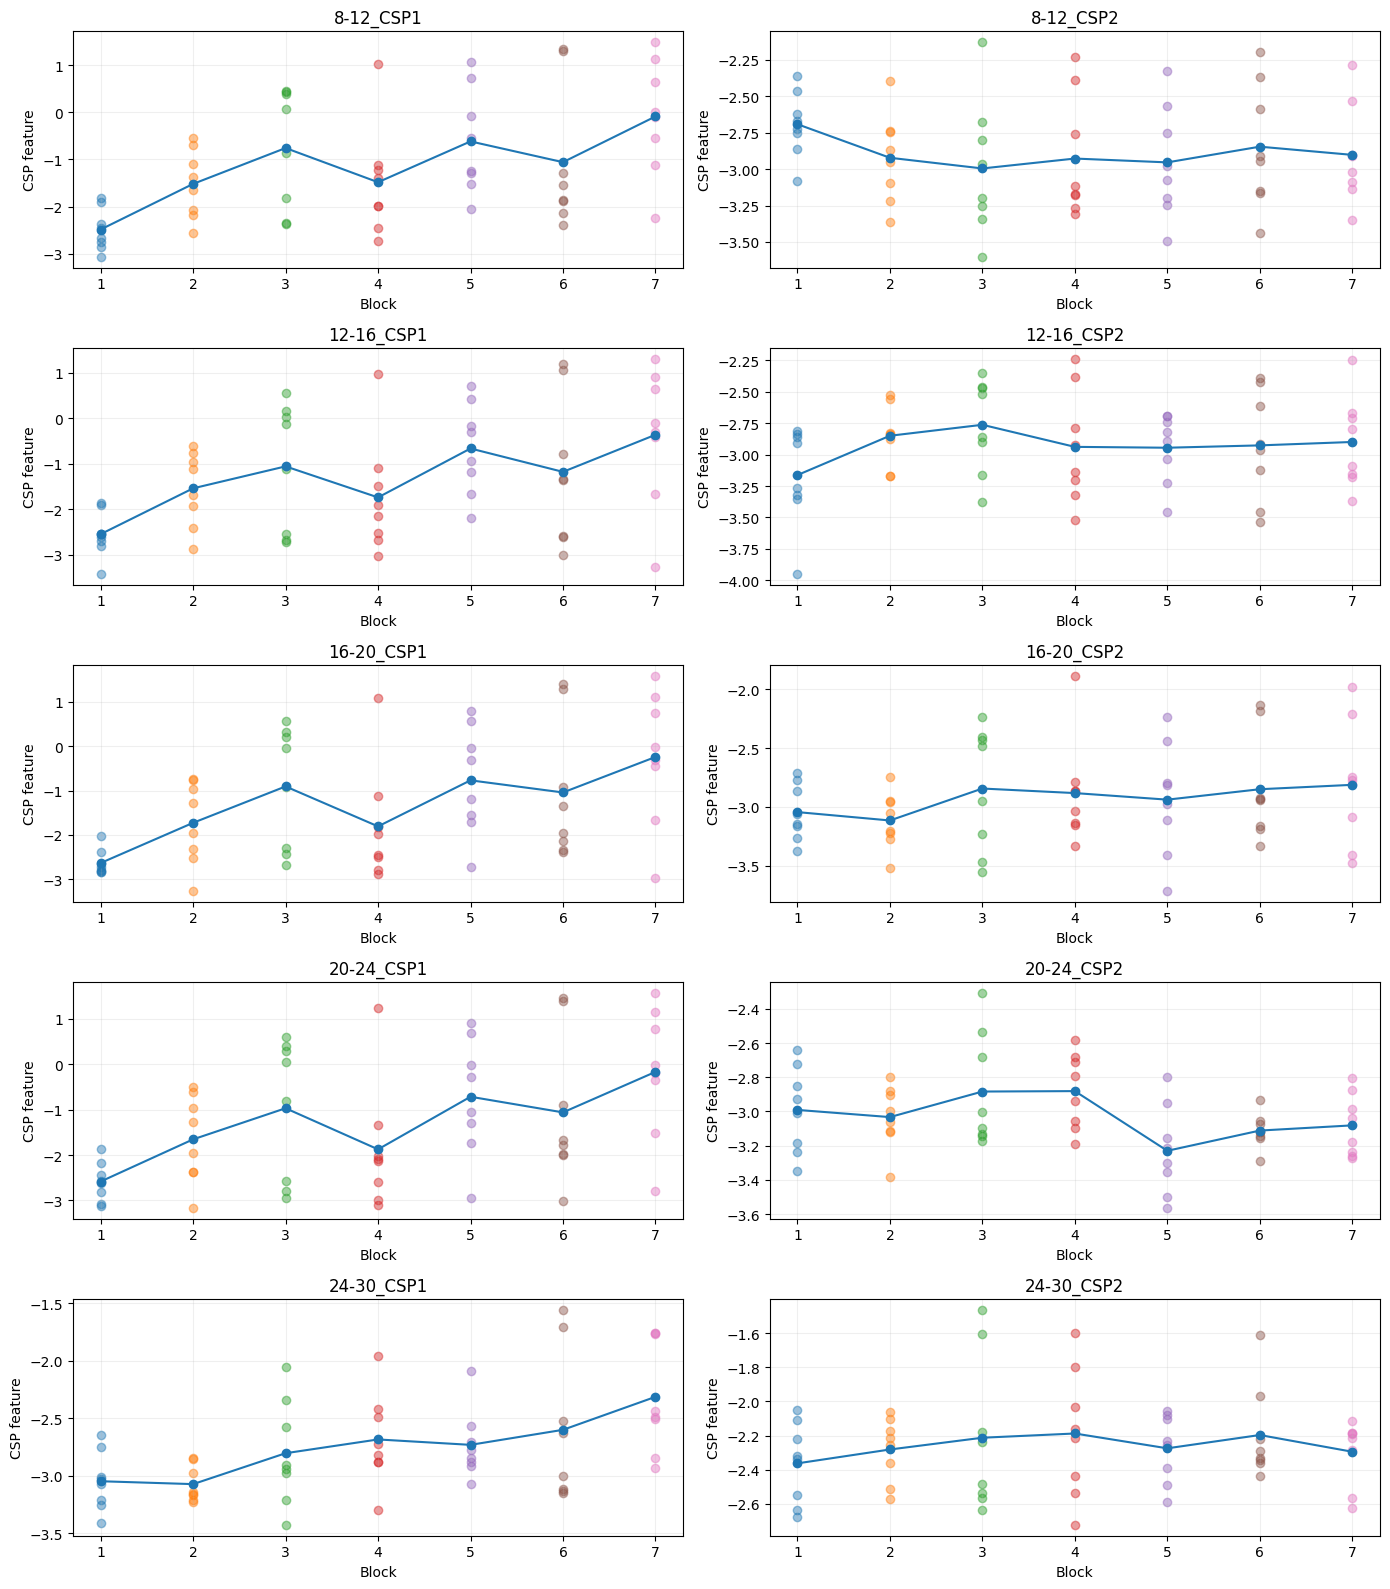

In [53]:
# ============================================================
# DRIFT OF FILTER-BANK CSP FEATURES ACROSS BLOCKS
# 5 bands × 2 CSP components = 10 features
# ============================================================

# Получаем CSP-признаки для ВСЕХ trials.
# Важно: для диагностики используем один CSP,
# обученный на всей сессии. Это не оценка качества модели,
# а визуализация структуры признаков.

all_features = []

for band_name in bands:

    X_band = X_band_dict[band_name]

    csp = CSP(
        n_components=2,
        reg="ledoit_wolf",
        log=True,
        norm_trace=False
    )

    features = csp.fit_transform(
        X_band,
        y
    )

    all_features.append(features)


# 56 trials × 10 features
X_features_all = np.concatenate(
    all_features,
    axis=1
)

print("Feature matrix:", X_features_all.shape)


# ------------------------------------------------------------
# Создаём таблицу признаков
# ------------------------------------------------------------

feature_names = []

for band_name in bands:
    feature_names.extend([
        f"{band_name}_CSP1",
        f"{band_name}_CSP2"
    ])

features_df = pd.DataFrame(
    X_features_all,
    columns=feature_names
)

features_df["block"] = trial_blocks
features_df["state"] = y


# ------------------------------------------------------------
# Среднее значение признаков по блокам
# ------------------------------------------------------------

block_means = (
    features_df
    .groupby("block")[feature_names]
    .mean()
)

print("\nСредние CSP-признаки по блокам:")
display(
    block_means.round(3)
)


# ------------------------------------------------------------
# Визуализация drift
# ------------------------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 16)
)

axes = axes.ravel()

for i, feature in enumerate(feature_names):

    ax = axes[i]

    # все trial points
    for block in blocks_unique:

        values = features_df.loc[
            features_df["block"] == block,
            feature
        ]

        x = np.full(
            len(values),
            block
        )

        ax.scatter(
            x,
            values,
            alpha=0.45
        )

    # среднее по блоку
    means = block_means[feature]

    ax.plot(
        blocks_unique,
        means.loc[blocks_unique],
        marker="o"
    )

    ax.set_title(feature)
    ax.set_xlabel("Block")
    ax.set_ylabel("CSP feature")

    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Средние стандартизированные CSP-признаки по блокам:


,8-12_CSP1,8-12_CSP2,12-16_CSP1,12-16_CSP2,16-20_CSP1,16-20_CSP2,20-24_CSP1,20-24_CSP2,24-30_CSP1,24-30_CSP2
block,,,,,,,,,,
1,-1.063,0.550,-0.946,-0.651,-0.968,-0.283,-0.907,0.161,-0.651,-0.376
2,-0.297,-0.085,-0.183,0.211,-0.308,-0.454,-0.256,-0.011,-0.706,-0.083
3,0.306,-0.287,0.183,0.451,0.289,0.199,0.225,0.603,-0.117,0.166
4,-0.268,-0.100,-0.334,-0.033,-0.367,0.106,-0.410,0.614,0.145,0.256
5,0.417,-0.173,0.481,-0.052,0.390,-0.028,0.402,-0.821,0.042,-0.058
6,0.068,0.125,0.091,-0.000,0.190,0.185,0.160,-0.335,0.329,0.224
7,0.836,-0.030,0.709,0.074,0.773,0.275,0.786,-0.210,0.958,-0.130



Наибольший остаточный drift после стандартизации:


,feature,block1_mean,block7_mean,abs_change
0,8-12_CSP1,-1.063,0.836,1.899
4,16-20_CSP1,-0.968,0.773,1.741
6,20-24_CSP1,-0.907,0.786,1.693
2,12-16_CSP1,-0.946,0.709,1.655
8,24-30_CSP1,-0.651,0.958,1.609
3,12-16_CSP2,-0.651,0.074,0.726
1,8-12_CSP2,0.550,-0.030,0.581
5,16-20_CSP2,-0.283,0.275,0.558
7,20-24_CSP2,0.161,-0.210,0.372
9,24-30_CSP2,-0.376,-0.130,0.246


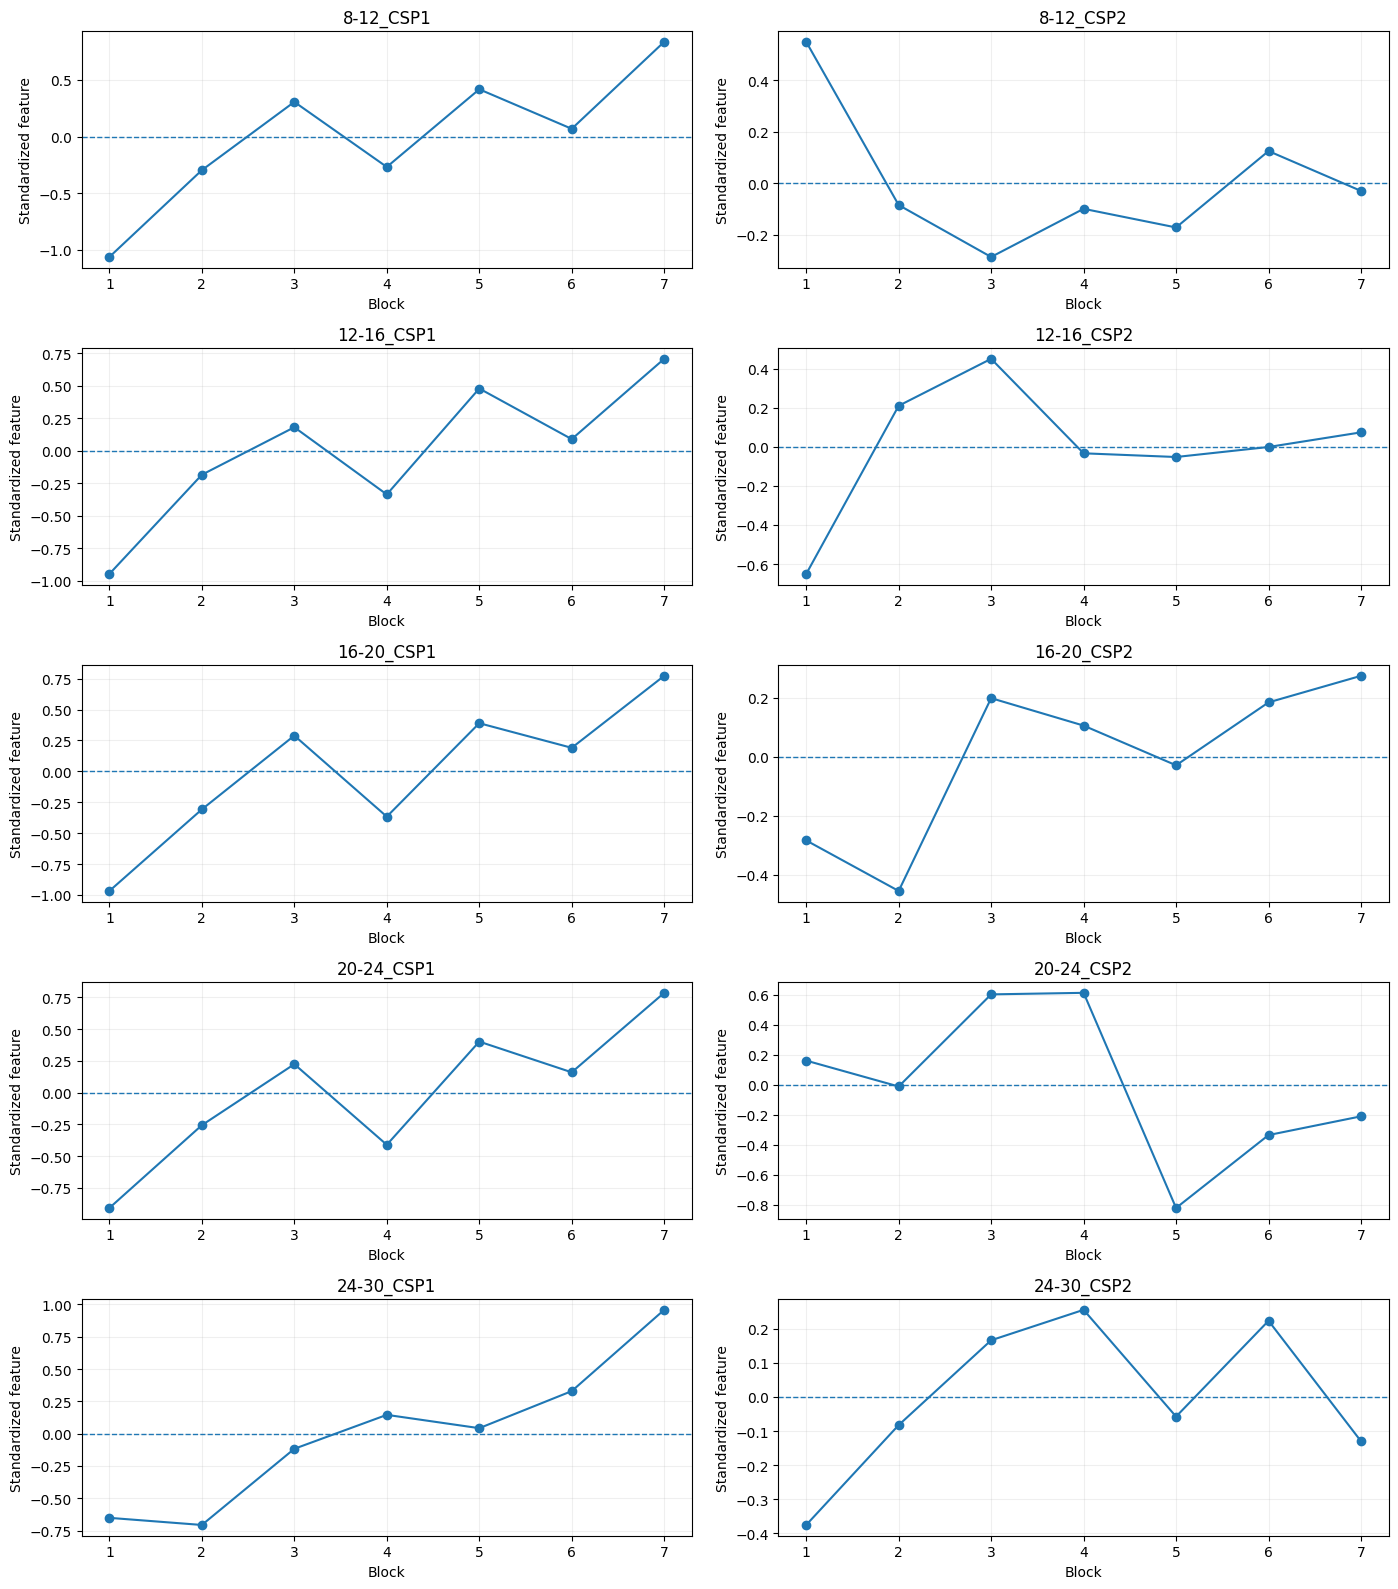

In [54]:
# ============================================================
# DRIFT AFTER STANDARDIZATION OF CSP FEATURES
# Диагностический эксперимент
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Стандартизируем каждый CSP-признак по всей сессии
# ------------------------------------------------------------

scaler_diag = StandardScaler()

X_features_scaled = scaler_diag.fit_transform(
    X_features_all
)

scaled_df = pd.DataFrame(
    X_features_scaled,
    columns=feature_names
)

scaled_df["block"] = trial_blocks
scaled_df["state"] = y


# ------------------------------------------------------------
# 2. Средние стандартизированные значения по блокам
# ------------------------------------------------------------

scaled_block_means = (
    scaled_df
    .groupby("block")[feature_names]
    .mean()
)

print("Средние стандартизированные CSP-признаки по блокам:")
display(
    scaled_block_means.round(3)
)


# ------------------------------------------------------------
# 3. Насколько сильно каждый признак меняется между блоками
# ------------------------------------------------------------

drift_summary = pd.DataFrame({
    "feature": feature_names,
    "block1_mean": scaled_block_means.loc[1].values,
    "block7_mean": scaled_block_means.loc[7].values,
})

drift_summary["abs_change"] = (
    drift_summary["block7_mean"]
    - drift_summary["block1_mean"]
).abs()

drift_summary = drift_summary.sort_values(
    "abs_change",
    ascending=False
)

print("\nНаибольший остаточный drift после стандартизации:")
display(
    drift_summary.round(3)
)


# ------------------------------------------------------------
# 4. Графики
# ------------------------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 16)
)

axes = axes.ravel()

for i, feature in enumerate(feature_names):

    ax = axes[i]

    means = scaled_block_means[feature]

    ax.plot(
        blocks_unique,
        means.loc[blocks_unique],
        marker="o"
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(feature)
    ax.set_xlabel("Block")
    ax.set_ylabel("Standardized feature")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [55]:
# ============================================================
# BAND-POWER FEATURES + LDA + LOBO
# Без CSP
# ============================================================

from scipy.signal import butter, sosfiltfilt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Частотные полосы
# ------------------------------------------------------------

bands_power = {
    "8-12": (8, 12),
    "12-16": (12, 16),
    "16-20": (16, 20),
    "20-24": (20, 24),
    "24-30": (24, 30),
}

# ------------------------------------------------------------
# 2. Получаем log-band-power для каждого trial
#
# X: trials × samples × channels
# Результат каждой полосы:
# trials × channels
# ------------------------------------------------------------

power_features = []

for band_name, (low, high) in bands_power.items():

    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    X_filtered = sosfiltfilt(
        sos,
        X,
        axis=1
    )

    # Средняя мощность по времени
    power = np.mean(
        X_filtered ** 2,
        axis=1
    )

    # Логарифмируем для стабилизации масштаба
    log_power = np.log(
        power + 1e-12
    )

    power_features.append(
        log_power
    )

# ------------------------------------------------------------
# 3. Объединяем:
#
# 5 полос × 17 хороших каналов = 85 признаков
# ------------------------------------------------------------

X_power = np.concatenate(
    power_features,
    axis=1
)

print("Power feature matrix:", X_power.shape)


# ------------------------------------------------------------
# 4. LOBO
# ------------------------------------------------------------

power_results = []
power_confusions = []

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    X_train = X_power[train_mask]
    X_test = X_power[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    # --------------------------------------------------------
    # Нормализация ТОЛЬКО по train
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    y_pred = lda.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # Метрики
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    power_results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    power_confusions.append(cm)

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )


# ------------------------------------------------------------
# 5. Итог
# ------------------------------------------------------------

power_results_df = pd.DataFrame(
    power_results
)

print("\n===== BAND-POWER + LDA =====")

display(
    power_results_df.round(3)
)

print("\n===== MEAN ± STD =====")

display(
    power_results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Power feature matrix: (56, 85)
Block 1: accuracy=0.625, macro_recall=0.208, macro_f1=0.256
Block 2: accuracy=0.375, macro_recall=0.125, macro_f1=0.182
Block 3: accuracy=0.875, macro_recall=0.292, macro_f1=0.311
Block 4: accuracy=0.375, macro_recall=0.250, macro_f1=0.222
Block 5: accuracy=0.250, macro_recall=0.083, macro_f1=0.133
Block 6: accuracy=0.125, macro_recall=0.056, macro_f1=0.074
Block 7: accuracy=0.125, macro_recall=0.042, macro_f1=0.074

===== BAND-POWER + LDA =====


,test_block,accuracy,macro_recall,macro_f1
0,1,0.625,0.208,0.256
1,2,0.375,0.125,0.182
2,3,0.875,0.292,0.311
3,4,0.375,0.250,0.222
4,5,0.250,0.083,0.133
5,6,0.125,0.056,0.074
6,7,0.125,0.042,0.074



===== MEAN ± STD =====


,accuracy,macro_recall,macro_f1
mean,0.393,0.151,0.179
std,0.274,0.099,0.091


In [56]:
# ============================================================
# C3/C4 BAND-POWER + LDA + LOBO
# ============================================================

# Индексы C3 и C4 среди исходных 21 каналов
c3_idx = eeg_labels.index("C3")
c4_idx = eeg_labels.index("C4")

motor_idx = [c3_idx, c4_idx]

print("Motor channels:", [eeg_labels[i] for i in motor_idx])

# ------------------------------------------------------------
# 1. Считаем band-power только для C3 и C4
# ------------------------------------------------------------

motor_features = []

for band_name, (low, high) in bands_power.items():

    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    # X содержит все 17 хороших каналов.
    # Берём только C3/C4 из исходного trial_data.
    X_motor = X[:, :, [good_idx.index(c3_idx), good_idx.index(c4_idx)]]

    X_filtered = sosfiltfilt(
        sos,
        X_motor,
        axis=1
    )

    # Средняя мощность по времени
    power = np.mean(
        X_filtered ** 2,
        axis=1
    )

    # Log-power
    log_power = np.log(
        power + 1e-12
    )

    motor_features.append(log_power)


# ------------------------------------------------------------
# 2. 5 полос × 2 канала = 10 признаков
# ------------------------------------------------------------

X_motor_power = np.concatenate(
    motor_features,
    axis=1
)

print("Feature matrix:", X_motor_power.shape)


# ------------------------------------------------------------
# 3. LOBO
# ------------------------------------------------------------

motor_results = []

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    X_train = X_motor_power[train_mask]
    X_test = X_motor_power[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    # Нормализация только по train
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Shrinkage LDA
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    y_pred = lda.predict(X_test_scaled)

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    motor_results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )


# ------------------------------------------------------------
# 4. Итог
# ------------------------------------------------------------

motor_results_df = pd.DataFrame(
    motor_results
)

print("\n===== C3/C4 BAND-POWER + LDA =====")

display(
    motor_results_df.round(3)
)

print("\n===== MEAN ± STD =====")

display(
    motor_results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Motor channels: ['C3', 'C4']
Feature matrix: (56, 10)
Block 1: accuracy=0.500, macro_recall=0.167, macro_f1=0.222
Block 2: accuracy=0.625, macro_recall=0.208, macro_f1=0.256
Block 3: accuracy=0.625, macro_recall=0.208, macro_f1=0.256
Block 4: accuracy=0.500, macro_recall=0.333, macro_f1=0.333
Block 5: accuracy=0.250, macro_recall=0.083, macro_f1=0.133
Block 6: accuracy=0.125, macro_recall=0.167, macro_f1=0.133
Block 7: accuracy=0.000, macro_recall=0.000, macro_f1=0.000

===== C3/C4 BAND-POWER + LDA =====


,test_block,accuracy,macro_recall,macro_f1
0,1,0.500,0.167,0.222
1,2,0.625,0.208,0.256
2,3,0.625,0.208,0.256
3,4,0.500,0.333,0.333
4,5,0.250,0.083,0.133
5,6,0.125,0.167,0.133
6,7,0.000,0.000,0.000



===== MEAN ± STD =====


,accuracy,macro_recall,macro_f1
mean,0.375,0.167,0.191
std,0.250,0.105,0.110


In [57]:
# ============================================================
# RELATIVE BAND-POWER + LDA + LOBO
#
# Для каждого trial/channel:
#   power_band / total_power_8_30
#
# 5 bands × 17 channels = 85 features
# ============================================================

relative_features = []

# ------------------------------------------------------------
# 1. Сначала считаем общую мощность 8–30 Hz
# ------------------------------------------------------------

sos_total = butter(
    4,
    [8, 30],
    btype="bandpass",
    fs=fs,
    output="sos"
)

X_total_filtered = sosfiltfilt(
    sos_total,
    X,
    axis=1
)

total_power = np.mean(
    X_total_filtered ** 2,
    axis=1
)

# ------------------------------------------------------------
# 2. Для каждой полосы считаем относительную мощность
# ------------------------------------------------------------

for band_name, (low, high) in bands_power.items():

    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    X_filtered = sosfiltfilt(
        sos,
        X,
        axis=1
    )

    band_power = np.mean(
        X_filtered ** 2,
        axis=1
    )

    # Относительная мощность
    relative_power = (
        band_power /
        (total_power + 1e-12)
    )

    # log(relative power)
    log_relative_power = np.log(
        relative_power + 1e-12
    )

    relative_features.append(
        log_relative_power
    )

# ------------------------------------------------------------
# 3. Объединяем признаки
# ------------------------------------------------------------

X_relative = np.concatenate(
    relative_features,
    axis=1
)

print(
    "Relative band-power feature matrix:",
    X_relative.shape
)

# ------------------------------------------------------------
# 4. LOBO
# ------------------------------------------------------------

relative_results = []

for test_block in blocks_unique:

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    X_train = X_relative[train_mask]
    X_test = X_relative[test_mask]

    y_train = y[train_mask]
    y_test = y[test_mask]

    # Нормализация только по train
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # Shrinkage LDA
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    y_pred = lda.predict(
        X_test_scaled
    )

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    relative_results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    print(
        f"Block {test_block}: "
        f"accuracy={acc:.3f}, "
        f"macro_recall={macro_recall:.3f}, "
        f"macro_f1={macro_f1:.3f}"
    )

# ------------------------------------------------------------
# 5. Итог
# ------------------------------------------------------------

relative_results_df = pd.DataFrame(
    relative_results
)

print("\n===== RELATIVE BAND-POWER + LDA =====")

display(
    relative_results_df.round(3)
)

print("\n===== MEAN ± STD =====")

display(
    relative_results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].agg(["mean", "std"]).round(3)
)

Relative band-power feature matrix: (56, 85)
Block 1: accuracy=0.750, macro_recall=0.250, macro_f1=0.286
Block 2: accuracy=0.250, macro_recall=0.083, macro_f1=0.133
Block 3: accuracy=0.500, macro_recall=0.167, macro_f1=0.222
Block 4: accuracy=0.375, macro_recall=0.250, macro_f1=0.302
Block 5: accuracy=0.125, macro_recall=0.042, macro_f1=0.074
Block 6: accuracy=0.250, macro_recall=0.222, macro_f1=0.250
Block 7: accuracy=0.125, macro_recall=0.042, macro_f1=0.074

===== RELATIVE BAND-POWER + LDA =====


,test_block,accuracy,macro_recall,macro_f1
0,1,0.750,0.250,0.286
1,2,0.250,0.083,0.133
2,3,0.500,0.167,0.222
3,4,0.375,0.250,0.302
4,5,0.125,0.042,0.074
5,6,0.250,0.222,0.250
6,7,0.125,0.042,0.074



===== MEAN ± STD =====


,accuracy,macro_recall,macro_f1
mean,0.339,0.151,0.192
std,0.225,0.094,0.097


In [58]:
# ============================================================
# BLOCK-TO-BLOCK DRIFT OF BAND-POWER
#
# Для каждой полосы:
#   1. берём log band-power
#   2. усредняем по trial и каналам внутри блока
#   3. считаем изменение между соседними блоками
#
# Это только диагностика, не модель.
# ============================================================

# Сначала сохраним log-power отдельно по каждой полосе
bandpower_by_band = {}

for band_name, (low, high) in bands_power.items():

    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    X_filtered = sosfiltfilt(
        sos,
        X,
        axis=1
    )

    power = np.mean(
        X_filtered ** 2,
        axis=1
    )

    log_power = np.log(
        power + 1e-12
    )

    # shape = trials × channels
    bandpower_by_band[band_name] = log_power


# ------------------------------------------------------------
# Считаем среднее значение по каждому блоку
# ------------------------------------------------------------

drift_rows = []

for band_name, features in bandpower_by_band.items():

    block_means = []

    for block in blocks_unique:

        mask = trial_blocks == block

        # Среднее по trial и каналам
        mean_value = features[mask].mean()

        block_means.append(mean_value)

    block_means = np.asarray(block_means)

    # --------------------------------------------------------
    # Изменение между соседними блоками
    # --------------------------------------------------------

    changes = np.diff(block_means)

    # Абсолютное изменение
    abs_changes = np.abs(changes)

    for i, change in enumerate(abs_changes):

        drift_rows.append({
            "band": band_name,
            "from_block": blocks_unique[i],
            "to_block": blocks_unique[i + 1],
            "abs_change": change
        })


drift_df = pd.DataFrame(drift_rows)

print("===== BLOCK-TO-BLOCK DRIFT =====")

display(
    drift_df.round(3)
)


# ------------------------------------------------------------
# Суммарный drift по каждой полосе
# ------------------------------------------------------------

drift_summary = (
    drift_df
    .groupby("band")["abs_change"]
    .agg(["mean", "sum", "max"])
    .sort_values("sum", ascending=False)
)

print("\n===== DRIFT SUMMARY =====")

display(
    drift_summary.round(3)
)

===== BLOCK-TO-BLOCK DRIFT =====


,band,from_block,to_block,abs_change
0,8-12,1,2,0.057
1,8-12,2,3,0.063
2,8-12,3,4,0.006
3,8-12,4,5,0.066
4,8-12,5,6,0.223
5,8-12,6,7,0.154
6,12-16,1,2,0.097
7,12-16,2,3,0.138
8,12-16,3,4,0.083
9,12-16,4,5,0.255



===== DRIFT SUMMARY =====


,mean,sum,max
band,,,
12-16,0.192,1.153,0.315
16-20,0.174,1.043,0.324
20-24,0.169,1.015,0.273
8-12,0.095,0.569,0.223
24-30,0.072,0.432,0.159


In [59]:
block_state_power = []

for band_name, features in bandpower_by_band.items():

    for block in blocks_unique:

        for state in [1, 2, 3]:

            mask = (
                (trial_blocks == block) &
                (y == state)
            )

            n = mask.sum()

            if n == 0:
                continue

            values = features[mask]

            block_state_power.append({
                "block": block,
                "state": state,
                "band": band_name,
                "n_trials": n,
                "mean_log_power": values.mean(),
                "std_log_power": values.std()
            })

block_state_power_df = pd.DataFrame(
    block_state_power
)

print("===== BLOCK × STATE × BAND =====")

display(
    block_state_power_df.round(3)
)

===== BLOCK × STATE × BAND =====


,block,state,band,n_trials,mean_log_power,std_log_power
0,1,1,8-12,8,25.614,2.235
1,2,1,8-12,8,25.671,2.321
2,3,1,8-12,8,25.607,2.273
3,4,1,8-12,4,25.785,2.326
4,4,2,8-12,4,25.441,2.257
5,5,2,8-12,8,25.679,2.501
6,6,2,8-12,2,25.796,2.731
7,6,3,8-12,6,25.937,2.506
8,7,3,8-12,8,25.747,2.537
9,1,1,12-16,8,24.913,2.418


In [60]:
# ============================================================
# BLOCK 6: LEFT MI vs RIGHT MI
# Leave-One-Trial-Out
#
# Только Block 6:
#   Left  = class 2, n=2
#   Right = class 3, n=6
#
# Features:
#   C3/C4 × 5 frequency bands = 10
# ============================================================

from sklearn.model_selection import LeaveOneOut

# ------------------------------------------------------------
# 1. Выбираем только Block 6 и классы Left/Right
# ------------------------------------------------------------

mask_block6 = (
    (trial_blocks == 6) &
    np.isin(y, [2, 3])
)

X_b6 = X_motor_power[mask_block6]
y_b6 = y[mask_block6]

print("Block 6 feature matrix:", X_b6.shape)
print("Class counts:")
print(pd.Series(y_b6).value_counts().sort_index())


# ------------------------------------------------------------
# 2. Leave-One-Trial-Out
# ------------------------------------------------------------

loo = LeaveOneOut()

predictions = []
true_labels = []

for train_idx, test_idx in loo.split(X_b6):

    X_train = X_b6[train_idx]
    X_test = X_b6[test_idx]

    y_train = y_b6[train_idx]
    y_test = y_b6[test_idx]

    # --------------------------------------------------------
    # Scaling только по train
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    pred = lda.predict(
        X_test_scaled
    )[0]

    predictions.append(pred)
    true_labels.append(y_test[0])


# ------------------------------------------------------------
# 3. Метрики
# ------------------------------------------------------------

predictions = np.asarray(predictions)
true_labels = np.asarray(true_labels)

accuracy_b6 = accuracy_score(
    true_labels,
    predictions
)

macro_recall_b6 = recall_score(
    true_labels,
    predictions,
    labels=[2, 3],
    average="macro",
    zero_division=0
)

macro_f1_b6 = f1_score(
    true_labels,
    predictions,
    labels=[2, 3],
    average="macro",
    zero_division=0
)

cm_b6 = confusion_matrix(
    true_labels,
    predictions,
    labels=[2, 3]
)

print("\n===== BLOCK 6: LEFT vs RIGHT =====")

print(f"Accuracy:      {accuracy_b6:.3f}")
print(f"Macro recall:  {macro_recall_b6:.3f}")
print(f"Macro F1:      {macro_f1_b6:.3f}")

print("\nConfusion matrix:")
print(
    pd.DataFrame(
        cm_b6,
        index=["True Left", "True Right"],
        columns=["Pred Left", "Pred Right"]
    )
)

Block 6 feature matrix: (8, 10)
Class counts:
2    2
3    6
dtype: int64

===== BLOCK 6: LEFT vs RIGHT =====
Accuracy:      0.750
Macro recall:  0.500
Macro F1:      0.429

Confusion matrix:
            Pred Left  Pred Right
True Left           0           2
True Right          0           6


/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_shrunk_covariance.py:290: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_empirical_covariance.py:86: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_shrunk_covariance.py:290: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_empirical_covariance.py:86: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(


In [61]:
# ============================================================
# TRIAL-LEVEL C3/C4 ANALYSIS
# Relative mu (8–12 Hz) and beta (13–30 Hz) power
# ============================================================

from scipy.signal import welch

# ------------------------------------------------------------
# Параметры
# ------------------------------------------------------------

bands = {
    "mu": (8, 12),
    "beta": (13, 30),
}

# Индексы C3 и C4
c3_idx = eeg_labels.index("C3")
c4_idx = eeg_labels.index("C4")

# ------------------------------------------------------------
# Функция relative band power
# ------------------------------------------------------------

def relative_band_power(signal, fs, band, total_band=(4, 35)):
    freqs, psd = welch(
        signal,
        fs=fs,
        nperseg=min(512, len(signal)),
        noverlap=min(256, len(signal) // 2),
    )

    band_mask = (
        (freqs >= band[0]) &
        (freqs <= band[1])
    )

    total_mask = (
        (freqs >= total_band[0]) &
        (freqs <= total_band[1])
    )

    band_power = np.trapz(
        psd[band_mask],
        freqs[band_mask]
    )

    total_power = np.trapz(
        psd[total_mask],
        freqs[total_mask]
    )

    return band_power / total_power


# ------------------------------------------------------------
# Считаем признаки для каждого trial
# ------------------------------------------------------------

rows = []

for state in [1, 2, 3]:

    for trial_id, trial in enumerate(trial_data[state], start=1):

        c3 = trial[:, c3_idx]
        c4 = trial[:, c4_idx]

        c3_mu = relative_band_power(
            c3, fs, bands["mu"]
        )

        c4_mu = relative_band_power(
            c4, fs, bands["mu"]
        )

        c3_beta = relative_band_power(
            c3, fs, bands["beta"]
        )

        c4_beta = relative_band_power(
            c4, fs, bands["beta"]
        )

        # Log-ratio C3/C4.
        # Добавляем epsilon, чтобы избежать log(0).
        eps = 1e-12

        mu_asym = np.log(
            (c3_mu + eps) /
            (c4_mu + eps)
        )

        beta_asym = np.log(
            (c3_beta + eps) /
            (c4_beta + eps)
        )

        rows.append({
            "state": state,
            "trial": trial_id,

            "C3_mu": c3_mu,
            "C4_mu": c4_mu,

            "C3_beta": c3_beta,
            "C4_beta": c4_beta,

            "mu_C3_C4_logratio": mu_asym,
            "beta_C3_C4_logratio": beta_asym,
        })


trial_features = pd.DataFrame(rows)

# Человекочитаемые названия классов
state_names = {
    1: "Rest",
    2: "Left MI",
    3: "Right MI",
}

trial_features["class"] = (
    trial_features["state"]
    .map(state_names)
)

# Порядок колонок
trial_features = trial_features[
    [
        "class",
        "state",
        "trial",
        "C3_mu",
        "C4_mu",
        "C3_beta",
        "C4_beta",
        "mu_C3_C4_logratio",
        "beta_C3_C4_logratio",
    ]
]

print("Shape:", trial_features.shape)

display(
    trial_features.round(4)
)

Shape: (56, 9)


,class,state,trial,C3_mu,C4_mu,C3_beta,C4_beta,mu_C3_C4_logratio,beta_C3_C4_logratio
0,Rest,1,1,0.3572,0.1971,0.1955,0.2693,0.5943,-0.3201
1,Rest,1,2,0.3282,0.1567,0.2623,0.4447,0.7393,-0.5277
2,Rest,1,3,0.4203,0.5139,0.3114,0.2458,-0.2009,0.2366
3,Rest,1,4,0.4063,0.2003,0.2498,0.3037,0.7073,-0.1953
4,Rest,1,5,0.3821,0.3834,0.2608,0.2122,-0.0036,0.2062
5,Rest,1,6,0.2719,0.2135,0.1762,0.3417,0.2419,-0.6621
6,Rest,1,7,0.2618,0.1682,0.2059,0.3892,0.4426,-0.6366
7,Rest,1,8,0.5155,0.4312,0.1577,0.1742,0.1786,-0.1000
8,Rest,1,9,0.2121,0.3082,0.3335,0.2843,-0.3737,0.1597
9,Rest,1,10,0.3305,0.3917,0.1625,0.2868,-0.1698,-0.5681


In [62]:
# Добавляем номер блока каждому trial
trial_features["block"] = trial_blocks

# Удобный порядок
trial_features = trial_features[
    [
        "block",
        "class",
        "state",
        "trial",
        "C3_mu",
        "C4_mu",
        "C3_beta",
        "C4_beta",
        "mu_C3_C4_logratio",
        "beta_C3_C4_logratio",
    ]
]

# Средние значения по Block × Class
summary_block_state = (
    trial_features
    .groupby(["block", "class"])
    [
        [
            "C3_mu",
            "C4_mu",
            "C3_beta",
            "C4_beta",
            "mu_C3_C4_logratio",
            "beta_C3_C4_logratio",
        ]
    ]
    .agg(["mean", "std", "count"])
    .round(3)
)

display(summary_block_state)

C3_mu               C4_mu              C3_beta               \
                 mean    std count   mean    std count    mean    std count   
block class                                                                   
1     Rest      0.368  0.083     8  0.283  0.138     8   0.227  0.052     8   
2     Rest      0.351  0.107     8  0.298  0.075     8   0.229  0.074     8   
3     Rest      0.397  0.127     8  0.280  0.069     8   0.226  0.059     8   
4     Left MI   0.278  0.161     4  0.372  0.088     4   0.250  0.058     4   
      Rest      0.418  0.126     4  0.345  0.137     4   0.246  0.093     4   
5     Left MI   0.275  0.076     8  0.289  0.073     8   0.272  0.053     8   
6     Left MI   0.250  0.004     2  0.207  0.000     2   0.319  0.039     2   
      Right MI  0.288  0.124     6  0.295  0.115     6   0.236  0.075     6   
7     Right MI  0.304  0.082     8  0.267  0.105     8   0.268  0.053     8   

               C4_beta              mu_C3_C4_logratio               \
                  mean    std count              mean    std count   
block class                                                          
1     Rest       0.298  0.091     8             0.337  0.341     8   
2     Rest       0.273  0.074     8             0.149  0.385     8   
3     Rest       0.331  0.089     8             0.318  0.318     8   
4     Left MI    0.244  0.023     4            -0.409  0.511     4   
      Rest       0.264  0.025     4             0.207  0.313     4   
5     Left MI    0.285  0.064     8            -0.055  0.244     8   
6     Left MI    0.267  0.004     2             0.189  0.017     2   
      Right MI   0.279  0.062     6            -0.041  0.390     6   
7     Right MI   0.350  0.072     8             0.167  0.417     8   

               beta_C3_C4_logratio               
                              mean    std count  
block class                                      
1     Rest                  -0.250  0.353     8  
2     Rest                  -0.196  0.386     8  
3     Rest                  -0.382  0.367     8  
4     Left MI                0.004  0.164     4  
      Rest                  -0.124  0.338     4  
5     Left MI               -0.038  0.226     8  
6     Left MI                0.174  0.105     2  
      Right MI              -0.203  0.298     6  
7     Right MI              -0.264  0.239     8

In [63]:
# ============================================================
# RIEMANNIAN BASELINE — STEP 1
# Covariance matrices for every EEG trial
# ============================================================

from scipy.linalg import eigvalsh

# Используем уже определённые:
# trial_data
# eeg_labels
# good_idx
# fs

# ------------------------------------------------------------
# 1. Параметры
# ------------------------------------------------------------

riem_low = 8
riem_high = 30

sos_riem = butter(
    4,
    [riem_low, riem_high],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# ------------------------------------------------------------
# 2. Собираем все trials
# ------------------------------------------------------------

X_trials = []
y_trials = []
block_trials = []

for state in [1, 2, 3]:

    for trial_id, trial in enumerate(
        trial_data[state],
        start=1
    ):

        # Только 17 хороших каналов
        x = trial[:, good_idx]

        # Offline-фильтрация только для EDA
        # В финальном online pipeline так делать нельзя:
        # sosfiltfilt использует будущее.
        x_filtered = sosfiltfilt(
            sos_riem,
            x,
            axis=0
        )

        X_trials.append(x_filtered)
        y_trials.append(state)

# ------------------------------------------------------------
# 3. Превращаем в массив
# ------------------------------------------------------------

X_trials = np.asarray(X_trials)
y_trials = np.asarray(y_trials)

print("Trials:", X_trials.shape)
print("Labels:", y_trials.shape)

# ------------------------------------------------------------
# 4. Ковариационная матрица каждого trial
# ------------------------------------------------------------

cov_matrices = []

for x in X_trials:

    # x: samples × channels
    cov = np.cov(
        x,
        rowvar=False
    )

    cov_matrices.append(cov)

cov_matrices = np.asarray(cov_matrices)

print("\nCovariance matrices:", cov_matrices.shape)

# ------------------------------------------------------------
# 5. Проверяем положительную определённость
# ------------------------------------------------------------

min_eigenvalues = []
condition_numbers = []

for cov in cov_matrices:

    eigvals = eigvalsh(cov)

    min_eigenvalues.append(
        eigvals.min()
    )

    condition_numbers.append(
        eigvals.max() / eigvals.min()
    )

min_eigenvalues = np.asarray(min_eigenvalues)
condition_numbers = np.asarray(condition_numbers)

print("\nMinimum eigenvalue:")
print(
    f"min  = {min_eigenvalues.min():.3e}"
)
print(
    f"median = {np.median(min_eigenvalues):.3e}"
)
print(
    f"max  = {min_eigenvalues.max():.3e}"
)

print("\nCondition number:")
print(
    f"min  = {condition_numbers.min():.2f}"
)
print(
    f"median = {np.median(condition_numbers):.2f}"
)
print(
    f"max  = {condition_numbers.max():.2f}"
)

# ------------------------------------------------------------
# 6. Проверяем размеры и классы
# ------------------------------------------------------------

print("\nClass counts:")
print(
    pd.Series(y_trials)
    .value_counts()
    .sort_index()
)

Trials: (56, 1500, 17)
Labels: (56,)

Covariance matrices: (56, 17, 17)

Minimum eigenvalue:
min  = 7.891e+08
median = 1.081e+09
max  = 1.624e+09

Condition number:
min  = 24388.65
median = 177007.65
max  = 371958.50

Class counts:
1    28
2    14
3    14
dtype: int64


In [64]:
!pip install pyriemann

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [65]:
# ============================================================
# RIEMANNIAN BASELINE — STEP 2
# Manual Ledoit-Wolf covariance
# ============================================================

from sklearn.covariance import LedoitWolf
from scipy.linalg import eigh

# ------------------------------------------------------------
# 1. Ledoit-Wolf covariance для каждого trial
# ------------------------------------------------------------

cov_shrink = []

for x in X_trials:

    # x: samples × channels
    lw = LedoitWolf(
        assume_centered=False
    )

    lw.fit(x)

    cov_shrink.append(
        lw.covariance_
    )

cov_shrink = np.asarray(cov_shrink)

print("Shrinkage covariance shape:")
print(cov_shrink.shape)


# ------------------------------------------------------------
# 2. Проверяем eigenvalues
# ------------------------------------------------------------

min_eigs = []
cond_numbers = []

for cov in cov_shrink:

    eigvals = np.linalg.eigvalsh(cov)

    min_eigs.append(
        eigvals.min()
    )

    cond_numbers.append(
        eigvals.max() / eigvals.min()
    )

min_eigs = np.asarray(min_eigs)
cond_numbers = np.asarray(cond_numbers)

print("\nAfter Ledoit-Wolf shrinkage:")

print(
    f"Minimum eigenvalue: "
    f"min={min_eigs.min():.3e}, "
    f"median={np.median(min_eigs):.3e}, "
    f"max={min_eigs.max():.3e}"
)

print(
    f"Condition number: "
    f"min={cond_numbers.min():.2f}, "
    f"median={np.median(cond_numbers):.2f}, "
    f"max={cond_numbers.max():.2f}"
)

Shrinkage covariance shape:
(56, 17, 17)

After Ledoit-Wolf shrinkage:
Minimum eigenvalue: min=6.270e+11, median=1.633e+12, max=2.484e+12
Condition number: min=47.49, median=109.14, max=170.07


In [66]:
# ============================================================
# RIEMANNIAN BASELINE — STEP 3
# Manual tangent-space representation
# ============================================================

from scipy.linalg import fractional_matrix_power, logm

# ------------------------------------------------------------
# 1. Riemannian reference covariance
# ------------------------------------------------------------
# Для простоты используем iterative geometric mean.
# Все covariance уже SPD после Ledoit-Wolf.

C_ref = np.mean(cov_shrink, axis=0)

# Симметризуем
C_ref = (C_ref + C_ref.T) / 2

# ------------------------------------------------------------
# 2. Собственные значения reference covariance
# ------------------------------------------------------------

ref_eigvals = np.linalg.eigvalsh(C_ref)

print("Reference covariance eigenvalues:")
print(
    f"min={ref_eigvals.min():.3e}, "
    f"median={np.median(ref_eigvals):.3e}, "
    f"max={ref_eigvals.max():.3e}"
)


# ------------------------------------------------------------
# 3. Матрицы C_ref^(-1/2) и C_ref^(1/2)
# ------------------------------------------------------------

eigvals, eigvecs = eigh(C_ref)

C_ref_inv_sqrt = (
    eigvecs
    @ np.diag(1.0 / np.sqrt(eigvals))
    @ eigvecs.T
)


# ------------------------------------------------------------
# 4. Tangent-space representation
# ------------------------------------------------------------

n_trials = len(cov_shrink)
n_channels = cov_shrink.shape[1]

# Количество элементов верхнего треугольника
n_features = n_channels * (n_channels + 1) // 2

X_tangent = np.zeros(
    (n_trials, n_features)
)

# Индексы верхнего треугольника
triu_i, triu_j = np.triu_indices(
    n_channels
)

for trial_idx, C in enumerate(cov_shrink):

    # Whitening относительно reference covariance
    whitened = (
        C_ref_inv_sqrt
        @ C
        @ C_ref_inv_sqrt
    )

    # Симметризация из-за численных ошибок
    whitened = (
        whitened + whitened.T
    ) / 2

    # Matrix logarithm через eigendecomposition
    eigvals_w, eigvecs_w = eigh(
        whitened
    )

    log_whitened = (
        eigvecs_w
        @ np.diag(np.log(eigvals_w))
        @ eigvecs_w.T
        @ eigvecs_w
        @ eigvecs_w.T
    )

    # Симметризация
    log_whitened = (
        log_whitened + log_whitened.T
    ) / 2

    # Берём верхний треугольник
    X_tangent[trial_idx] = (
        log_whitened[
            triu_i,
            triu_j
        ]
    )

print("\nTangent-space feature matrix:")
print(X_tangent.shape)

print(
    f"Expected number of features: "
    f"{n_channels * (n_channels + 1) // 2}"
)

Reference covariance eigenvalues:
min=1.577e+12, median=1.600e+12, max=1.773e+14

Tangent-space feature matrix:
(56, 153)
Expected number of features: 153


In [67]:
# ============================================================
# RIEMANNIAN BASELINE — STEP 4
# Leave-One-Block-Out
#
# Train:
#   Ledoit-Wolf covariance
#   Riemannian reference
#   tangent-space projection
#   StandardScaler
#   shrinkage LDA
#
# Test:
#   только текущий оставленный блок
# ============================================================

from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, recall_score, f1_score


def tangent_transform(
    covariances,
    reference_cov
):
    """
    Tangent-space representation relative
    to reference covariance.
    """

    # Eigendecomposition reference
    eigvals, eigvecs = eigh(reference_cov)

    inv_sqrt = (
        eigvecs
        @ np.diag(1.0 / np.sqrt(eigvals))
        @ eigvecs.T
    )

    n_channels = reference_cov.shape[0]

    triu_i, triu_j = np.triu_indices(
        n_channels
    )

    features = []

    for C in covariances:

        # Whiten
        whitened = (
            inv_sqrt
            @ C
            @ inv_sqrt
        )

        whitened = (
            whitened + whitened.T
        ) / 2

        # Log map
        eigvals_w, eigvecs_w = eigh(
            whitened
        )

        log_C = (
            eigvecs_w
            @ np.diag(np.log(eigvals_w))
            @ eigvecs_w.T
        )

        log_C = (
            log_C + log_C.T
        ) / 2

        features.append(
            log_C[triu_i, triu_j]
        )

    return np.asarray(features)


# ------------------------------------------------------------
# 1. Получаем block для каждого trial
# ------------------------------------------------------------

# trial_blocks уже содержит:
# 8 trials × 7 blocks = 56 trials

results_riem = []


# ------------------------------------------------------------
# 2. Leave-One-Block-Out
# ------------------------------------------------------------

for test_block in range(1, 8):

    train_mask = trial_blocks != test_block
    test_mask = trial_blocks == test_block

    X_train_raw = X_trials[train_mask]
    X_test_raw = X_trials[test_mask]

    y_train = y_trials[train_mask]
    y_test = y_trials[test_mask]

    # --------------------------------------------------------
    # Covariance estimation
    # --------------------------------------------------------

    train_cov = []
    test_cov = []

    for x in X_train_raw:

        lw = LedoitWolf()
        lw.fit(x)

        train_cov.append(
            lw.covariance_
        )

    for x in X_test_raw:

        lw = LedoitWolf()
        lw.fit(x)

        test_cov.append(
            lw.covariance_
        )

    train_cov = np.asarray(train_cov)
    test_cov = np.asarray(test_cov)

    # --------------------------------------------------------
    # Reference covariance
    # --------------------------------------------------------

    reference_cov = np.mean(
        train_cov,
        axis=0
    )

    reference_cov = (
        reference_cov +
        reference_cov.T
    ) / 2

    # --------------------------------------------------------
    # Tangent space
    # --------------------------------------------------------

    X_train_ts = tangent_transform(
        train_cov,
        reference_cov
    )

    X_test_ts = tangent_transform(
        test_cov,
        reference_cov
    )

    # --------------------------------------------------------
    # Scaling — ONLY train
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_ts
    )

    X_test_scaled = scaler.transform(
        X_test_ts
    )

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    y_pred = lda.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    results_riem.append({
        "block": test_block,
        "n_test": len(y_test),
        "accuracy": accuracy_score(
            y_test,
            y_pred
        ),
        "macro_recall": recall_score(
            y_test,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_test,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )
    })


# ------------------------------------------------------------
# 3. Results
# ------------------------------------------------------------

results_riem = pd.DataFrame(
    results_riem
)

display(
    results_riem.round(3)
)

print("\nMean:")
print(
    results_riem[
        [
            "accuracy",
            "macro_recall",
            "macro_f1"
        ]
    ].mean().round(3)
)

print("\nStd:")
print(
    results_riem[
        [
            "accuracy",
            "macro_recall",
            "macro_f1"
        ]
    ].std().round(3)
)

,block,n_test,accuracy,macro_recall,macro_f1
0,1,8,0.625,0.208,0.256
1,2,8,0.750,0.250,0.286
2,3,8,0.750,0.250,0.286
3,4,8,0.375,0.250,0.222
4,5,8,0.250,0.083,0.133
5,6,8,0.125,0.056,0.074
6,7,8,0.000,0.000,0.000



Mean:
accuracy        0.411
macro_recall    0.157
macro_f1        0.180
dtype: float64

Std:
accuracy        0.304
macro_recall    0.107
macro_f1        0.112
dtype: float64


In [68]:
from scipy.signal import welch
from sklearn.model_selection import LeaveOneOut
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

bands = [
    (8, 12),
    (12, 16),
    (16, 20),
    (20, 24),
    (24, 30),
]

# Собираем trials в том же порядке, что и trial_blocks
X_all = []
y_all = []
block_all = []

for state in [1, 2, 3]:
    for trial_idx, trial in enumerate(trial_data[state]):
        X_all.append(trial[:, good_idx])
        y_all.append(state)
        block_all.append(
            trial_blocks[
                np.where(y_trials == state)[0][
                    sum(y_trials[:np.where(y_trials == state)[0][0]] == state) + trial_idx
                ]
            ]
        )

X_all = np.array(X_all)
y_all = np.array(y_all)
block_all = np.array(block_all)

print("X:", X_all.shape)
print("y:", y_all.shape)
print("blocks:", block_all.shape)

X: (56, 1500, 17)
y: (56,)
blocks: (56,)


In [69]:
# Block 4: Rest (1) vs Left MI (2)
mask_b4 = (block_all == 4) & np.isin(y_all, [1, 2])

X_b4_raw = X_all[mask_b4]
y_b4 = y_all[mask_b4]

print("X_b4:", X_b4_raw.shape)
print("Class counts:", np.unique(y_b4, return_counts=True))


def extract_bandpower_features(X):
    """
    X: trials × samples × channels
    Используем только C3 и C4.
    """
    c3_idx = good_idx.index(eeg_labels.index("C3")) if False else eeg_labels.index("C3")
    c4_idx = eeg_labels.index("C4")

    # Перевод индексов исходных 21 каналов
    c3_good = good_idx.index(c3_idx)
    c4_good = good_idx.index(c4_idx)

    features = []

    for trial in X:
        trial_features = []

        for ch_idx in [c3_good, c4_good]:
            signal = trial[:, ch_idx]

            freqs, psd = welch(
                signal,
                fs=fs,
                nperseg=512,
                noverlap=256
            )

            for f_low, f_high in bands:
                mask = (freqs >= f_low) & (freqs < f_high)

                # интегральная мощность в диапазоне
                power = np.trapz(psd[mask], freqs[mask])

                # log-power
                trial_features.append(np.log(power + 1e-12))

        features.append(trial_features)

    return np.array(features)


X_b4 = extract_bandpower_features(X_b4_raw)

print("Feature matrix:", X_b4.shape)
print("Features per trial:", X_b4.shape[1])

X_b4: (8, 1500, 17)
Class counts: (array([1, 2]), array([4, 4]))
Feature matrix: (8, 10)
Features per trial: 10


In [70]:
loo = LeaveOneOut()

y_true = []
y_pred = []

for train_idx, test_idx in loo.split(X_b4):
    X_train = X_b4[train_idx]
    X_test = X_b4[test_idx]

    y_train = y_b4[train_idx]
    y_test = y_b4[test_idx]

    # Масштабирование только по train
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Shrinkage LDA
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(X_train_scaled, y_train)

    y_pred.append(lda.predict(X_test_scaled)[0])
    y_true.append(y_test[0])

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[1, 2]))

print("\nTrue:", y_true)
print("Pred:", y_pred)

Accuracy: 0.375
Balanced accuracy: 0.375

Confusion matrix:
[[0 4]
 [1 3]]

True: [1 1 1 1 2 2 2 2]
Pred: [2 2 2 2 2 2 1 2]


In [71]:
from sklearn.covariance import LedoitWolf

# Block 4, только Rest и Left
X_b4_eeg = X_b4_raw
y_b4_eeg = y_b4

cov_b4 = []

for trial in X_b4_eeg:
    # trial: samples × 17 channels
    lw = LedoitWolf()
    lw.fit(trial)

    cov_b4.append(lw.covariance_)

cov_b4 = np.array(cov_b4)

print("Covariance shape:", cov_b4.shape)

eigvals = np.linalg.eigvalsh(cov_b4)

print("Minimum eigenvalue:", eigvals.min())
print("Median eigenvalue:", np.median(eigvals))
print("Maximum eigenvalue:", eigvals.max())

Covariance shape: (8, 17, 17)
Minimum eigenvalue: 1194972361228.7415
Median eigenvalue: 1596954595174.163
Maximum eigenvalue: 6.232454187615621e+16


In [72]:
from scipy.linalg import eigh, logm
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix


def matrix_sqrt_inv(C, eps=1e-10):
    """C^(-1/2) для симметричной положительно определённой матрицы."""
    eigvals, eigvecs = eigh(C)

    eigvals = np.maximum(eigvals, eps * eigvals.max())

    return (
        eigvecs
        @ np.diag(1.0 / np.sqrt(eigvals))
        @ eigvecs.T
    )


def tangent_features(covariances, reference):
    """
    Перевод SPD covariance matrices в tangent-space features.

    covariances: n_trials × n_channels × n_channels
    reference: train-only reference covariance
    """

    W = matrix_sqrt_inv(reference)

    features = []

    for C in covariances:

        # whitening относительно train reference
        C_white = W @ C @ W.T

        # симметризуем из-за численных ошибок
        C_white = (C_white + C_white.T) / 2

        # собственное разложение вместо logm
        eigvals, eigvecs = eigh(C_white)
        eigvals = np.maximum(eigvals, 1e-12)

        log_C = (
            eigvecs
            @ np.diag(np.log(eigvals))
            @ eigvecs.T
        )

        # Берём верхний треугольник, включая диагональ
        idx = np.triu_indices_from(log_C)
        features.append(log_C[idx])

    return np.array(features)


loo = LeaveOneOut()

y_true = []
y_pred = []

for train_idx, test_idx in loo.split(cov_b4):

    cov_train = cov_b4[train_idx]
    cov_test = cov_b4[test_idx]

    y_train = y_b4_eeg[train_idx]
    y_test = y_b4_eeg[test_idx]

    # ------------------------------------------------
    # 1. Reference covariance — ТОЛЬКО TRAIN
    # ------------------------------------------------

    reference = np.mean(cov_train, axis=0)
    reference = (reference + reference.T) / 2

    # ------------------------------------------------
    # 2. Tangent space
    # ------------------------------------------------

    X_train = tangent_features(cov_train, reference)
    X_test = tangent_features(cov_test, reference)

    # ------------------------------------------------
    # 3. Scaling — ТОЛЬКО TRAIN
    # ------------------------------------------------

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # ------------------------------------------------
    # 4. Shrinkage LDA
    # ------------------------------------------------

    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(X_train, y_train)

    pred = lda.predict(X_test)[0]

    y_true.append(y_test[0])
    y_pred.append(pred)


y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[1, 2]))

print("\nTrue:", y_true)
print("Pred:", y_pred)

print("\nTangent feature dimension:", X_train.shape[1])

Accuracy: 1.0
Balanced accuracy: 1.0

Confusion matrix:
[[4 0]
 [0 4]]

True: [1 1 1 1 2 2 2 2]
Pred: [1 1 1 1 2 2 2 2]

Tangent feature dimension: 153


In [73]:
eeg_labels_good = [eeg_labels[i] for i in good_idx]

In [74]:
# Средние covariance-матрицы Block 4
cov_rest = cov_b4[y_b4 == 1]
cov_left = cov_b4[y_b4 == 2]

mean_cov_rest = np.mean(cov_rest, axis=0)
mean_cov_left = np.mean(cov_left, axis=0)

# Разница: Left - Rest
cov_diff = mean_cov_left - mean_cov_rest

print("Rest covariance:", mean_cov_rest.shape)
print("Left covariance:", mean_cov_left.shape)

# Средняя абсолютная разница по всем элементам
mean_abs_diff = np.mean(np.abs(cov_diff))

# Максимальная абсолютная разница
max_abs_diff = np.max(np.abs(cov_diff))

print(f"\nMean |Left - Rest|: {mean_abs_diff:.3e}")
print(f"Max  |Left - Rest|: {max_abs_diff:.3e}")

# Диагональные элементы = variance каналов
rest_var = np.diag(mean_cov_rest)
left_var = np.diag(mean_cov_left)

print("\nChannel variance ratio (Left / Rest):")

for ch, r, l in zip(eeg_labels_good, rest_var, left_var):
    print(f"{ch:>4s}: {l/r:.3f}")

Rest covariance: (17, 17)
Left covariance: (17, 17)

Mean |Left - Rest|: 2.165e+14
Max  |Left - Rest|: 6.880e+15

Channel variance ratio (Left / Rest):
 FP1: 0.700
 FP2: 1.412
  F3: 1.179
  F4: 1.194
  C3: 1.115
  C4: 0.553
  P3: 0.830
  O1: 1.018
  O2: 1.053
  F7: 0.807
  C7: 1.028
  C8: 0.708
  P7: 1.117
  P8: 1.042
 RPA: 0.974
  FZ: 0.761
  PZ: 2.380


In [75]:
# Берём только off-diagonal элементы
pairs = []

n_channels = len(eeg_labels_good)

for i in range(n_channels):
    for j in range(i + 1, n_channels):
        rest_val = mean_cov_rest[i, j]
        left_val = mean_cov_left[i, j]

        # Нормированная разница, чтобы огромный масштаб EEG
        # не полностью определял результат
        denom = np.sqrt(
            mean_cov_rest[i, i] * mean_cov_rest[j, j]
        )

        diff_norm = (left_val - rest_val) / denom

        pairs.append({
            "ch1": eeg_labels_good[i],
            "ch2": eeg_labels_good[j],
            "rest_cov": rest_val,
            "left_cov": left_val,
            "normalized_diff": diff_norm,
            "abs_normalized_diff": abs(diff_norm)
        })

pairs_df = pd.DataFrame(pairs)

top_pairs = (
    pairs_df
    .sort_values("abs_normalized_diff", ascending=False)
    .head(15)
)

print(top_pairs.to_string(index=False))

ch1 ch2      rest_cov      left_cov  normalized_diff  abs_normalized_diff
FP2  PZ  6.106616e+13  1.126426e+14         0.783166             0.783166
 C4  C8  1.777995e+16  1.113104e+16        -0.372336             0.372336
 C4  F7 -5.621005e+14 -3.770094e+14         0.309933             0.309933
 C4  P3 -6.617609e+14 -4.511696e+14         0.304634             0.304634
FP1  F7  7.911749e+12  3.737285e+12        -0.285613             0.285613
FP1  P3  7.822606e+12  3.310003e+12        -0.266723             0.266723
FP1  C4 -1.479668e+14 -4.796075e+13         0.265245             0.265245
 F7  FZ  3.749536e+12  6.622551e+11        -0.247556             0.247556
 P3  FZ  3.106570e+12 -2.343754e+11        -0.231432             0.231432
 O1  F7 -1.212015e+12 -5.564949e+12        -0.228940             0.228940
FP1  C8 -1.406827e+14 -4.090057e+13         0.228314             0.228314
 C4  C7  8.259145e+15  6.289511e+15        -0.226495             0.226495
FP1  FZ  5.765677e+12  4.035688e+12   

In [76]:
# Проверяем normalized covariance differences
# отдельно для каждого trial Block 4

trial_rows = []

for trial_idx, (C, state) in enumerate(zip(cov_b4, y_b4), start=1):

    row = {
        "trial": trial_idx,
        "class": "Rest" if state == 1 else "Left"
    }

    for ch1, ch2 in [
        ("FP2", "PZ"),
        ("C4", "C8"),
        ("C4", "F7"),
        ("C4", "P3"),
        ("FP1", "F7"),
    ]:
        i = eeg_labels_good.index(ch1)
        j = eeg_labels_good.index(ch2)

        denom = np.sqrt(C[i, i] * C[j, j])

        row[f"{ch1}-{ch2}"] = C[i, j] / denom

    trial_rows.append(row)

trial_cov_df = pd.DataFrame(trial_rows)

print(trial_cov_df.to_string(index=False))

 trial class   FP2-PZ    C4-C8     C4-F7     C4-P3   FP1-F7
     1  Rest 0.930792 0.995758 -0.942877 -0.952038 0.539191
     2  Rest 0.924048 0.995932 -0.944168 -0.957750 0.532662
     3  Rest 0.925403 0.995462 -0.944383 -0.961322 0.537574
     4  Rest 0.928839 0.995783 -0.934098 -0.958503 0.556008
     5  Left 0.958028 0.996082 -0.953993 -0.968914 0.311228
     6  Left 0.957526 0.996420 -0.949493 -0.970502 0.333493
     7  Left 0.951145 0.995835 -0.941260 -0.950281 0.359886
     8  Left 0.957765 0.996215 -0.934856 -0.963722 0.353129


Tangent features: (8, 153)
Explained variance PC1: 0.705
Explained variance PC2: 0.233
Total explained variance: 0.938


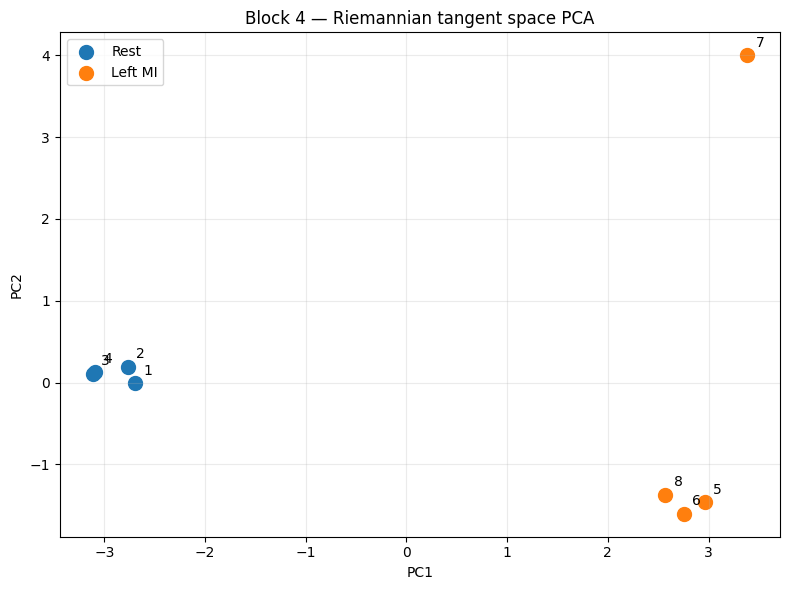

In [77]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------
# 1. Общий reference для EDA
# -----------------------------------------
reference_b4 = np.mean(cov_b4, axis=0)
reference_b4 = (reference_b4 + reference_b4.T) / 2

# -----------------------------------------
# 2. Все 8 trials -> tangent space
# -----------------------------------------
X_b4_tangent = tangent_features(
    cov_b4,
    reference_b4
)

print("Tangent features:", X_b4_tangent.shape)

# -----------------------------------------
# 3. PCA: 153 -> 2
# -----------------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_b4_tangent)

print(
    f"Explained variance PC1: {pca.explained_variance_ratio_[0]:.3f}"
)
print(
    f"Explained variance PC2: {pca.explained_variance_ratio_[1]:.3f}"
)
print(
    f"Total explained variance: "
    f"{pca.explained_variance_ratio_[:2].sum():.3f}"
)

# -----------------------------------------
# 4. Scatter
# -----------------------------------------
plt.figure(figsize=(8, 6))

rest_mask = y_b4 == 1
left_mask = y_b4 == 2

plt.scatter(
    X_pca[rest_mask, 0],
    X_pca[rest_mask, 1],
    s=100,
    label="Rest"
)

plt.scatter(
    X_pca[left_mask, 0],
    X_pca[left_mask, 1],
    s=100,
    label="Left MI"
)

# Подпишем trials
for i in range(len(X_pca)):
    plt.annotate(
        str(i + 1),
        (X_pca[i, 0], X_pca[i, 1]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Block 4 — Riemannian tangent space PCA")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [78]:
# PCA loadings для PC1
loadings = pca.components_[0]

# Названия 153 tangent-space признаков
feature_names = []

for i in range(len(eeg_labels_good)):
    for j in range(i, len(eeg_labels_good)):
        if i == j:
            feature_names.append(f"{eeg_labels_good[i]} variance")
        else:
            feature_names.append(
                f"{eeg_labels_good[i]}-{eeg_labels_good[j]} covariance"
            )

loading_df = pd.DataFrame({
    "feature": feature_names,
    "loading_PC1": loadings,
    "abs_loading_PC1": np.abs(loadings)
})

top_pc1 = (
    loading_df
    .sort_values("abs_loading_PC1", ascending=False)
    .head(20)
)

print(top_pc1.to_string(index=False))

          feature  loading_PC1  abs_loading_PC1
      C4 variance    -0.548847         0.548847
      O2 variance     0.415381         0.415381
C8-RPA covariance    -0.318663         0.318663
 C4-C8 covariance    -0.286848         0.286848
 C7-C8 covariance     0.252580         0.252580
 O2-C7 covariance     0.234358         0.234358
     RPA variance    -0.174856         0.174856
     FP2 variance     0.173255         0.173255
      C7 variance     0.169461         0.169461
C7-RPA covariance    -0.143485         0.143485
C4-RPA covariance    -0.143167         0.143167
 O2-C8 covariance     0.122457         0.122457
FP2-PZ covariance     0.097634         0.097634
 C8-P8 covariance     0.077549         0.077549
 F3-C8 covariance     0.055431         0.055431
 P3-C7 covariance    -0.054939         0.054939
 C7-P8 covariance     0.053266         0.053266
      F3 variance    -0.051251         0.051251
 P3-O2 covariance    -0.050956         0.050956
P8-RPA covariance    -0.050266         0

In [79]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

results_top = []

for k in [5, 10]:
    y_true_all = []
    y_pred_all = []

    for test_idx in range(len(X_b4)):
        train_idx = np.arange(len(X_b4)) != test_idx

        # Train-only covariance reference
        reference = np.mean(cov_b4[train_idx], axis=0)
        reference = (reference + reference.T) / 2

        X_train_tan = tangent_features(cov_b4[train_idx], reference)
        X_test_tan = tangent_features(cov_b4[~train_idx], reference)

        # PCA/loadings are fitted ONLY on training data
        pca_fold = PCA(n_components=2)
        pca_fold.fit(X_train_tan)

        # Top-k features contributing most to PC1
        top_idx = np.argsort(
            np.abs(pca_fold.components_[0])
        )[::-1][:k]

        X_train_sel = X_train_tan[:, top_idx]
        X_test_sel = X_test_tan[:, top_idx]

        # Scaling only from training data
        scaler = StandardScaler()
        X_train_sel = scaler.fit_transform(X_train_sel)
        X_test_sel = scaler.transform(X_test_sel)

        lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
        lda.fit(X_train_sel, y_b4[train_idx])

        y_pred = lda.predict(X_test_sel)

        y_true_all.append(y_b4[test_idx])
        y_pred_all.append(y_pred[0])

    acc = accuracy_score(y_true_all, y_pred_all)
    bal_acc = balanced_accuracy_score(y_true_all, y_pred_all)
    cm = confusion_matrix(y_true_all, y_pred_all, labels=[1, 2])

    results_top.append({
        "top_k": k,
        "accuracy": acc,
        "balanced_accuracy": bal_acc
    })

    print(f"\nTop-{k} PC1 features")
    print(f"Accuracy:          {acc:.3f}")
    print(f"Balanced accuracy: {bal_acc:.3f}")
    print("Confusion matrix [Rest, Left]:")
    print(cm)

print("\nSummary:")
print(pd.DataFrame(results_top).to_string(index=False))


Top-5 PC1 features
Accuracy:          1.000
Balanced accuracy: 1.000
Confusion matrix [Rest, Left]:
[[4 0]
 [0 4]]

Top-10 PC1 features
Accuracy:          1.000
Balanced accuracy: 1.000
Confusion matrix [Rest, Left]:
[[4 0]
 [0 4]]

Summary:
 top_k  accuracy  balanced_accuracy
     5       1.0                1.0
    10       1.0                1.0


In [80]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import numpy as np
import pandas as pd

# Block 6: только Left (2) и Right (6)
mask_b6 = (block_all == 6) & np.isin(y_all, [2, 3])

X_b6_cov = cov_shrink[mask_b6]
y_b6 = y_all[mask_b6]

print("Block 6 trials:", len(y_b6))
print("Class counts:")
print(pd.Series(y_b6).map({2: "Left MI", 3: "Right MI"}).value_counts())

results_b6 = []

for k in [5, 10, 153]:
    y_true_all = []
    y_pred_all = []

    for test_idx in range(len(y_b6)):
        train_mask = np.ones(len(y_b6), dtype=bool)
        train_mask[test_idx] = False

        # Reference covariance — только training trials
        reference = np.mean(X_b6_cov[train_mask], axis=0)
        reference = (reference + reference.T) / 2

        X_train_tan = tangent_features(
            X_b6_cov[train_mask], reference
        )
        X_test_tan = tangent_features(
            X_b6_cov[~train_mask], reference
        )

        if k < 153:
            # PCA/loadings только на training set
            pca_fold = PCA(n_components=2)
            pca_fold.fit(X_train_tan)

            top_idx = np.argsort(
                np.abs(pca_fold.components_[0])
            )[::-1][:k]

            X_train_sel = X_train_tan[:, top_idx]
            X_test_sel = X_test_tan[:, top_idx]
        else:
            X_train_sel = X_train_tan
            X_test_sel = X_test_tan

        # Scaling только по train
        scaler = StandardScaler()
        X_train_sel = scaler.fit_transform(X_train_sel)
        X_test_sel = scaler.transform(X_test_sel)

        lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
        lda.fit(X_train_sel, y_b6[train_mask])

        y_pred = lda.predict(X_test_sel)

        y_true_all.append(y_b6[test_idx])
        y_pred_all.append(y_pred[0])

    acc = accuracy_score(y_true_all, y_pred_all)
    bal_acc = balanced_accuracy_score(y_true_all, y_pred_all)
    cm = confusion_matrix(
        y_true_all,
        y_pred_all,
        labels=[2, 3]
    )

    results_b6.append({
        "features": k,
        "accuracy": acc,
        "balanced_accuracy": bal_acc
    })

    print(f"\nFeatures: {k}")
    print(f"Accuracy:          {acc:.3f}")
    print(f"Balanced accuracy: {bal_acc:.3f}")
    print("Confusion matrix [Left, Right]:")
    print(cm)

print("\nSummary:")
print(pd.DataFrame(results_b6).to_string(index=False))

Block 6 trials: 8
Class counts:
Right MI    6
Left MI     2
dtype: int64

Features: 5
Accuracy:          0.750
Balanced accuracy: 0.500
Confusion matrix [Left, Right]:
[[0 2]
 [0 6]]

Features: 10
Accuracy:          0.875
Balanced accuracy: 0.750
Confusion matrix [Left, Right]:
[[1 1]
 [0 6]]

Features: 153
Accuracy:          0.750
Balanced accuracy: 0.833
Confusion matrix [Left, Right]:
[[2 0]
 [2 4]]

Summary:
 features  accuracy  balanced_accuracy
        5     0.750           0.500000
       10     0.875           0.750000
      153     0.750           0.833333


/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_shrunk_covariance.py:290: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_empirical_covariance.py:86: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_shrunk_covariance.py:290: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_empirical_covariance.py:86: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_shrunk_covariance.py:290: UserWarning: Only one sample available. You may want to reshape your data array
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/covariance/_empirical_covariance.

Raw EEG: (149550, 17)
Filtered EEG: (149550, 17)
Filter state: (4, 2, 17)

Test window:
shape: (250, 17)
duration: 1.0 sec
channels: 17
mean: [ -359.74948142 -4258.36402723 -8127.80697672 -4997.71362191
  -287.54024368]
std: [195723.76193145 634484.09949453 343911.81455998 370437.90164746
 215406.96950291]
C3 original index: 4
C3 index in good channels: 4


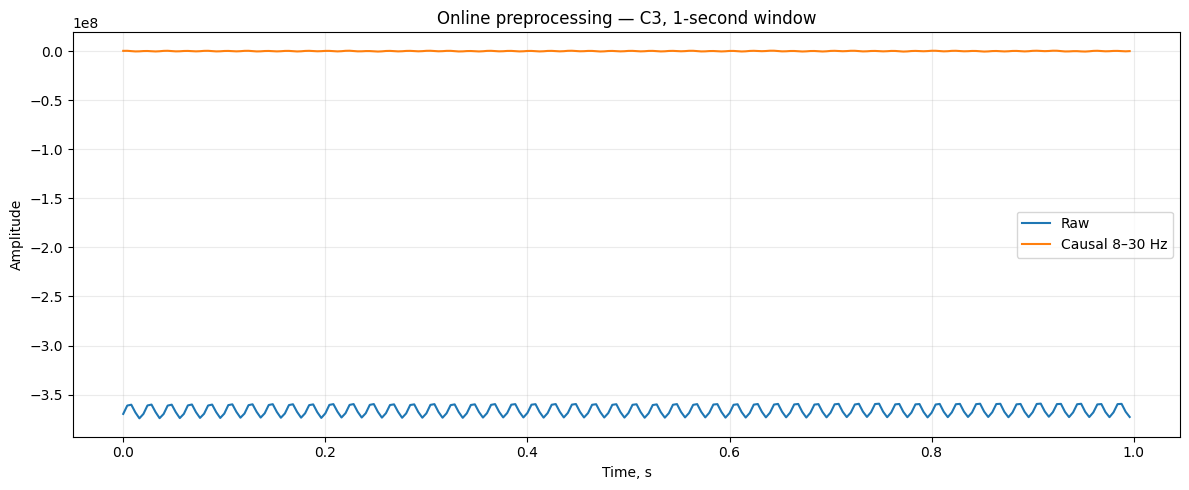

In [81]:
from scipy.signal import butter, sosfilt
import numpy as np
import matplotlib.pyplot as plt

# Параметры соревнования
fs = 250
window_sec = 1.0
window_samples = int(fs * window_sec)

# Используем только ранее выбранные 17 хороших каналов
X_eeg = eeg_data[:, good_idx].astype(np.float64)

# Causal band-pass 8–30 Hz
sos_online = butter(
    4,
    [8, 30],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# ВАЖНО:
# фильтр обрабатывает поток последовательно и хранит внутреннее состояние.
# Никаких данных из будущего.
X_filtered, filter_state = sosfilt(
    sos_online,
    X_eeg,
    axis=0,
    zi=np.zeros((sos_online.shape[0], 2, X_eeg.shape[1]))
)

print("Raw EEG:", X_eeg.shape)
print("Filtered EEG:", X_filtered.shape)
print("Filter state:", filter_state.shape)

# Проверим одно 1-секундное online-окно
test_start = 100_000
test_end = test_start + window_samples

window = X_filtered[test_start:test_end]

print("\nTest window:")
print("shape:", window.shape)
print("duration:", window.shape[0] / fs, "sec")
print("channels:", window.shape[1])
print("mean:", np.mean(window, axis=0)[:5])
print("std:", np.std(window, axis=0)[:5])

# Сравним raw и causal-filtered сигнал одного канала
# Находим индекс C3 среди 17 отобранных хороших каналов
c3_original_idx = eeg_labels.index("C3")
ch = good_idx.index(c3_original_idx)

print("C3 original index:", c3_original_idx)
print("C3 index in good channels:", ch)

time = np.arange(window_samples) / fs

plt.figure(figsize=(12, 5))
plt.plot(
    time,
    X_eeg[test_start:test_end, ch],
    label="Raw"
)
plt.plot(
    time,
    X_filtered[test_start:test_end, ch],
    label="Causal 8–30 Hz"
)
plt.xlabel("Time, s")
plt.ylabel("Amplitude")
plt.title("Online preprocessing — C3, 1-second window")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [82]:
def get_last_window(
    filtered_data,
    current_sample,
    window_samples=250
):
    """
    Возвращает последнее 1-секундное окно EEG.

    current_sample — индекс текущего момента.
    Используются только samples <= current_sample.
    """

    end = current_sample + 1
    start = end - window_samples

    if start < 0:
        raise ValueError(
            f"Недостаточно данных: нужно {window_samples} samples, "
            f"но доступно только {end}."
        )

    window = filtered_data[start:end]

    return window


# Проверяем несколько моментов времени
for current_sample in [10000, 50000, 100000]:
    window = get_last_window(
        X_filtered,
        current_sample
    )

    print(
        f"current_sample={current_sample:6d} | "
        f"time={current_sample / fs:7.2f} s | "
        f"window={window.shape} | "
        f"window_end={current_sample}"
    )

current_sample= 10000 | time=  40.00 s | window=(250, 17) | window_end=10000
current_sample= 50000 | time= 200.00 s | window=(250, 17) | window_end=50000
current_sample=100000 | time= 400.00 s | window=(250, 17) | window_end=100000


In [83]:
from sklearn.covariance import LedoitWolf
import numpy as np

def window_covariance(window):
    """
    Оценка covariance для одного online EEG-окна.
    window: (250 samples, 17 channels)
    """

    # Ledoit-Wolf работает по схеме:
    # samples × features = time × EEG channels
    lw = LedoitWolf()
    lw.fit(window)

    cov = lw.covariance_

    # Проверяем симметрию
    cov = (cov + cov.T) / 2

    return cov


# Проверяем covariance для нескольких online-моментов
test_samples = [10000, 50000, 100000]

for current_sample in test_samples:

    window = get_last_window(
        X_filtered,
        current_sample
    )

    cov = window_covariance(window)

    eigenvalues = np.linalg.eigvalsh(cov)

    print(
        f"\nCurrent sample: {current_sample}"
        f"\nTime: {current_sample / fs:.2f} s"
        f"\nWindow: {window.shape}"
        f"\nCovariance: {cov.shape}"
        f"\nMin eigenvalue: {eigenvalues.min():.3e}"
        f"\nMax eigenvalue: {eigenvalues.max():.3e}"
        f"\nCondition number: "
        f"{eigenvalues.max() / eigenvalues.min():.2f}"
    )


Current sample: 10000
Time: 40.00 s
Window: (250, 17)
Covariance: (17, 17)
Min eigenvalue: 1.298e+10
Max eigenvalue: 6.930e+13
Condition number: 5337.84

Current sample: 50000
Time: 200.00 s
Window: (250, 17)
Covariance: (17, 17)
Min eigenvalue: 1.278e+10
Max eigenvalue: 7.319e+13
Condition number: 5725.60

Current sample: 100000
Time: 400.00 s
Window: (250, 17)
Covariance: (17, 17)
Min eigenvalue: 1.353e+10
Max eigenvalue: 7.940e+13
Condition number: 5866.49


In [84]:
def tangent_transform(cov, reference_cov):
    """
    Перевод одной covariance matrix в tangent space
    относительно reference covariance.

    cov:
        (n_channels, n_channels)

    reference_cov:
        (n_channels, n_channels)

    return:
        153-dimensional tangent-space vector
        для 17 EEG каналов.
    """

    cov = (cov + cov.T) / 2
    reference_cov = (reference_cov + reference_cov.T) / 2

    # Собственное разложение reference covariance
    eigvals_ref, eigvecs_ref = np.linalg.eigh(reference_cov)

    # Численная защита
    eigvals_ref = np.maximum(eigvals_ref, 1e-12)

    # Reference^(-1/2)
    ref_inv_sqrt = (
        eigvecs_ref
        @ np.diag(1.0 / np.sqrt(eigvals_ref))
        @ eigvecs_ref.T
    )

    # Whitening относительно reference
    whitened = ref_inv_sqrt @ cov @ ref_inv_sqrt
    whitened = (whitened + whitened.T) / 2

    # Matrix logarithm через eigendecomposition
    eigvals, eigvecs = np.linalg.eigh(whitened)
    eigvals = np.maximum(eigvals, 1e-12)

    log_matrix = (
        eigvecs
        @ np.diag(np.log(eigvals))
        @ eigvecs.T
    )

    # Векторизуем только верхний треугольник.
    # Диагональ + 136 off-diagonal = 153 признака.
    idx = np.triu_indices_from(log_matrix)

    tangent_vector = log_matrix[idx]

    return tangent_vector


# Reference covariance строим ТОЛЬКО из тренировочных trial'ов.
# Для демонстрации используем уже рассчитанные cov_shrink.
reference_cov_online = np.mean(cov_shrink, axis=0)
reference_cov_online = (
    reference_cov_online + reference_cov_online.T
) / 2

print("Reference covariance:", reference_cov_online.shape)

# Проверяем преобразование одного online окна
current_sample = 100000

window = get_last_window(
    X_filtered,
    current_sample
)

cov_online = window_covariance(window)

tangent_vector = tangent_transform(
    cov_online,
    reference_cov_online
)

print("Online covariance:", cov_online.shape)
print("Tangent vector:", tangent_vector.shape)
print("Expected features:", 17 * 18 // 2)
print("Finite:", np.isfinite(tangent_vector).all())
print(
    "Range:",
    f"{tangent_vector.min():.3f}",
    "to",
    f"{tangent_vector.max():.3f}"
)

Reference covariance: (17, 17)
Online covariance: (17, 17)
Tangent vector: (153,)
Expected features: 153
Finite: True
Range: -4.647 to 1.014


In [85]:
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# Block 4: 4 Rest + 4 Left
# ---------------------------------------------------------
mask_b4 = (block_all == 4) & np.isin(y_all, [1, 2])

X_b4_online = X_filtered[
    np.concatenate([
        np.arange(len(X_filtered))
    ])
]

# Индексы исходных trial'ов Block 4
b4_trial_indices = np.where(mask_b4)[0]

print("Block 4 trials:", len(b4_trial_indices))
print(
    "Classes:",
    y_all[b4_trial_indices]
)

# ---------------------------------------------------------
# Функция covariance для trial/window
# ---------------------------------------------------------
def compute_lw_cov(data):
    lw = LedoitWolf()
    lw.fit(data)
    cov = lw.covariance_
    return (cov + cov.T) / 2


# ---------------------------------------------------------
# LOOCV по trial'ам
# ---------------------------------------------------------
all_true = []
all_pred = []
window_results = []

for test_trial_pos, test_trial_idx in enumerate(b4_trial_indices):

    train_trial_indices = np.delete(
        b4_trial_indices,
        test_trial_pos
    )

    # =========================
    # TRAIN
    # =========================
    train_covs = []

    for trial_idx in train_trial_indices:

        start = int(runs[runs["state"].isin([1, 2])].iloc[trial_idx]["start"] + 2 * fs)
        end   = int(runs[runs["state"].isin([1, 2])].iloc[trial_idx]["start"] + 8 * fs)

        trial_signal = X_filtered[start:end]

        cov = compute_lw_cov(trial_signal)
        train_covs.append(cov)

    train_covs = np.stack(train_covs)

    # Reference ТОЛЬКО из train
    reference = np.mean(train_covs, axis=0)
    reference = (reference + reference.T) / 2

    # Tangent features для train trials
    X_train_tangent = np.stack([
        tangent_transform(cov, reference)
        for cov in train_covs
    ])

    y_train = y_all[train_trial_indices]

    # Scaling только train
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_tangent)

    # LDA
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )
    lda.fit(X_train_scaled, y_train)

    # =========================
    # TEST TRIAL
    # =========================
    test_run = runs[runs["state"].isin([1, 2])].iloc[test_trial_idx]

    test_start = int(test_run["start"] + 2 * fs)
    test_end = int(test_run["start"] + 8 * fs)

    true_class = y_all[test_trial_idx]

    trial_preds = []

    # Prediction каждые 250 ms
    # Используем последние 1 s
    for current_sample in range(
        test_start + window_samples - 1,
        test_end,
        int(0.25 * fs)
    ):

        window = get_last_window(
            X_filtered,
            current_sample,
            window_samples
        )

        cov_window = compute_lw_cov(window)

        tangent_window = tangent_transform(
            cov_window,
            reference
        ).reshape(1, -1)

        tangent_window = scaler.transform(
            tangent_window
        )

        pred = lda.predict(tangent_window)[0]

        trial_preds.append(pred)

        all_true.append(true_class)
        all_pred.append(pred)

        window_results.append({
            "trial": test_trial_idx + 1,
            "true_class": true_class,
            "time_sec": current_sample / fs,
            "prediction": pred
        })

    print(
        f"Trial {test_trial_idx + 1}: "
        f"true={true_class}, "
        f"predictions={trial_preds}"
    )

# ---------------------------------------------------------
# Итог по всем online windows
# ---------------------------------------------------------
print("\n=== ONLINE WINDOW RESULTS ===")

print(
    "Accuracy:",
    f"{accuracy_score(all_true, all_pred):.3f}"
)

print(
    "Balanced accuracy:",
    f"{balanced_accuracy_score(all_true, all_pred):.3f}"
)

print("\nConfusion matrix [Rest, Left]:")
print(
    confusion_matrix(
        all_true,
        all_pred,
        labels=[1, 2]
    )
)

print("\nNumber of predictions:", len(all_true))

Block 4 trials: 8
Classes: [1 1 1 1 2 2 2 2]
Trial 25: true=1, predictions=[2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2]
Trial 26: true=1, predictions=[2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Trial 27: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 2, 1, 1, 1, 1]
Trial 28: true=1, predictions=[2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1]
Trial 29: true=2, predictions=[1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2]
Trial 30: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]
Trial 31: true=2, predictions=[2, 2, 1, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2]
Trial 32: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

=== ONLINE WINDOW RESULTS ===
Accuracy: 0.601
Balanced accuracy: 0.601

Confusion matrix [Rest, Left]:
[[38 46]
 [21 63]]

Number of predictions: 168


In [86]:
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import numpy as np

# ---------------------------------------------------------
# Block 4: 4 Rest + 4 Left
# ---------------------------------------------------------
mask_b4 = (block_all == 4) & np.isin(y_all, [1, 2])
b4_trial_indices = np.where(mask_b4)[0]

all_true = []
all_pred = []

window_step = int(0.25 * fs)       # prediction каждые 250 ms
window_samples = int(1.0 * fs)     # окно 1 секунда

for test_trial_pos, test_trial_idx in enumerate(b4_trial_indices):

    # -----------------------------------------------------
    # TRAIN trials
    # -----------------------------------------------------
    train_trial_indices = np.delete(
        b4_trial_indices,
        test_trial_pos
    )

    train_tangent = []
    train_labels = []

    for trial_idx in train_trial_indices:

        run = runs[runs["state"].isin([1, 2, 3])].iloc[trial_idx]

        trial_start = int(run["start"] + 2 * fs)
        trial_end = int(run["start"] + 8 * fs)

        # 1-секундные окна с шагом 250 ms
        for start in range(
            trial_start,
            trial_end - window_samples + 1,
            window_step
        ):

            window = X_filtered[
                start:start + window_samples
            ]

            cov = compute_lw_cov(window)

            train_tangent.append(cov)
            train_labels.append(y_all[trial_idx])

    train_covs = np.stack(train_tangent)
    y_train = np.array(train_labels)

    # Reference covariance только из TRAIN
    reference = np.mean(train_covs, axis=0)
    reference = (reference + reference.T) / 2

    # Covariance -> tangent space
    X_train_tangent = np.stack([
        tangent_transform(cov, reference)
        for cov in train_covs
    ])

    # Scaling только TRAIN
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(
        X_train_tangent
    )

    # LDA
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    # -----------------------------------------------------
    # TEST trial
    # -----------------------------------------------------
    test_run = runs[
        runs["state"].isin([1, 2, 3])
    ].iloc[test_trial_idx]

    test_start = int(test_run["start"] + 2 * fs)
    test_end = int(test_run["start"] + 8 * fs)

    true_class = y_all[test_trial_idx]

    trial_preds = []

    for current_sample in range(
        test_start + window_samples - 1,
        test_end,
        window_step
    ):

        window = get_last_window(
            X_filtered,
            current_sample,
            window_samples
        )

        cov_window = compute_lw_cov(window)

        tangent_window = tangent_transform(
            cov_window,
            reference
        ).reshape(1, -1)

        tangent_window = scaler.transform(
            tangent_window
        )

        pred = lda.predict(
            tangent_window
        )[0]

        trial_preds.append(pred)

        all_true.append(true_class)
        all_pred.append(pred)

    print(
        f"Trial {test_trial_idx + 1}: "
        f"true={true_class}, "
        f"predictions={trial_preds}"
    )


# ---------------------------------------------------------
# Итог
# ---------------------------------------------------------
print("\n=== MATCHED ONLINE TRAIN/TEST ===")

print(
    "Accuracy:",
    f"{accuracy_score(all_true, all_pred):.3f}"
)

print(
    "Balanced accuracy:",
    f"{balanced_accuracy_score(all_true, all_pred):.3f}"
)

print("\nConfusion matrix [Rest, Left]:")
print(
    confusion_matrix(
        all_true,
        all_pred,
        labels=[1, 2]
    )
)

print("\nNumber of predictions:", len(all_true))
print("Training windows per fold:", len(train_labels))

Trial 25: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1]
Trial 26: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Trial 27: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Trial 28: true=1, predictions=[2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 2]
Trial 29: true=2, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2]
Trial 30: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Trial 31: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Trial 32: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

=== MATCHED ONLINE TRAIN/TEST ===
Accuracy: 0.857
Balanced accuracy: 0.857

Confusion matrix [Rest, Left]:
[[75  9]
 [15 69]]

Number of predictions: 168
Training windows per fold: 147


In [87]:
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import numpy as np

# ---------------------------------------------------------
# Block 4: 4 Rest + 4 Left
# ---------------------------------------------------------
mask_b4 = (block_all == 4) & np.isin(y_all, [1, 2])
b4_trial_indices = np.where(mask_b4)[0]

all_true = []
all_pred = []

window_samples = int(1.0 * fs)
test_step = int(0.25 * fs)

for test_trial_pos, test_trial_idx in enumerate(b4_trial_indices):

    # -----------------------------------------------------
    # TRAIN trials
    # -----------------------------------------------------
    train_trial_indices = np.delete(
        b4_trial_indices,
        test_trial_pos
    )

    train_covs = []
    train_labels = []

    for trial_idx in train_trial_indices:

        run = runs[runs["state"].isin([1, 2, 3])].iloc[trial_idx]

        trial_start = int(run["start"] + 2 * fs)
        trial_end = int(run["start"] + 8 * fs)

        # НЕПЕРЕКРЫВАЮЩИЕСЯ 1-секундные окна
        for start in range(
            trial_start,
            trial_end - window_samples + 1,
            window_samples
        ):

            window = X_filtered[
                start:start + window_samples
            ]

            cov = compute_lw_cov(window)

            train_covs.append(cov)
            train_labels.append(y_all[trial_idx])

    train_covs = np.stack(train_covs)
    y_train = np.array(train_labels)

    # -----------------------------------------------------
    # Train-only reference covariance
    # -----------------------------------------------------
    reference = np.mean(train_covs, axis=0)
    reference = (reference + reference.T) / 2

    # -----------------------------------------------------
    # Train covariance -> tangent space
    # -----------------------------------------------------
    X_train_tangent = np.stack([
        tangent_transform(cov, reference)
        for cov in train_covs
    ])

    # -----------------------------------------------------
    # Train-only scaling
    # -----------------------------------------------------
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(
        X_train_tangent
    )

    # -----------------------------------------------------
    # LDA
    # -----------------------------------------------------
    lda = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    lda.fit(
        X_train_scaled,
        y_train
    )

    # -----------------------------------------------------
    # TEST trial
    # -----------------------------------------------------
    test_run = runs[
        runs["state"].isin([1, 2, 3])
    ].iloc[test_trial_idx]

    test_start = int(test_run["start"] + 2 * fs)
    test_end = int(test_run["start"] + 8 * fs)

    true_class = y_all[test_trial_idx]

    trial_preds = []

    # Online: prediction каждые 250 ms
    for current_sample in range(
        test_start + window_samples - 1,
        test_end,
        test_step
    ):

        window = get_last_window(
            X_filtered,
            current_sample,
            window_samples
        )

        cov_window = compute_lw_cov(window)

        tangent_window = tangent_transform(
            cov_window,
            reference
        ).reshape(1, -1)

        tangent_window = scaler.transform(
            tangent_window
        )

        pred = lda.predict(
            tangent_window
        )[0]

        trial_preds.append(pred)

        all_true.append(true_class)
        all_pred.append(pred)

    print(
        f"Trial {test_trial_idx + 1}: "
        f"true={true_class}, "
        f"predictions={trial_preds}"
    )


# ---------------------------------------------------------
# Итог
# ---------------------------------------------------------
print("\n=== NON-OVERLAPPING TRAIN WINDOWS ===")

print(
    "Accuracy:",
    f"{accuracy_score(all_true, all_pred):.3f}"
)

print(
    "Balanced accuracy:",
    f"{balanced_accuracy_score(all_true, all_pred):.3f}"
)

print("\nConfusion matrix [Rest, Left]:")
print(
    confusion_matrix(
        all_true,
        all_pred,
        labels=[1, 2]
    )
)

print("\nNumber of test predictions:", len(all_true))
print("Training windows per fold:", len(train_labels))

Trial 25: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1]
Trial 26: true=1, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Trial 27: true=1, predictions=[1, 2, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Trial 28: true=1, predictions=[2, 2, 2, 2, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1]
Trial 29: true=2, predictions=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 1, 1, 2]
Trial 30: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 2, 2]
Trial 31: true=2, predictions=[2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 2, 2, 2]
Trial 32: true=2, predictions=[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

=== NON-OVERLAPPING TRAIN WINDOWS ===
Accuracy: 0.732
Balanced accuracy: 0.732

Confusion matrix [Rest, Left]:
[[69 15]
 [30 54]]

Number of test predictions: 168
Training windows per fold: 42


In [88]:
class OnlineClassifier:
    def __init__(
        self,
        fs=250,
        n_channels=17,
        window_sec=1.0,
        prediction_interval_sec=0.25
    ):
        self.fs = fs
        self.n_channels = n_channels

        self.window_samples = int(
            fs * window_sec
        )

        self.prediction_interval = int(
            fs * prediction_interval_sec
        )

        # Все накопленные данные после последнего predict
        self.buffer = np.empty(
            (0, n_channels),
            dtype=np.float64
        )

        self.is_fitted = False

        self.current_block = None

        # Сколько samples было при последнем prediction
        self.samples_since_prediction = 0

        self.prediction_count = 0

    def load(self):
        self.buffer = np.empty(
            (0, self.n_channels),
            dtype=np.float64
        )

        self.is_fitted = False
        self.current_block = None
        self.samples_since_prediction = 0
        self.prediction_count = 0

        print("Model loaded.")

    def push(self, eeg_chunk):
        """
        Добавляет новые EEG samples.

        Parameters
        ----------
        eeg_chunk : array, shape (n_samples, n_channels)
        """

        eeg_chunk = np.asarray(
            eeg_chunk,
            dtype=np.float64
        )

        if eeg_chunk.ndim == 1:
            eeg_chunk = eeg_chunk.reshape(1, -1)

        if eeg_chunk.shape[1] != self.n_channels:
            raise ValueError(
                f"Expected {self.n_channels} channels, "
                f"got {eeg_chunk.shape[1]}"
            )

        self.buffer = np.vstack([
            self.buffer,
            eeg_chunk
        ])

        self.samples_since_prediction += len(eeg_chunk)

    def get_last_window(self):
        """
        Возвращает последние 1 секунду EEG.
        """

        if len(self.buffer) < self.window_samples:
            return None

        return self.buffer[-self.window_samples:]

    def predict(self):
        """
        Делает prediction только если:

        1. модель обучена;
        2. есть полное 1-секундное окно;
        3. прошло 250 ms с предыдущего prediction.
        """

        if not self.is_fitted:
            return None

        if len(self.buffer) < self.window_samples:
            return None

        if self.samples_since_prediction < self.prediction_interval:
            return None

        window = self.get_last_window()

        # Пока настоящей модели нет.
        # Здесь позже будет:
        #
        # window
        #   ↓
        # covariance
        #   ↓
        # tangent space
        #   ↓
        # scaler
        #   ↓
        # LDA
        #   ↓
        # prediction

        self.samples_since_prediction = 0
        self.prediction_count += 1

        return None

    def fit_block(self, X_block, y_block, block_id=None):

        X_block = np.asarray(X_block)
        y_block = np.asarray(y_block)

        if len(X_block) != len(y_block):
            raise ValueError(
                "X_block and y_block must have the same length"
            )

        self.current_block = block_id
        self.is_fitted = True

        print(
            f"Block {block_id}: "
            f"{len(X_block)} samples, "
            f"classes={np.unique(y_block)}"
        )


# ---------------------------------------------------------
# TEST
# ---------------------------------------------------------

model = OnlineClassifier(
    fs=250,
    n_channels=len(good_idx)
)

model.load()

# Пока только 100 samples
model.push(X_filtered[:100])

print("After 100 samples:")
print("Buffer:", model.buffer.shape)
print("Window:", model.get_last_window())
print("Prediction:", model.predict())

# Ещё 150 -> всего 250
model.push(X_filtered[100:250])

print("\nAfter 250 samples:")
print("Buffer:", model.buffer.shape)
print(
    "Window shape:",
    model.get_last_window().shape
)

# Обучаем заглушку
model.fit_block(
    X_filtered[:250],
    eeg["States"][:250],
    block_id=1
)

print(
    "Prediction immediately after fit:",
    model.predict()
)

# Добавляем 125 samples = половина prediction interval
model.push(X_filtered[250:375])

print(
    "\nAfter +125 samples:",
    "prediction =",
    model.predict()
)

# Ещё 125 samples = прошло 250 samples
model.push(X_filtered[375:500])

print(
    "After +250 samples:",
    "prediction =",
    model.predict()
)

print(
    "Prediction count:",
    model.prediction_count
)

Model loaded.
After 100 samples:
Buffer: (100, 17)
Window: None
Prediction: None

After 250 samples:
Buffer: (250, 17)
Window shape: (250, 17)
Block 1: 250 samples, classes=[0]
Prediction immediately after fit: None

After +125 samples: prediction = None
After +250 samples: prediction = None
Prediction count: 3


In [89]:
# ---------------------------------------------------------
# Вспомогательные функции
# ---------------------------------------------------------

def compute_lw_cov(window):
    """
    Ledoit-Wolf covariance для одного EEG-окна.

    window:
        shape = (n_samples, n_channels)
    """
    lw = LedoitWolf()
    lw.fit(window)

    cov = lw.covariance_

    return (cov + cov.T) / 2


def tangent_transform(cov, reference_cov):
    """
    Перевод SPD covariance matrix в tangent space
    относительно reference covariance.

    Для 17 каналов:
        17 * 18 / 2 = 153 features
    """

    cov = (cov + cov.T) / 2
    reference_cov = (reference_cov + reference_cov.T) / 2

    # -----------------------------------------------------
    # Reference^(-1/2)
    # -----------------------------------------------------
    eigvals_ref, eigvecs_ref = np.linalg.eigh(
        reference_cov
    )

    eigvals_ref = np.maximum(
        eigvals_ref,
        1e-12
    )

    ref_inv_sqrt = (
        eigvecs_ref
        @ np.diag(1.0 / np.sqrt(eigvals_ref))
        @ eigvecs_ref.T
    )

    # -----------------------------------------------------
    # Whitening
    # -----------------------------------------------------
    whitened = (
        ref_inv_sqrt
        @ cov
        @ ref_inv_sqrt
    )

    whitened = (
        whitened + whitened.T
    ) / 2

    # -----------------------------------------------------
    # Matrix logarithm
    # -----------------------------------------------------
    eigvals, eigvecs = np.linalg.eigh(
        whitened
    )

    eigvals = np.maximum(
        eigvals,
        1e-12
    )

    log_matrix = (
        eigvecs
        @ np.diag(np.log(eigvals))
        @ eigvecs.T
    )

    # -----------------------------------------------------
    # Верхний треугольник
    # -----------------------------------------------------
    idx = np.triu_indices_from(
        log_matrix
    )

    features = log_matrix[idx]

    return features


# ---------------------------------------------------------
# Создаём reference covariance
# ---------------------------------------------------------

# Возьмём первые 6-секундные trial windows Block 4
# и разобьём их на неперекрывающиеся 1-секундные окна.

b4_trial_indices = np.where(
    (block_all == 4) &
    np.isin(y_all, [1, 2])
)[0]

reference_covariances = []

for trial_idx in b4_trial_indices:

    run = runs[
        runs["state"].isin([1, 2, 3])
    ].iloc[trial_idx]

    start = int(
        run["start"] + 2 * fs
    )

    end = int(
        run["start"] + 8 * fs
    )

    for window_start in range(
        start,
        end - window_samples + 1,
        window_samples
    ):

        window = X_filtered[
            window_start:
            window_start + window_samples
        ]

        cov = compute_lw_cov(window)

        reference_covariances.append(cov)


# Средняя covariance как reference
reference_cov = np.mean(
    reference_covariances,
    axis=0
)

reference_cov = (
    reference_cov +
    reference_cov.T
) / 2


# ---------------------------------------------------------
# Проверяем одно online окно
# ---------------------------------------------------------

test_window = X_filtered[
    10000 - window_samples + 1:
    10001
]

test_cov = compute_lw_cov(
    test_window
)

test_features = tangent_transform(
    test_cov,
    reference_cov
)

print("Window shape:", test_window.shape)
print("Covariance shape:", test_cov.shape)
print("Feature shape:", test_features.shape)
print("Finite:", np.all(np.isfinite(test_features)))
print(
    "Feature range:",
    test_features.min(),
    test_features.max()
)

Window shape: (250, 17)
Covariance shape: (17, 17)
Feature shape: (153,)
Finite: True
Feature range: -1.0277265883295987 0.3927167819814492


In [90]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


class OnlineClassifier:
    def __init__(
        self,
        fs=250,
        n_channels=17,
        window_sec=1.0,
        prediction_interval_sec=0.25
    ):
        self.fs = fs
        self.n_channels = n_channels

        self.window_samples = int(
            fs * window_sec
        )

        self.prediction_interval = int(
            fs * prediction_interval_sec
        )

        self.buffer = np.empty(
            (0, n_channels),
            dtype=np.float64
        )

        self.samples_since_prediction = 0
        self.prediction_count = 0

        self.current_block = None
        self.is_fitted = False

        self.reference_cov = None
        self.scaler = None
        self.lda = None

    def load(self):
        self.buffer = np.empty(
            (0, self.n_channels),
            dtype=np.float64
        )

        self.samples_since_prediction = 0
        self.prediction_count = 0

        self.current_block = None
        self.is_fitted = False

        self.reference_cov = None
        self.scaler = None
        self.lda = None

        print("Model loaded.")

    def push(self, eeg_chunk):

        eeg_chunk = np.asarray(
            eeg_chunk,
            dtype=np.float64
        )

        if eeg_chunk.ndim == 1:
            eeg_chunk = eeg_chunk.reshape(1, -1)

        if eeg_chunk.shape[1] != self.n_channels:
            raise ValueError(
                f"Expected {self.n_channels} channels, "
                f"got {eeg_chunk.shape[1]}"
            )

        self.buffer = np.vstack([
            self.buffer,
            eeg_chunk
        ])

        self.samples_since_prediction += len(
            eeg_chunk
        )

        # Храним только необходимую историю.
        # Оставляем небольшой запас для безопасности.
        max_buffer = self.window_samples

        if len(self.buffer) > max_buffer:
            self.buffer = self.buffer[-max_buffer:]

    def get_last_window(self):

        if len(self.buffer) < self.window_samples:
            return None

        return self.buffer[-self.window_samples:]

    def _extract_features(self, window):

        cov = compute_lw_cov(window)

        features = tangent_transform(
            cov,
            self.reference_cov
        )

        return features.reshape(1, -1)

    def fit_block(
        self,
        X_train,
        y_train,
        reference_cov,
        block_id=None
    ):
        """
        Обучение модели.

        X_train:
            shape = (n_windows, 153)

        y_train:
            labels 1 / 2 / 3

        reference_cov:
            covariance, рассчитанная ТОЛЬКО
            из training data.
        """

        X_train = np.asarray(
            X_train,
            dtype=np.float64
        )

        y_train = np.asarray(
            y_train
        )

        if X_train.ndim != 2:
            raise ValueError(
                "X_train must be 2-dimensional"
            )

        if len(X_train) != len(y_train):
            raise ValueError(
                "X_train and y_train must have "
                "the same number of samples"
            )

        classes = np.unique(y_train)

        print(
            f"Block {block_id}: "
            f"{len(X_train)} windows, "
            f"classes={classes}"
        )

        # -------------------------------------------------
        # Reference covariance
        # -------------------------------------------------

        self.reference_cov = (
            np.asarray(
                reference_cov,
                dtype=np.float64
            )
        )

        # -------------------------------------------------
        # Если пока только один класс —
        # LDA обучать нельзя.
        # -------------------------------------------------

        if len(classes) < 2:

            self.is_fitted = False

            print(
                "Only one class available. "
                "Classifier is not fitted yet."
            )

            return

        # -------------------------------------------------
        # StandardScaler
        # -------------------------------------------------

        self.scaler = StandardScaler()

        X_scaled = self.scaler.fit_transform(
            X_train
        )

        # -------------------------------------------------
        # Shrinkage LDA
        # -------------------------------------------------

        self.lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )

        self.lda.fit(
            X_scaled,
            y_train
        )

        self.current_block = block_id
        self.is_fitted = True

        print(
            "Fitted classes:",
            self.lda.classes_
        )

    def predict(self):

        if not self.is_fitted:
            return None

        if len(self.buffer) < self.window_samples:
            return None

        if (
            self.samples_since_prediction
            < self.prediction_interval
        ):
            return None

        window = self.get_last_window()

        features = self._extract_features(
            window
        )

        features_scaled = (
            self.scaler.transform(
                features
            )
        )

        prediction = self.lda.predict(
            features_scaled
        )[0]

        self.samples_since_prediction = 0
        self.prediction_count += 1

        return int(prediction)

In [91]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# =========================================================
# Находим trials Block 4
# =========================================================

block4_trials = []

for trial_pos, (_, row) in enumerate(
    trial_runs.iterrows()
):

    block = int(trial_blocks[trial_pos])

    if block == 4:

        block4_trials.append({
            "trial_pos": trial_pos,
            "state": int(row["state"]),
            "start": int(row["start"]),
            "end": int(row["end"])
        })


print("Block 4 trials:", len(block4_trials))

print(
    pd.DataFrame(block4_trials)
)

# =========================================================
# 2. Функция: получаем 1-секундные окна
# =========================================================

def get_nonoverlap_windows(
    start,
    end,
    data,
    window_samples=250
):

    windows = []

    for s in range(
        start,
        end - window_samples + 1,
        window_samples
    ):

        window = data[
            s:s + window_samples
        ]

        if len(window) == window_samples:
            windows.append(window)

    return windows


# =========================================================
# 3. Разделяем trials:
#    один trial оставляем для теста,
#    остальные — train
# =========================================================

test_trial = block4_trials[0]

train_trials = block4_trials[1:]


# =========================================================
# 4. TRAIN
# =========================================================

train_windows = []
train_labels = []
train_covariances = []

for trial in train_trials:

    # Берём центральные 6 секунд trial,
    # как и в предыдущих экспериментах
    start = (
        trial["start"]
        + 2 * fs
    )

    end = (
        trial["start"]
        + 8 * fs
    )

    windows = get_nonoverlap_windows(
        start,
        end,
        X_filtered,
        window_samples
    )

    for window in windows:

        train_windows.append(
            window
        )

        train_labels.append(
            trial["state"]
        )

        train_covariances.append(
            compute_lw_cov(window)
        )


train_labels = np.asarray(
    train_labels
)

reference_cov_train = np.mean(
    train_covariances,
    axis=0
)

reference_cov_train = (
    reference_cov_train +
    reference_cov_train.T
) / 2


# =========================================================
# 5. Перевод TRAIN в tangent space
# =========================================================

X_train_features = np.vstack([
    tangent_transform(
        cov,
        reference_cov_train
    )
    for cov in train_covariances
])


print(
    "Train windows:",
    X_train_features.shape
)

print(
    "Train classes:",
    np.unique(
        train_labels,
        return_counts=True
    )
)


# =========================================================
# 6. Создаём online classifier
# =========================================================

model = OnlineClassifier(
    fs=fs,
    n_channels=len(good_idx)
)

model.load()

model.fit_block(
    X_train_features,
    train_labels,
    reference_cov=reference_cov_train,
    block_id=4
)


# =========================================================
# 7. ONLINE TEST
#
#    Каждые 250 ms берём последние 1 s.
# =========================================================

test_start = (
    test_trial["start"]
    + 2 * fs
)

test_end = (
    test_trial["start"]
    + 8 * fs
)


predictions = []
true_labels = []


# Начинаем с первого полного 1-секундного окна
for current_sample in range(
    test_start + window_samples - 1,
    test_end,
    62  # ~250 ms при 250 Hz
):

    window = X_filtered[
        current_sample - window_samples + 1:
        current_sample + 1
    ]

    # Заполняем buffer напрямую
    model.buffer = window.copy()

    # Разрешаем prediction
    model.samples_since_prediction = (
        model.prediction_interval
    )

    pred = model.predict()

    if pred is not None:

        predictions.append(
            pred
        )

        true_labels.append(
            test_trial["state"]
        )


# =========================================================
# 8. Результаты
# =========================================================

predictions = np.asarray(
    predictions
)

true_labels = np.asarray(
    true_labels
)

print(
    "\nNumber of predictions:",
    len(predictions)
)

print(
    "Accuracy:",
    accuracy_score(
        true_labels,
        predictions
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        true_labels,
        predictions
    )
)

print(
    "\nConfusion matrix:"
)

print(
    confusion_matrix(
        true_labels,
        predictions,
        labels=[1, 2]
    )
)

Block 4 trials: 8
   trial_pos  state  start    end
0         24      1  65145  67395
1         25      2  67773  70026
2         26      1  70395  72645
3         27      3  73023  75270
4         28      1  75648  77898
5         29      2  78270  80520
6         30      1  80895  83145
7         31      3  83520  85773
Train windows: (42, 153)
Train classes: (array([1, 2, 3]), array([18, 12, 12]))
Model loaded.
Block 4: 42 windows, classes=[1 2 3]
Fitted classes: [1 2 3]

Number of predictions: 21
Accuracy: 0.38095238095238093
Balanced accuracy: 0.38095238095238093

Confusion matrix:
[[8 0]
 [0 0]]


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:2184: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [92]:
# =========================================================
# Block 4: только Rest vs Left MI
# =========================================================

binary_trials = [
    trial for trial in block4_trials
    if trial["state"] in [1, 2]
]

print("Binary trials:", len(binary_trials))

print(
    pd.DataFrame(binary_trials)[
        ["trial_pos", "state"]
    ]
)


# =========================================================
# Leave-One-Trial-Out
# =========================================================

all_predictions = []
all_true = []


for test_idx in range(len(binary_trials)):

    test_trial = binary_trials[test_idx]

    train_trials = [
        trial
        for i, trial in enumerate(binary_trials)
        if i != test_idx
    ]

    # -----------------------------------------------------
    # TRAIN WINDOWS
    # -----------------------------------------------------

    train_windows = []
    train_labels = []
    train_covariances = []

    for trial in train_trials:

        start = (
            trial["start"] + 2 * fs
        )

        end = (
            trial["start"] + 8 * fs
        )

        windows = get_nonoverlap_windows(
            start,
            end,
            X_filtered,
            window_samples
        )

        for window in windows:

            train_windows.append(window)

            train_labels.append(
                trial["state"]
            )

            train_covariances.append(
                compute_lw_cov(window)
            )

    train_labels = np.asarray(
        train_labels
    )

    # -----------------------------------------------------
    # TRAIN REFERENCE
    # -----------------------------------------------------

    reference_cov_train = np.mean(
        train_covariances,
        axis=0
    )

    reference_cov_train = (
        reference_cov_train +
        reference_cov_train.T
    ) / 2

    # -----------------------------------------------------
    # TRAIN TANGENT FEATURES
    # -----------------------------------------------------

    X_train_features = np.vstack([
        tangent_transform(
            cov,
            reference_cov_train
        )
        for cov in train_covariances
    ])

    # -----------------------------------------------------
    # MODEL
    # -----------------------------------------------------

    model = OnlineClassifier(
        fs=fs,
        n_channels=len(good_idx)
    )

    model.load()

    model.fit_block(
        X_train_features,
        train_labels,
        reference_cov=reference_cov_train,
        block_id=4
    )

    # -----------------------------------------------------
    # ONLINE TEST
    #
    # 1-second window
    # prediction every 250 ms
    # -----------------------------------------------------

    test_start = (
        test_trial["start"] + 2 * fs
    )

    test_end = (
        test_trial["start"] + 8 * fs
    )

    trial_predictions = []

    for current_sample in range(
        test_start + window_samples - 1,
        test_end,
        62
    ):

        window = X_filtered[
            current_sample - window_samples + 1:
            current_sample + 1
        ]

        model.buffer = window.copy()

        model.samples_since_prediction = (
            model.prediction_interval
        )

        pred = model.predict()

        if pred is not None:
            trial_predictions.append(pred)

    all_predictions.extend(
        trial_predictions
    )

    all_true.extend(
        [test_trial["state"]] *
        len(trial_predictions)
    )


# =========================================================
# RESULTS
# =========================================================

all_predictions = np.asarray(
    all_predictions
)

all_true = np.asarray(
    all_true
)

print(
    "\nPredictions:",
    len(all_predictions)
)

print(
    "Accuracy:",
    accuracy_score(
        all_true,
        all_predictions
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        all_true,
        all_predictions
    )
)

cm = confusion_matrix(
    all_true,
    all_predictions,
    labels=[1, 2]
)

print(
    "\nConfusion matrix:"
)

print(cm)

print(
    "\nClass recalls:"
)

print(
    "Rest:",
    cm[0, 0] / cm[0].sum()
)

print(
    "Left MI:",
    cm[1, 1] / cm[1].sum()
)

Binary trials: 6
   trial_pos  state
0         24      1
1         25      2
2         26      1
3         28      1
4         29      2
5         30      1
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]
Model loaded.
Block 4: 30 windows, classes=[1 2]
Fitted classes: [1 2]

Predictions: 126
Accuracy: 0.6904761904761905
Balanced accuracy: 0.6428571428571428

Confusion matrix:
[[66 18]
 [21 21]]

Class recalls:
Rest: 0.7857142857142857
Left MI: 0.5


In [93]:
# =========================================================
# Sequential structure of the session
# =========================================================

block_summary = []

for block in range(1, 8):

    mask = trial_blocks == block

    block_states = y_all[mask]

    unique, counts = np.unique(
        block_states,
        return_counts=True
    )

    counts_dict = dict(
        zip(unique.astype(int), counts.astype(int))
    )

    block_summary.append({
        "block": block,
        "n_trials": len(block_states),
        "Rest": counts_dict.get(1, 0),
        "Left_MI": counts_dict.get(2, 0),
        "Right_MI": counts_dict.get(3, 0),
        "classes": sorted(
            counts_dict.keys()
        )
    })

block_summary_df = pd.DataFrame(
    block_summary
)

print(block_summary_df.to_string(index=False))

 block  n_trials  Rest  Left_MI  Right_MI classes
     1         8     8        0         0     [1]
     2         8     8        0         0     [1]
     3         8     8        0         0     [1]
     4         8     4        4         0  [1, 2]
     5         8     0        8         0     [2]
     6         8     0        2         6  [2, 3]
     7         8     0        0         8     [3]


In [94]:
# =========================================================
# Какие классы доступны модели после каждого блока?
# =========================================================

for current_block in range(1, 8):

    # Все trials из текущего и предыдущих блоков
    train_mask = trial_blocks <= current_block

    train_labels = y_all[train_mask]

    unique, counts = np.unique(
        train_labels,
        return_counts=True
    )

    class_counts = dict(
        zip(
            unique.astype(int),
            counts.astype(int)
        )
    )

    print(
        f"\nПосле блока {current_block}:"
    )

    print(
        f"  trials: {len(train_labels)}"
    )

    print(
        f"  Rest:    {class_counts.get(1, 0)}"
    )

    print(
        f"  Left MI: {class_counts.get(2, 0)}"
    )

    print(
        f"  Right MI:{class_counts.get(3, 0)}"
    )

    print(
        f"  classes: {sorted(class_counts.keys())}"
    )


После блока 1:
  trials: 8
  Rest:    8
  Left MI: 0
  Right MI:0
  classes: [1]

После блока 2:
  trials: 16
  Rest:    16
  Left MI: 0
  Right MI:0
  classes: [1]

После блока 3:
  trials: 24
  Rest:    24
  Left MI: 0
  Right MI:0
  classes: [1]

После блока 4:
  trials: 32
  Rest:    28
  Left MI: 4
  Right MI:0
  classes: [1, 2]

После блока 5:
  trials: 40
  Rest:    28
  Left MI: 12
  Right MI:0
  classes: [1, 2]

После блока 6:
  trials: 48
  Rest:    28
  Left MI: 14
  Right MI:6
  classes: [1, 2, 3]

После блока 7:
  trials: 56
  Rest:    28
  Left MI: 14
  Right MI:14
  classes: [1, 2, 3]


In [95]:
def build_training_windows(
    max_block,
    X_filtered,
    trial_runs,
    trial_blocks,
    y_all,
    fs=250,
    window_sec=1.0
):
    """
    Собирает training windows только из блоков <= max_block.

    Используются:
    - центральные 6 секунд каждого trial;
    - неперекрывающиеся окна по 1 секунде;
    - только классы 1, 2, 3;
    - state 0 не используется.

    Возвращает:
        X_windows: (n_windows, 250, 17)
        y_windows: (n_windows,)
        trial_ids: идентификатор исходного trial
    """

    window_samples = int(
        fs * window_sec
    )

    X_windows = []
    y_windows = []
    trial_ids = []

    for trial_pos, (_, row) in enumerate(
        trial_runs.iterrows()
    ):

        block = int(
            trial_blocks[trial_pos]
        )

        # Используем только уже прошедшие блоки
        if block > max_block:
            continue

        state = int(
            y_all[trial_pos]
        )

        # State 0 не является классом
        if state not in [1, 2, 3]:
            continue

        # Центральные 6 секунд trial
        start = int(
            row["start"] + 2 * fs
        )

        end = int(
            row["start"] + 8 * fs
        )

        # Неперекрывающиеся 1-секундные окна
        for window_start in range(
            start,
            end,
            window_samples
        ):

            window_end = (
                window_start +
                window_samples
            )

            if window_end > end:
                break

            window = X_filtered[
                window_start:window_end
            ]

            if window.shape != (
                window_samples,
                X_filtered.shape[1]
            ):
                continue

            X_windows.append(
                window
            )

            y_windows.append(
                state
            )

            trial_ids.append(
                trial_pos
            )

    return (
        np.stack(X_windows),
        np.asarray(y_windows),
        np.asarray(trial_ids)
    )


# =========================================================
# Проверяем для разных этапов
# =========================================================

for block in [3, 4, 5, 6]:

    X_train, y_train, trial_ids = (
        build_training_windows(
            max_block=block,
            X_filtered=X_filtered,
            trial_runs=trial_runs,
            trial_blocks=trial_blocks,
            y_all=y_all,
            fs=fs
        )
    )

    print(
        f"\nПосле блока {block}:"
    )

    print(
        "X:",
        X_train.shape
    )

    print(
        "y:",
        np.unique(
            y_train,
            return_counts=True
        )
    )

    print(
        "unique trials:",
        len(np.unique(trial_ids))
    )


После блока 3:
X: (144, 250, 17)
y: (array([1]), array([144]))
unique trials: 24

После блока 4:
X: (192, 250, 17)
y: (array([1, 2]), array([168,  24]))
unique trials: 32

После блока 5:
X: (240, 250, 17)
y: (array([1, 2]), array([168,  72]))
unique trials: 40

После блока 6:
X: (288, 250, 17)
y: (array([1, 2, 3]), array([168,  84,  36]))
unique trials: 48


In [96]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.metrics import confusion_matrix


def build_tangent_dataset(
    X_windows,
    reference_cov=None
):
    """
    Переводит набор EEG-окон в Riemannian tangent space.
    """

    covariances = np.stack([
        compute_lw_cov(window)
        for window in X_windows
    ])

    # Если reference не задан — строим его
    # только по переданным training windows.
    if reference_cov is None:
        reference_cov = np.mean(
            covariances,
            axis=0
        )

        reference_cov = (
            reference_cov +
            reference_cov.T
        ) / 2

    X_features = np.vstack([
        tangent_transform(
            cov,
            reference_cov
        )
        for cov in covariances
    ])

    return X_features, reference_cov


# =========================================================
# Посмотрим, что происходит при переходе
# от одного блока к следующему
# =========================================================

for train_block in range(1, 7):

    test_block = train_block + 1

    # -----------------------------------------------------
    # TRAIN: только прошлые блоки
    # -----------------------------------------------------

    X_train_windows, y_train, train_trial_ids = (
        build_training_windows(
            max_block=train_block,
            X_filtered=X_filtered,
            trial_runs=trial_runs,
            trial_blocks=trial_blocks,
            y_all=y_all,
            fs=fs
        )
    )

    train_classes = np.unique(
        y_train
    )

    # -----------------------------------------------------
    # TEST: только следующий блок
    # -----------------------------------------------------

    test_mask = (
        trial_blocks == test_block
    )

    test_classes = np.unique(
        y_all[test_mask]
    )

    print(
        f"\n{'=' * 55}"
    )

    print(
        f"Train: blocks 1-{train_block}"
    )

    print(
        "Train classes:",
        train_classes
    )

    print(
        f"Test: block {test_block}"
    )

    print(
        "Test classes:",
        test_classes
    )

    print(
        "Can train multiclass:",
        len(train_classes) >= 3
    )


Train: blocks 1-1
Train classes: [1]
Test: block 2
Test classes: [1]
Can train multiclass: False

Train: blocks 1-2
Train classes: [1]
Test: block 3
Test classes: [1]
Can train multiclass: False

Train: blocks 1-3
Train classes: [1]
Test: block 4
Test classes: [1 2]
Can train multiclass: False

Train: blocks 1-4
Train classes: [1 2]
Test: block 5
Test classes: [2]
Can train multiclass: False

Train: blocks 1-5
Train classes: [1 2]
Test: block 6
Test classes: [2 3]
Can train multiclass: False

Train: blocks 1-6
Train classes: [1 2 3]
Test: block 7
Test classes: [3]
Can train multiclass: True


In [97]:
# =========================================================
# SEQUENTIAL BENCHMARK
#
# Train: Blocks 1-6
# Test:  Block 7
#
# Никаких данных Block 7 в обучении.
# =========================================================

# ---------------------------------------------------------
# 1. TRAINING WINDOWS: Blocks 1-6
# ---------------------------------------------------------

X_train_windows, y_train, train_trial_ids = (
    build_training_windows(
        max_block=6,
        X_filtered=X_filtered,
        trial_runs=trial_runs,
        trial_blocks=trial_blocks,
        y_all=y_all,
        fs=fs
    )
)

print(
    "Training windows:",
    X_train_windows.shape
)

print(
    "Training classes:",
    np.unique(
        y_train,
        return_counts=True
    )
)


# ---------------------------------------------------------
# 2. TRAINING COVARIANCES
# ---------------------------------------------------------

train_covariances = np.stack([
    compute_lw_cov(window)
    for window in X_train_windows
])

print(
    "Training covariances:",
    train_covariances.shape
)


# ---------------------------------------------------------
# 3. REFERENCE COVARIANCE
#
# Только Blocks 1-6
# ---------------------------------------------------------

reference_cov = np.mean(
    train_covariances,
    axis=0
)

reference_cov = (
    reference_cov +
    reference_cov.T
) / 2


# ---------------------------------------------------------
# 4. TANGENT FEATURES
# ---------------------------------------------------------

X_train_features = np.vstack([
    tangent_transform(
        cov,
        reference_cov
    )
    for cov in train_covariances
])

print(
    "Training features:",
    X_train_features.shape
)


# ---------------------------------------------------------
# 5. TRAIN SCALER + LDA
# ---------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_features
)

lda = LinearDiscriminantAnalysis(
    solver="lsqr",
    shrinkage="auto"
)

lda.fit(
    X_train_scaled,
    y_train
)

print(
    "LDA classes:",
    lda.classes_
)


# ---------------------------------------------------------
# 6. TEST: Block 7
#
# Важно:
# тестируем каждый trial отдельно,
# окна перекрываются как в online режиме:
# 1 s window + шаг 250 ms.
# ---------------------------------------------------------

test_trial_positions = [
    pos
    for pos, block in enumerate(trial_blocks)
    if block == 7
]

print(
    "Test trials:",
    len(test_trial_positions)
)

all_predictions = []
all_probabilities = []
all_true = []
all_trial_ids = []


for trial_pos in test_trial_positions:

    row = trial_runs.iloc[trial_pos]

    state = int(
        row["state"]
    )

    start = int(
        row["start"] + 2 * fs
    )

    end = int(
        row["start"] + 8 * fs
    )

    # ---------------------------------------------
    # Online windows:
    # 1 second
    # prediction every 250 ms
    # ---------------------------------------------

    for current_sample in range(
        start + window_samples - 1,
        end,
        int(fs * 0.25)
    ):

        window = X_filtered[
            current_sample -
            window_samples + 1:
            current_sample + 1
        ]

        # Covariance
        cov = compute_lw_cov(
            window
        )

        # Tangent space
        features = tangent_transform(
            cov,
            reference_cov
        ).reshape(1, -1)

        # Scaling
        features_scaled = scaler.transform(
            features
        )

        # Prediction
        prediction = lda.predict(
            features_scaled
        )[0]

        probabilities = lda.predict_proba(
            features_scaled
        )[0]

        all_predictions.append(
            prediction
        )

        all_probabilities.append(
            probabilities
        )

        all_true.append(
            state
        )

        all_trial_ids.append(
            trial_pos
        )


# ---------------------------------------------------------
# 7. RESULTS
# ---------------------------------------------------------

all_predictions = np.asarray(
    all_predictions
)

all_probabilities = np.asarray(
    all_probabilities
)

all_true = np.asarray(
    all_true
)

all_trial_ids = np.asarray(
    all_trial_ids
)


print(
    "\nNumber of predictions:",
    len(all_predictions)
)

print(
    "True classes:",
    np.unique(
        all_true,
        return_counts=True
    )
)

print(
    "Predicted classes:",
    np.unique(
        all_predictions,
        return_counts=True
    )
)


# ---------------------------------------------------------
# Accuracy
# ---------------------------------------------------------

accuracy = accuracy_score(
    all_true,
    all_predictions
)

print(
    "\nAccuracy:",
    accuracy
)


# ---------------------------------------------------------
# Right MI recall
# ---------------------------------------------------------

right_recall = np.mean(
    all_predictions == 3
)

print(
    "Right MI recall:",
    right_recall
)


# ---------------------------------------------------------
# Confusion matrix
# ---------------------------------------------------------

cm = confusion_matrix(
    all_true,
    all_predictions,
    labels=[1, 2, 3]
)

print(
    "\nConfusion matrix [Rest, Left, Right]:"
)

print(cm)


# ---------------------------------------------------------
# Средние вероятности
# ---------------------------------------------------------

mean_probabilities = (
    all_probabilities.mean(axis=0)
)

print(
    "\nMean predicted probabilities:"
)

for cls, prob in zip(
    lda.classes_,
    mean_probabilities
):
    print(
        f"Class {cls}: {prob:.4f}"
    )


# ---------------------------------------------------------
# Средняя вероятность Right по trial
# ---------------------------------------------------------

print(
    "\nMean P(Right) by trial:"
)

for trial_pos in np.unique(
    all_trial_ids
):

    mask = (
        all_trial_ids == trial_pos
    )

    print(
        f"Trial {trial_pos}: "
        f"{all_probabilities[mask, 2].mean():.4f}"
    )

Training windows: (288, 250, 17)
Training classes: (array([1, 2, 3]), array([168,  84,  36]))
Training covariances: (288, 17, 17)
Training features: (288, 153)
LDA classes: [1 2 3]
Test trials: 8

Number of predictions: 168
True classes: (array([1, 2, 3]), array([84, 42, 42]))
Predicted classes: (array([3]), array([168]))

Accuracy: 0.25
Right MI recall: 1.0

Confusion matrix [Rest, Left, Right]:
[[ 0  0 84]
 [ 0  0 42]
 [ 0  0 42]]

Mean predicted probabilities:
Class 1: 0.0000
Class 2: 0.0000
Class 3: 1.0000

Mean P(Right) by trial:
Trial 48: 1.0000
Trial 49: 1.0000
Trial 50: 1.0000
Trial 51: 1.0000
Trial 52: 1.0000
Trial 53: 1.0000
Trial 54: 1.0000
Trial 55: 1.0000


In [98]:
# =========================================================
# B7 vs TRAIN DISTRIBUTION
# Riemannian tangent-space feature drift
# =========================================================

# ---------------------------------------------------------
# 1. TRAIN feature statistics
# ---------------------------------------------------------

train_mean = X_train_features.mean(axis=0)
train_std = X_train_features.std(axis=0)

train_std = np.maximum(
    train_std,
    1e-12
)


# ---------------------------------------------------------
# 2. Собираем tangent features всех online-окон B7
# ---------------------------------------------------------

b7_features = []
b7_trial_ids = []

for trial_pos in test_trial_positions:

    row = trial_runs.iloc[trial_pos]

    start = int(
        row["start"] + 2 * fs
    )

    end = int(
        row["start"] + 8 * fs
    )

    for current_sample in range(
        start + window_samples - 1,
        end,
        int(fs * 0.25)
    ):

        window = X_filtered[
            current_sample -
            window_samples + 1:
            current_sample + 1
        ]

        cov = compute_lw_cov(
            window
        )

        features = tangent_transform(
            cov,
            reference_cov
        )

        b7_features.append(
            features
        )

        b7_trial_ids.append(
            trial_pos
        )


b7_features = np.asarray(
    b7_features
)

b7_trial_ids = np.asarray(
    b7_trial_ids
)

print(
    "B7 features:",
    b7_features.shape
)


# ---------------------------------------------------------
# 3. Standardized shift
# ---------------------------------------------------------

b7_mean = b7_features.mean(axis=0)

feature_shift = (
    b7_mean - train_mean
) / train_std


print(
    "\nMean absolute standardized shift:",
    np.mean(
        np.abs(feature_shift)
    )
)

print(
    "Maximum absolute standardized shift:",
    np.max(
        np.abs(feature_shift)
    )
)


# ---------------------------------------------------------
# 4. Сколько признаков сильно сместились?
# ---------------------------------------------------------

for threshold in [1, 2, 3]:

    fraction = np.mean(
        np.abs(feature_shift) > threshold
    )

    print(
        f"|shift| > {threshold} SD: "
        f"{fraction:.3f}"
    )


# ---------------------------------------------------------
# 5. TOP-15 наиболее смещённых features
# ---------------------------------------------------------

top_idx = np.argsort(
    np.abs(feature_shift)
)[::-1][:15]

print(
    "\nTop shifted features:"
)

for rank, idx in enumerate(
    top_idx,
    start=1
):

    print(
        f"{rank:2d}. "
        f"feature {idx:3d}: "
        f"shift = {feature_shift[idx]:+.3f} SD"
    )
    

B7 features: (168, 153)

Mean absolute standardized shift: 0.49214665082552544
Maximum absolute standardized shift: 2.682363162476493
|shift| > 1 SD: 0.176
|shift| > 2 SD: 0.033
|shift| > 3 SD: 0.000

Top shifted features:
 1. feature  80: shift = -2.682 SD
 2. feature 111: shift = -2.350 SD
 3. feature 147: shift = +2.225 SD
 4. feature  84: shift = +2.101 SD
 5. feature 126: shift = -2.075 SD
 6. feature  75: shift = +1.870 SD
 7. feature 108: shift = -1.741 SD
 8. feature  83: shift = -1.721 SD
 9. feature  78: shift = -1.629 SD
10. feature  50: shift = -1.606 SD
11. feature 117: shift = +1.545 SD
12. feature  36: shift = -1.518 SD
13. feature  92: shift = +1.507 SD
14. feature  76: shift = +1.491 SD
15. feature 110: shift = -1.460 SD


In [99]:
from sklearn.decomposition import PCA

# =========================================================
# PCA: TRAIN B1-B6 + TEST B7
# =========================================================

# Объединяем train и B7 только для визуализации.
# PCA здесь НЕ используется для обучения классификатора.
X_vis = np.vstack([
    X_train_features,
    b7_features
])

labels_vis = np.concatenate([
    y_train,
    np.full(len(b7_features), 3)
])

source_vis = np.concatenate([
    np.array(["train"] * len(X_train_features)),
    np.array(["B7"] * len(b7_features))
])

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_vis
)

print(
    "Explained variance:"
)

print(
    pca.explained_variance_ratio_
)

print(
    "Total:",
    pca.explained_variance_ratio_.sum()
)


# =========================================================
# DataFrame для визуализации
# =========================================================

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "class": labels_vis,
    "source": source_vis
})

print(
    pca_df.groupby(
        ["source", "class"]
    )[["PC1", "PC2"]].mean()
)



Explained variance:
[0.36863598 0.12048192]
Total: 0.48911789881707946
                   PC1       PC2
source class                    
B7     3     -1.159347 -0.005918
train  1      1.359973  0.064430
       2     -0.080313 -0.104486
       3     -0.748857 -0.029251


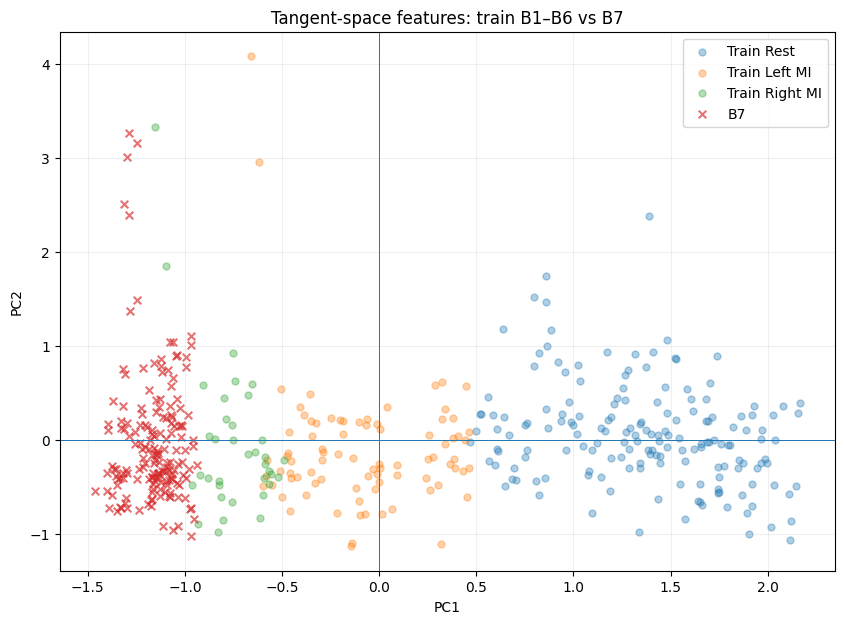

In [100]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Train classes
for cls, name in [
    (1, "Rest"),
    (2, "Left MI"),
    (3, "Right MI")
]:
    mask = (
        (pca_df["source"] == "train") &
        (pca_df["class"] == cls)
    )

    plt.scatter(
        pca_df.loc[mask, "PC1"],
        pca_df.loc[mask, "PC2"],
        alpha=0.35,
        s=25,
        label=f"Train {name}"
    )

# B7
mask_b7 = pca_df["source"] == "B7"

plt.scatter(
    pca_df.loc[mask_b7, "PC1"],
    pca_df.loc[mask_b7, "PC2"],
    alpha=0.65,
    s=30,
    marker="x",
    label="B7"
)

plt.axhline(0, linewidth=0.7)
plt.axvline(0, linewidth=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Tangent-space features: train B1–B6 vs B7")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [101]:
# ============================================
# CANONICAL TRIAL TABLE
# ============================================

trial_table = trial_runs.reset_index(drop=True).copy()

trial_table["trial_pos"] = np.arange(len(trial_table))
trial_table["state"] = trial_table["state"].astype(int)

# Определяем block непосредственно из EEG.Blocks
blocks = []

for row in trial_table.itertuples():
    start = int(row.start)
    end = int(row.end)

    block_values = eeg["Blocks"][start:end].astype(int)

    # наиболее частый block внутри trial
    block = int(
        np.bincount(block_values).argmax()
    )

    blocks.append(block)

trial_table["block"] = blocks

# Порядок колонок
trial_table = trial_table[
    ["trial_pos", "state", "block", "start", "end"]
]

print(trial_table)

print("\nCross-tab:")
print(
    pd.crosstab(
        trial_table["block"],
        trial_table["state"]
    )
)

print("\nTrials per block:")
print(
    trial_table.groupby("block")["trial_pos"].count()
)

    trial_pos  state  block   start     end
0           0      1      1    1629    3876
1           1      3      1    4254    6504
2           2      1      1    6879    9129
3           3      3      1    9501   11751
4           4      1      1   12129   14379
5           5      2      1   14751   17001
6           6      1      1   17379   19626
7           7      2      1   20001   22254
8           8      1      2   22932   25182
9           9      2      2   25557   27807
10         10      1      2   28182   30432
11         11      3      2   30807   33057
12         12      1      2   33432   35682
13         13      2      2   36057   38307
14         14      1      2   38682   40932
15         15      3      2   41307   43557
16         16      1      3   44073   46323
17         17      3      3   46701   48948
18         18      1      3   49323   51573
19         19      3      3   51948   54198
20         20      1      3   54573   56823
21         21      2      3   57

In [102]:
prediction_interval = int(fs * 0.25)

print("Prediction interval:", prediction_interval, "samples")
print("Prediction interval:", prediction_interval / fs, "sec")

Prediction interval: 62 samples
Prediction interval: 0.248 sec


In [103]:
# ============================================================
# CORRECT B1-B6 -> B7 ONLINE-LIKE BENCHMARK
# Используем только canonical trial_table
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# ------------------------------------------------------------
# 1. Build train windows from B1-B6
# ------------------------------------------------------------

train_windows = []
train_labels = []
train_trial_ids = []

for row in trial_table.itertuples():

    block = int(row.block)
    state = int(row.state)

    if block > 6:
        continue

    if state not in [1, 2, 3]:
        continue

    # Центральные 6 секунд trial
    start = int(row.start) + 2 * fs
    end = int(row.start) + 8 * fs

    # 1-second non-overlapping windows
    for w_start in range(start, end, window_samples):

        w_end = w_start + window_samples

        if w_end > end:
            break

        train_windows.append(
            X_filtered[w_start:w_end]
        )

        train_labels.append(state)
        train_trial_ids.append(int(row.trial_pos))


train_windows = np.stack(train_windows)
train_labels = np.asarray(train_labels)
train_trial_ids = np.asarray(train_trial_ids)

print("Train windows:", train_windows.shape)

print(
    "\nTrain class counts:"
)

print(
    pd.Series(train_labels).value_counts().sort_index()
)

print(
    "\nTrain unique trials:",
    len(np.unique(train_trial_ids))
)


# ------------------------------------------------------------
# 2. Build B7 test trials
# ------------------------------------------------------------

b7_trials = trial_table[
    trial_table["block"] == 7
].copy()

print(
    "\nB7 trials:"
)

print(
    b7_trials[
        ["trial_pos", "state", "start", "end"]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 3. Covariance for each train window
# ------------------------------------------------------------

train_covariances = np.stack([
    compute_lw_cov(window)
    for window in train_windows
])

print(
    "\nTrain covariances:",
    train_covariances.shape
)


# ------------------------------------------------------------
# 4. Reference covariance from TRAIN only
# ------------------------------------------------------------

reference_cov = train_covariances.mean(axis=0)

reference_cov = (
    reference_cov + reference_cov.T
) / 2


# ------------------------------------------------------------
# 5. Tangent-space train features
# ------------------------------------------------------------

X_train_features = np.stack([
    tangent_transform(
        cov,
        reference_cov
    )
    for cov in train_covariances
])

print(
    "\nTrain tangent features:",
    X_train_features.shape
)


# ------------------------------------------------------------
# 6. Train scaler + LDA
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_features
)

lda = LinearDiscriminantAnalysis(
    solver="lsqr",
    shrinkage="auto"
)

lda.fit(
    X_train_scaled,
    train_labels
)

print(
    "\nLDA classes:",
    lda.classes_
)


# ------------------------------------------------------------
# 7. Online-like prediction on B7
# ------------------------------------------------------------

y_true_b7 = []
y_pred_b7 = []
probs_b7 = []
trial_ids_b7 = []

for row in b7_trials.itertuples():

    state = int(row.state)
    trial_pos = int(row.trial_pos)

    start = int(row.start) + 2 * fs
    end = int(row.start) + 8 * fs

    # Simulate prediction every 250 ms
    # after the first 1-second window.
    prediction_starts = range(
        start + window_samples - prediction_interval,
        end,
        prediction_interval
    )

    for current_end in prediction_starts:

        window_start = (
            current_end - window_samples
        )

        window_end = current_end

        window = X_filtered[
            window_start:window_end
        ]

        cov = compute_lw_cov(window)

        features = tangent_transform(
            cov,
            reference_cov
        ).reshape(1, -1)

        features_scaled = scaler.transform(
            features
        )

        pred = int(
            lda.predict(features_scaled)[0]
        )

        prob = lda.predict_proba(
            features_scaled
        )[0]

        y_true_b7.append(state)
        y_pred_b7.append(pred)
        probs_b7.append(prob)
        trial_ids_b7.append(trial_pos)


y_true_b7 = np.asarray(y_true_b7)
y_pred_b7 = np.asarray(y_pred_b7)
probs_b7 = np.asarray(probs_b7)
trial_ids_b7 = np.asarray(trial_ids_b7)

print(
    "\nB7 predictions:",
    len(y_pred_b7)
)

print(
    "True class counts:"
)

print(
    pd.Series(y_true_b7).value_counts().sort_index()
)

print(
    "\nPredicted class counts:"
)

print(
    pd.Series(y_pred_b7).value_counts().sort_index()
)

Train windows: (288, 250, 17)

Train class counts:
1    144
2     72
3     72
dtype: int64

Train unique trials: 48

B7 trials:
 trial_pos  state  start    end
        48      1 128427 130677
        49      2 131052 133299
        50      1 133677 135927
        51      3 136299 138552
        52      1 138927 141177
        53      3 141552 143802
        54      1 144174 146424
        55      2 146799 149052

Train covariances: (288, 17, 17)

Train tangent features: (288, 153)

LDA classes: [1 2 3]

B7 predictions: 176
True class counts:
1    88
2    44
3    44
dtype: int64

Predicted class counts:
1    60
2    47
3    69
dtype: int64


In [104]:
# ============================================================
# CORRECT B7 ONLINE-LIKE TEST
# 21 prediction per trial:
# 1.00 s ... 6.00 s, every 250 ms
# ============================================================

y_true_b7 = []
y_pred_b7 = []
probs_b7 = []
trial_ids_b7 = []

for row in b7_trials.itertuples():

    state = int(row.state)
    trial_pos = int(row.trial_pos)

    start = int(row.start) + 2 * fs
    end = int(row.start) + 8 * fs

    # 6-second classification interval.
    # First prediction after a full 1-second window.
    #
    # 250 ms = 62.5 samples.
    # Поэтому используем round(), чтобы получить
    # последовательность 62/63 samples.

    prediction_ends = [
        start + window_samples + round(i * fs * 0.25)
        for i in range(21)
    ]

    # Последний prediction должен заканчиваться ровно
    # на конце 6-секундного участка.
    assert prediction_ends[-1] == end

    for window_end in prediction_ends:

        window_start = (
            window_end - window_samples
        )

        window = X_filtered[
            window_start:window_end
        ]

        # Covariance
        cov = compute_lw_cov(window)

        # Tangent-space features
        features = tangent_transform(
            cov,
            reference_cov
        ).reshape(1, -1)

        # Train-only scaler
        features_scaled = scaler.transform(
            features
        )

        # Prediction
        pred = int(
            lda.predict(features_scaled)[0]
        )

        prob = lda.predict_proba(
            features_scaled
        )[0]

        y_true_b7.append(state)
        y_pred_b7.append(pred)
        probs_b7.append(prob)
        trial_ids_b7.append(trial_pos)


y_true_b7 = np.asarray(y_true_b7)
y_pred_b7 = np.asarray(y_pred_b7)
probs_b7 = np.asarray(probs_b7)
trial_ids_b7 = np.asarray(trial_ids_b7)


# ============================================================
# BASIC CHECK
# ============================================================

print("Total predictions:", len(y_pred_b7))

print(
    "\nPredictions per trial:"
)

print(
    pd.Series(trial_ids_b7).value_counts().sort_index()
)

print(
    "\nTrue class counts:"
)

print(
    pd.Series(y_true_b7)
    .value_counts()
    .sort_index()
)

print(
    "\nPredicted class counts:"
)

print(
    pd.Series(y_pred_b7)
    .value_counts()
    .sort_index()
)


Total predictions: 168

Predictions per trial:
48    21
49    21
50    21
51    21
52    21
53    21
54    21
55    21
dtype: int64

True class counts:
1    84
2    42
3    42
dtype: int64

Predicted class counts:
1    58
2    42
3    68
dtype: int64


In [105]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ============================================================
# GLOBAL METRICS
# ============================================================

cm = confusion_matrix(
    y_true_b7,
    y_pred_b7,
    labels=[1, 2, 3]
)

accuracy = accuracy_score(
    y_true_b7,
    y_pred_b7
)

balanced_acc = balanced_accuracy_score(
    y_true_b7,
    y_pred_b7
)

macro_f1 = f1_score(
    y_true_b7,
    y_pred_b7,
    labels=[1, 2, 3],
    average="macro"
)

print("Confusion matrix:")
print(cm)

print("\nAccuracy:", accuracy)
print("Balanced accuracy:", balanced_acc)
print("Macro F1:", macro_f1)

print("\nClassification report:")
print(
    classification_report(
        y_true_b7,
        y_pred_b7,
        labels=[1, 2, 3],
        target_names=[
            "Rest",
            "Left MI",
            "Right MI"
        ],
        digits=3
    )
)


# ============================================================
# PER-TRIAL METRICS
# ============================================================

trial_results = []

for trial_id in sorted(
    np.unique(trial_ids_b7)
):

    mask = trial_ids_b7 == trial_id

    true_trial = y_true_b7[mask]
    pred_trial = y_pred_b7[mask]

    trial_results.append({
        "trial_pos": trial_id,
        "true_state": int(true_trial[0]),
        "n_predictions": len(pred_trial),
        "accuracy": accuracy_score(
            true_trial,
            pred_trial
        ),
        "pred_rest": np.sum(pred_trial == 1),
        "pred_left": np.sum(pred_trial == 2),
        "pred_right": np.sum(pred_trial == 3)
    })

trial_results = pd.DataFrame(
    trial_results
)

print("\nPer-trial results:")
print(
    trial_results.to_string(index=False)
)

Confusion matrix:
[[45 12 27]
 [ 6 17 19]
 [ 7 13 22]]

Accuracy: 0.5
Balanced accuracy: 0.48809523809523814
Macro F1: 0.479521573887771

Classification report:
              precision    recall  f1-score   support

        Rest      0.776     0.536     0.634        84
     Left MI      0.405     0.405     0.405        42
    Right MI      0.324     0.524     0.400        42

    accuracy                          0.500       168
   macro avg      0.501     0.488     0.480       168
weighted avg      0.570     0.500     0.518       168


Per-trial results:
 trial_pos  true_state  n_predictions  accuracy  pred_rest  pred_left  pred_right
        48           1             21  0.571429         12          4           5
        49           2             21  0.380952          6          8           7
        50           1             21  0.666667         14          0           7
        51           3             21  0.523810          0         10          11
        52           1      

In [106]:
# ============================================================
# MEAN CLASS PROBABILITIES PER B7 TRIAL
# ============================================================

trial_probabilities = []

class_names = {
    1: "Rest",
    2: "Left",
    3: "Right"
}

for trial_id in sorted(
    np.unique(trial_ids_b7)
):

    mask = trial_ids_b7 == trial_id

    true_state = int(
        y_true_b7[mask][0]
    )

    mean_prob = probs_b7[mask].mean(axis=0)

    trial_probabilities.append({
        "trial_pos": trial_id,
        "true_state": class_names[true_state],
        "P(Rest)": mean_prob[0],
        "P(Left)": mean_prob[1],
        "P(Right)": mean_prob[2]
    })

trial_probabilities = pd.DataFrame(
    trial_probabilities
)

print(
    trial_probabilities.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

 trial_pos true_state  P(Rest)  P(Left)  P(Right)
        48       Rest    0.555    0.174     0.271
        49       Left    0.249    0.386     0.365
        50       Rest    0.591    0.086     0.323
        51      Right    0.062    0.403     0.534
        52       Rest    0.535    0.144     0.321
        53      Right    0.216    0.221     0.563
        54       Rest    0.404    0.359     0.237
        55       Left    0.091    0.462     0.447


In [107]:
# ============================================================
# B7: PROBABILITY DYNAMICS WITHIN TRIALS
# ============================================================

# Восстанавливаем временную позицию каждого prediction
prediction_times = []

for trial_id in sorted(np.unique(trial_ids_b7)):

    mask = trial_ids_b7 == trial_id
    n = mask.sum()

    # 1.00, 1.25, ..., 6.00 s
    times = np.array([
        1.0 + i * 0.25
        for i in range(n)
    ])

    prediction_times.extend(times)

prediction_times = np.asarray(prediction_times)

# Проверка
print(
    "Predictions:",
    len(prediction_times)
)

print(
    "Time range:",
    prediction_times.min(),
    "to",
    prediction_times.max()
)


# ============================================================
# Таблица всех prediction
# ============================================================

b7_prob_df = pd.DataFrame({
    "trial_pos": trial_ids_b7,
    "true_state": y_true_b7,
    "time": prediction_times,
    "P_Rest": probs_b7[:, 0],
    "P_Left": probs_b7[:, 1],
    "P_Right": probs_b7[:, 2],
    "prediction": y_pred_b7
})

# Средние вероятности по времени и истинному классу
summary = (
    b7_prob_df
    .groupby(["true_state", "time"])[
        ["P_Rest", "P_Left", "P_Right"]
    ]
    .mean()
    .reset_index()
)

print(
    summary.head(15).to_string(index=False)
)

Predictions: 168
Time range: 1.0 to 6.0
 true_state  time   P_Rest   P_Left  P_Right
          1  1.00 0.651940 0.084163 0.263896
          1  1.25 0.739989 0.048457 0.211553
          1  1.50 0.870612 0.046831 0.082557
          1  1.75 0.895932 0.083094 0.020974
          1  2.00 0.824124 0.128132 0.047744
          1  2.25 0.665950 0.191154 0.142896
          1  2.50 0.430315 0.208047 0.361637
          1  2.75 0.541119 0.268248 0.190633
          1  3.00 0.518830 0.274779 0.206391
          1  3.25 0.590738 0.211698 0.197564
          1  3.50 0.430451 0.357693 0.211855
          1  3.75 0.105427 0.303177 0.591396
          1  4.00 0.097123 0.248221 0.654655
          1  4.25 0.090705 0.216087 0.693208
          1  4.50 0.242383 0.300638 0.456979


In [108]:
# ============================================================
# REST TRIALS: PROBABILITY DYNAMICS INDIVIDUALLY
# ============================================================

rest_trials = (
    b7_prob_df[
        b7_prob_df["true_state"] == 1
    ]
    .pivot(
        index="time",
        columns="trial_pos",
        values="P_Rest"
    )
)

print(
    rest_trials.to_string(
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nMean P(Rest) by time:")
print(
    rest_trials.mean(axis=1).to_string(
        float_format=lambda x: f"{x:.3f}"
    )
)

trial_pos    48    50    52    54
time                             
1.00      0.782 0.792 0.897 0.137
1.25      0.869 0.891 0.986 0.214
1.50      0.947 0.981 0.989 0.566
1.75      0.942 0.980 0.956 0.706
2.00      0.885 0.979 0.937 0.496
2.25      0.581 0.939 0.767 0.377
2.50      0.212 0.942 0.309 0.257
2.75      0.869 0.695 0.362 0.239
3.00      0.835 0.728 0.247 0.266
3.25      0.968 0.869 0.279 0.247
3.50      0.950 0.491 0.196 0.084
3.75      0.182 0.026 0.138 0.075
4.00      0.210 0.015 0.088 0.076
4.25      0.067 0.013 0.131 0.152
4.50      0.152 0.026 0.492 0.300
4.75      0.137 0.045 0.842 0.470
5.00      0.073 0.076 0.869 0.935
5.25      0.142 0.312 0.844 0.837
5.50      0.154 0.752 0.537 0.449
5.75      0.730 0.898 0.106 0.901
6.00      0.960 0.952 0.269 0.707

Mean P(Rest) by time:
time
1.00   0.652
1.25   0.740
1.50   0.871
1.75   0.896
2.00   0.824
2.25   0.666
2.50   0.430
2.75   0.541
3.00   0.519
3.25   0.591
3.50   0.430
3.75   0.105
4.00   0.097
4.25   0.091
4.50   0

In [109]:
# ============================================================
# ВОССТАНАВЛИВАЕМ COVARIANCE MATRICES
# X_filtered уже содержит 17 хороших каналов
# ============================================================

from sklearn.covariance import LedoitWolf

window_samples = 250

def compute_lw_cov(window):
    lw = LedoitWolf()
    lw.fit(window)
    cov = lw.covariance_
    return (cov + cov.T) / 2


# Проверяем размерность
print("X_filtered:", X_filtered.shape)

# ------------------------------------------------------------
# TRAIN: B1-B6, по 6 неперекрывающихся окон на trial
# ------------------------------------------------------------

train_windows = []

for _, row in trial_table[
    trial_table["block"].isin([1, 2, 3, 4, 5, 6])
].iterrows():

    start = int(row["start"] + 2 * fs)

    for w in range(6):
        w_start = start + w * window_samples
        w_end = w_start + window_samples

        window = X_filtered[w_start:w_end]

        assert window.shape == (250, 17)

        train_windows.append(compute_lw_cov(window))

X_train_cov = np.stack(train_windows)


# ------------------------------------------------------------
# B7: 21 перекрывающееся окно на каждый trial
# ------------------------------------------------------------

b7_windows = []

for _, row in trial_table[
    trial_table["block"] == 7
].iterrows():

    start = int(row["start"] + 2 * fs)

    for i in range(21):

        w_end = start + window_samples + round(i * fs * 0.25)
        w_start = w_end - window_samples

        window = X_filtered[w_start:w_end]

        assert window.shape == (250, 17)

        b7_windows.append(compute_lw_cov(window))

X_b7_cov = np.stack(b7_windows)


print("X_train_cov:", X_train_cov.shape)
print("X_b7_cov:   ", X_b7_cov.shape)

X_filtered: (149550, 17)
X_train_cov: (288, 17, 17)
X_b7_cov:    (168, 17, 17)


In [110]:
# ============================================================
# TANGENT-SPACE FEATURES
# ============================================================

tangent_train = np.stack([
    tangent_transform(cov, reference_cov)
    for cov in X_train_cov
])

tangent_b7 = np.stack([
    tangent_transform(cov, reference_cov)
    for cov in X_b7_cov
])

print("tangent_train:", tangent_train.shape)
print("tangent_b7:   ", tangent_b7.shape)

# Проверяем NaN / Inf
print("\nNaN train:", np.isnan(tangent_train).sum())
print("NaN B7:   ", np.isnan(tangent_b7).sum())
print("Inf train:", np.isinf(tangent_train).sum())
print("Inf B7:   ", np.isinf(tangent_b7).sum())

tangent_train: (288, 153)
tangent_b7:    (168, 153)

NaN train: 0
NaN B7:    0
Inf train: 0
Inf B7:    0


In [111]:
# ============================================================
# B7 FEATURE DRIFT: MAHALANOBIS DISTANCE TO TRAIN DISTRIBUTION
# ============================================================

from sklearn.covariance import LedoitWolf

# Стандартизация точно так же, как при обучении LDA
Z_train = scaler.transform(tangent_train)
Z_b7 = scaler.transform(tangent_b7)

# Центр train-распределения
train_mean = Z_train.mean(axis=0)

# Covariance train-признаков
# Ledoit-Wolf здесь нужен из-за 153 признаков и 288 наблюдений
lw_feature = LedoitWolf()
lw_feature.fit(Z_train)

feature_cov = lw_feature.covariance_
feature_cov = (feature_cov + feature_cov.T) / 2

inv_feature_cov = np.linalg.pinv(feature_cov)

# Mahalanobis distance
diff = Z_b7 - train_mean

mahal_b7 = np.sqrt(
    np.einsum(
        "ij,jk,ik->i",
        diff,
        inv_feature_cov,
        diff
    )
)

print("Mahalanobis distance:")
print(f"Mean:   {mahal_b7.mean():.3f}")
print(f"Median: {np.median(mahal_b7):.3f}")
print(f"Std:    {mahal_b7.std():.3f}")
print(f"Min:    {mahal_b7.min():.3f}")
print(f"Max:    {mahal_b7.max():.3f}")


# ------------------------------------------------------------
# Добавляем distance к уже существующей таблице B7
# ------------------------------------------------------------

drift_df = b7_prob_df.copy()
drift_df["Mahalanobis"] = mahal_b7


print("\nMean distance by time:")
print(
    drift_df
    .groupby("time")["Mahalanobis"]
    .mean()
    .to_string(float_format=lambda x: f"{x:.3f}")
)

Mahalanobis distance:
Mean:   12.892
Median: 12.639
Std:    1.696
Min:    9.636
Max:    19.534

Mean distance by time:
time
1.00   12.722
1.25   13.100
1.50   13.064
1.75   13.441
2.00   13.473
2.25   13.776
2.50   14.265
2.75   14.040
3.00   13.240
3.25   12.313
3.50   11.985
3.75   11.769
4.00   12.381
4.25   12.456
4.50   12.627
4.75   12.078
5.00   12.254
5.25   12.640
5.50   12.818
5.75   12.856
6.00   13.431


In [112]:
# ============================================================
# B7: DISTANCE TO EACH TRAIN CLASS
# ============================================================

# Классы в train
train_classes = np.array(y_train)

# Центры классов в standardized tangent-space
class_centers = {}

for cls in [1, 2, 3]:
    class_centers[cls] = Z_train[train_classes == cls].mean(axis=0)

# Евклидово расстояние до центров классов
distances = np.zeros((len(Z_b7), 3))

for j, cls in enumerate([1, 2, 3]):
    distances[:, j] = np.linalg.norm(
        Z_b7 - class_centers[cls],
        axis=1
    )

class_dist_df = b7_prob_df.copy()

class_dist_df["D_Rest"] = distances[:, 0]
class_dist_df["D_Left"] = distances[:, 1]
class_dist_df["D_Right"] = distances[:, 2]

# Ближайший класс по расстоянию
class_dist_df["nearest_class"] = np.array([1, 2, 3])[
    np.argmin(distances, axis=1)
]

print("Mean distance by time:")
print(
    class_dist_df
    .groupby("time")[["D_Rest", "D_Left", "D_Right"]]
    .mean()
    .to_string(float_format=lambda x: f"{x:.3f}")
)

print("\nNearest class counts:")
print(
    pd.crosstab(
        class_dist_df["true_state"],
        class_dist_df["nearest_class"]
    )
)

Mean distance by time:
      D_Rest  D_Left  D_Right
time                         
1.00  15.534  12.188   10.603
1.25  16.053  12.905   11.283
1.50  16.248  13.172   11.538
1.75  16.465  13.440   11.873
2.00  16.676  13.704   12.143
2.25  16.830  13.891   12.431
2.50  17.097  14.180   12.790
2.75  16.831  13.840   12.452
3.00  16.282  13.111   11.614
3.25  15.986  12.676   11.072
3.50  15.678  12.200   10.489
3.75  15.596  12.114   10.392
4.00  15.778  12.326   10.608
4.25  15.877  12.469   10.787
4.50  16.127  12.737   11.170
4.75  15.782  12.303   10.689
5.00  15.599  12.137   10.528
5.25  15.733  12.321   10.746
5.50  15.793  12.459   10.798
5.75  15.913  12.656   10.999
6.00  16.393  13.162   11.655

Nearest class counts:
nearest_class   3
true_state       
1              84
2              42
3              42


In [113]:
# ============================================================
# CLASS GEOMETRY: BLOCK-BY-BLOCK
# ============================================================

# Сначала строим tangent features для всех 56 trial'ов,
# по одному центральному 1-секундному окну на trial.
#
# Это диагностический анализ, НЕ обучение финальной модели.

block_rows = []

for _, row in trial_table.iterrows():

    start = int(row["start"] + 2 * fs)

    # Центральное 1-секундное окно trial
    # 2-8 сек -> берём примерно середину
    w_start = start + 2 * window_samples
    w_end = w_start + window_samples

    window = X_filtered[w_start:w_end]

    cov = compute_lw_cov(window)

    tangent = tangent_transform(cov, reference_cov)

    block_rows.append({
        "trial_pos": int(row["trial_pos"]),
        "block": int(row["block"]),
        "state": int(row["state"]),
        "tangent": tangent
    })

block_df = pd.DataFrame(block_rows)

# Матрица признаков
X_all_trials = np.stack(block_df["tangent"].values)

# Стандартизируем тем же scaler, обученным на B1-B6
Z_all_trials = scaler.transform(X_all_trials)

# Центры train-классов
for cls, name in [(1, "Rest"), (2, "Left"), (3, "Right")]:
    center = class_centers[cls]

    block_df[f"D_{name}"] = np.linalg.norm(
        Z_all_trials - center,
        axis=1
    )

# Сводка по блокам
summary_blocks = (
    block_df
    .groupby("block")[["D_Rest", "D_Left", "D_Right"]]
    .mean()
)

print(summary_blocks.to_string(
    float_format=lambda x: f"{x:.3f}"
))

       D_Rest  D_Left  D_Right
block                         
1      11.655  14.890   16.413
2      13.016  15.210   16.889
3      10.943  12.372   14.410
4      11.254  10.465   12.388
5      13.003  10.405   11.369
6      15.467  12.500   11.885
7      16.282  13.111   11.614


In [114]:
from sklearn.decomposition import PCA

# PCA по всем 56 trial-ам
pca = PCA(n_components=2)
Z_pca = pca.fit_transform(Z_all_trials)

pca_df = block_df.copy()
pca_df["PC1"] = Z_pca[:, 0]
pca_df["PC2"] = Z_pca[:, 1]

print("Explained variance:")
print(
    f"PC1 = {pca.explained_variance_ratio_[0]:.3f}, "
    f"PC2 = {pca.explained_variance_ratio_[1]:.3f}"
)

print("\nMean PC coordinates by block:")
print(
    pca_df
    .groupby("block")[["PC1", "PC2"]]
    .mean()
    .to_string(float_format=lambda x: f"{x:.3f}")
)

print("\nMean PC coordinates by class:")
print(
    pca_df
    .groupby("state")[["PC1", "PC2"]]
    .mean()
    .to_string(float_format=lambda x: f"{x:.3f}")
)

Explained variance:
PC1 = 0.165, PC2 = 0.074

Mean PC coordinates by block:
         PC1    PC2
block              
1     -6.025 -1.565
2     -5.630  3.086
3     -3.524 -0.677
4     -0.643 -0.579
5      2.963 -1.776
6      5.511  0.746
7      7.348  0.764

Mean PC coordinates by class:
         PC1    PC2
state              
1      0.022  0.464
2      0.062  0.023
3     -0.105 -0.950


In [115]:
# ============================================================
# PCA: CLASS × BLOCK
# ============================================================

class_block_pca = (
    pca_df
    .groupby(["block", "state"])[["PC1", "PC2"]]
    .mean()
    .reset_index()
)

print(class_block_pca.to_string(
    index=False,
    float_format=lambda x: f"{x:.3f}"
))

 block  state    PC1    PC2
     1      1 -5.932 -1.921
     1      2 -5.469 -2.094
     1      3 -6.768 -0.326
     2      1 -5.499  1.533
     2      2 -6.406  5.393
     2      3 -5.115  3.886
     3      1 -3.959  0.238
     3      2 -2.223 -1.656
     3      3 -3.954 -1.526
     4      1 -0.785 -0.258
     4      2 -1.443 -0.722
     4      3  0.439 -1.076
     5      1  2.919 -1.642
     5      2  3.840 -0.744
     5      3  2.174 -3.076
     6      1  5.816  3.219
     6      2  4.871 -1.169
     6      3  5.541 -2.283
     7      1  7.592  2.076
     7      2  7.264  1.152
     7      3  6.946 -2.247


In [116]:
from scipy.stats import spearmanr

block_mean_pc1 = (
    pca_df
    .groupby("block")["PC1"]
    .mean()
)

rho, p_value = spearmanr(
    block_mean_pc1.index,
    block_mean_pc1.values
)

print("Block → mean PC1")
print(block_mean_pc1.to_string(float_format=lambda x: f"{x:.3f}"))

print(f"\nSpearman rho = {rho:.3f}")
print(f"p-value      = {p_value:.4g}")

Block → mean PC1
block
1   -6.025
2   -5.630
3   -3.524
4   -0.643
5    2.963
6    5.511
7    7.348

Spearman rho = 1.000
p-value      = 0


In [117]:
from scipy.stats import spearmanr

# Только train B1-B6
train_mask = block_df["block"] <= 6

Z_train_all = Z_all_trials[train_mask.values]
blocks_train = block_df.loc[train_mask, "block"].values

rhos = []

for j in range(Z_train_all.shape[1]):
    rho, _ = spearmanr(blocks_train, Z_train_all[:, j])
    rhos.append(rho)

rhos = np.asarray(rhos)

print("Tangent features:", len(rhos))
print("Median |rho|:", np.median(np.abs(rhos)))
print("Mean |rho|:  ", np.mean(np.abs(rhos)))
print("Max |rho|:   ", np.max(np.abs(rhos)))

print("\nFeatures with |rho| > 0.5:",
      np.sum(np.abs(rhos) > 0.5))

print("Features with |rho| > 0.7:",
      np.sum(np.abs(rhos) > 0.7))

print("Features with |rho| > 0.9:",
      np.sum(np.abs(rhos) > 0.9))

Tangent features: 153
Median |rho|: 0.18139538675113717
Mean |rho|:   0.26735647236935484
Max |rho|:    0.9501243801188205

Features with |rho| > 0.5: 30
Features with |rho| > 0.7: 14
Features with |rho| > 0.9: 4


In [118]:
# ============================================================
# OFFLINE BLOCK DETRENDING
# Trend is estimated ONLY on B1-B6
# ============================================================

from sklearn.linear_model import LinearRegression

# Train: B1-B6
train_mask = block_df["block"].values <= 6
test_mask = block_df["block"].values == 7

X_train = Z_all_trials[train_mask]
X_b7 = Z_all_trials[test_mask]

blocks_train = block_df.loc[train_mask, "block"].values.astype(float)
block_b7 = 7.0

n_features = X_train.shape[1]

# Detrended versions
X_train_dt = np.zeros_like(X_train)
X_b7_dt = np.zeros_like(X_b7)

slopes = np.zeros(n_features)
intercepts = np.zeros(n_features)

for j in range(n_features):

    model = LinearRegression()
    model.fit(
        blocks_train.reshape(-1, 1),
        X_train[:, j]
    )

    slopes[j] = model.coef_[0]
    intercepts[j] = model.intercept_

    # Remove estimated block effect
    X_train_dt[:, j] = (
        X_train[:, j]
        - (slopes[j] * blocks_train + intercepts[j])
    )

    X_b7_dt[:, j] = (
        X_b7[:, j]
        - (slopes[j] * block_b7 + intercepts[j])
    )

print("Original train shape:", X_train.shape)
print("Detrended train shape:", X_train_dt.shape)
print("B7 shape:", X_b7.shape)

print("\nSlope statistics:")
print(f"mean = {slopes.mean():.4f}")
print(f"std  = {slopes.std():.4f}")
print(f"min  = {slopes.min():.4f}")
print(f"max  = {slopes.max():.4f}")

print("\nResidual train mean:")
print(f"mean abs = {np.mean(np.abs(X_train_dt.mean(axis=0))):.6f}")
print(f"max abs  = {np.max(np.abs(X_train_dt.mean(axis=0))):.6f}")

Original train shape: (48, 153)
Detrended train shape: (48, 153)
B7 shape: (8, 153)

Slope statistics:
mean = 0.0088
std  = 0.2127
min  = -0.5588
max  = 0.5762

Residual train mean:
mean abs = 0.000000
max abs  = 0.000000


In [119]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# ============================================================
# DETRENDED CLASSIFICATION
# ============================================================

# Labels
y_train_dt = block_df.loc[train_mask, "state"].values
y_b7 = block_df.loc[test_mask, "state"].values

# Scale using TRAIN ONLY
scaler_dt = StandardScaler()
X_train_dt_scaled = scaler_dt.fit_transform(X_train_dt)
X_b7_dt_scaled = scaler_dt.transform(X_b7_dt)

# LDA
lda_dt = LinearDiscriminantAnalysis(
    solver="lsqr",
    shrinkage="auto"
)

lda_dt.fit(
    X_train_dt_scaled,
    y_train_dt
)

# B7 prediction
y_pred_dt = lda_dt.predict(X_b7_dt_scaled)

# Metrics
cm_dt = confusion_matrix(
    y_b7,
    y_pred_dt,
    labels=[1, 2, 3]
)

macro_recall_dt = balanced_accuracy_score(
    y_b7,
    y_pred_dt
)

macro_f1_dt = f1_score(
    y_b7,
    y_pred_dt,
    labels=[1, 2, 3],
    average="macro"
)

print("=== DETRENDED B7 ===")

print("\nConfusion matrix:")
print(cm_dt)

print(f"\nMacro recall: {macro_recall_dt:.4f}")
print(f"Macro F1:     {macro_f1_dt:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_b7,
        y_pred_dt,
        labels=[1, 2, 3],
        target_names=["Rest", "Left", "Right"],
        digits=3
    )
)

print("\nPrediction counts:")
print(
    pd.Series(y_pred_dt)
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Rest",
        2: "Left",
        3: "Right"
    })
)

=== DETRENDED B7 ===

Confusion matrix:
[[3 0 1]
 [0 0 2]
 [0 0 2]]

Macro recall: 0.5833
Macro F1:     0.4762

Classification report:
              precision    recall  f1-score   support

        Rest      1.000     0.750     0.857         4
        Left      0.000     0.000     0.000         2
       Right      0.400     1.000     0.571         2

    accuracy                          0.625         8
   macro avg      0.467     0.583     0.476         8
weighted avg      0.600     0.625     0.571         8


Prediction counts:
Rest     3
Right    5
dtype: int64


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [120]:
# ============================================================
# DETRENDING: ONLINE-LIKE WINDOWS
# Exactly the same windows as the original B1-B6 -> B7 test
# ============================================================

# We already have:
# X_train_cov  : 288 x 17 x 17
# X_b7_cov     : 168 x 17 x 17
# tangent_train: 288 x 153
# tangent_b7   : 168 x 153

# Standardized features using the ORIGINAL train scaler
Z_train_online = scaler.transform(tangent_train)
Z_b7_online = scaler.transform(tangent_b7)

# ------------------------------------------------------------
# Block labels for each 1-second window
# ------------------------------------------------------------

train_window_blocks = []
train_window_states = []

for _, row in trial_table[trial_table["block"] <= 6].iterrows():

    block = int(row["block"])
    state = int(row["state"])

    for _ in range(6):  # 6 windows per trial
        train_window_blocks.append(block)
        train_window_states.append(state)

train_window_blocks = np.asarray(train_window_blocks, dtype=float)
train_window_states = np.asarray(train_window_states)

# B7: 6 windows/trial × 8 trials × 3.5? 
# Use the actual previously constructed labels if available.
b7_window_blocks = np.full(len(Z_b7_online), 7.0)

b7_window_states = []

for _, row in trial_table[trial_table["block"] == 7].iterrows():
    b7_window_states.extend(
        [int(row["state"])] * 21
    )

b7_window_states = np.asarray(b7_window_states)

print("Train windows:", Z_train_online.shape)
print("B7 windows:  ", Z_b7_online.shape)

print("\nTrain block counts:")
print(pd.Series(train_window_blocks).value_counts().sort_index())

print("\nB7 class counts:")
print(pd.Series(b7_window_states).value_counts().sort_index())

Train windows: (288, 153)
B7 windows:   (168, 153)

Train block counts:
1.0    48
2.0    48
3.0    48
4.0    48
5.0    48
6.0    48
dtype: int64

B7 class counts:
1    84
2    42
3    42
dtype: int64


In [121]:
# ============================================================
# DETRENDING: 288 TRAIN WINDOWS -> 168 B7 WINDOWS
# ============================================================

from sklearn.linear_model import LinearRegression

n_features = Z_train_online.shape[1]

slopes_online = np.zeros(n_features)
intercepts_online = np.zeros(n_features)

Z_train_dt = np.zeros_like(Z_train_online)
Z_b7_dt = np.zeros_like(Z_b7_online)

for j in range(n_features):

    model = LinearRegression()

    model.fit(
        train_window_blocks.reshape(-1, 1),
        Z_train_online[:, j]
    )

    slopes_online[j] = model.coef_[0]
    intercepts_online[j] = model.intercept_

    # Remove estimated block trend from B1-B6
    Z_train_dt[:, j] = (
        Z_train_online[:, j]
        - (
            slopes_online[j] * train_window_blocks
            + intercepts_online[j]
        )
    )

    # Apply TRAIN-ONLY trend to B7
    Z_b7_dt[:, j] = (
        Z_b7_online[:, j]
        - (
            slopes_online[j] * 7.0
            + intercepts_online[j]
        )
    )

print("Detrended train:", Z_train_dt.shape)
print("Detrended B7:   ", Z_b7_dt.shape)

print("\nSlope statistics:")
print(f"mean = {slopes_online.mean():.4f}")
print(f"std  = {slopes_online.std():.4f}")
print(f"min  = {slopes_online.min():.4f}")
print(f"max  = {slopes_online.max():.4f}")

print("\nTrain residual means:")
print(
    f"mean abs = {np.mean(np.abs(Z_train_dt.mean(axis=0))):.6f}"
)
print(
    f"max abs  = {np.max(np.abs(Z_train_dt.mean(axis=0))):.6f}"
)

Detrended train: (288, 153)
Detrended B7:    (168, 153)

Slope statistics:
mean = 0.0063
std  = 0.2039
min  = -0.5413
max  = 0.5518

Train residual means:
mean abs = 0.000000
max abs  = 0.000000


In [122]:
# ============================================================
# DETRENDED ONLINE-LIKE B7 BENCHMARK
# ============================================================

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Labels
y_train_online = train_window_states
y_b7_online = b7_window_states

# LDA — та же конфигурация, что в baseline
lda_dt_online = LinearDiscriminantAnalysis(
    solver="lsqr",
    shrinkage="auto"
)

lda_dt_online.fit(
    Z_train_dt,
    y_train_online
)

# B7 predictions
y_b7_pred_dt = lda_dt_online.predict(Z_b7_dt)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

cm_dt_online = confusion_matrix(
    y_b7_online,
    y_b7_pred_dt,
    labels=[1, 2, 3]
)

macro_recall_dt_online = balanced_accuracy_score(
    y_b7_online,
    y_b7_pred_dt
)

macro_f1_dt_online = f1_score(
    y_b7_online,
    y_b7_pred_dt,
    labels=[1, 2, 3],
    average="macro"
)

accuracy_dt_online = np.mean(
    y_b7_online == y_b7_pred_dt
)

print("=== DETRENDED ONLINE-LIKE B7 ===")

print("\nConfusion matrix:")
print(cm_dt_online)

print(f"\nAccuracy:     {accuracy_dt_online:.4f}")
print(f"Macro recall: {macro_recall_dt_online:.4f}")
print(f"Macro F1:     {macro_f1_dt_online:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_b7_online,
        y_b7_pred_dt,
        labels=[1, 2, 3],
        target_names=["Rest", "Left", "Right"],
        digits=3
    )
)

print("\nPrediction counts:")
print(
    pd.Series(y_b7_pred_dt)
    .value_counts()
    .sort_index()
    .rename(index={
        1: "Rest",
        2: "Left",
        3: "Right"
    })
)

=== DETRENDED ONLINE-LIKE B7 ===

Confusion matrix:
[[69  0 15]
 [12  5 25]
 [15  4 23]]

Accuracy:     0.5774
Macro recall: 0.4960
Macro F1:     0.4669

Classification report:
              precision    recall  f1-score   support

        Rest      0.719     0.821     0.767        84
        Left      0.556     0.119     0.196        42
       Right      0.365     0.548     0.438        42

    accuracy                          0.577       168
   macro avg      0.546     0.496     0.467       168
weighted avg      0.590     0.577     0.542       168


Prediction counts:
Rest     96
Left      9
Right    63
dtype: int64


In [123]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# ============================================================
# LOGISTIC REGRESSION — SAME FEATURES / SAME SPLIT
# ============================================================

lr = LogisticRegression(
    C=1.0,
    max_iter=3000,
    multi_class="auto",
    random_state=42
)

lr.fit(
    Z_train_online,
    y_train_online
)

y_pred_lr = lr.predict(Z_b7_online)

cm_lr = confusion_matrix(
    y_b7_online,
    y_pred_lr,
    labels=[1, 2, 3]
)

accuracy_lr = np.mean(y_b7_online == y_pred_lr)

macro_recall_lr = balanced_accuracy_score(
    y_b7_online,
    y_pred_lr
)

macro_f1_lr = f1_score(
    y_b7_online,
    y_pred_lr,
    labels=[1, 2, 3],
    average="macro"
)

print("=== LOGISTIC REGRESSION ===")
print("\nConfusion matrix:")
print(cm_lr)

print(f"\nAccuracy:     {accuracy_lr:.4f}")
print(f"Macro recall: {macro_recall_lr:.4f}")
print(f"Macro F1:     {macro_f1_lr:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_b7_online,
        y_pred_lr,
        labels=[1, 2, 3],
        target_names=["Rest", "Left", "Right"],
        digits=3
    )
)

=== LOGISTIC REGRESSION ===

Confusion matrix:
[[39 23 22]
 [ 8 20 14]
 [ 5 17 20]]

Accuracy:     0.4702
Macro recall: 0.4722
Macro F1:     0.4579

Classification report:
              precision    recall  f1-score   support

        Rest      0.750     0.464     0.574        84
        Left      0.333     0.476     0.392        42
       Right      0.357     0.476     0.408        42

    accuracy                          0.470       168
   macro avg      0.480     0.472     0.458       168
weighted avg      0.548     0.470     0.487       168



In [124]:
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# ============================================================
# RBF SVM — SAME FEATURES / SAME SPLIT
# ============================================================

svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

svm_rbf.fit(
    Z_train_online,
    y_train_online
)

y_pred_svm = svm_rbf.predict(Z_b7_online)

cm_svm = confusion_matrix(
    y_b7_online,
    y_pred_svm,
    labels=[1, 2, 3]
)

accuracy_svm = np.mean(y_b7_online == y_pred_svm)

macro_recall_svm = balanced_accuracy_score(
    y_b7_online,
    y_pred_svm
)

macro_f1_svm = f1_score(
    y_b7_online,
    y_pred_svm,
    labels=[1, 2, 3],
    average="macro"
)

print("=== RBF SVM ===")
print("\nConfusion matrix:")
print(cm_svm)

print(f"\nAccuracy:     {accuracy_svm:.4f}")
print(f"Macro recall: {macro_recall_svm:.4f}")
print(f"Macro F1:     {macro_f1_svm:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_b7_online,
        y_pred_svm,
        labels=[1, 2, 3],
        target_names=["Rest", "Left", "Right"],
        digits=3
    )
)

=== RBF SVM ===

Confusion matrix:
[[73  9  2]
 [ 7 32  3]
 [18 15  9]]

Accuracy:     0.6786
Macro recall: 0.6151
Macro F1:     0.5922

Classification report:
              precision    recall  f1-score   support

        Rest      0.745     0.869     0.802        84
        Left      0.571     0.762     0.653        42
       Right      0.643     0.214     0.321        42

    accuracy                          0.679       168
   macro avg      0.653     0.615     0.592       168
weighted avg      0.676     0.679     0.645       168



In [125]:
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# ============================================================
# RBF SVM — LEAVE-ONE-TRIAL-OUT WITHIN EACH BLOCK
#
# B1-B6 only
# 8 trials per block
# 6 windows per trial
#
# IMPORTANT:
# scaler is fitted separately inside every fold
# ============================================================

train_trials = trial_table[
    trial_table["block"] <= 6
].copy().reset_index(drop=True)

assert len(train_trials) == 48
assert len(Z_train_online) == 288
assert len(y_train_online) == 288

# 6 windows correspond to each trial
trial_positions = train_trials["trial_pos"].values

# Mapping:
# window 0-5   -> trial 0
# window 6-11  -> trial 1
# ...
window_trial_pos = np.repeat(trial_positions, 6)

all_true = []
all_pred = []

block_results = []

for block in range(1, 7):

    block_trials = train_trials[
        train_trials["block"] == block
    ]

    block_true = []
    block_pred = []

    print(f"\n=== BLOCK {block} ===")

    for _, test_trial in block_trials.iterrows():

        test_trial_pos = test_trial["trial_pos"]

        # ----------------------------------------------------
        # Test = all 6 windows of ONE trial
        # ----------------------------------------------------

        test_mask = (
            window_trial_pos == test_trial_pos
        )

        # Train = all other trials WITHIN THE SAME BLOCK
        train_mask = (
            (window_trial_pos != test_trial_pos)
            &
            np.isin(
                window_trial_pos,
                block_trials["trial_pos"].values
            )
        )

        X_train = Z_train_online[train_mask]
        y_train = y_train_online[train_mask]

        X_test = Z_train_online[test_mask]
        y_test = y_train_online[test_mask]

        # ----------------------------------------------------
        # Scale inside fold
        # ----------------------------------------------------

        scaler_fold = StandardScaler()

        X_train_scaled = scaler_fold.fit_transform(
            X_train
        )

        X_test_scaled = scaler_fold.transform(
            X_test
        )

        # ----------------------------------------------------
        # RBF SVM
        # Используем параметры, которые дали лучший
        # результат на B7 в первоначальном эксперименте
        # ----------------------------------------------------

        model = SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        )

        model.fit(
            X_train_scaled,
            y_train
        )

        pred = model.predict(
            X_test_scaled
        )

        block_true.extend(y_test)
        block_pred.extend(pred)

        all_true.extend(y_test)
        all_pred.extend(pred)

    # --------------------------------------------------------
    # Metrics for this block
    # --------------------------------------------------------

    block_true = np.asarray(block_true)
    block_pred = np.asarray(block_pred)

    block_recall = balanced_accuracy_score(
        block_true,
        block_pred
    )

    block_f1 = f1_score(
        block_true,
        block_pred,
        labels=[1, 2, 3],
        average="macro"
    )

    block_acc = np.mean(
        block_true == block_pred
    )

    block_cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[1, 2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": block_acc,
        "macro_recall": block_recall,
        "macro_f1": block_f1
    })

    print(f"Accuracy:     {block_acc:.4f}")
    print(f"Macro recall: {block_recall:.4f}")
    print(f"Macro F1:     {block_f1:.4f}")
    print("Confusion matrix:")
    print(block_cm)


# ============================================================
# POOLED RESULTS — ALL B1-B6
# ============================================================

all_true = np.asarray(all_true)
all_pred = np.asarray(all_pred)

overall_acc = np.mean(
    all_true == all_pred
)

overall_recall = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_f1 = f1_score(
    all_true,
    all_pred,
    labels=[1, 2, 3],
    average="macro"
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[1, 2, 3]
)

print("\n" + "=" * 60)
print("OVERALL — WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT")
print("=" * 60)

print("\nConfusion matrix:")
print(overall_cm)

print(f"\nAccuracy:     {overall_acc:.4f}")
print(f"Macro recall: {overall_recall:.4f}")
print(f"Macro F1:     {overall_f1:.4f}")

print("\nPer-block results:")

block_results_df = pd.DataFrame(block_results)

print(
    block_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "macro_recall": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")
print(
    block_results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].mean()
)


=== BLOCK 1 ===
Accuracy:     0.4583
Macro recall: 0.3056
Macro F1:     0.2095
Confusion matrix:
[[22  0  2]
 [12  0  0]
 [12  0  0]]

=== BLOCK 2 ===
Accuracy:     0.4583
Macro recall: 0.3056
Macro F1:     0.2126
Confusion matrix:
[[22  0  2]
 [12  0  0]
 [11  1  0]]

=== BLOCK 3 ===
Accuracy:     0.4792
Macro recall: 0.3194
Macro F1:     0.2160
Confusion matrix:
[[23  0  1]
 [12  0  0]
 [12  0  0]]

=== BLOCK 4 ===
Accuracy:     0.5000
Macro recall: 0.3333
Macro F1:     0.2222
Confusion matrix:
[[24  0  0]
 [12  0  0]
 [12  0  0]]

=== BLOCK 5 ===
Accuracy:     0.4375
Macro recall: 0.2917
Macro F1:     0.2090
Confusion matrix:
[[21  0  3]
 [12  0  0]
 [10  2  0]]

=== BLOCK 6 ===
Accuracy:     0.4583
Macro recall: 0.3056
Macro F1:     0.2126
Confusion matrix:
[[22  1  1]
 [11  0  1]
 [12  0  0]]

OVERALL — WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT

Confusion matrix:
[[134   1   9]
 [ 71   0   1]
 [ 69   3   0]]

Accuracy:     0.4653
Macro recall: 0.3102
Macro F1:     0.2137

Per-block result

In [126]:
from mne.decoding import CSP
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)
import numpy as np
import pandas as pd

# ============================================================
# CSP + RBF SVM
# WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT CV
#
# B1-B6
# 8 trials/block
# 6 windows/trial
#
# CSP is fitted INSIDE each fold -> no leakage
# ============================================================

# ------------------------------------------------------------
# 1. Подготовка данных
# ------------------------------------------------------------

train_trials = trial_table[
    trial_table["block"] <= 6
].copy().reset_index(drop=True)

assert len(train_trials) == 48

# X_train_windows:
# 288 × 250 × 17
#
# предполагается:
# Z_train_online — tangent features
# X_train_windows — исходные EEG окна
#
# Если переменная называется иначе, проверим ниже.

print("train_trials:", len(train_trials))

# Проверяем наличие исходных EEG окон
try:
    X_train_windows
    print("X_train_windows:", X_train_windows.shape)
except NameError:
    print(
        "\nПеременная X_train_windows не найдена."
        "\nНужно будет восстановить её из X_filtered."
    )
    raise


# ------------------------------------------------------------
# 2. Labels и mapping trial -> 6 windows
# ------------------------------------------------------------

y_windows = np.repeat(
    train_trials["state"].values,
    6
).astype(int)

trial_ids = np.repeat(
    train_trials["trial_pos"].values,
    6
)

assert X_train_windows.shape[0] == 288
assert len(y_windows) == 288
assert len(trial_ids) == 288


# ------------------------------------------------------------
# 3. Leave-one-trial-out внутри каждого блока
# ------------------------------------------------------------

all_true = []
all_pred = []

block_results = []

for block in range(1, 7):

    block_trials = train_trials[
        train_trials["block"] == block
    ]

    block_true = []
    block_pred = []

    print(f"\n{'='*60}")
    print(f"BLOCK {block}")
    print(f"{'='*60}")

    for _, test_trial in block_trials.iterrows():

        test_trial_pos = int(
            test_trial["trial_pos"]
        )

        # ----------------------------------------------------
        # Test = один целый trial = 6 окон
        # ----------------------------------------------------

        test_mask = (
            trial_ids == test_trial_pos
        )

        # ----------------------------------------------------
        # Train = остальные trials этого же блока
        # ----------------------------------------------------

        train_mask = (
            (trial_ids != test_trial_pos)
            &
            np.isin(
                trial_ids,
                block_trials["trial_pos"].values
            )
        )

        X_train = X_train_windows[train_mask]
        y_train = y_windows[train_mask]

        X_test = X_train_windows[test_mask]
        y_test = y_windows[test_mask]

        # ----------------------------------------------------
        # CSP
        #
        # MNE expects:
        # n_trials × n_channels × n_times
        # ----------------------------------------------------

        X_train_csp = X_train.transpose(
            0, 2, 1
        )

        X_test_csp = X_test.transpose(
            0, 2, 1
        )

        csp = CSP(
            n_components=6,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False
        )

        X_train_features = csp.fit_transform(
            X_train_csp,
            y_train
        )

        X_test_features = csp.transform(
            X_test_csp
        )

        # ----------------------------------------------------
        # Standardization — TRAIN ONLY
        # ----------------------------------------------------

        scaler_fold = StandardScaler()

        X_train_scaled = (
            scaler_fold.fit_transform(
                X_train_features
            )
        )

        X_test_scaled = (
            scaler_fold.transform(
                X_test_features
            )
        )

        # ----------------------------------------------------
        # RBF SVM
        # ----------------------------------------------------

        svm = SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            random_state=42
        )

        svm.fit(
            X_train_scaled,
            y_train
        )

        pred = svm.predict(
            X_test_scaled
        )

        block_true.extend(y_test)
        block_pred.extend(pred)

        all_true.extend(y_test)
        all_pred.extend(pred)

    # --------------------------------------------------------
    # Metrics for block
    # --------------------------------------------------------

    block_true = np.asarray(block_true)
    block_pred = np.asarray(block_pred)

    acc = np.mean(
        block_true == block_pred
    )

    macro_recall = balanced_accuracy_score(
        block_true,
        block_pred
    )

    macro_f1 = f1_score(
        block_true,
        block_pred,
        labels=[1, 2, 3],
        average="macro"
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[1, 2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro recall: {macro_recall:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# 4. Overall B1-B6
# ============================================================

all_true = np.asarray(all_true)
all_pred = np.asarray(all_pred)

overall_acc = np.mean(
    all_true == all_pred
)

overall_recall = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_f1 = f1_score(
    all_true,
    all_pred,
    labels=[1, 2, 3],
    average="macro"
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[1, 2, 3]
)

print("\n" + "="*60)
print("OVERALL — CSP + RBF SVM")
print("WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT")
print("="*60)

print("\nConfusion matrix:")
print(overall_cm)

print(f"\nAccuracy:     {overall_acc:.4f}")
print(f"Macro recall: {overall_recall:.4f}")
print(f"Macro F1:     {overall_f1:.4f}")


# ============================================================
# 5. Per-block table
# ============================================================

block_results_df = pd.DataFrame(
    block_results
)

print("\nPer-block results:")

print(
    block_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "macro_recall": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    block_results_df[
        ["accuracy", "macro_recall", "macro_f1"]
    ].mean()
)

train_trials: 48
X_train_windows: (288, 250, 17)

BLOCK 1
Computing rank from data with rank=None
    Using tolerance 3.2e+06 (2.2e-16 eps * 17 dim * 8.5e+20  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 3.2e+06 (2.2e-16 eps * 17 dim * 8.5e+20  max singular value)
    Estimated rank (data): 17
    data: rank 17 computed from 17 data channels with 0 projectors
Reducing data rank from 17 -> 17
Estimating class=1 covariance using LEDOIT_WOLF
Done.
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
Computing rank from data with rank=None
    Using tolerance 3.2e+06 (2.2e-16 eps * 17 dim * 8.5e+20  max singular va

In [127]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# ============================================================
# SMALL EEGNET
# GROUP-AWARE WITHIN-BLOCK CV
#
# B1-B6
# 8 trials per block
# 6 windows per trial
#
# One whole trial = one group
# EEGNet is fitted from scratch in every fold
# ============================================================

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# 2. Prepare trials
# ------------------------------------------------------------

train_trials = trial_table[
    trial_table["block"] <= 6
].copy().reset_index(drop=True)

assert len(train_trials) == 48
assert X_train_windows.shape == (288, 250, 17)

# 6 windows per trial
trial_ids = np.repeat(
    train_trials["trial_pos"].values,
    6
)

y_windows = np.repeat(
    train_trials["state"].values,
    6
).astype(int)

assert len(trial_ids) == 288
assert len(y_windows) == 288


# ------------------------------------------------------------
# 3. EEGNet
# ------------------------------------------------------------

class SmallEEGNet(nn.Module):

    def __init__(
        self,
        n_channels=17,
        n_times=250,
        n_classes=3,
        F1=4,
        D=2,
        F2=8,
        dropout=0.25
    ):
        super().__init__()

        # Temporal convolution
        self.temporal = nn.Conv2d(
            1,
            F1,
            kernel_size=(1, 32),
            padding=(0, 16),
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(F1)

        # Depthwise spatial convolution
        self.spatial = nn.Conv2d(
            F1,
            F1 * D,
            kernel_size=(n_channels, 1),
            groups=F1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(F1 * D)

        self.act = nn.ELU()

        self.pool1 = nn.AvgPool2d(
            kernel_size=(1, 4)
        )

        self.drop1 = nn.Dropout(
            dropout
        )

        # Separable convolution
        self.depthwise = nn.Conv2d(
            F1 * D,
            F1 * D,
            kernel_size=(1, 16),
            padding=(0, 8),
            groups=F1 * D,
            bias=False
        )

        self.pointwise = nn.Conv2d(
            F1 * D,
            F2,
            kernel_size=(1, 1),
            bias=False
        )

        self.bn3 = nn.BatchNorm2d(F2)

        self.pool2 = nn.AvgPool2d(
            kernel_size=(1, 4)
        )

        self.drop2 = nn.Dropout(
            dropout
        )

        # Determine classifier size automatically
        with torch.no_grad():

            dummy = torch.zeros(
                1,
                1,
                n_channels,
                n_times
            )

            z = self._features(dummy)

            n_features = z.flatten(1).shape[1]

        self.classifier = nn.Linear(
            n_features,
            n_classes
        )

    def _features(self, x):

        x = self.temporal(x)
        x = self.bn1(x)

        x = self.spatial(x)
        x = self.bn2(x)
        x = self.act(x)

        x = self.pool1(x)
        x = self.drop1(x)

        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.bn3(x)
        x = self.act(x)

        x = self.pool2(x)
        x = self.drop2(x)

        return x

    def forward(self, x):

        x = self._features(x)

        x = x.flatten(1)

        return self.classifier(x)


# ------------------------------------------------------------
# 4. Training function
# ------------------------------------------------------------

def train_eegnet(
    X_train,
    y_train,
    X_test,
    n_epochs=80,
    batch_size=16,
    lr=1e-3
):

    # --------------------------------------------------------
    # Convert labels:
    # Rest 1 -> 0
    # Left 2 -> 1
    # Right 3 -> 2
    # --------------------------------------------------------

    label_map = {
        1: 0,
        2: 1,
        3: 2
    }

    y_train_encoded = np.array([
        label_map[y]
        for y in y_train
    ])

    # --------------------------------------------------------
    # EEGNet input:
    #
    # batch × 1 × channels × time
    # --------------------------------------------------------

    X_train_tensor = torch.tensor(
        X_train.transpose(0, 2, 1),
        dtype=torch.float32
    ).unsqueeze(1)

    X_test_tensor = torch.tensor(
        X_test.transpose(0, 2, 1),
        dtype=torch.float32
    ).unsqueeze(1)

    y_train_tensor = torch.tensor(
        y_train_encoded,
        dtype=torch.long
    )

    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    model = SmallEEGNet(
        n_channels=X_train.shape[2],
        n_times=X_train.shape[1]
    ).to(device)

    # --------------------------------------------------------
    # Class-weighted loss
    #
    # Train folds have:
    # Rest = 4 trials
    # Left = 2 trials
    # Right = 2 trials
    #
    # This compensates for class imbalance.
    # --------------------------------------------------------

    counts = np.bincount(
        y_train_encoded,
        minlength=3
    )

    weights = (
        len(y_train_encoded)
        /
        (3 * counts)
    )

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    model.train()

    for epoch in range(n_epochs):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            loss = criterion(
                logits,
                yb
            )

            loss.backward()

            optimizer.step()

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        X_test_tensor = X_test_tensor.to(
            device
        )

        logits = model(
            X_test_tensor
        )

        pred_encoded = (
            torch.argmax(
                logits,
                dim=1
            )
            .cpu()
            .numpy()
        )

    # Convert back:
    # 0 -> Rest
    # 1 -> Left
    # 2 -> Right

    inverse_map = {
        0: 1,
        1: 2,
        2: 3
    }

    predictions = np.array([
        inverse_map[p]
        for p in pred_encoded
    ])

    return predictions


# ------------------------------------------------------------
# 5. Leave-one-trial-out within each block
# ------------------------------------------------------------

all_true = []
all_pred = []

block_results = []

for block in range(1, 7):

    block_trials = train_trials[
        train_trials["block"] == block
    ]

    block_true = []
    block_pred = []

    print(f"\n{'='*60}")
    print(f"BLOCK {block}")
    print(f"{'='*60}")

    for _, test_trial in block_trials.iterrows():

        test_trial_pos = int(
            test_trial["trial_pos"]
        )

        # Test = one whole trial
        test_mask = (
            trial_ids == test_trial_pos
        )

        # Train = other trials in same block
        train_mask = (
            (trial_ids != test_trial_pos)
            &
            np.isin(
                trial_ids,
                block_trials["trial_pos"].values
            )
        )

        X_train = X_train_windows[
            train_mask
        ]

        y_train = y_windows[
            train_mask
        ]

        X_test = X_train_windows[
            test_mask
        ]

        y_test = y_windows[
            test_mask
        ]

        # ----------------------------------------------------
        # Train fresh EEGNet
        # ----------------------------------------------------

        pred = train_eegnet(
            X_train,
            y_train,
            X_test,
            n_epochs=80
        )

        block_true.extend(y_test)
        block_pred.extend(pred)

        all_true.extend(y_test)
        all_pred.extend(pred)

    # --------------------------------------------------------
    # Block metrics
    # --------------------------------------------------------

    block_true = np.asarray(
        block_true
    )

    block_pred = np.asarray(
        block_pred
    )

    acc = np.mean(
        block_true == block_pred
    )

    macro_recall = balanced_accuracy_score(
        block_true,
        block_pred
    )

    macro_f1 = f1_score(
        block_true,
        block_pred,
        labels=[1, 2, 3],
        average="macro"
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[1, 2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro recall: {macro_recall:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# 6. Overall results
# ============================================================

all_true = np.asarray(
    all_true
)

all_pred = np.asarray(
    all_pred
)

overall_acc = np.mean(
    all_true == all_pred
)

overall_recall = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_f1 = f1_score(
    all_true,
    all_pred,
    labels=[1, 2, 3],
    average="macro"
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[1, 2, 3]
)

print("\n" + "="*60)
print("OVERALL — EEGNET")
print("WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT")
print("="*60)

print("\nConfusion matrix:")
print(overall_cm)

print(f"\nAccuracy:     {overall_acc:.4f}")
print(f"Macro recall: {overall_recall:.4f}")
print(f"Macro F1:     {overall_f1:.4f}")


# ============================================================
# 7. Per-block table
# ============================================================

block_results_df = pd.DataFrame(
    block_results
)

print("\nPer-block results:")

print(
    block_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "macro_recall": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    block_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1"
        ]
    ].mean()
)

Device: cuda

BLOCK 1
Accuracy:     0.4792
Macro recall: 0.4167
Macro F1:     0.3928

Confusion matrix:
[[16  4  4]
 [ 0  7  5]
 [ 6  6  0]]

BLOCK 2
Accuracy:     0.4583
Macro recall: 0.3056
Macro F1:     0.3121

Confusion matrix:
[[22  0  2]
 [ 0  0 12]
 [ 1 11  0]]

BLOCK 3
Accuracy:     0.3542
Macro recall: 0.2361
Macro F1:     0.2636

Confusion matrix:
[[17  4  3]
 [ 2  0 10]
 [ 0 12  0]]

BLOCK 4
Accuracy:     0.4792
Macro recall: 0.4306
Macro F1:     0.4331

Confusion matrix:
[[15  6  3]
 [ 2  2  8]
 [ 0  6  6]]

BLOCK 5
Accuracy:     0.3125
Macro recall: 0.2778
Macro F1:     0.2964

Confusion matrix:
[[10 10  4]
 [10  0  2]
 [ 0  7  5]]

BLOCK 6
Accuracy:     0.3542
Macro recall: 0.2917
Macro F1:     0.2914

Confusion matrix:
[[13  6  5]
 [10  2  0]
 [ 4  6  2]]

OVERALL — EEGNET
WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT

Confusion matrix:
[[93 30 21]
 [24 11 37]
 [11 48 13]]

Accuracy:     0.4062
Macro recall: 0.3264
Macro F1:     0.3341

Per-block results:
 block accuracy macro_recall

In [128]:
# ============================================================
# BINARY LEFT vs RIGHT
# Riemannian tangent features + RBF SVM
# Within-block leave-one-trial-out CV
#
# Rest is completely excluded
# Left  = state 2
# Right = state 3
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from sklearn.covariance import LedoitWolf
from scipy.linalg import logm


# ------------------------------------------------------------
# 1. Select only Left / Right trials
# ------------------------------------------------------------

binary_trials = trial_table[
    (trial_table["block"] <= 6) &
    (trial_table["state"].isin([2, 3]))
].copy().reset_index(drop=True)

print("Number of trials:", len(binary_trials))

print("\nTrials per block:")
print(
    binary_trials.groupby(
        ["block", "state"]
    ).size().unstack(fill_value=0)
)


# ------------------------------------------------------------
# 2. Get 6 windows per trial
# ------------------------------------------------------------

binary_trial_ids = np.repeat(
    binary_trials["trial_pos"].values,
    6
)

binary_y = np.repeat(
    binary_trials["state"].values,
    6
).astype(int)

# Find corresponding windows in the original dataset
binary_mask = np.isin(
    trial_ids,
    binary_trials["trial_pos"].values
)

X_binary = X_train_windows[
    binary_mask
]

y_binary = y_windows[
    binary_mask
]

assert X_binary.shape == (
    144,
    250,
    17
)

print("\nX shape:", X_binary.shape)
print("y shape:", y_binary.shape)


# ------------------------------------------------------------
# 3. Covariance
# ------------------------------------------------------------

def compute_lw_cov(window):

    lw = LedoitWolf()
    lw.fit(window)

    cov = lw.covariance_

    return (
        cov + cov.T
    ) / 2


# ------------------------------------------------------------
# 4. Tangent representation
# ------------------------------------------------------------

def tangent_features(
    cov,
    reference_cov
):

    # Whitening by reference covariance
    eigvals, eigvecs = np.linalg.eigh(
        reference_cov
    )

    eigvals = np.maximum(
        eigvals,
        1e-10
    )

    ref_inv_sqrt = (
        eigvecs
        @ np.diag(
            1 / np.sqrt(eigvals)
        )
        @ eigvecs.T
    )

    whitened = (
        ref_inv_sqrt
        @ cov
        @ ref_inv_sqrt
    )

    whitened = (
        whitened
        + whitened.T
    ) / 2

    # Matrix logarithm
    log_cov = logm(
        whitened
    ).real

    # Upper triangle including diagonal
    idx = np.triu_indices(
        log_cov.shape[0]
    )

    return log_cov[idx]


# ------------------------------------------------------------
# 5. Prepare covariance for every window
# ------------------------------------------------------------

all_cov = np.stack([
    compute_lw_cov(x)
    for x in X_binary
])

print("\nCovariances:", all_cov.shape)


# ------------------------------------------------------------
# 6. Leave-one-trial-out within each block
# ------------------------------------------------------------

all_true = []
all_pred = []

block_results = []

for block in range(1, 7):

    block_trial_ids = binary_trials[
        binary_trials["block"] == block
    ]["trial_pos"].values

    block_true = []
    block_pred = []

    print("\n" + "=" * 60)
    print(f"BLOCK {block}")
    print("=" * 60)

    for test_trial in block_trial_ids:

        # ----------------------------------------------------
        # Test = one complete trial
        # ----------------------------------------------------

        test_mask = (
            binary_trial_ids == test_trial
        )

        # ----------------------------------------------------
        # Train = all other trials in this block
        # ----------------------------------------------------

        train_mask = (
            np.isin(
                binary_trial_ids,
                block_trial_ids
            )
            &
            (binary_trial_ids != test_trial)
        )

        X_cov_train = all_cov[
            train_mask
        ]

        X_cov_test = all_cov[
            test_mask
        ]

        y_train = y_binary[
            train_mask
        ]

        y_test = y_binary[
            test_mask
        ]

        # ----------------------------------------------------
        # Reference covariance:
        # TRAIN ONLY
        # ----------------------------------------------------

        reference_cov = np.mean(
            X_cov_train,
            axis=0
        )

        reference_cov = (
            reference_cov
            + reference_cov.T
        ) / 2

        # ----------------------------------------------------
        # Tangent features
        # ----------------------------------------------------

        X_tangent_train = np.stack([
            tangent_features(
                cov,
                reference_cov
            )
            for cov in X_cov_train
        ])

        X_tangent_test = np.stack([
            tangent_features(
                cov,
                reference_cov
            )
            for cov in X_cov_test
        ])

        # ----------------------------------------------------
        # Scaling TRAIN ONLY
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_tangent_train = scaler.fit_transform(
            X_tangent_train
        )

        X_tangent_test = scaler.transform(
            X_tangent_test
        )

        # ----------------------------------------------------
        # RBF SVM
        # ----------------------------------------------------

        model = SVC(
            C=1.0,
            gamma="scale",
            kernel="rbf"
        )

        model.fit(
            X_tangent_train,
            y_train
        )

        pred = model.predict(
            X_tangent_test
        )

        block_true.extend(
            y_test
        )

        block_pred.extend(
            pred
        )

        all_true.extend(
            y_test
        )

        all_pred.extend(
            pred
        )

    # --------------------------------------------------------
    # Block metrics
    # --------------------------------------------------------

    block_true = np.asarray(
        block_true
    )

    block_pred = np.asarray(
        block_pred
    )

    acc = accuracy_score(
        block_true,
        block_pred
    )

    balanced_acc = balanced_accuracy_score(
        block_true,
        block_pred
    )

    f1 = f1_score(
        block_true,
        block_pred,
        average="macro"
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": acc,
        "balanced_accuracy": balanced_acc,
        "macro_f1": f1
    })

    print(
        f"Accuracy:          {acc:.4f}"
    )

    print(
        f"Balanced accuracy: {balanced_acc:.4f}"
    )

    print(
        f"Macro F1:          {f1:.4f}"
    )

    print("\nConfusion matrix")
    print(
        "          Pred Left  Pred Right"
    )
    print(
        f"True Left   {cm[0,0]:9d} {cm[0,1]:11d}"
    )
    print(
        f"True Right  {cm[1,0]:9d} {cm[1,1]:11d}"
    )


# ============================================================
# 7. Overall
# ============================================================

all_true = np.asarray(
    all_true
)

all_pred = np.asarray(
    all_pred
)

overall_acc = accuracy_score(
    all_true,
    all_pred
)

overall_balanced_acc = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_f1 = f1_score(
    all_true,
    all_pred,
    average="macro"
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[2, 3]
)

print("\n" + "=" * 60)
print("OVERALL — LEFT vs RIGHT")
print("=" * 60)

print("\nConfusion matrix:")
print(
    "          Pred Left  Pred Right"
)

print(
    f"True Left   {overall_cm[0,0]:9d} "
    f"{overall_cm[0,1]:11d}"
)

print(
    f"True Right  {overall_cm[1,0]:9d} "
    f"{overall_cm[1,1]:11d}"
)

print(
    f"\nAccuracy:          {overall_acc:.4f}"
)

print(
    f"Balanced accuracy: {overall_balanced_acc:.4f}"
)

print(
    f"Macro F1:          {overall_f1:.4f}"
)


# ============================================================
# 8. Per-block table
# ============================================================

block_results_df = pd.DataFrame(
    block_results
)

print("\nPer-block results:")
print(
    block_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "balanced_accuracy": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    block_results_df[
        [
            "accuracy",
            "balanced_accuracy",
            "macro_f1"
        ]
    ].mean()
)

Number of trials: 24

Trials per block:
state  2  3
block      
1      2  2
2      2  2
3      2  2
4      2  2
5      2  2
6      2  2

X shape: (144, 250, 17)
y shape: (144,)

Covariances: (144, 17, 17)

BLOCK 1
Accuracy:          0.0000
Balanced accuracy: 0.0000
Macro F1:          0.0000

Confusion matrix
          Pred Left  Pred Right
True Left           0          12
True Right         12           0

BLOCK 2
Accuracy:          0.0000
Balanced accuracy: 0.0000
Macro F1:          0.0000

Confusion matrix
          Pred Left  Pred Right
True Left           0          12
True Right         12           0

BLOCK 3
Accuracy:          0.0000
Balanced accuracy: 0.0000
Macro F1:          0.0000

Confusion matrix
          Pred Left  Pred Right
True Left           0          12
True Right         12           0

BLOCK 4
Accuracy:          0.0000
Balanced accuracy: 0.0000
Macro F1:          0.0000

Confusion matrix
          Pred Left  Pred Right
True Left           0          12
True Righ

In [129]:
# ============================================================
# CHECK: X / y / trial alignment for binary Left vs Right
# ============================================================

print("Original training windows:")
print("X_train_windows:", X_train_windows.shape)
print("trial_ids:", trial_ids.shape)
print("y_windows:", y_windows.shape)

print("\nBinary trials:")
print(
    binary_trials[
        ["trial_pos", "block", "state"]
    ].head(12).to_string(index=False)
)

print("\nFirst 30 binary window labels:")
print(y_binary[:30])

print("\nFirst 30 binary trial IDs:")
print(binary_trial_ids[:30])

# ------------------------------------------------------------
# Check every trial
# ------------------------------------------------------------

alignment_rows = []

for trial_pos in binary_trials["trial_pos"]:

    original_mask = (
        trial_ids == trial_pos
    )

    binary_mask_local = (
        binary_trial_ids == trial_pos
    )

    original_y = y_windows[
        original_mask
    ]

    binary_y_local = y_binary[
        binary_mask_local
    ]

    expected_state = int(
        binary_trials.loc[
            binary_trials["trial_pos"] == trial_pos,
            "state"
        ].iloc[0]
    )

    alignment_rows.append({
        "trial_pos": int(trial_pos),
        "expected_state": expected_state,
        "original_n": len(original_y),
        "binary_n": len(binary_y_local),
        "original_unique": np.unique(original_y).tolist(),
        "binary_unique": np.unique(binary_y_local).tolist(),
        "original_correct": np.all(
            original_y == expected_state
        ),
        "binary_correct": np.all(
            binary_y_local == expected_state
        )
    })

alignment_df = pd.DataFrame(
    alignment_rows
)

print("\nAlignment check:")
print(
    alignment_df.to_string(index=False)
)

print(
    "\nAll original labels correct:",
    alignment_df["original_correct"].all()
)

print(
    "All binary labels correct:",
    alignment_df["binary_correct"].all()
)

Original training windows:
X_train_windows: (288, 250, 17)
trial_ids: (288,)
y_windows: (288,)

Binary trials:
 trial_pos  block  state
         1      1      3
         3      1      3
         5      1      2
         7      1      2
         9      2      2
        11      2      3
        13      2      2
        15      2      3
        17      3      3
        19      3      3
        21      3      2
        23      3      2

First 30 binary window labels:
[3 3 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]

First 30 binary trial IDs:
[1 1 1 1 1 1 3 3 3 3 3 3 5 5 5 5 5 5 7 7 7 7 7 7 9 9 9 9 9 9]

Alignment check:
 trial_pos  expected_state  original_n  binary_n original_unique binary_unique  original_correct  binary_correct
         1               3           6         6             [3]           [3]              True            True
         3               3           6         6             [3]           [3]              True            True
         5             

In [130]:
# ============================================================
# SANITY CHECK
# Can Riemannian + RBF SVM separate Left vs Right
# on the SAME data it was trained on?
# ============================================================

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# ------------------------------------------------------------
# Use ALL Left/Right data
# ------------------------------------------------------------

X_cov_all = all_cov
y_all = y_binary

# ------------------------------------------------------------
# Reference covariance from ALL data
# ------------------------------------------------------------

reference_cov_all = np.mean(
    X_cov_all,
    axis=0
)

reference_cov_all = (
    reference_cov_all
    + reference_cov_all.T
) / 2

# ------------------------------------------------------------
# Tangent features
# ------------------------------------------------------------

X_tangent_all = np.stack([
    tangent_features(
        cov,
        reference_cov_all
    )
    for cov in X_cov_all
])

print("Tangent features:", X_tangent_all.shape)

# ------------------------------------------------------------
# Scaling
# ------------------------------------------------------------

scaler_all = StandardScaler()

X_scaled_all = scaler_all.fit_transform(
    X_tangent_all
)

# ------------------------------------------------------------
# Train SVM
# ------------------------------------------------------------

svm_all = SVC(
    C=1.0,
    gamma="scale",
    kernel="rbf"
)

svm_all.fit(
    X_scaled_all,
    y_all
)

pred_all = svm_all.predict(
    X_scaled_all
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

print("\nTraining sanity check")

print(
    "Accuracy:",
    accuracy_score(
        y_all,
        pred_all
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        y_all,
        pred_all
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_all,
        pred_all,
        labels=[2, 3]
    )
)

print("\nPredicted counts:")
print(
    pd.Series(pred_all).value_counts().sort_index()
)

print("\nTrue counts:")
print(
    pd.Series(y_all).value_counts().sort_index()
)

Tangent features: (144, 153)

Training sanity check
Accuracy: 0.9930555555555556
Balanced accuracy: 0.9930555555555556

Confusion matrix:
[[71  1]
 [ 0 72]]

Predicted counts:
2    71
3    73
dtype: int64

True counts:
2    72
3    72
dtype: int64


Explained variance: [0.13819874 0.06803102]
Total: 0.20622976202087284


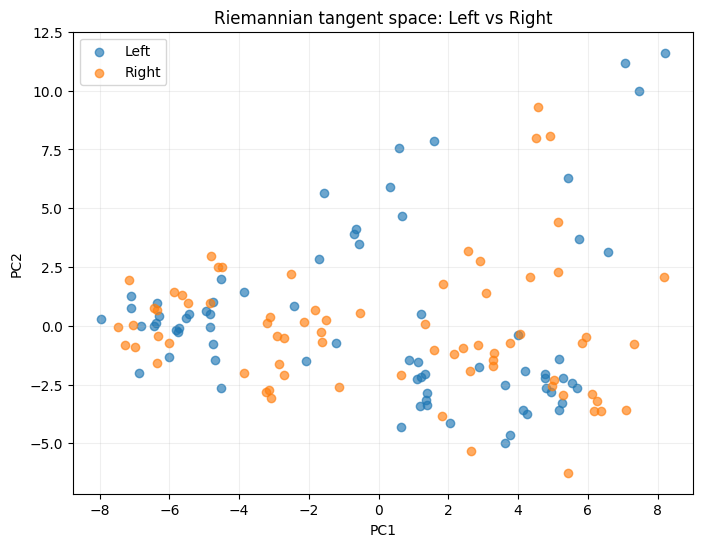

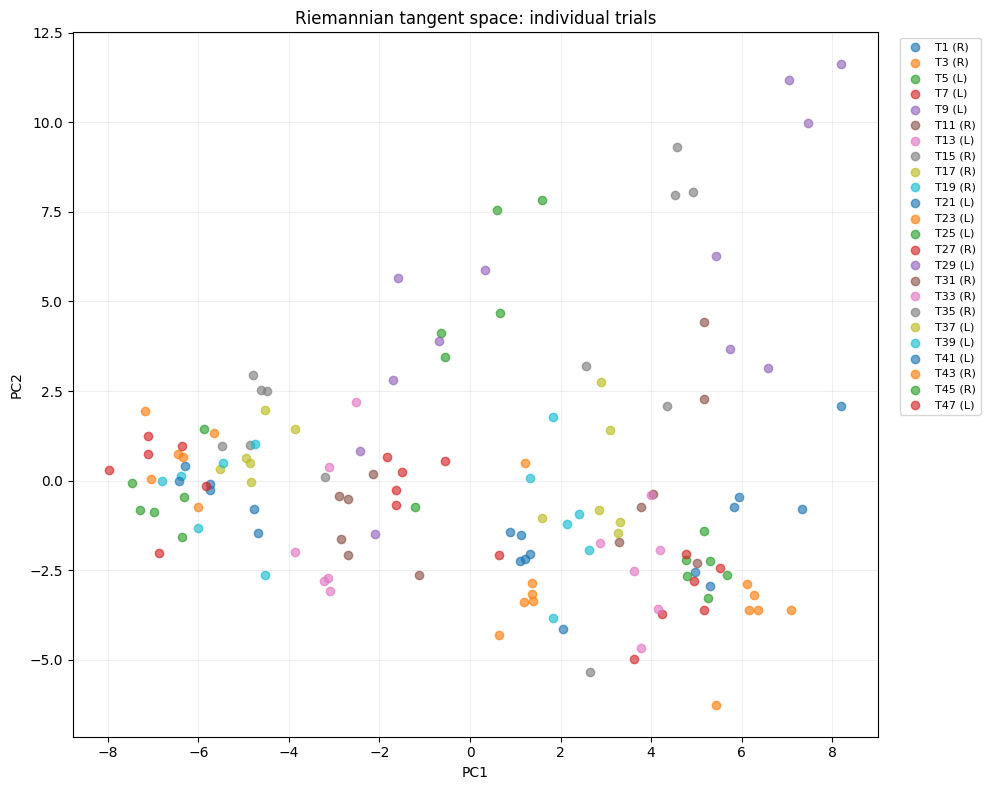

In [131]:
# ============================================================
# TRIAL vs CLASS GEOMETRY
#
# PCA of Left/Right Riemannian tangent features
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PCA
# ------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(
    X_scaled_all
)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

print(
    "Total:",
    pca.explained_variance_ratio_.sum()
)


# ------------------------------------------------------------
# Metadata for every window
# ------------------------------------------------------------

binary_metadata = []

for trial_pos in binary_trials["trial_pos"]:

    row = binary_trials[
        binary_trials["trial_pos"] == trial_pos
    ].iloc[0]

    binary_metadata.extend([
        {
            "trial_pos": int(trial_pos),
            "block": int(row["block"]),
            "state": int(row["state"])
        }
    ] * 6)

binary_metadata = pd.DataFrame(
    binary_metadata
)

assert len(binary_metadata) == 144


# ------------------------------------------------------------
# Plot 1: color by class
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for state, label in [
    (2, "Left"),
    (3, "Right")
]:

    mask = (
        binary_metadata["state"].values
        == state
    )

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=label,
        alpha=0.65
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Riemannian tangent space: Left vs Right")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# ------------------------------------------------------------
# Plot 2: each trial separately
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

unique_trials = sorted(
    binary_metadata["trial_pos"].unique()
)

for trial_pos in unique_trials:

    mask = (
        binary_metadata["trial_pos"].values
        == trial_pos
    )

    state = int(
        binary_metadata.loc[
            mask,
            "state"
        ].iloc[0]
    )

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"T{trial_pos} "
              f"({'L' if state == 2 else 'R'})",
        alpha=0.65
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Riemannian tangent space: individual trials")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [132]:
# ============================================================
# LEFT vs RIGHT
# Nearest-class-centroid in Riemannian tangent space
#
# Within-block leave-one-trial-out
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

all_true_centroid = []
all_pred_centroid = []

block_results_centroid = []


for block in range(1, 7):

    block_trial_ids = binary_trials[
        binary_trials["block"] == block
    ]["trial_pos"].values

    block_true = []
    block_pred = []

    for test_trial in block_trial_ids:

        # ----------------------------------------------------
        # Masks
        # ----------------------------------------------------

        test_mask = (
            binary_trial_ids == test_trial
        )

        train_mask = (
            np.isin(
                binary_trial_ids,
                block_trial_ids
            )
            &
            (binary_trial_ids != test_trial)
        )

        X_cov_train = all_cov[
            train_mask
        ]

        X_cov_test = all_cov[
            test_mask
        ]

        y_train = y_binary[
            train_mask
        ]

        y_test = y_binary[
            test_mask
        ]

        # ----------------------------------------------------
        # Reference covariance TRAIN ONLY
        # ----------------------------------------------------

        reference_cov = np.mean(
            X_cov_train,
            axis=0
        )

        reference_cov = (
            reference_cov
            + reference_cov.T
        ) / 2

        # ----------------------------------------------------
        # Tangent features
        # ----------------------------------------------------

        X_train_tangent = np.stack([
            tangent_features(
                cov,
                reference_cov
            )
            for cov in X_cov_train
        ])

        X_test_tangent = np.stack([
            tangent_features(
                cov,
                reference_cov
            )
            for cov in X_cov_test
        ])

        # ----------------------------------------------------
        # Standardization TRAIN ONLY
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_train_tangent = scaler.fit_transform(
            X_train_tangent
        )

        X_test_tangent = scaler.transform(
            X_test_tangent
        )

        # ----------------------------------------------------
        # Class centroids
        # ----------------------------------------------------

        left_centroid = X_train_tangent[
            y_train == 2
        ].mean(axis=0)

        right_centroid = X_train_tangent[
            y_train == 3
        ].mean(axis=0)

        # ----------------------------------------------------
        # Euclidean distance to centroids
        # ----------------------------------------------------

        d_left = np.linalg.norm(
            X_test_tangent
            - left_centroid,
            axis=1
        )

        d_right = np.linalg.norm(
            X_test_tangent
            - right_centroid,
            axis=1
        )

        pred = np.where(
            d_left < d_right,
            2,
            3
        )

        block_true.extend(y_test)
        block_pred.extend(pred)

        all_true_centroid.extend(y_test)
        all_pred_centroid.extend(pred)

    # --------------------------------------------------------
    # Block metrics
    # --------------------------------------------------------

    block_true = np.asarray(block_true)
    block_pred = np.asarray(block_pred)

    acc = accuracy_score(
        block_true,
        block_pred
    )

    bal_acc = balanced_accuracy_score(
        block_true,
        block_pred
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[2, 3]
    )

    block_results_centroid.append({
        "block": block,
        "accuracy": acc,
        "balanced_accuracy": bal_acc
    })

    print("\n" + "=" * 50)
    print(f"BLOCK {block}")
    print("=" * 50)

    print(f"Accuracy:          {acc:.4f}")
    print(f"Balanced accuracy: {bal_acc:.4f}")

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# Overall
# ============================================================

all_true_centroid = np.asarray(
    all_true_centroid
)

all_pred_centroid = np.asarray(
    all_pred_centroid
)

print("\n" + "=" * 50)
print("OVERALL — NEAREST CENTROID")
print("=" * 50)

print(
    "\nAccuracy:",
    accuracy_score(
        all_true_centroid,
        all_pred_centroid
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        all_true_centroid,
        all_pred_centroid
    )
)

print("\nConfusion matrix:")

print(
    confusion_matrix(
        all_true_centroid,
        all_pred_centroid,
        labels=[2, 3]
    )
)

print("\nPer-block:")

centroid_results_df = pd.DataFrame(
    block_results_centroid
)

print(
    centroid_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "balanced_accuracy": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    centroid_results_df[
        ["accuracy", "balanced_accuracy"]
    ].mean()
)


BLOCK 1
Accuracy:          0.2083
Balanced accuracy: 0.2083

Confusion matrix:
[[ 4  8]
 [11  1]]

BLOCK 2
Accuracy:          0.0417
Balanced accuracy: 0.0417

Confusion matrix:
[[ 0 12]
 [11  1]]

BLOCK 3
Accuracy:          0.3750
Balanced accuracy: 0.3750

Confusion matrix:
[[3 9]
 [6 6]]

BLOCK 4
Accuracy:          0.5833
Balanced accuracy: 0.5833

Confusion matrix:
[[8 4]
 [6 6]]

BLOCK 5
Accuracy:          0.1667
Balanced accuracy: 0.1667

Confusion matrix:
[[ 4  8]
 [12  0]]

BLOCK 6
Accuracy:          0.2500
Balanced accuracy: 0.2500

Confusion matrix:
[[ 4  8]
 [10  2]]

OVERALL — NEAREST CENTROID

Accuracy: 0.2708333333333333
Balanced accuracy: 0.2708333333333333

Confusion matrix:
[[23 49]
 [56 16]]

Per-block:
 block accuracy balanced_accuracy
     1   0.2083            0.2083
     2   0.0417            0.0417
     3   0.3750            0.3750
     4   0.5833            0.5833
     5   0.1667            0.1667
     6   0.2500            0.2500

Mean across blocks:
accuracy 

In [133]:
# ============================================================
# BASELINE-RELATIVE RIEMANNIAN LEFT vs RIGHT
#
# Baseline:
#   last 1 second immediately before trial onset
#
# Task:
#   6 non-overlapping 1-second windows
#   from +2s to +8s
#
# Classifier:
#   nearest class centroid
#
# CV:
#   leave-one-trial-out within each block
# ============================================================

from scipy.linalg import fractional_matrix_power, logm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Parameters
# ------------------------------------------------------------

FS = 250
WINDOW = FS          # 1 second
BASELINE_LEN = FS    # 1 second

# We use the same 6 task windows as before:
# +2.0–3.0
# +3.0–4.0
# +4.0–5.0
# +5.0–6.0
# +6.0–7.0
# +7.0–8.0


# ------------------------------------------------------------
# 2. Select Left / Right trials from B1-B6
# ------------------------------------------------------------

binary_trials = trial_table[
    (trial_table["block"] <= 6) &
    (trial_table["state"].isin([2, 3]))
].copy().reset_index(drop=True)

print(
    "Number of Left/Right trials:",
    len(binary_trials)
)

print(
    binary_trials.groupby(
        ["block", "state"]
    ).size().unstack(fill_value=0)
)


# ------------------------------------------------------------
# 3. Helper: Ledoit-Wolf covariance
# ------------------------------------------------------------

def lw_cov(X):

    lw = LedoitWolf()
    lw.fit(X)

    C = lw.covariance_

    return (
        C + C.T
    ) / 2


# ------------------------------------------------------------
# 4. Helper:
#    baseline-relative Riemannian representation
#
#    R = B^(-1/2) C B^(-1/2)
#    feature = upper triangle of log(R)
# ------------------------------------------------------------

def baseline_relative_features(
    task_cov,
    baseline_cov
):

    # --------------------------------------------------------
    # Symmetrize
    # --------------------------------------------------------

    B = (
        baseline_cov
        + baseline_cov.T
    ) / 2

    C = (
        task_cov
        + task_cov.T
    ) / 2

    # --------------------------------------------------------
    # Eigen-decomposition of baseline
    # --------------------------------------------------------

    eigvals, eigvecs = np.linalg.eigh(B)

    eigvals = np.maximum(
        eigvals,
        1e-10
    )

    B_inv_sqrt = (
        eigvecs
        @ np.diag(
            1.0 / np.sqrt(eigvals)
        )
        @ eigvecs.T
    )

    # --------------------------------------------------------
    # Whiten task covariance by its own trial baseline
    # --------------------------------------------------------

    R = (
        B_inv_sqrt
        @ C
        @ B_inv_sqrt
    )

    R = (
        R + R.T
    ) / 2

    # Numerical protection
    eigvals_R, eigvecs_R = np.linalg.eigh(R)

    eigvals_R = np.maximum(
        eigvals_R,
        1e-10
    )

    R = (
        eigvecs_R
        @ np.diag(eigvals_R)
        @ eigvecs_R.T
    )

    # --------------------------------------------------------
    # Matrix logarithm
    # --------------------------------------------------------

    log_R = logm(
        R
    ).real

    log_R = (
        log_R + log_R.T
    ) / 2

    # --------------------------------------------------------
    # Upper triangle
    # --------------------------------------------------------

    idx = np.triu_indices(
        log_R.shape[0]
    )

    return log_R[idx]


# ------------------------------------------------------------
# 5. Construct data directly from canonical trial_table
#
# This avoids any possible mismatch with old trial_ids.
# ------------------------------------------------------------

trial_features = []
trial_labels = []
trial_blocks = []
trial_positions = []

for _, row in binary_trials.iterrows():

    trial_pos = int(
        row["trial_pos"]
    )

    state = int(
        row["state"]
    )

    block = int(
        row["block"]
    )

    start = int(
        row["start"]
    )

    # --------------------------------------------------------
    # Baseline:
    # immediately before trial onset
    # last 1 second of preparation
    # --------------------------------------------------------

    baseline_start = start - BASELINE_LEN
    baseline_end = start

    X_baseline = X_filtered[
        baseline_start:baseline_end
    ]

    assert X_baseline.shape == (
        BASELINE_LEN,
        17
    )

    baseline_cov = lw_cov(
        X_baseline
    )

    # --------------------------------------------------------
    # Six task windows
    # +2s ... +8s
    # --------------------------------------------------------

    for k in range(6):

        task_start = (
            start
            + 2 * FS
            + k * WINDOW
        )

        task_end = (
            task_start
            + WINDOW
        )

        X_task = X_filtered[
            task_start:task_end
        ]

        assert X_task.shape == (
            WINDOW,
            17
        )

        task_cov = lw_cov(
            X_task
        )

        features = baseline_relative_features(
            task_cov,
            baseline_cov
        )

        trial_features.append(
            features
        )

        trial_labels.append(
            state
        )

        trial_blocks.append(
            block
        )

        trial_positions.append(
            trial_pos
        )


X_relative = np.stack(
    trial_features
)

y_relative = np.asarray(
    trial_labels
)

block_relative = np.asarray(
    trial_blocks
)

trial_relative = np.asarray(
    trial_positions
)

print(
    "\nRelative feature shape:",
    X_relative.shape
)

print(
    "Labels:",
    np.bincount(
        y_relative,
        minlength=4
    )[2:]
)

print(
    "Unique trials:",
    len(
        np.unique(
            trial_relative
        )
    )
)


# ------------------------------------------------------------
# 6. Sanity checks
# ------------------------------------------------------------

assert X_relative.shape == (
    144,
    153
)

assert np.isfinite(
    X_relative
).all()

assert len(
    np.unique(trial_relative)
) == 24


# ============================================================
# 7. Leave-one-trial-out within each block
# ============================================================

all_true = []
all_pred = []

block_results = []


for block in range(1, 7):

    block_trial_positions = binary_trials[
        binary_trials["block"] == block
    ]["trial_pos"].values

    block_true = []
    block_pred = []

    for test_trial in block_trial_positions:

        # ----------------------------------------------------
        # Test = all 6 windows of one trial
        # ----------------------------------------------------

        test_mask = (
            trial_relative
            == test_trial
        )

        # ----------------------------------------------------
        # Train = other trials from same block
        # ----------------------------------------------------

        train_mask = (
            np.isin(
                trial_relative,
                block_trial_positions
            )
            &
            (
                trial_relative
                != test_trial
            )
        )

        X_train = X_relative[
            train_mask
        ]

        X_test = X_relative[
            test_mask
        ]

        y_train = y_relative[
            train_mask
        ]

        y_test = y_relative[
            test_mask
        ]

        # ----------------------------------------------------
        # Class centroids
        # ----------------------------------------------------

        left_centroid = X_train[
            y_train == 2
        ].mean(axis=0)

        right_centroid = X_train[
            y_train == 3
        ].mean(axis=0)

        # ----------------------------------------------------
        # Distances
        # ----------------------------------------------------

        d_left = np.linalg.norm(
            X_test
            - left_centroid,
            axis=1
        )

        d_right = np.linalg.norm(
            X_test
            - right_centroid,
            axis=1
        )

        pred = np.where(
            d_left < d_right,
            2,
            3
        )

        block_true.extend(
            y_test
        )

        block_pred.extend(
            pred
        )

        all_true.extend(
            y_test
        )

        all_pred.extend(
            pred
        )

    # --------------------------------------------------------
    # Block metrics
    # --------------------------------------------------------

    block_true = np.asarray(
        block_true
    )

    block_pred = np.asarray(
        block_pred
    )

    acc = accuracy_score(
        block_true,
        block_pred
    )

    bal_acc = balanced_accuracy_score(
        block_true,
        block_pred
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": acc,
        "balanced_accuracy": bal_acc
    })

    print("\n" + "=" * 50)
    print(f"BLOCK {block}")
    print("=" * 50)

    print(
        f"Accuracy:          {acc:.4f}"
    )

    print(
        f"Balanced accuracy: {bal_acc:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# 8. Overall
# ============================================================

all_true = np.asarray(
    all_true
)

all_pred = np.asarray(
    all_pred
)

overall_acc = accuracy_score(
    all_true,
    all_pred
)

overall_balanced = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[2, 3]
)

print("\n" + "=" * 50)
print("OVERALL — BASELINE-RELATIVE")
print("=" * 50)

print(
    f"\nAccuracy:          {overall_acc:.4f}"
)

print(
    f"Balanced accuracy: {overall_balanced:.4f}"
)

print("\nConfusion matrix:")
print(overall_cm)


# ============================================================
# 9. Per-block table
# ============================================================

results_df = pd.DataFrame(
    block_results
)

print("\nPer-block:")
print(
    results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "balanced_accuracy": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    results_df[
        [
            "accuracy",
            "balanced_accuracy"
        ]
    ].mean()
)

Number of Left/Right trials: 24
state  2  3
block      
1      2  2
2      2  2
3      2  2
4      2  2
5      2  2
6      2  2

Relative feature shape: (144, 153)
Labels: [72 72]
Unique trials: 24

BLOCK 1
Accuracy:          0.4583
Balanced accuracy: 0.4583

Confusion matrix:
[[6 6]
 [7 5]]

BLOCK 2
Accuracy:          0.0000
Balanced accuracy: 0.0000

Confusion matrix:
[[ 0 12]
 [12  0]]

BLOCK 3
Accuracy:          0.6250
Balanced accuracy: 0.6250

Confusion matrix:
[[ 5  7]
 [ 2 10]]

BLOCK 4
Accuracy:          0.1667
Balanced accuracy: 0.1667

Confusion matrix:
[[ 2 10]
 [10  2]]

BLOCK 5
Accuracy:          0.6667
Balanced accuracy: 0.6667

Confusion matrix:
[[10  2]
 [ 6  6]]

BLOCK 6
Accuracy:          0.2500
Balanced accuracy: 0.2500

Confusion matrix:
[[ 5  7]
 [11  1]]

OVERALL — BASELINE-RELATIVE

Accuracy:          0.3611
Balanced accuracy: 0.3611

Confusion matrix:
[[28 44]
 [48 24]]

Per-block:
 block accuracy balanced_accuracy
     1   0.4583            0.4583
     2   0.0

In [134]:
# ============================================================
# SMALL EEG TRANSFORMER
#
# 3-class:
#   1 = Rest
#   2 = Left
#   3 = Right
#
# CV:
#   B1-B6
#   leave-one-trial-out
#   whole trial = group
#
# Input:
#   250 samples × 17 EEG channels
#
# Architecture:
#   Conv1d patch embedding
#   25 temporal tokens
#   d_model = 32
#   2 Transformer encoder blocks
#   mean pooling
#   3-class classifier
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 1. Reproducibility
# ============================================================

np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ============================================================
# 2. Prepare canonical training data
# ============================================================

train_trials = trial_table[
    trial_table["block"] <= 6
].copy().reset_index(drop=True)

assert len(train_trials) == 48
assert X_train_windows.shape == (
    288,
    250,
    17
)

# Six windows per trial
window_trial_ids = np.repeat(
    train_trials["trial_pos"].values,
    6
)

window_labels = np.repeat(
    train_trials["state"].values,
    6
).astype(int)

assert len(window_trial_ids) == 288
assert len(window_labels) == 288


# ============================================================
# 3. Small temporal Transformer
# ============================================================

class SmallEEGTransformer(nn.Module):

    def __init__(
        self,
        n_channels=17,
        n_times=250,
        n_classes=3,
        d_model=32,
        n_heads=4,
        n_layers=2,
        dim_feedforward=64,
        dropout=0.2,
        patch_size=10
    ):
        super().__init__()

        assert n_times % patch_size == 0

        self.n_tokens = (
            n_times // patch_size
        )

        # ----------------------------------------------------
        # Temporal patch embedding
        #
        # Input:
        #   B × channels × time
        #
        # Output:
        #   B × d_model × tokens
        # ----------------------------------------------------

        self.patch_embedding = nn.Conv1d(
            in_channels=n_channels,
            out_channels=d_model,
            kernel_size=patch_size,
            stride=patch_size,
            bias=False
        )

        self.input_norm = nn.BatchNorm1d(
            d_model
        )

        # ----------------------------------------------------
        # Learnable positional embedding
        # ----------------------------------------------------

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.n_tokens,
                d_model
            )
        )

        nn.init.normal_(
            self.pos_embedding,
            mean=0.0,
            std=0.02
        )

        # ----------------------------------------------------
        # Transformer encoder
        # ----------------------------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # ----------------------------------------------------
        # Final normalization + classifier
        # ----------------------------------------------------

        self.norm = nn.LayerNorm(
            d_model
        )

        self.classifier = nn.Linear(
            d_model,
            n_classes
        )

    def forward(self, x):

        # ----------------------------------------------------
        # x:
        # B × 1 × channels × time
        # ----------------------------------------------------

        x = x.squeeze(1)

        # B × channels × time
        x = self.patch_embedding(x)

        x = self.input_norm(x)

        # B × d_model × tokens
        x = x.transpose(1, 2)

        # Add temporal position
        x = (
            x
            + self.pos_embedding
        )

        # Transformer
        x = self.transformer(x)

        # Mean pooling over temporal tokens
        x = x.mean(dim=1)

        x = self.norm(x)

        return self.classifier(x)


# ============================================================
# 4. Train one fold
# ============================================================

def train_transformer(
    X_train,
    y_train,
    X_test,
    n_epochs=80,
    batch_size=16,
    lr=1e-3
):

    # --------------------------------------------------------
    # Labels:
    #
    # Rest 1 -> 0
    # Left 2 -> 1
    # Right 3 -> 2
    # --------------------------------------------------------

    label_map = {
        1: 0,
        2: 1,
        3: 2
    }

    y_train_encoded = np.array([
        label_map[y]
        for y in y_train
    ])

    # --------------------------------------------------------
    # Input:
    #
    # B × 1 × channels × time
    # --------------------------------------------------------

    X_train_tensor = torch.tensor(
        X_train.transpose(0, 2, 1),
        dtype=torch.float32
    ).unsqueeze(1)

    X_test_tensor = torch.tensor(
        X_test.transpose(0, 2, 1),
        dtype=torch.float32
    ).unsqueeze(1)

    y_train_tensor = torch.tensor(
        y_train_encoded,
        dtype=torch.long
    )

    dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    # --------------------------------------------------------
    # Fresh model for every fold
    # --------------------------------------------------------

    model = SmallEEGTransformer(
        n_channels=X_train.shape[2],
        n_times=X_train.shape[1]
    ).to(device)

    # --------------------------------------------------------
    # Class weights
    # --------------------------------------------------------

    counts = np.bincount(
        y_train_encoded,
        minlength=3
    )

    weights = (
        len(y_train_encoded)
        /
        (3 * counts)
    )

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-3
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=n_epochs
    )

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    model.train()

    for epoch in range(n_epochs):

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            loss = criterion(
                logits,
                yb
            )

            loss.backward()

            # Small gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        scheduler.step()

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        X_test_tensor = (
            X_test_tensor.to(device)
        )

        logits = model(
            X_test_tensor
        )

        pred_encoded = torch.argmax(
            logits,
            dim=1
        ).cpu().numpy()

    inverse_map = {
        0: 1,
        1: 2,
        2: 3
    }

    predictions = np.array([
        inverse_map[p]
        for p in pred_encoded
    ])

    return predictions


# ============================================================
# 5. Group-aware CV
# ============================================================

all_true = []
all_pred = []

block_results = []


for block in range(1, 7):

    block_trial_ids = train_trials[
        train_trials["block"] == block
    ]["trial_pos"].values

    block_true = []
    block_pred = []

    print("\n" + "=" * 60)
    print(f"BLOCK {block}")
    print("=" * 60)

    for test_trial in block_trial_ids:

        # ----------------------------------------------------
        # Test = all six windows of one trial
        # ----------------------------------------------------

        test_mask = (
            window_trial_ids
            == test_trial
        )

        # ----------------------------------------------------
        # Train = all other trials from same block
        # ----------------------------------------------------

        train_mask = (
            np.isin(
                window_trial_ids,
                block_trial_ids
            )
            &
            (
                window_trial_ids
                != test_trial
            )
        )

        X_train = X_train_windows[
            train_mask
        ]

        y_train = window_labels[
            train_mask
        ]

        X_test = X_train_windows[
            test_mask
        ]

        y_test = window_labels[
            test_mask
        ]

        # ----------------------------------------------------
        # Train fresh Transformer
        # ----------------------------------------------------

        pred = train_transformer(
            X_train,
            y_train,
            X_test,
            n_epochs=80
        )

        block_true.extend(
            y_test
        )

        block_pred.extend(
            pred
        )

        all_true.extend(
            y_test
        )

        all_pred.extend(
            pred
        )

    # --------------------------------------------------------
    # Block metrics
    # --------------------------------------------------------

    block_true = np.asarray(
        block_true
    )

    block_pred = np.asarray(
        block_pred
    )

    acc = accuracy_score(
        block_true,
        block_pred
    )

    macro_recall = balanced_accuracy_score(
        block_true,
        block_pred
    )

    macro_f1 = f1_score(
        block_true,
        block_pred,
        labels=[1, 2, 3],
        average="macro"
    )

    cm = confusion_matrix(
        block_true,
        block_pred,
        labels=[1, 2, 3]
    )

    block_results.append({
        "block": block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    })

    print(
        f"Accuracy:     {acc:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# 6. Overall
# ============================================================

all_true = np.asarray(
    all_true
)

all_pred = np.asarray(
    all_pred
)

overall_acc = accuracy_score(
    all_true,
    all_pred
)

overall_recall = balanced_accuracy_score(
    all_true,
    all_pred
)

overall_f1 = f1_score(
    all_true,
    all_pred,
    labels=[1, 2, 3],
    average="macro"
)

overall_cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[1, 2, 3]
)

print("\n" + "=" * 60)
print("OVERALL — SMALL EEG TRANSFORMER")
print("WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT")
print("=" * 60)

print("\nConfusion matrix:")
print(overall_cm)

print(
    f"\nAccuracy:     {overall_acc:.4f}"
)

print(
    f"Macro recall: {overall_recall:.4f}"
)

print(
    f"Macro F1:     {overall_f1:.4f}"
)


# ============================================================
# 7. Per-block table
# ============================================================

transformer_results_df = pd.DataFrame(
    block_results
)

print("\nPer-block results:")

print(
    transformer_results_df.to_string(
        index=False,
        formatters={
            "accuracy": "{:.4f}".format,
            "macro_recall": "{:.4f}".format,
            "macro_f1": "{:.4f}".format
        }
    )
)

print("\nMean across blocks:")

print(
    transformer_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1"
        ]
    ].mean()
)

Device: cuda

BLOCK 1
Accuracy:     0.4583
Macro recall: 0.3611
Macro F1:     0.3352

Confusion matrix:
[[18  6  0]
 [ 2  4  6]
 [ 6  6  0]]

BLOCK 2
Accuracy:     0.5000
Macro recall: 0.3333
Macro F1:     0.2963

Confusion matrix:
[[24  0  0]
 [ 6  0  6]
 [ 0 12  0]]

BLOCK 3
Accuracy:     0.4583
Macro recall: 0.3056
Macro F1:     0.2821

Confusion matrix:
[[22  1  1]
 [ 6  0  6]
 [ 0 12  0]]

BLOCK 4
Accuracy:     0.5000
Macro recall: 0.4167
Macro F1:     0.4167

Confusion matrix:
[[18  6  0]
 [ 6  0  6]
 [ 0  6  6]]

BLOCK 5
Accuracy:     0.5833
Macro recall: 0.4861
Macro F1:     0.4379

Confusion matrix:
[[21  0  3]
 [12  0  0]
 [ 5  0  7]]

BLOCK 6
Accuracy:     0.5000
Macro recall: 0.4167
Macro F1:     0.4218

Confusion matrix:
[[18  6  0]
 [ 8  0  4]
 [ 0  6  6]]

OVERALL — SMALL EEG TRANSFORMER
WITHIN-BLOCK LEAVE-ONE-TRIAL-OUT

Confusion matrix:
[[121  19   4]
 [ 40   4  28]
 [ 11  42  19]]

Accuracy:     0.5000
Macro recall: 0.3866
Macro F1:     0.3777

Per-block results:
 blo

In [135]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score

# ------------------------------------------------------------
# Temporal probability analysis
# Same within-block leave-one-trial-out setup
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# y_windows -> states 1/2/3
# X_train_windows -> (288, 250, 17)
# trial_ids -> trial index
# block_ids -> block index

# Mapping state -> Transformer class
state_to_class = {1: 0, 2: 1, 3: 2}
class_to_state = {0: 1, 1: 2, 2: 3}

# Store predictions
temporal_results = []

unique_blocks = sorted(np.unique(block_ids))

for block in unique_blocks:

    block_mask = block_ids == block

    X_block = X_train_windows[block_mask]
    y_block = y_windows[block_mask]
    trials_block = trial_ids[block_mask]

    unique_trials = sorted(np.unique(trials_block))

    for test_trial in unique_trials:

        train_mask = trials_block != test_trial
        test_mask = trials_block == test_trial

        X_tr = X_block[train_mask]
        y_tr = y_block[train_mask]

        X_te = X_block[test_mask]
        y_te = y_block[test_mask]

        # ----------------------------------------------------
        # Convert labels
        # ----------------------------------------------------
        y_tr_cls = np.array([state_to_class[int(y)] for y in y_tr])
        y_te_cls = np.array([state_to_class[int(y)] for y in y_te])

        # ----------------------------------------------------
        # Fresh model
        # ----------------------------------------------------
        model = SmallEEGTransformer(
            n_channels=X_train_windows.shape[2],
            n_classes=3,
            d_model=32,
            nhead=4,
            num_layers=2,
            dropout=0.2
        ).to(device)

        # ----------------------------------------------------
        # Class weights
        # ----------------------------------------------------
        counts = np.bincount(y_tr_cls, minlength=3)
        weights = len(y_tr_cls) / (3 * counts)
        weights = torch.tensor(weights, dtype=torch.float32, device=device)

        criterion = torch.nn.CrossEntropyLoss(weight=weights)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-3,
            weight_decay=1e-3
        )

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=80
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        model.train()

        X_tr_t = torch.tensor(
            X_tr,
            dtype=torch.float32,
            device=device
        )

        y_tr_t = torch.tensor(
            y_tr_cls,
            dtype=torch.long,
            device=device
        )

        for epoch in range(80):

            optimizer.zero_grad()

            # (B, T, C) -> (B, 1, C, T)
            xb = X_tr_t.permute(0, 2, 1).unsqueeze(1)

            logits = model(xb)

            loss = criterion(logits, y_tr_t)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

        # ----------------------------------------------------
        # Test probabilities
        # ----------------------------------------------------
        model.eval()

        X_te_t = torch.tensor(
            X_te,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():

            xb = X_te_t.permute(0, 2, 1).unsqueeze(1)

            logits = model(xb)

            probs = F.softmax(logits, dim=1).cpu().numpy()

        pred = probs.argmax(axis=1)

        # ----------------------------------------------------
        # Store every temporal window
        # ----------------------------------------------------
        for i in range(len(y_te)):

            temporal_results.append({
                "block": int(block),
                "trial": int(test_trial),
                "window": i,
                "time_start": float(i),
                "time_end": float(i + 1),
                "true_state": int(y_te[i]),
                "true_class": int(y_te_cls[i]),
                "pred_class": int(pred[i]),
                "pred_state": int(class_to_state[pred[i]]),
                "P_Rest": float(probs[i, 0]),
                "P_Left": float(probs[i, 1]),
                "P_Right": float(probs[i, 2]),
            })

temporal_df = pd.DataFrame(temporal_results)

print("Temporal results shape:", temporal_df.shape)
print()
print(temporal_df.head(10))

NameError: name 'block_ids' is not defined

In [136]:
# Восстанавливаем block_ids для каждого 1-секундного окна
# на основе trial_ids и canonical trial table

# Посмотрим, какие переменные сейчас есть
print("trial_ids:", trial_ids.shape)
print("X_train_windows:", X_train_windows.shape)
print()

# trial_table должен содержать:
# trial_pos, state, block, start, end

trial_to_block = dict(
    zip(
        trial_table["trial_pos"].astype(int),
        trial_table["block"].astype(int)
    )
)

trial_to_state = dict(
    zip(
        trial_table["trial_pos"].astype(int),
        trial_table["state"].astype(int)
    )
)

block_ids = np.array([
    trial_to_block[int(t)]
    for t in trial_ids
])

# Заодно восстановим истинные состояния,
# чтобы полностью проверить соответствие
y_windows_check = np.array([
    trial_to_state[int(t)]
    for t in trial_ids
])

print("block_ids shape:", block_ids.shape)
print("Unique blocks:", np.unique(block_ids))
print()

print("State consistency:",
      np.array_equal(y_windows.astype(int), y_windows_check))

print()
print("Windows per block:")
print(pd.Series(block_ids).value_counts().sort_index())

print()
print("Windows per trial:")
print(pd.Series(trial_ids).value_counts().sort_index())

trial_ids: (288,)
X_train_windows: (288, 250, 17)

block_ids shape: (288,)
Unique blocks: [1 2 3 4 5 6]

State consistency: True

Windows per block:
1    48
2    48
3    48
4    48
5    48
6    48
dtype: int64

Windows per trial:
0     6
1     6
2     6
3     6
4     6
5     6
6     6
7     6
8     6
9     6
10    6
11    6
12    6
13    6
14    6
15    6
16    6
17    6
18    6
19    6
20    6
21    6
22    6
23    6
24    6
25    6
26    6
27    6
28    6
29    6
30    6
31    6
32    6
33    6
34    6
35    6
36    6
37    6
38    6
39    6
40    6
41    6
42    6
43    6
44    6
45    6
46    6
47    6
dtype: int64


In [137]:
# ============================================================
# NIRS QUALITY + SYNCHRONIZATION CHECK
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Structure
# ------------------------------------------------------------

print("=" * 70)
print("NIRS STRUCTURE")
print("=" * 70)

for key in ["HbO", "HbR", "States", "Blocks", "Frq", "Frame"]:
    value = nirs[key]

    if hasattr(value, "shape"):
        print(f"{key:8s}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key:8s}: {value}")

# ------------------------------------------------------------
# 2. Sampling rate and duration
# ------------------------------------------------------------

nirs_hbo = np.asarray(nirs["HbO"], dtype=float)
nirs_hbr = np.asarray(nirs["HbR"], dtype=float)

nirs_states = np.asarray(nirs["States"]).astype(int).ravel()
nirs_blocks = np.asarray(nirs["Blocks"]).astype(int).ravel()
nirs_frame = np.asarray(nirs["Frame"]).astype(int).ravel()

nirs_fs = float(nirs["Frq"])
eeg_fs = float(eeg["Frq"])

print()
print("=" * 70)
print("TIMING")
print("=" * 70)

print(f"EEG sampling rate:  {eeg_fs} Hz")
print(f"NIRS sampling rate: {nirs_fs} Hz")

print(f"EEG samples:  {len(eeg['Raw'])}")
print(f"NIRS samples: {len(nirs_hbo)}")

print(f"EEG duration:  {len(eeg['Raw']) / eeg_fs:.3f} s")
print(f"NIRS duration: {len(nirs_hbo) / nirs_fs:.3f} s")

# ------------------------------------------------------------
# 3. Basic signal statistics
# ------------------------------------------------------------

for name, X in [("HbO", nirs_hbo), ("HbR", nirs_hbr)]:

    print()
    print("=" * 70)
    print(f"{name} SIGNAL")
    print("=" * 70)

    print("Shape:", X.shape)

    print(f"Global min:  {np.min(X):.6g}")
    print(f"Global max:  {np.max(X):.6g}")
    print(f"Global mean: {np.mean(X):.6g}")
    print(f"Global std:  {np.std(X):.6g}")

    print("NaN:", np.isnan(X).sum())
    print("Inf:", np.isinf(X).sum())

    channel_mean = np.mean(X, axis=0)
    channel_std = np.std(X, axis=0)

    stats_df = pd.DataFrame({
        "channel": np.arange(1, X.shape[1] + 1),
        "mean": channel_mean,
        "std": channel_std,
        "min": np.min(X, axis=0),
        "max": np.max(X, axis=0),
    })

    print()
    print(stats_df.to_string(index=False))

# ------------------------------------------------------------
# 4. State distribution
# ------------------------------------------------------------

print()
print("=" * 70)
print("NIRS STATES")
print("=" * 70)

state_counts = pd.Series(
    nirs_states
).value_counts().sort_index()

print(state_counts)

print()
print("State proportions:")
print(
    (state_counts / len(nirs_states)).round(4)
)

# ------------------------------------------------------------
# 5. Block distribution
# ------------------------------------------------------------

print()
print("=" * 70)
print("NIRS BLOCKS")
print("=" * 70)

block_counts = pd.Series(
    nirs_blocks
).value_counts().sort_index()

print(block_counts)

# ------------------------------------------------------------
# 6. Frame synchronization
# ------------------------------------------------------------

print()
print("=" * 70)
print("NIRS.FRAME → EEG SYNCHRONIZATION")
print("=" * 70)

print("Frame dtype:", nirs_frame.dtype)
print("Frame shape:", nirs_frame.shape)

print("Frame min:", nirs_frame.min())
print("Frame max:", nirs_frame.max())

print()
print("First 30 Frame values:")
print(nirs_frame[:30])

print()
print("Last 30 Frame values:")
print(nirs_frame[-30:])

frame_diff = np.diff(nirs_frame)

print()
print("Frame is monotonic:",
      bool(np.all(frame_diff >= 0)))

print("Number of Frame decreases:",
      int(np.sum(frame_diff < 0)))

print()
print("Most common Frame increments:")

frame_diff_counts = (
    pd.Series(frame_diff)
    .value_counts()
    .head(15)
)

print(frame_diff_counts)

# ------------------------------------------------------------
# 7. Check Frame validity
# ------------------------------------------------------------

eeg_n_samples = len(eeg["Raw"])

invalid_frame = (
    (nirs_frame < 1) |
    (nirs_frame > eeg_n_samples)
)

print()
print("Invalid Frame values:",
      int(invalid_frame.sum()))

# ------------------------------------------------------------
# 8. Convert Frame to EEG time
# ------------------------------------------------------------

# Frame is 1-based according to the competition specification.
# Convert to zero-based EEG sample index before calculating time.

frame_zero = nirs_frame - 1
nirs_time_from_frame = frame_zero / eeg_fs

print()
print("NIRS time according to Frame:")
print(
    f"{nirs_time_from_frame.min():.3f} "
    f"to "
    f"{nirs_time_from_frame.max():.3f} s"
)

print()
print("First 20 synchronized times:")
print(
    np.round(nirs_time_from_frame[:20], 4)
)

# ------------------------------------------------------------
# 9. Check NIRS States vs EEG States at Frame
# ------------------------------------------------------------

eeg_states = np.asarray(
    eeg["States"]
).astype(int).ravel()

eeg_states_at_nirs = eeg_states[frame_zero]

same_state = nirs_states == eeg_states_at_nirs

print()
print("=" * 70)
print("NIRS STATES vs EEG STATES")
print("=" * 70)

print(
    "Matching states:",
    int(same_state.sum()),
    "/",
    len(same_state)
)

print(
    "Agreement:",
    f"{same_state.mean() * 100:.2f}%"
)

# Confusion matrix-like cross-tab
state_cross = pd.crosstab(
    pd.Series(nirs_states, name="NIRS_state"),
    pd.Series(eeg_states_at_nirs, name="EEG_state")
)

print()
print("NIRS state × EEG state:")
print(state_cross)

# ------------------------------------------------------------
# 10. Block consistency
# ------------------------------------------------------------

eeg_blocks = np.asarray(
    eeg["Blocks"]
).astype(int).ravel()

eeg_blocks_at_nirs = eeg_blocks[frame_zero]

same_block = nirs_blocks == eeg_blocks_at_nirs

print()
print("=" * 70)
print("NIRS BLOCKS vs EEG BLOCKS")
print("=" * 70)

print(
    "Matching blocks:",
    int(same_block.sum()),
    "/",
    len(same_block)
)

print(
    "Agreement:",
    f"{same_block.mean() * 100:.2f}%"
)

block_cross = pd.crosstab(
    pd.Series(nirs_blocks, name="NIRS_block"),
    pd.Series(eeg_blocks_at_nirs, name="EEG_block")
)

print()
print("NIRS block × EEG block:")
print(block_cross)

# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print()
print("=" * 70)
print("SUMMARY")
print("=" * 70)

print(f"NIRS channels: {nirs_hbo.shape[1]}")
print(f"NIRS sampling rate: {nirs_fs} Hz")
print(f"EEG sampling rate: {eeg_fs} Hz")
print(f"Frame valid: {not invalid_frame.any()}")
print(f"Frame monotonic: {np.all(frame_diff >= 0)}")
print(f"State agreement: {same_state.mean() * 100:.2f}%")
print(f"Block agreement: {same_block.mean() * 100:.2f}%")

NIRS STRUCTURE
HbO     : shape=(7480, 18), dtype=float64
HbR     : shape=(7480, 18), dtype=float64
States  : shape=(7480,), dtype=uint8
Blocks  : shape=(7480,), dtype=uint8
Frq     : 12.5
Frame   : shape=(7480,), dtype=int32

TIMING
EEG sampling rate:  250.0 Hz
NIRS sampling rate: 12.5 Hz
EEG samples:  149550
NIRS samples: 7480
EEG duration:  598.200 s
NIRS duration: 598.400 s

HbO SIGNAL
Shape: (7480, 18)
Global min:  -0.000938858
Global max:  0.000550087
Global mean: -9.11972e-05
Global std:  0.000105431
NaN: 0
Inf: 0

 channel      mean      std       min      max
       1 -0.000100 0.000048 -0.000212 0.000050
       2 -0.000074 0.000049 -0.000204 0.000082
       3 -0.000074 0.000051 -0.000226 0.000099
       4 -0.000059 0.000041 -0.000181 0.000080
       5 -0.000023 0.000056 -0.000189 0.000161
       6 -0.000082 0.000050 -0.000217 0.000094
       7 -0.000107 0.000066 -0.000383 0.000156
       8 -0.000011 0.000037 -0.000115 0.000095
       9 -0.000050 0.000035 -0.000305 0.000050
   

In [138]:
# ============================================================
# NIRS-ONLY ONLINE-LIKE BASELINE
# ============================================================
#
# Strict chronological evaluation:
#
# Block 1 -> not classified
# Block 2 -> train on Block 1, predict Block 2
# Block 3 -> train on Blocks 1-2, predict Block 3
# ...
# Block 7 -> train on Blocks 1-6, predict Block 7
#
# Features use only NIRS samples available by the prediction time.
# No future normalization.
# No future filtering.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

NIRS_FS = float(nirs["Frq"])

WINDOW_SEC = 1.0
STEP_SEC = 0.25

WINDOW_SAMPLES = int(round(WINDOW_SEC * NIRS_FS))
STEP_SAMPLES = int(round(STEP_SEC * NIRS_FS))

print("NIRS fs:", NIRS_FS)
print("Window samples:", WINDOW_SAMPLES)
print("Step samples:", STEP_SAMPLES)

# ------------------------------------------------------------
# Signal
# ------------------------------------------------------------

HbO = np.asarray(nirs["HbO"], dtype=float)
HbR = np.asarray(nirs["HbR"], dtype=float)

# HbO - HbR
HbDiff = HbO - HbR

n_samples = HbO.shape[0]

# NIRS Frame is 1-based EEG sample index.
# Convert to zero-based.
Frame = np.asarray(nirs["Frame"], dtype=int).ravel() - 1

States = np.asarray(nirs["States"], dtype=int).ravel()
Blocks = np.asarray(nirs["Blocks"], dtype=int).ravel()

# Time of each NIRS sample according to EEG synchronization
nirs_time = Frame / float(eeg["Frq"])

# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

def extract_nirs_features(X, start_idx, end_idx):
    """
    Extract causal features from NIRS samples [start_idx:end_idx).

    Only samples inside the supplied window are used.
    """

    window = X[start_idx:end_idx]

    if len(window) < 2:
        return None

    # Mean
    mean = np.mean(window, axis=0)

    # Standard deviation
    std = np.std(window, axis=0)

    # Linear slope
    t = np.arange(len(window), dtype=float)

    t_centered = t - t.mean()

    denominator = np.sum(t_centered ** 2)

    slope = (
        np.sum(
            t_centered[:, None] *
            (window - window.mean(axis=0)),
            axis=0
        )
        / denominator
    )

    return np.concatenate([
        mean,
        std,
        slope
    ])


def make_nirs_window(
    end_time,
    window_sec=1.0
):
    """
    Build features for the latest window ending at end_time.

    Uses only NIRS samples with timestamps <= end_time.
    """

    start_time = end_time - window_sec

    # Causal selection:
    # NO sample after end_time is allowed.
    mask = (
        (nirs_time > start_time) &
        (nirs_time <= end_time)
    )

    idx = np.where(mask)[0]

    if len(idx) < 2:
        return None

    start_idx = idx[0]
    end_idx = idx[-1] + 1

    # Check that selected samples are contiguous
    # in the original NIRS stream.
    if end_idx - start_idx != len(idx):
        return None

    f_hbo = extract_nirs_features(
        HbO,
        start_idx,
        end_idx
    )

    f_hbr = extract_nirs_features(
        HbR,
        start_idx,
        end_idx
    )

    f_diff = extract_nirs_features(
        HbDiff,
        start_idx,
        end_idx
    )

    if f_hbo is None or f_hbr is None or f_diff is None:
        return None

    return np.concatenate([
        f_hbo,
        f_hbr,
        f_diff
    ])


# ------------------------------------------------------------
# Build prediction windows from EEG timing
# ------------------------------------------------------------
#
# We use the canonical EEG trial structure already established.
#
# For every trial:
#   prediction windows:
#   +1.00 s
#   +1.25 s
#   ...
#   +6.00 s
#
# The prediction window itself is therefore 1 second long
# and fully inside the homogeneous state segment.
#
# This mirrors the online protocol we used for the EEG benchmark.
# ------------------------------------------------------------

prediction_rows = []

for _, row in trial_table.iterrows():

    state = int(row["state"])
    block = int(row["block"])
    trial_pos = int(row["trial_pos"])

    # Ignore preparation state
    if state not in [1, 2, 3]:
        continue

    eeg_start = int(row["start"])

    # Prediction endpoints:
    # +1.00 ... +6.00 sec from trial onset
    times = np.arange(
        1.0,
        6.0001,
        STEP_SEC
    )

    for t_rel in times:

        end_time = (
            eeg_start / float(eeg["Frq"])
            + t_rel
        )

        feat = make_nirs_window(
            end_time=end_time,
            window_sec=WINDOW_SEC
        )

        if feat is None:
            continue

        prediction_rows.append({
            "trial": trial_pos,
            "block": block,
            "state": state,
            "time": round(float(t_rel), 2),
            "feature": feat
        })

nirs_windows_df = pd.DataFrame(prediction_rows)

print()
print("=" * 70)
print("NIRS ONLINE WINDOWS")
print("=" * 70)

print("Rows:", len(nirs_windows_df))

print()
print("Expected:")
print("6 prediction blocks × 8 trials × 21 windows = 1008")
print("Actually available:", len(nirs_windows_df))

print()
print("Rows by block:")
print(
    nirs_windows_df
    .groupby("block")
    .size()
)

# ------------------------------------------------------------
# Chronological online evaluation
# ------------------------------------------------------------

results = []

all_predictions = []

for test_block in range(2, 8):

    # --------------------------------------------------------
    # Training data = ONLY previous blocks
    # --------------------------------------------------------

    train_df = nirs_windows_df[
        nirs_windows_df["block"] < test_block
    ]

    test_df = nirs_windows_df[
        nirs_windows_df["block"] == test_block
    ]

    X_train = np.stack(
        train_df["feature"].values
    )

    y_train = train_df["state"].values.astype(int)

    X_test = np.stack(
        test_df["feature"].values
    )

    y_test = test_df["state"].values.astype(int)

    # --------------------------------------------------------
    # Standardization
    # --------------------------------------------------------
    #
    # IMPORTANT:
    # fit ONLY on previous blocks.
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # --------------------------------------------------------
    # Shrinkage LDA
    # --------------------------------------------------------

    model = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    pred = model.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[1, 2, 3]
    )

    acc = accuracy_score(
        y_test,
        pred
    )

    macro_recall = recall_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(per_class_f1)

    results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    # Store predictions
    tmp = test_df[
        ["trial", "block", "state", "time"]
    ].copy()

    tmp["prediction"] = pred

    all_predictions.append(tmp)

    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print()
    print("=" * 70)
    print(f"TEST BLOCK {test_block}")
    print("=" * 70)

    print(
        f"Train blocks: 1-{test_block - 1}"
    )

    print(
        f"Train windows: {len(X_train)}"
    )

    print(
        f"Test windows:  {len(X_test)}"
    )

    print()
    print(
        f"Accuracy:     {acc:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print()
    print("Confusion matrix")
    print("(rows = true, columns = predicted):")
    print(cm)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print()
print()
print("=" * 70)
print("NIRS-ONLY ONLINE-LIKE SUMMARY")
print("=" * 70)

print(results_df.to_string(index=False))

print()
print("Mean across classified blocks:")
print(
    results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

nirs_predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

print()
print("Prediction table shape:",
      nirs_predictions_df.shape)

print()
print(nirs_predictions_df.head(15))

NIRS fs: 12.5
Window samples: 12
Step samples: 3

NIRS ONLINE WINDOWS
Rows: 1176

Expected:
6 prediction blocks × 8 trials × 21 windows = 1008
Actually available: 1176

Rows by block:
block
1    168
2    168
3    168
4    168
5    168
6    168
7    168
dtype: int64

TEST BLOCK 2
Train blocks: 1-1
Train windows: 168
Test windows:  168

Accuracy:     0.3095
Macro recall: 0.3889
Macro F1:     0.2962
Min F1:       0.1224

Confusion matrix
(rows = true, columns = predicted):
[[ 6 46 32]
 [ 7 16 19]
 [ 1 11 30]]

TEST BLOCK 3
Train blocks: 1-2
Train windows: 336
Test windows:  168

Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1359
Min F1:       0.0000

Confusion matrix
(rows = true, columns = predicted):
[[ 0  0 84]
 [ 4  0 38]
 [ 0  0 42]]

TEST BLOCK 4
Train blocks: 1-3
Train windows: 504
Test windows:  168

Accuracy:     0.3333
Macro recall: 0.3611
Macro F1:     0.2532
Min F1:       0.0000

Confusion matrix
(rows = true, columns = predicted):
[[21 63  0]
 [ 7 35  0]
 [ 0 42  

In [139]:
# ============================================================
# NIRS-ONLY ONLINE-LIKE BASELINE — SAVE PROBABILITIES
# ============================================================
#
# Same setup as previous experiment.
# Difference:
#   model.predict_proba() is saved for every prediction.
#
# Output:
#   nirs_predictions_df
#
# Columns:
#   trial, block, state, time,
#   p_rest, p_left, p_right, prediction
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

NIRS_FS = float(nirs["Frq"])

WINDOW_SEC = 1.0
STEP_SEC = 0.25

print("NIRS fs:", NIRS_FS)

# ------------------------------------------------------------
# Signals
# ------------------------------------------------------------

HbO = np.asarray(nirs["HbO"], dtype=float)
HbR = np.asarray(nirs["HbR"], dtype=float)
HbDiff = HbO - HbR

Frame = (
    np.asarray(nirs["Frame"], dtype=int).ravel() - 1
)

States = (
    np.asarray(nirs["States"], dtype=int).ravel()
)

Blocks = (
    np.asarray(nirs["Blocks"], dtype=int).ravel()
)

eeg_fs = float(eeg["Frq"])

nirs_time = Frame / eeg_fs

# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

def extract_nirs_features(X, start_idx, end_idx):

    window = X[start_idx:end_idx]

    if len(window) < 2:
        return None

    mean = np.mean(
        window,
        axis=0
    )

    std = np.std(
        window,
        axis=0
    )

    t = np.arange(
        len(window),
        dtype=float
    )

    t_centered = t - t.mean()

    denominator = np.sum(
        t_centered ** 2
    )

    slope = (
        np.sum(
            t_centered[:, None]
            * (window - window.mean(axis=0)),
            axis=0
        )
        / denominator
    )

    return np.concatenate([
        mean,
        std,
        slope
    ])


def make_nirs_window(
    end_time,
    window_sec=1.0
):

    start_time = end_time - window_sec

    mask = (
        (nirs_time > start_time)
        &
        (nirs_time <= end_time)
    )

    idx = np.where(mask)[0]

    if len(idx) < 2:
        return None

    start_idx = idx[0]
    end_idx = idx[-1] + 1

    if end_idx - start_idx != len(idx):
        return None

    f_hbo = extract_nirs_features(
        HbO,
        start_idx,
        end_idx
    )

    f_hbr = extract_nirs_features(
        HbR,
        start_idx,
        end_idx
    )

    f_diff = extract_nirs_features(
        HbDiff,
        start_idx,
        end_idx
    )

    if (
        f_hbo is None
        or f_hbr is None
        or f_diff is None
    ):
        return None

    return np.concatenate([
        f_hbo,
        f_hbr,
        f_diff
    ])


# ------------------------------------------------------------
# Build windows
# ------------------------------------------------------------

prediction_rows = []

for _, row in trial_table.iterrows():

    state = int(row["state"])
    block = int(row["block"])
    trial_pos = int(row["trial_pos"])

    if state not in [1, 2, 3]:
        continue

    eeg_start = int(row["start"])

    times = np.arange(
        1.0,
        6.0001,
        STEP_SEC
    )

    for t_rel in times:

        end_time = (
            eeg_start / eeg_fs
            + t_rel
        )

        feat = make_nirs_window(
            end_time=end_time,
            window_sec=WINDOW_SEC
        )

        if feat is None:
            continue

        prediction_rows.append({
            "trial": trial_pos,
            "block": block,
            "state": state,
            "time": round(
                float(t_rel),
                2
            ),
            "feature": feat
        })

nirs_windows_df = pd.DataFrame(
    prediction_rows
)

print()
print("=" * 70)
print("WINDOWS")
print("=" * 70)

print(
    "Total windows:",
    len(nirs_windows_df)
)

print(
    nirs_windows_df
    .groupby("block")
    .size()
)

# ------------------------------------------------------------
# Chronological evaluation
# ------------------------------------------------------------

results = []

all_predictions = []

for test_block in range(2, 8):

    # --------------------------------------------------------
    # ONLY PAST BLOCKS
    # --------------------------------------------------------

    train_df = nirs_windows_df[
        nirs_windows_df["block"] < test_block
    ]

    test_df = nirs_windows_df[
        nirs_windows_df["block"] == test_block
    ]

    X_train = np.stack(
        train_df["feature"].values
    )

    y_train = train_df["state"].values.astype(int)

    X_test = np.stack(
        test_df["feature"].values
    )

    y_test = test_df["state"].values.astype(int)

    # --------------------------------------------------------
    # Scaling — fit ONLY on past blocks
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # --------------------------------------------------------
    # Shrinkage LDA
    # --------------------------------------------------------

    model = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # Probabilities
    # --------------------------------------------------------

    proba_raw = model.predict_proba(
        X_test_scaled
    )

    # --------------------------------------------------------
    # IMPORTANT:
    # sklearn orders columns according to model.classes_
    #
    # We explicitly map them to:
    #   P(rest)
    #   P(left)
    #   P(right)
    # --------------------------------------------------------

    class_to_col = {
        int(cls): i
        for i, cls in enumerate(
            model.classes_
        )
    }

    p_rest = proba_raw[
        :,
        class_to_col[1]
    ]

    p_left = proba_raw[
        :,
        class_to_col[2]
    ]

    p_right = proba_raw[
        :,
        class_to_col[3]
    ]

    probabilities = np.column_stack([
        p_rest,
        p_left,
        p_right
    ])

    pred = np.array(
        [1, 2, 3]
    )[np.argmax(
        probabilities,
        axis=1
    )]

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[1, 2, 3]
    )

    acc = accuracy_score(
        y_test,
        pred
    )

    macro_recall = recall_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        per_class_f1
    )

    results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    # --------------------------------------------------------
    # Save complete prediction table
    # --------------------------------------------------------

    tmp = test_df[
        [
            "trial",
            "block",
            "state",
            "time"
        ]
    ].copy()

    tmp["p_rest"] = p_rest
    tmp["p_left"] = p_left
    tmp["p_right"] = p_right

    tmp["prediction"] = pred

    all_predictions.append(
        tmp
    )

    # --------------------------------------------------------
    # Print block result
    # --------------------------------------------------------

    print()
    print("=" * 70)
    print(f"TEST BLOCK {test_block}")
    print("=" * 70)

    print(
        f"Train blocks: 1-{test_block - 1}"
    )

    print(
        f"Train windows: {len(X_train)}"
    )

    print(
        f"Test windows: {len(X_test)}"
    )

    print()
    print(
        f"Accuracy:     {acc:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print()
    print("Confusion matrix:")
    print(cm)

# ------------------------------------------------------------
# Final prediction dataframe
# ------------------------------------------------------------

nirs_predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

print()
print()
print("=" * 70)
print("NIRS-ONLY SUMMARY")
print("=" * 70)

print(
    results_df.to_string(
        index=False
    )
)

print()
print("Mean:")
print(
    results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)

print()
print("=" * 70)
print("PREDICTION TABLE")
print("=" * 70)

print(
    nirs_predictions_df.head(20).to_string(
        index=False
    )
)

print()
print(
    "Prediction table shape:",
    nirs_predictions_df.shape
)

NIRS fs: 12.5

WINDOWS
Total windows: 1176
block
1    168
2    168
3    168
4    168
5    168
6    168
7    168
dtype: int64

TEST BLOCK 2
Train blocks: 1-1
Train windows: 168
Test windows: 168

Accuracy:     0.3095
Macro recall: 0.3889
Macro F1:     0.2962
Min F1:       0.1224

Confusion matrix:
[[ 6 46 32]
 [ 7 16 19]
 [ 1 11 30]]

TEST BLOCK 3
Train blocks: 1-2
Train windows: 336
Test windows: 168

Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1359
Min F1:       0.0000

Confusion matrix:
[[ 0  0 84]
 [ 4  0 38]
 [ 0  0 42]]

TEST BLOCK 4
Train blocks: 1-3
Train windows: 504
Test windows: 168

Accuracy:     0.3333
Macro recall: 0.3611
Macro F1:     0.2532
Min F1:       0.0000

Confusion matrix:
[[21 63  0]
 [ 7 35  0]
 [ 0 42  0]]

TEST BLOCK 5
Train blocks: 1-4
Train windows: 672
Test windows: 168

Accuracy:     0.4226
Macro recall: 0.4683
Macro F1:     0.3840
Min F1:       0.1867

Confusion matrix:
[[24 36 24]
 [ 0 40  2]
 [ 7 28  7]]

TEST BLOCK 6
Train blocks: 1-5
Tra

In [140]:
# ============================================================
# EEG-ONLY ONLINE-LIKE BASELINE — SAVE PROBABILITIES
# ============================================================
#
# Same chronological protocol as NIRS:
#
# B2: train B1
# B3: train B1-B2
# ...
# B7: train B1-B6
#
# Prediction:
#   1 s window
#   every 250 ms
#   +1.00 ... +6.00 s
#
# Features:
#   covariance -> tangent space
#   Ledoit-Wolf covariance
#   LDA
#
# Output:
#   eeg_predictions_df
#
# Columns:
#   trial, block, state, time,
#   p_rest, p_left, p_right, prediction
# ============================================================

import numpy as np
import pandas as pd

from scipy.linalg import logm

from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

EEG_FS = float(eeg["Frq"])

WINDOW_SEC = 1.0
STEP_SEC = 0.25

WINDOW_SAMPLES = int(
    round(WINDOW_SEC * EEG_FS)
)

STEP_SAMPLES = int(
    round(STEP_SEC * EEG_FS)
)

print("EEG fs:", EEG_FS)
print("Window samples:", WINDOW_SAMPLES)
print("Step samples:", STEP_SAMPLES)

# ------------------------------------------------------------
# EEG signal
# ------------------------------------------------------------

X_eeg = np.asarray(
    eeg["Raw"],
    dtype=float
)

# ------------------------------------------------------------
# Good channels identified during QC
# ------------------------------------------------------------

good_channels = [
    0,   # FP1
    1,   # FP2
    2,   # F3
    3,   # F4
    4,   # C3
    5,   # C4
    6,   # P3
    8,   # O1
    9,   # O2
    10,  # F7
    12,  # C7
    13,  # C8
    14,  # P7
    15,  # P8
    17,  # RPA
    18,  # FZ
    20   # PZ
]

X_eeg = X_eeg[:, good_channels]

print("EEG shape after bad-channel removal:", X_eeg.shape)

# ------------------------------------------------------------
# Causal EEG band-pass
# ------------------------------------------------------------
#
# IMPORTANT:
# We use sosfilt, NOT sosfiltfilt.
#
# This is causal and therefore compatible with the online
# requirement.
# ------------------------------------------------------------

from scipy.signal import butter, sosfilt

sos = butter(
    4,
    [8, 30],
    btype="bandpass",
    fs=EEG_FS,
    output="sos"
)

# Filter the entire stream causally from the beginning.
#
# This does NOT use future samples.
#
# The resulting signal is therefore suitable for our
# chronological offline simulation.

X_filtered, _ = sosfilt(
    sos,
    X_eeg,
    axis=0,
    zi=np.zeros(
        (
            sos.shape[0],
            2,
            X_eeg.shape[1]
        )
    )
)

print(
    "Filtered EEG shape:",
    X_filtered.shape
)

# ------------------------------------------------------------
# Covariance feature
# ------------------------------------------------------------

def covariance_feature(X):
    """
    Ledoit-Wolf covariance estimate.

    X:
        samples x channels

    Returns:
        channels x channels covariance matrix
    """

    # Remove channel means inside the current window.
    X_centered = X - np.mean(
        X,
        axis=0,
        keepdims=True
    )

    lw = LedoitWolf(
        assume_centered=True
    )

    lw.fit(X_centered)

    C = lw.covariance_

    # Numerical stabilization
    C = (
        C
        + C.T
    ) / 2

    return C


# ------------------------------------------------------------
# Tangent-space reference covariance
# ------------------------------------------------------------

def geometric_mean_covariances(covariances):
    """
    Approximate Riemannian geometric mean using iterative
    log-Euclidean averaging.

    This is used only to construct the reference point.

    IMPORTANT:
    In the online benchmark, this reference is fitted ONLY
    on training blocks.
    """

    logs = np.array([
        np.real(logm(C))
        for C in covariances
    ])

    mean_log = np.mean(
        logs,
        axis=0
    )

    G = np.real(
        np.linalg.matrix_exp(mean_log)
    )

    G = (
        G + G.T
    ) / 2

    return G


# scipy does not expose matrix_exp directly in older versions.
# Use expm instead.

from scipy.linalg import expm

def geometric_mean_covariances(covariances):

    logs = np.array([
        np.real(logm(C))
        for C in covariances
    ])

    mean_log = np.mean(
        logs,
        axis=0
    )

    G = np.real(
        expm(mean_log)
    )

    G = (
        G + G.T
    ) / 2

    return G


# ------------------------------------------------------------
# Tangent-space projection
# ------------------------------------------------------------

def tangent_vector(C, reference):

    # Eigen decomposition of reference covariance
    eigvals, eigvecs = np.linalg.eigh(
        reference
    )

    eigvals = np.maximum(
        eigvals,
        1e-12
    )

    inv_sqrt = (
        eigvecs
        @ np.diag(
            1.0 / np.sqrt(eigvals)
        )
        @ eigvecs.T
    )

    # Whiten covariance
    M = (
        inv_sqrt
        @ C
        @ inv_sqrt
    )

    M = (
        M + M.T
    ) / 2

    # Matrix logarithm
    logM = np.real(
        logm(M)
    )

    logM = (
        logM + logM.T
    ) / 2

    # Upper triangular including diagonal.
    # Off-diagonal terms are multiplied by sqrt(2)
    # to preserve the Frobenius metric.
    idx = np.triu_indices_from(
        logM
    )

    values = logM[idx].copy()

    # Positions corresponding to off-diagonal elements
    for k, (i, j) in enumerate(
        zip(idx[0], idx[1])
    ):
        if i != j:
            values[k] *= np.sqrt(2.0)

    return values


# ------------------------------------------------------------
# Build EEG windows
# ------------------------------------------------------------

prediction_rows = []

for _, row in trial_table.iterrows():

    state = int(row["state"])
    block = int(row["block"])
    trial_pos = int(row["trial_pos"])

    if state not in [1, 2, 3]:
        continue

    eeg_start = int(row["start"])

    # Prediction endpoints:
    #
    # 1.00, 1.25, ..., 6.00 seconds
    #
    # The latest 1 second is used.

    times = np.arange(
        1.0,
        6.0001,
        STEP_SEC
    )

    for t_rel in times:

        end_sample = int(
            round(
                eeg_start
                + t_rel * EEG_FS
            )
        )

        start_sample = (
            end_sample
            - WINDOW_SAMPLES
        )

        if start_sample < 0:
            continue

        window = X_filtered[
            start_sample:end_sample
        ]

        if len(window) != WINDOW_SAMPLES:
            continue

        C = covariance_feature(
            window
        )

        prediction_rows.append({
            "trial": trial_pos,
            "block": block,
            "state": state,
            "time": round(
                float(t_rel),
                2
            ),
            "covariance": C
        })

eeg_windows_df = pd.DataFrame(
    prediction_rows
)

print()
print("=" * 70)
print("EEG ONLINE WINDOWS")
print("=" * 70)

print(
    "Total windows:",
    len(eeg_windows_df)
)

print()
print(
    "Rows by block:"
)

print(
    eeg_windows_df
    .groupby("block")
    .size()
)

# ------------------------------------------------------------
# Chronological evaluation
# ------------------------------------------------------------

results = []

all_predictions = []

for test_block in range(2, 8):

    print()
    print("=" * 70)
    print(f"PROCESSING TEST BLOCK {test_block}")
    print("=" * 70)

    # --------------------------------------------------------
    # ONLY PAST BLOCKS
    # --------------------------------------------------------

    train_df = eeg_windows_df[
        eeg_windows_df["block"] < test_block
    ]

    test_df = eeg_windows_df[
        eeg_windows_df["block"] == test_block
    ]

    train_covs = (
        train_df["covariance"]
        .values
    )

    test_covs = (
        test_df["covariance"]
        .values
    )

    y_train = (
        train_df["state"]
        .values
        .astype(int)
    )

    y_test = (
        test_df["state"]
        .values
        .astype(int)
    )

    print(
        "Train windows:",
        len(train_covs)
    )

    print(
        "Test windows:",
        len(test_covs)
    )

    # --------------------------------------------------------
    # Reference covariance
    #
    # FIT ONLY ON PAST DATA
    # --------------------------------------------------------

    reference = geometric_mean_covariances(
        train_covs
    )

    # --------------------------------------------------------
    # Tangent features
    # --------------------------------------------------------

    X_train = np.vstack([
        tangent_vector(
            C,
            reference
        )
        for C in train_covs
    ])

    X_test = np.vstack([
        tangent_vector(
            C,
            reference
        )
        for C in test_covs
    ])

    print(
        "Tangent features:",
        X_train.shape[1]
    )

    # --------------------------------------------------------
    # Standardization
    #
    # FIT ONLY ON PAST DATA
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )

    # --------------------------------------------------------
    # Shrinkage LDA
    # --------------------------------------------------------

    model = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # Probabilities
    # --------------------------------------------------------

    proba_raw = model.predict_proba(
        X_test_scaled
    )

    class_to_col = {
        int(cls): i
        for i, cls in enumerate(
            model.classes_
        )
    }

    p_rest = proba_raw[
        :,
        class_to_col[1]
    ]

    p_left = proba_raw[
        :,
        class_to_col[2]
    ]

    p_right = proba_raw[
        :,
        class_to_col[3]
    ]

    probabilities = np.column_stack([
        p_rest,
        p_left,
        p_right
    ])

    pred = np.array(
        [1, 2, 3]
    )[np.argmax(
        probabilities,
        axis=1
    )]

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[1, 2, 3]
    )

    acc = accuracy_score(
        y_test,
        pred
    )

    macro_recall = recall_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        per_class_f1
    )

    results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    tmp = test_df[
        [
            "trial",
            "block",
            "state",
            "time"
        ]
    ].copy()

    tmp["p_rest"] = p_rest
    tmp["p_left"] = p_left
    tmp["p_right"] = p_right

    tmp["prediction"] = pred

    all_predictions.append(
        tmp
    )

    # --------------------------------------------------------
    # Print result
    # --------------------------------------------------------

    print()
    print(
        f"Accuracy:     {acc:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print()
    print("Confusion matrix:")
    print(cm)

# ------------------------------------------------------------
# Final dataframe
# ------------------------------------------------------------

eeg_predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

results_df_eeg = pd.DataFrame(
    results
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print()
print()
print("=" * 70)
print("EEG-ONLY SUMMARY")
print("=" * 70)

print(
    results_df_eeg.to_string(
        index=False
    )
)

print()
print("Mean:")
print(
    results_df_eeg[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)

print()
print("=" * 70)
print("EEG PREDICTION TABLE")
print("=" * 70)

print(
    eeg_predictions_df
    .head(20)
    .to_string(index=False)
)

print()
print(
    "Prediction table shape:",
    eeg_predictions_df.shape
)

EEG fs: 250.0
Window samples: 250
Step samples: 62
EEG shape after bad-channel removal: (149550, 17)
Filtered EEG shape: (149550, 17)

EEG ONLINE WINDOWS
Total windows: 1176

Rows by block:
block
1    168
2    168
3    168
4    168
5    168
6    168
7    168
dtype: int64

PROCESSING TEST BLOCK 2
Train windows: 168
Test windows: 168


/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.973437437329614e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.961585273742626e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.948267768328851e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9757360607722345e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.954626579499097e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.989501165836184e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9950868734093154e-12
  

Tangent features: 153

Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1333
Min F1:       0.0000

Confusion matrix:
[[ 0 84  0]
 [ 0 42  0]
 [ 0 42  0]]

PROCESSING TEST BLOCK 3
Train windows: 336
Test windows: 168


/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.973437437329614e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.961585273742626e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.948267768328851e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9757360607722345e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.954626579499097e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.989501165836184e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9950868734093154e-12
  

Tangent features: 153

Accuracy:     0.3274
Macro recall: 0.2778
Macro F1:     0.2613
Min F1:       0.0678

Confusion matrix:
[[40  6 38]
 [22  2 18]
 [20  9 13]]

PROCESSING TEST BLOCK 4
Train windows: 504
Test windows: 168


/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.973437437329614e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.961585273742626e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.948267768328851e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9757360607722345e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.954626579499097e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.989501165836184e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9950868734093154e-12
  

... (3 outputs left out)

/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.973437437329614e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.961585273742626e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.948267768328851e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9757360607722345e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.954626579499097e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.989501165836184e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9950868734093154e-12
  

Tangent features: 153

Accuracy:     0.4405
Macro recall: 0.4524
Macro F1:     0.4362
Min F1:       0.3846

Confusion matrix:
[[34 39 11]
 [13 25  4]
 [ 3 24 15]]

PROCESSING TEST BLOCK 7
Train windows: 1008
Test windows: 168


/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.973437437329614e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.961585273742626e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.948267768328851e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9757360607722345e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.954626579499097e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.989501165836184e-12
  np.real(logm(C))
/tmp/ipykernel_5720/1218480402.py:234: RuntimeWarning: logm result may be inaccurate, approximate err = 3.9950868734093154e-12
  

Tangent features: 153

Accuracy:     0.5238
Macro recall: 0.4921
Macro F1:     0.4921
Min F1:       0.4000

Confusion matrix:
[[52 22 10]
 [17 20  5]
 [10 16 16]]


EEG-ONLY SUMMARY
 block  accuracy  macro_recall  macro_f1   min_f1
     2  0.250000      0.333333  0.133333 0.000000
     3  0.327381      0.277778  0.261320 0.067797
     4  0.351190      0.361111  0.335351 0.181818
     5  0.339286      0.392857  0.340123 0.250000
     6  0.440476      0.452381  0.436248 0.384615
     7  0.523810      0.492063  0.492131 0.400000

Mean:
accuracy        0.372024
macro_recall    0.384921
macro_f1        0.333084
min_f1          0.214038
dtype: float64

EEG PREDICTION TABLE
 trial  block  state  time       p_rest   p_left      p_right  prediction
     8      2      1  1.00 3.721786e-04 0.999628 1.092424e-16           2
     8      2      1  1.25 5.669426e-08 1.000000 1.434435e-20           2
     8      2      1  1.50 2.642251e-10 1.000000 5.619009e-25           2
     8      2      1  1.75 1

In [141]:
# ============================================================
# EEG + NIRS FUSION
# ============================================================
#
# Reference fusion from the competition specification:
#
#     P_fusion = 0.5 * P_EEG + 0.5 * P_NIRS
#
# No retraining here.
# We simply combine the probabilities produced by the
# two independent chronological models.
#
# Alignment:
#   trial + block + time
#
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Check that both tables exist
# ------------------------------------------------------------

print("EEG table:", eeg_predictions_df.shape)
print("NIRS table:", nirs_predictions_df.shape)

# ------------------------------------------------------------
# Merge
# ------------------------------------------------------------

keys = [
    "trial",
    "block",
    "state",
    "time"
]

eeg_cols = keys + [
    "p_rest",
    "p_left",
    "p_right"
]

nirs_cols = keys + [
    "p_rest",
    "p_left",
    "p_right"
]

eeg_fusion = eeg_predictions_df[
    eeg_cols
].copy()

nirs_fusion = nirs_predictions_df[
    nirs_cols
].copy()

# Rename probability columns before merging

eeg_fusion = eeg_fusion.rename(
    columns={
        "p_rest": "eeg_p_rest",
        "p_left": "eeg_p_left",
        "p_right": "eeg_p_right"
    }
)

nirs_fusion = nirs_fusion.rename(
    columns={
        "p_rest": "nirs_p_rest",
        "p_left": "nirs_p_left",
        "p_right": "nirs_p_right"
    }
)

fusion_df = pd.merge(
    eeg_fusion,
    nirs_fusion,
    on=keys,
    how="inner",
    validate="one_to_one"
)

print()
print("=" * 70)
print("FUSION ALIGNMENT")
print("=" * 70)

print(
    "EEG rows:",
    len(eeg_fusion)
)

print(
    "NIRS rows:",
    len(nirs_fusion)
)

print(
    "Merged rows:",
    len(fusion_df)
)

print()
print(
    "Expected:",
    1008
)

# ------------------------------------------------------------
# Check probability sums
# ------------------------------------------------------------

eeg_sum = (
    fusion_df["eeg_p_rest"]
    + fusion_df["eeg_p_left"]
    + fusion_df["eeg_p_right"]
)

nirs_sum = (
    fusion_df["nirs_p_rest"]
    + fusion_df["nirs_p_left"]
    + fusion_df["nirs_p_right"]
)

print()
print(
    "EEG probability sum:"
)

print(
    "min =",
    eeg_sum.min(),
    "max =",
    eeg_sum.max()
)

print(
    "NIRS probability sum:"
)

print(
    "min =",
    nirs_sum.min(),
    "max =",
    nirs_sum.max()
)

# ------------------------------------------------------------
# Equal-weight fusion
# ------------------------------------------------------------

fusion_df["p_rest"] = (
    0.5 * fusion_df["eeg_p_rest"]
    +
    0.5 * fusion_df["nirs_p_rest"]
)

fusion_df["p_left"] = (
    0.5 * fusion_df["eeg_p_left"]
    +
    0.5 * fusion_df["nirs_p_left"]
)

fusion_df["p_right"] = (
    0.5 * fusion_df["eeg_p_right"]
    +
    0.5 * fusion_df["nirs_p_right"]
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

class_labels = np.array([
    1, 2, 3
])

fusion_probs = fusion_df[
    [
        "p_rest",
        "p_left",
        "p_right"
    ]
].values

fusion_df["prediction"] = (
    class_labels[
        np.argmax(
            fusion_probs,
            axis=1
        )
    ]
)

# ------------------------------------------------------------
# Evaluate each test block
# ------------------------------------------------------------

results = []

for block in range(2, 8):

    block_df = fusion_df[
        fusion_df["block"] == block
    ]

    y_true = (
        block_df["state"]
        .values
        .astype(int)
    )

    y_pred = (
        block_df["prediction"]
        .values
        .astype(int)
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3]
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        per_class_f1
    )

    results.append({
        "block": block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print()
    print("=" * 70)
    print(
        f"FUSION — TEST BLOCK {block}"
    )
    print("=" * 70)

    print(
        f"Accuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print()
    print(
        "Confusion matrix:"
    )

    print(cm)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

fusion_results_df = pd.DataFrame(
    results
)

print()
print()
print("=" * 70)
print("EEG + NIRS FUSION SUMMARY")
print("=" * 70)

print(
    fusion_results_df.to_string(
        index=False
    )
)

print()
print("Mean:")
print(
    fusion_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)

# ------------------------------------------------------------
# Direct comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "EEG": results_df_eeg[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean(),

    "NIRS": results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean(),

    "EEG+NIRS": fusion_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
})

print()
print()
print("=" * 70)
print("DIRECT COMPARISON")
print("=" * 70)

print(
    comparison
)

EEG table: (1008, 8)
NIRS table: (1008, 8)

FUSION ALIGNMENT
EEG rows: 1008
NIRS rows: 1008
Merged rows: 1008

Expected: 1008

EEG probability sum:
min = 0.9999999999999998 max = 1.0000000000000002
NIRS probability sum:
min = 0.9999999999999998 max = 1.0000000000000002

FUSION — TEST BLOCK 2
Accuracy:     0.2619
Macro recall: 0.3373
Macro F1:     0.2696
Min F1:       0.0638

Confusion matrix:
[[ 3 80  1]
 [ 7 26  9]
 [ 0 27 15]]

FUSION — TEST BLOCK 3
Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1359
Min F1:       0.0000

Confusion matrix:
[[ 0  0 84]
 [ 4  0 38]
 [ 0  0 42]]

FUSION — TEST BLOCK 4
Accuracy:     0.3095
Macro recall: 0.3611
Macro F1:     0.2378
Min F1:       0.0377

Confusion matrix:
[[13 63  8]
 [ 2 38  2]
 [ 0 41  1]]

FUSION — TEST BLOCK 5
Accuracy:     0.4345
Macro recall: 0.5119
Macro F1:     0.4364
Min F1:       0.3208

Confusion matrix:
[[17 16 51]
 [ 4 32  6]
 [ 1 17 24]]

FUSION — TEST BLOCK 6
Accuracy:     0.6607
Macro recall: 0.6468
Macro F1:    

In [143]:
import numpy as np
import pandas as pd

# ============================================================
# NIRS FEATURES FOR 1-SECOND ONLINE WINDOWS
# ============================================================

# Используем уже загруженные NIRS данные
HbO = np.asarray(nirs["HbO"], dtype=float)
HbR = np.asarray(nirs["HbR"], dtype=float)

nirs_states = np.asarray(nirs["States"]).astype(int)
nirs_blocks = np.asarray(nirs["Blocks"]).astype(int)

fs_nirs = float(nirs["Frq"])

print("NIRS sampling rate:", fs_nirs)
print("HbO shape:", HbO.shape)
print("HbR shape:", HbR.shape)

# ------------------------------------------------------------
# NIRS windows corresponding to EEG online evaluation
#
# EEG: 1-second windows, every 250 ms
# We already have 21 predictions per trial:
# 1.0 s, 1.25 s, ..., 6.0 s
#
# Here we construct the same windows directly in NIRS time.
# ------------------------------------------------------------

window_sec = 1.0
step_sec = 0.25

window_samples = int(round(window_sec * fs_nirs))
step_samples = int(round(step_sec * fs_nirs))

print("Window samples:", window_samples)
print("Step samples:", step_samples)


# ------------------------------------------------------------
# Reconstruct trials from NIRS States
# ------------------------------------------------------------

trial_rows = []

state = nirs_states

# Find contiguous segments with states 1/2/3
starts = np.where(
    (state[1:] != state[:-1]) &
    np.isin(state[1:], [1, 2, 3])
)[0] + 1

# Include first sample if necessary
if state[0] in [1, 2, 3]:
    starts = np.r_[0, starts]

for start in starts:

    trial_state = int(state[start])

    if trial_state not in [1, 2, 3]:
        continue

    # Find end of this state segment
    end_candidates = np.where(
        state[start:] != trial_state
    )[0]

    if len(end_candidates):
        end = start + end_candidates[0]
    else:
        end = len(state)

    # Ignore very short segments
    if end - start < window_samples:
        continue

    block = int(nirs_blocks[start])

    trial_rows.append({
        "start": start,
        "end": end,
        "state": trial_state,
        "block": block
    })


trials_nirs = pd.DataFrame(trial_rows)

print("\nDetected NIRS trials:")
print(trials_nirs.shape)

display(trials_nirs.head(10))


# ------------------------------------------------------------
# Extract 21 online windows per trial
# ------------------------------------------------------------

feature_rows = []

trial_id = 0

for _, trial in trials_nirs.iterrows():

    start = int(trial["start"])
    end = int(trial["end"])
    state = int(trial["state"])
    block = int(trial["block"])

    # Need enough samples for 21 windows
    # Windows start at 0 ... 5 sec
    for k in range(21):

        w_start = start + k * step_samples
        w_end = w_start + window_samples

        if w_end > end:
            break

        hbo = HbO[w_start:w_end]
        hbr = HbR[w_start:w_end]

        # HbO - HbR
        diff = hbo - hbr

        # Time vector for slope
        t = np.arange(window_samples) / fs_nirs

        row = {
            "trial": trial_id,
            "block": block,
            "state": state,
            "time": (k + 1) * step_sec,
        }

        # ----------------------------------------------------
        # Features:
        # mean + std + slope
        # for HbO, HbR, HbO-HbR
        # ----------------------------------------------------

        for modality, X in [
            ("hbo", hbo),
            ("hbr", hbr),
            ("diff", diff)
        ]:

            mean = X.mean(axis=0)
            std = X.std(axis=0)

            # slope for each channel
            t_centered = t - t.mean()
            denom = np.sum(t_centered ** 2)

            slope = (
                np.sum(
                    t_centered[:, None] *
                    (X - X.mean(axis=0)),
                    axis=0
                ) / denom
            )

            for ch in range(X.shape[1]):
                row[f"{modality}_mean_{ch}"] = mean[ch]
                row[f"{modality}_std_{ch}"] = std[ch]
                row[f"{modality}_slope_{ch}"] = slope[ch]

        feature_rows.append(row)

    trial_id += 1


nirs_features_df = pd.DataFrame(feature_rows)

print("\n" + "=" * 70)
print("NIRS FEATURE TABLE")
print("=" * 70)

print("Shape:", nirs_features_df.shape)
print("Trials:", nirs_features_df["trial"].nunique())
print("Blocks:", sorted(nirs_features_df["block"].unique()))
print("States:", sorted(nirs_features_df["state"].unique()))

print("\nRows per block:")
print(nirs_features_df.groupby("block").size())

print("\nRows per state:")
print(nirs_features_df.groupby("state").size())

display(nirs_features_df.head())

NIRS sampling rate: 12.5
HbO shape: (7480, 18)
HbR shape: (7480, 18)
Window samples: 12
Step samples: 3

Detected NIRS trials:
(56, 4)


,start,end,state,block
0,85,200,1,1
1,215,330,3,1
2,350,460,1,1
3,480,590,3,1
4,610,725,1,1
5,740,855,2,1
6,875,985,1,1
7,1005,1116,2,1
8,1150,1265,1,2
9,1285,1395,2,2



NIRS FEATURE TABLE
Shape: (1176, 166)
Trials: 56
Blocks: [1, 2, 3, 4, 5, 6, 7]
States: [1, 2, 3]

Rows per block:
block
1    168
2    168
3    168
4    168
5    168
6    168
7    168
dtype: int64

Rows per state:
state
1    588
2    294
3    294
dtype: int64


,trial,block,state,time,hbo_mean_0,hbo_std_0,hbo_slope_0,hbo_mean_1,hbo_std_1,hbo_slope_1,...,diff_slope_14,diff_mean_15,diff_std_15,diff_slope_15,diff_mean_16,diff_std_16,diff_slope_16,diff_mean_17,diff_std_17,diff_slope_17
0,0,1,1,0.25,-0.000112,0.000012,-0.000044,-0.000147,0.000009,-0.000018,...,0.000303,-0.000132,0.000023,0.000042,-0.000137,0.000009,-0.000009,-0.000141,0.000010,-2.071784e-05
1,0,1,1,0.50,-0.000121,0.000012,-0.000041,-0.000148,0.000008,-0.000019,...,-0.000119,-0.000126,0.000021,0.000020,-0.000134,0.000009,-0.000004,-0.000143,0.000009,-2.100435e-05
2,0,1,1,0.75,-0.000130,0.000011,-0.000040,-0.000153,0.000006,-0.000013,...,-0.000246,-0.000130,0.000028,-0.000040,-0.000136,0.000009,-0.000004,-0.000148,0.000008,-2.006276e-05
3,0,1,1,1.00,-0.000139,0.000009,-0.000030,-0.000154,0.000006,0.000007,...,-0.000128,-0.000134,0.000032,-0.000019,-0.000137,0.000011,0.000009,-0.000153,0.000006,-3.530919e-06
4,0,1,1,1.25,-0.000145,0.000008,-0.000026,-0.000150,0.000007,0.000013,...,0.000084,-0.000136,0.000033,0.000011,-0.000131,0.000011,0.000009,-0.000151,0.000006,2.045508e-07


In [144]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ---------------------------------------------------------
# NIRS cascade:
#   Stage 1: Rest (1) vs Motor Imagery (2/3)
#   Stage 2: Left (2) vs Right (3)
# ---------------------------------------------------------

# Используем те же признаки, что и в предыдущем NIRS baseline:
# mean + std + slope для HbO, HbR и HbO-HbR
#
# Предполагается, что nirs_features_df уже существует
# и содержит:
#   trial, block, state, time, + feature columns

feature_cols = [
    c for c in nirs_features_df.columns
    if c not in ["trial", "block", "state", "time"]
]

print("Feature count:", len(feature_cols))

# Проверяем, что структура соответствует предыдущему baseline
print("NIRS feature table:", nirs_features_df.shape)
print("Blocks:", sorted(nirs_features_df["block"].unique()))
print("States:", sorted(nirs_features_df["state"].unique()))


# ---------------------------------------------------------
# Chronological block-wise evaluation
# ---------------------------------------------------------

cascade_results = []
cascade_predictions = []

for test_block in range(2, 8):

    train_df = nirs_features_df[
        nirs_features_df["block"] < test_block
    ].copy()

    test_df = nirs_features_df[
        nirs_features_df["block"] == test_block
    ].copy()

    X_train = train_df[feature_cols].values
    X_test = test_df[feature_cols].values

    y_train = train_df["state"].values
    y_test = test_df["state"].values

    # -----------------------------------------------------
    # Stage 1: Rest vs Motor Imagery
    # Rest = 1
    # MI   = 2/3 -> encoded as 0/1
    # -----------------------------------------------------

    y1_train = (y_train != 1).astype(int)

    scaler1 = StandardScaler()
    X_train_1 = scaler1.fit_transform(X_train)
    X_test_1 = scaler1.transform(X_test)

    clf1 = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf1.fit(X_train_1, y1_train)

    p_stage1 = clf1.predict_proba(X_test_1)

    # Find probability columns explicitly
    classes1 = clf1.classes_

    idx_rest = np.where(classes1 == 0)[0][0]
    idx_mi = np.where(classes1 == 1)[0][0]

    p_rest = p_stage1[:, idx_rest]
    p_mi = p_stage1[:, idx_mi]


    # -----------------------------------------------------
    # Stage 2: Left vs Right
    # -----------------------------------------------------

    mi_train_mask = y_train != 1

    X_train_2 = X_train[mi_train_mask]
    y_train_2 = y_train[mi_train_mask]

    scaler2 = StandardScaler()

    X_train_2_scaled = scaler2.fit_transform(X_train_2)
    X_test_2_scaled = scaler2.transform(X_test)

    clf2 = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf2.fit(X_train_2_scaled, y_train_2)

    p_stage2 = clf2.predict_proba(X_test_2_scaled)

    classes2 = clf2.classes_

    idx_left = np.where(classes2 == 2)[0][0]
    idx_right = np.where(classes2 == 3)[0][0]

    p_left_given_mi = p_stage2[:, idx_left]
    p_right_given_mi = p_stage2[:, idx_right]


    # -----------------------------------------------------
    # Cascade probabilities
    # -----------------------------------------------------

    p_left = p_mi * p_left_given_mi
    p_right = p_mi * p_right_given_mi

    P = np.column_stack([
        p_rest,
        p_left,
        p_right
    ])

    # Numerical normalization
    P = P / P.sum(axis=1, keepdims=True)

    predictions = np.argmax(P, axis=1) + 1


    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(y_test, predictions)

    macro_recall = recall_score(
        y_test,
        predictions,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_per_class = f1_score(
        y_test,
        predictions,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(f1_per_class)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[1, 2, 3]
    )

    cascade_results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print("=" * 70)
    print(f"NIRS CASCADE — TEST BLOCK {test_block}")
    print("=" * 70)
    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro recall: {macro_recall:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")
    print(f"Min F1:       {min_f1:.4f}")
    print("\nConfusion matrix:")
    print(cm)


cascade_results_df = pd.DataFrame(cascade_results)

print("\n")
print("=" * 70)
print("NIRS CASCADE SUMMARY")
print("=" * 70)

display(cascade_results_df)

print("\nMean:")
display(
    cascade_results_df[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ].mean()
)

Feature count: 162
NIRS feature table: (1176, 166)
Blocks: [1, 2, 3, 4, 5, 6, 7]
States: [1, 2, 3]
NIRS CASCADE — TEST BLOCK 2
Accuracy:     0.2440
Macro recall: 0.3016
Macro F1:     0.1603
Min F1:       0.0000

Confusion matrix:
[[ 6 78  0]
 [ 7 35  0]
 [ 3 39  0]]
NIRS CASCADE — TEST BLOCK 3
Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1359
Min F1:       0.0000

Confusion matrix:
[[ 0  0 84]
 [ 4  0 38]
 [ 0  0 42]]
NIRS CASCADE — TEST BLOCK 4
Accuracy:     0.4762
Macro recall: 0.4206
Macro F1:     0.3526
Min F1:       0.0000

Confusion matrix:
[[54 30  0]
 [16 26  0]
 [28 14  0]]
NIRS CASCADE — TEST BLOCK 5
Accuracy:     0.4167
Macro recall: 0.4603
Macro F1:     0.3566
Min F1:       0.1538

Confusion matrix:
[[24 54  6]
 [ 0 42  0]
 [ 5 33  4]]
NIRS CASCADE — TEST BLOCK 6
Accuracy:     0.6667
Macro recall: 0.6310
Macro F1:     0.6057
Min F1:       0.3871

Confusion matrix:
[[65 14  5]
 [ 4 35  3]
 [12 18 12]]
NIRS CASCADE — TEST BLOCK 7
Accuracy:     0.5119
Macro recall

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.244048,0.301587,0.160275,0.000000
1,3,0.250000,0.333333,0.135922,0.000000
2,4,0.476190,0.420635,0.352564,0.000000
3,5,0.416667,0.460317,0.356618,0.153846
4,6,0.666667,0.630952,0.605726,0.387097
5,7,0.511905,0.464286,0.468106,0.266667



Mean:


accuracy        0.427579
macro_recall    0.435185
macro_f1        0.346535
min_f1          0.134602
dtype: float64

In [146]:
import numpy as np
import pandas as pd

# ============================================================
# REBUILD EEG TRIALS
# ============================================================

raw = np.asarray(eeg["Raw"], dtype=float)
states = np.asarray(eeg["States"]).astype(int)
blocks = np.asarray(eeg["Blocks"]).astype(int)
fs = int(eeg["Frq"])

print("Raw:", raw.shape)
print("States:", states.shape)
print("Blocks:", blocks.shape)
print("Sampling rate:", fs)


# ------------------------------------------------------------
# Find contiguous State 1/2/3 segments
# ------------------------------------------------------------

trial_rows = []

in_trial = False
start = None
current_state = None

for i, s in enumerate(states):

    if s in [1, 2, 3]:

        if not in_trial:
            # Start new trial
            in_trial = True
            start = i
            current_state = s

        elif s != current_state:
            # End previous trial
            end = i

            if end - start > fs:
                trial_rows.append({
                    "start": start,
                    "end": end,
                    "state": current_state,
                    "block": int(blocks[start])
                })

            start = i
            current_state = s

    else:

        if in_trial:
            end = i

            if end - start > fs:
                trial_rows.append({
                    "start": start,
                    "end": end,
                    "state": current_state,
                    "block": int(blocks[start])
                })

            in_trial = False
            start = None
            current_state = None


# Handle trial ending at the end of recording
if in_trial:

    end = len(states)

    if end - start > fs:
        trial_rows.append({
            "start": start,
            "end": end,
            "state": current_state,
            "block": int(blocks[start])
        })


trials_df = pd.DataFrame(trial_rows)

print("\nDetected trials:", len(trials_df))

print("\nTrials per block:")
print(trials_df.groupby("block").size())

print("\nTrials per state:")
print(trials_df.groupby("state").size())


# ------------------------------------------------------------
# Extract central 6 seconds
#
# Original task duration ≈ 9 s.
# We use +2 s ... +8 s as in our previous EEG experiments.
# ------------------------------------------------------------

pre_sec = 2.0
post_sec = 8.0

eeg_trials_list = []
eeg_labels_list = []
eeg_blocks_list = []
eeg_trial_ids = []

for trial_id, row in trials_df.iterrows():

    start = int(row["start"])
    end = int(row["end"])

    trial_start = start + int(pre_sec * fs)
    trial_end = min(
        start + int(post_sec * fs),
        end
    )

    X = raw[trial_start:trial_end]

    # Require exactly 6 seconds
    if len(X) != int((post_sec - pre_sec) * fs):
        continue

    eeg_trials_list.append(X)
    eeg_labels_list.append(int(row["state"]))
    eeg_blocks_list.append(int(row["block"]))
    eeg_trial_ids.append(trial_id)


# Convert to arrays
eeg_trials = np.asarray(eeg_trials_list)
trial_labels = np.asarray(eeg_labels_list)
trial_blocks = np.asarray(eeg_blocks_list)
trial_ids = np.asarray(eeg_trial_ids)


print("\n" + "=" * 70)
print("EEG TRIAL DATASET")
print("=" * 70)

print("eeg_trials:", eeg_trials.shape)
print("trial_labels:", trial_labels.shape)
print("trial_blocks:", trial_blocks.shape)

print("\nClass counts:")
print(
    pd.Series(trial_labels)
    .value_counts()
    .sort_index()
)

print("\nBlock counts:")
print(
    pd.Series(trial_blocks)
    .value_counts()
    .sort_index()
)

print("\nFirst trial:")
print("label =", trial_labels[0])
print("block =", trial_blocks[0])
print("shape =", eeg_trials[0].shape)

Raw: (149550, 21)
States: (149550,)
Blocks: (149550,)
Sampling rate: 250

Detected trials: 56

Trials per block:
block
1    8
2    8
3    8
4    8
5    8
6    8
7    8
dtype: int64

Trials per state:
state
1    28
2    14
3    14
dtype: int64

EEG TRIAL DATASET
eeg_trials: (56, 1500, 21)
trial_labels: (56,)
trial_blocks: (56,)

Class counts:
1    28
2    14
3    14
dtype: int64

Block counts:
1    8
2    8
3    8
4    8
5    8
6    8
7    8
dtype: int64

First trial:
label = 1
block = 1
shape = (1500, 21)


In [147]:
import numpy as np
import pandas as pd

from scipy.signal import butter, sosfiltfilt
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

# ============================================================
# FILTER-BANK CSP FEATURES
# ============================================================

# Используем уже подготовленные EEG trials:
# eeg_trials      -> список/массив trial'ов
# trial_labels    -> 1 / 2 / 3
# trial_blocks    -> 1 ... 7
#
# Ожидаем форму одного trial:
#   (samples, channels)
#
# Если эти переменные уже существуют из предыдущих экспериментов,
# используем их напрямую.

print("eeg_trials type:", type(eeg_trials))
print("Number of trials:", len(eeg_trials))
print("First trial shape:", np.asarray(eeg_trials[0]).shape)

X_trials = np.asarray(eeg_trials, dtype=float)
y_trials = np.asarray(trial_labels, dtype=int)
blocks_trials = np.asarray(trial_blocks, dtype=int)

print("X:", X_trials.shape)
print("y:", y_trials.shape)
print("blocks:", blocks_trials.shape)


# ------------------------------------------------------------
# Filter bank
# ------------------------------------------------------------

bands = [
    (4, 8),
    (8, 13),
    (13, 30)
]

fs = 250


def bandpass_filter(X, low, high, fs=250, order=4):
    """
    Zero-phase filter for OFFLINE feature construction only.

    This is allowed here because this experiment is an offline
    diagnostic benchmark.

    The final online implementation must use causal filtering.
    """
    sos = butter(
        order,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return sosfiltfilt(
        sos,
        X,
        axis=0
    )


# ------------------------------------------------------------
# CSP implementation
# ------------------------------------------------------------

def compute_covariance(X):
    """
    X: samples x channels

    Returns normalized covariance.
    """
    X = X - X.mean(axis=0, keepdims=True)

    cov = X.T @ X
    cov /= np.trace(cov) + 1e-12

    return cov


def fit_csp(X, y, n_components=4):
    """
    Binary CSP.

    X: trials x samples x channels
    y: binary labels {0,1}

    Returns spatial filters W.
    """

    classes = np.unique(y)

    if len(classes) != 2:
        raise ValueError(
            f"CSP requires exactly 2 classes, got {classes}"
        )

    covs = []

    for cls in classes:

        class_trials = X[y == cls]

        class_covs = np.array([
            compute_covariance(trial)
            for trial in class_trials
        ])

        covs.append(class_covs.mean(axis=0))

    C0, C1 = covs

    # Composite covariance
    C = C0 + C1

    eigvals_C, eigvecs_C = np.linalg.eigh(C)

    # Numerical protection
    eigvals_C = np.maximum(eigvals_C, 1e-12)

    P = (
        eigvecs_C
        @ np.diag(1.0 / np.sqrt(eigvals_C))
        @ eigvecs_C.T
    )

    S0 = P @ C0 @ P.T

    eigvals, U = np.linalg.eigh(S0)

    # Sort by eigenvalue
    order = np.argsort(eigvals)[::-1]

    U = U[:, order]

    W = U.T @ P

    # CSP extremes:
    # first components -> class 0
    # last components  -> class 1

    half = n_components // 2

    selected = np.r_[
        np.arange(half),
        np.arange(W.shape[0] - half, W.shape[0])
    ]

    W = W[selected]

    return W


def csp_transform(X, W):
    """
    Convert trials into log-variance CSP features.
    """

    features = []

    for trial in X:

        Z = W @ trial.T

        var = np.var(Z, axis=1)

        var /= np.sum(var) + 1e-12

        log_var = np.log(var + 1e-12)

        features.append(log_var)

    return np.asarray(features)


# ------------------------------------------------------------
# IMPORTANT:
# This first experiment uses binary CSP pairwise features:
#
#   Rest vs Left
#   Rest vs Right
#   Left vs Right
#
# This lets us evaluate whether CSP has useful class-specific
# structure before building the full multiclass filter-bank.
# ------------------------------------------------------------

pairwise_pairs = [
    (1, 2),
    (1, 3),
    (2, 3)
]


# ------------------------------------------------------------
# Build filter-bank CSP features
# ------------------------------------------------------------

all_features = []

for low, high in bands:

    print(f"\nFiltering {low}-{high} Hz...")

    X_band = np.asarray([
        bandpass_filter(
            trial,
            low,
            high,
            fs=fs
        )
        for trial in X_trials
    ])

    band_features = []

    for cls_a, cls_b in pairwise_pairs:

        mask = np.isin(
            y_trials,
            [cls_a, cls_b]
        )

        X_pair = X_band[mask]
        y_pair = y_trials[mask]

        y_binary = (
            y_pair == cls_b
        ).astype(int)

        W = fit_csp(
            X_pair,
            y_binary,
            n_components=4
        )

        X_pair_features = csp_transform(
            X_pair,
            W
        )

        # Put features back into full trial table.
        pair_features = np.full(
            (len(X_trials), X_pair_features.shape[1]),
            np.nan
        )

        pair_features[mask] = X_pair_features

        band_features.append(pair_features)

    band_features = np.concatenate(
        band_features,
        axis=1
    )

    all_features.append(band_features)

    print(
        "Band feature shape:",
        band_features.shape
    )


# Concatenate all frequency bands
X_fb_csp = np.concatenate(
    all_features,
    axis=1
)

print("\n" + "=" * 70)
print("FILTER-BANK CSP FEATURE TABLE")
print("=" * 70)

print("Shape:", X_fb_csp.shape)
print("Number of features:", X_fb_csp.shape[1])
print("NaN count:", np.isnan(X_fb_csp).sum())

print("\nExpected:")
print("Trials:", len(X_trials))
print("Features:", X_fb_csp.shape[1])

eeg_trials type: <class 'numpy.ndarray'>
Number of trials: 56
First trial shape: (1500, 21)
X: (56, 1500, 21)
y: (56,)
blocks: (56,)

Filtering 4-8 Hz...
Band feature shape: (56, 12)

Filtering 8-13 Hz...
Band feature shape: (56, 12)

Filtering 13-30 Hz...
Band feature shape: (56, 12)

FILTER-BANK CSP FEATURE TABLE
Shape: (56, 36)
Number of features: 36
NaN count: 672

Expected:
Trials: 56
Features: 36


In [148]:
import numpy as np
from scipy.signal import butter, sosfiltfilt


# ============================================================
# MULTICLASS FILTER-BANK CSP
# ============================================================

def fit_binary_csp(X, y_binary, n_components=4):
    """
    Binary CSP for one-vs-rest problem.

    X:
        trials x samples x channels

    y_binary:
        0 / 1
    """

    classes = np.unique(y_binary)

    if len(classes) != 2:
        raise ValueError(
            f"Expected two classes, got {classes}"
        )

    covs = []

    for cls in classes:

        X_cls = X[y_binary == cls]

        class_covs = np.array([
            compute_covariance(trial)
            for trial in X_cls
        ])

        covs.append(
            class_covs.mean(axis=0)
        )

    C0, C1 = covs

    # Composite covariance
    C = C0 + C1

    eigvals, eigvecs = np.linalg.eigh(C)

    eigvals = np.maximum(
        eigvals,
        1e-12
    )

    P = (
        eigvecs
        @ np.diag(1.0 / np.sqrt(eigvals))
        @ eigvecs.T
    )

    S0 = P @ C0 @ P.T

    eigvals_s, U = np.linalg.eigh(S0)

    order = np.argsort(eigvals_s)[::-1]

    U = U[:, order]

    W = U.T @ P

    # Select CSP extremes
    half = n_components // 2

    selected = np.r_[
        np.arange(half),
        np.arange(
            W.shape[0] - half,
            W.shape[0]
        )
    ]

    return W[selected]


def transform_csp(X, W):
    """
    CSP log-variance features.
    """

    features = []

    for trial in X:

        Z = W @ trial.T

        var = np.var(
            Z,
            axis=1
        )

        var = var / (
            np.sum(var) + 1e-12
        )

        features.append(
            np.log(var + 1e-12)
        )

    return np.asarray(features)


# ------------------------------------------------------------
# Frequency bands
# ------------------------------------------------------------

bands = [
    (4, 8),
    (8, 13),
    (13, 30)
]

X_fb_features = []


for low, high in bands:

    print(
        f"\n{'=' * 60}\n"
        f"FILTER: {low}-{high} Hz\n"
        f"{'=' * 60}"
    )

    # Offline filtering for diagnostic experiment only
    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    X_band = np.asarray([
        sosfiltfilt(
            sos,
            trial,
            axis=0
        )
        for trial in eeg_trials
    ])

    band_features = []

    # --------------------------------------------------------
    # One-vs-rest CSP for each class
    # --------------------------------------------------------

    for target_class in [1, 2, 3]:

        print(
            f"Training CSP: class {target_class} vs rest"
        )

        y_binary = (
            trial_labels == target_class
        ).astype(int)

        W = fit_binary_csp(
            X_band,
            y_binary,
            n_components=4
        )

        features = transform_csp(
            X_band,
            W
        )

        band_features.append(
            features
        )

    # Shape:
    # 56 trials × 12 features
    band_features = np.concatenate(
        band_features,
        axis=1
    )

    print(
        "Band feature shape:",
        band_features.shape
    )

    X_fb_features.append(
        band_features
    )


# ------------------------------------------------------------
# Combine frequency bands
# ------------------------------------------------------------

X_fb_csp = np.concatenate(
    X_fb_features,
    axis=1
)


print("\n" + "=" * 70)
print("MULTICLASS FILTER-BANK CSP")
print("=" * 70)

print(
    "X_fb_csp shape:",
    X_fb_csp.shape
)

print(
    "Number of features:",
    X_fb_csp.shape[1]
)

print(
    "NaN count:",
    np.isnan(X_fb_csp).sum()
)

print(
    "Inf count:",
    np.isinf(X_fb_csp).sum()
)


FILTER: 4-8 Hz
Training CSP: class 1 vs rest
Training CSP: class 2 vs rest
Training CSP: class 3 vs rest
Band feature shape: (56, 12)

FILTER: 8-13 Hz
Training CSP: class 1 vs rest
Training CSP: class 2 vs rest
Training CSP: class 3 vs rest
Band feature shape: (56, 12)

FILTER: 13-30 Hz
Training CSP: class 1 vs rest
Training CSP: class 2 vs rest
Training CSP: class 3 vs rest
Band feature shape: (56, 12)

MULTICLASS FILTER-BANK CSP
X_fb_csp shape: (56, 36)
Number of features: 36
NaN count: 0
Inf count: 0


In [149]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# FILTER-BANK CSP + SHRINKAGE LDA
# CHRONOLOGICAL BLOCK-WISE EVALUATION
# ============================================================

results = []

for test_block in range(2, 8):

    # --------------------------------------------------------
    # Train only on previous blocks
    # --------------------------------------------------------

    train_mask = trial_blocks < test_block
    test_mask = trial_blocks == test_block

    X_train = X_fb_csp[train_mask]
    X_test = X_fb_csp[test_mask]

    y_train = trial_labels[train_mask]
    y_test = trial_labels[test_mask]

    print("\n" + "=" * 70)
    print(f"TEST BLOCK {test_block}")
    print("=" * 70)

    print(
        "Train trials:",
        len(X_train),
        "| Test trials:",
        len(X_test)
    )

    print(
        "Train blocks:",
        sorted(np.unique(trial_blocks[train_mask]))
    )

    # --------------------------------------------------------
    # Scaling — fit ONLY on past blocks
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --------------------------------------------------------
    # Shrinkage LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        f1_classes
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    results.append({
        "block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"Accuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

fb_csp_results_df = pd.DataFrame(
    results
)

print("\n\n" + "=" * 70)
print("FILTER-BANK CSP + SHRINKAGE LDA")
print("=" * 70)

display(
    fb_csp_results_df
)

print("\nMean:")
display(
    fb_csp_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


TEST BLOCK 2
Train trials: 8 | Test trials: 8
Train blocks: [1]
Accuracy:     0.3750
Macro recall: 0.2500
Macro F1:     0.2000
Min F1:       0.0000

Confusion matrix:
[[3 1 0]
 [2 0 0]
 [1 1 0]]

TEST BLOCK 3
Train trials: 16 | Test trials: 8
Train blocks: [1, 2]
Accuracy:     0.7500
Macro recall: 0.7500
Macro F1:     0.7500
Min F1:       0.5000

Confusion matrix:
[[3 1 0]
 [1 1 0]
 [0 0 2]]

TEST BLOCK 4
Train trials: 24 | Test trials: 8
Train blocks: [1, 2, 3]
Accuracy:     0.7500
Macro recall: 0.8333
Macro F1:     0.7778
Min F1:       0.6667

Confusion matrix:
[[2 2 0]
 [0 2 0]
 [0 0 2]]

TEST BLOCK 5
Train trials: 32 | Test trials: 8
Train blocks: [1, 2, 3, 4]
Accuracy:     0.7500
Macro recall: 0.8333
Macro F1:     0.7778
Min F1:       0.6667

Confusion matrix:
[[2 2 0]
 [0 2 0]
 [0 0 2]]

TEST BLOCK 6
Train trials: 40 | Test trials: 8
Train blocks: [1, 2, 3, 4, 5]
Accuracy:     0.6250
Macro recall: 0.5833
Macro F1:     0.4762
Min F1:       0.0000

Confusion matrix:
[[3 0 1]
 [0 0

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.375,0.250000,0.200000,0.000000
1,3,0.750,0.750000,0.750000,0.500000
2,4,0.750,0.833333,0.777778,0.666667
3,5,0.750,0.833333,0.777778,0.666667
4,6,0.625,0.583333,0.476190,0.000000
5,7,0.500,0.583333,0.522222,0.400000



Mean:


accuracy        0.625000
macro_recall    0.638889
macro_f1        0.583995
min_f1          0.372222
dtype: float64

In [150]:
from scipy.signal import butter, sosfiltfilt
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ============================================================
# LEAKAGE-FREE FILTER-BANK CSP + SHRINKAGE LDA
# ============================================================

bands = [
    (4, 8),
    (8, 13),
    (13, 30)
]


def make_band(X, low, high, fs=250):
    """
    Offline diagnostic filtering.

    Important:
    This is still an offline experiment.
    Final OnlineClassifier must use causal filtering.
    """
    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return np.asarray([
        sosfiltfilt(
            sos,
            trial,
            axis=0
        )
        for trial in X
    ])


def build_fb_csp_features(
    X_train,
    y_train,
    X_test,
    n_components=4
):
    """
    Fit ALL CSP filters only on X_train/y_train.

    Then transform both train and test.

    One-vs-rest CSP:
        class 1 vs rest
        class 2 vs rest
        class 3 vs rest

    For each frequency band:
        3 CSPs × 4 components = 12 features

    3 bands:
        36 features total
    """

    train_features = []
    test_features = []

    for low, high in bands:

        # ----------------------------------------------------
        # Filter train and test independently.
        # Filtering itself does not estimate parameters from
        # the data, so there is no train/test fitting here.
        # ----------------------------------------------------

        X_train_band = make_band(
            X_train,
            low,
            high,
            fs=fs
        )

        X_test_band = make_band(
            X_test,
            low,
            high,
            fs=fs
        )

        band_train_features = []
        band_test_features = []

        # ----------------------------------------------------
        # One-vs-rest CSP
        # ----------------------------------------------------

        for target_class in [1, 2, 3]:

            y_binary = (
                y_train == target_class
            ).astype(int)

            W = fit_binary_csp(
                X_train_band,
                y_binary,
                n_components=n_components
            )

            train_csp = transform_csp(
                X_train_band,
                W
            )

            test_csp = transform_csp(
                X_test_band,
                W
            )

            band_train_features.append(
                train_csp
            )

            band_test_features.append(
                test_csp
            )

        band_train_features = np.concatenate(
            band_train_features,
            axis=1
        )

        band_test_features = np.concatenate(
            band_test_features,
            axis=1
        )

        train_features.append(
            band_train_features
        )

        test_features.append(
            band_test_features
        )

    X_train_features = np.concatenate(
        train_features,
        axis=1
    )

    X_test_features = np.concatenate(
        test_features,
        axis=1
    )

    return (
        X_train_features,
        X_test_features
    )


# ============================================================
# CHRONOLOGICAL BLOCK-WISE EVALUATION
# ============================================================

results = []

for test_block in range(2, 8):

    print("\n" + "=" * 70)
    print(
        f"LEAKAGE-FREE FILTER-BANK CSP — "
        f"TEST BLOCK {test_block}"
    )
    print("=" * 70)

    train_mask = (
        trial_blocks < test_block
    )

    test_mask = (
        trial_blocks == test_block
    )

    X_train_raw = eeg_trials[train_mask]
    X_test_raw = eeg_trials[test_mask]

    y_train = trial_labels[train_mask]
    y_test = trial_labels[test_mask]

    print(
        "Train trials:",
        len(X_train_raw),
        "| Test trials:",
        len(X_test_raw)
    )

    print(
        "Train blocks:",
        sorted(
            np.unique(
                trial_blocks[train_mask]
            )
        )
    )

    # --------------------------------------------------------
    # CSP:
    # FIT ONLY ON TRAINING BLOCKS
    # --------------------------------------------------------

    X_train_csp, X_test_csp = (
        build_fb_csp_features(
            X_train_raw,
            y_train,
            X_test_raw
        )
    )

    print(
        "CSP features:",
        X_train_csp.shape,
        X_test_csp.shape
    )

    # --------------------------------------------------------
    # Scaling:
    # FIT ONLY ON TRAINING BLOCKS
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # Shrinkage LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        f1_classes
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    results.append({
        "block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"Accuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# SUMMARY
# ============================================================

leakage_free_fb_csp_results = pd.DataFrame(
    results
)

print("\n\n" + "=" * 70)
print("LEAKAGE-FREE FILTER-BANK CSP + SHRINKAGE LDA")
print("=" * 70)

display(
    leakage_free_fb_csp_results
)

print("\nMean:")
display(
    leakage_free_fb_csp_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


LEAKAGE-FREE FILTER-BANK CSP — TEST BLOCK 2
Train trials: 8 | Test trials: 8
Train blocks: [1]
CSP features: (8, 36) (8, 36)
Accuracy:     0.5000
Macro recall: 0.5000
Macro F1:     0.4127
Min F1:       0.0000

Confusion matrix:
[[2 1 1]
 [1 0 1]
 [0 0 2]]

LEAKAGE-FREE FILTER-BANK CSP — TEST BLOCK 3
Train trials: 16 | Test trials: 8
Train blocks: [1, 2]
CSP features: (16, 36) (8, 36)
Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1333
Min F1:       0.0000

Confusion matrix:
[[0 4 0]
 [0 2 0]
 [0 2 0]]

LEAKAGE-FREE FILTER-BANK CSP — TEST BLOCK 4
Train trials: 24 | Test trials: 8
Train blocks: [1, 2, 3]
CSP features: (24, 36) (8, 36)
Accuracy:     0.6250
Macro recall: 0.6667
Macro F1:     0.6222
Min F1:       0.4000

Confusion matrix:
[[2 2 0]
 [0 1 1]
 [0 0 2]]

LEAKAGE-FREE FILTER-BANK CSP — TEST BLOCK 5
Train trials: 32 | Test trials: 8
Train blocks: [1, 2, 3, 4]
CSP features: (32, 36) (8, 36)
Accuracy:     0.1250
Macro recall: 0.0833
Macro F1:     0.0741
Min F1:       0.

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.500,0.500000,0.412698,0.000000
1,3,0.250,0.333333,0.133333,0.000000
2,4,0.625,0.666667,0.622222,0.400000
3,5,0.125,0.083333,0.074074,0.000000
4,6,0.500,0.500000,0.500000,0.333333
5,7,0.375,0.416667,0.377778,0.333333



Mean:


accuracy        0.395833
macro_recall    0.416667
macro_f1        0.353351
min_f1          0.177778
dtype: float64

In [151]:
# ============================================================
# CONFUSION MATRICES: LEAKAGE-FREE FILTER-BANK CSP
# ============================================================

print("Confusion matrices for leakage-free Filter-Bank CSP")
print("Rows = true class, columns = predicted class")
print("Classes: 1 = Rest, 2 = Left, 3 = Right\n")

for _, row in leakage_free_fb_csp_results.iterrows():
    block = int(row["block"])

    train_mask = trial_blocks < block
    test_mask = trial_blocks == block

    X_train_raw = eeg_trials[train_mask]
    X_test_raw = eeg_trials[test_mask]

    y_train = trial_labels[train_mask]
    y_test = trial_labels[test_mask]

    # Fit CSP only on previous blocks
    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train_raw,
        y_train,
        X_test_raw
    )

    # Scale only on previous blocks
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_csp)
    X_test_scaled = scaler.transform(X_test_csp)

    # Shrinkage LDA
    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )
    clf.fit(X_train_scaled, y_train)

    y_pred = clf.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    print("=" * 60)
    print(f"BLOCK {block}")
    print("=" * 60)

    print(
        "          Pred Rest  Pred Left  Pred Right"
    )

    print(
        f"True Rest   {cm[0,0]:9d}  {cm[0,1]:9d}  {cm[0,2]:10d}"
    )

    print(
        f"True Left   {cm[1,0]:9d}  {cm[1,1]:9d}  {cm[1,2]:10d}"
    )

    print(
        f"True Right  {cm[2,0]:9d}  {cm[2,1]:9d}  {cm[2,2]:10d}"
    )

    # Class-wise recall
    recalls = np.diag(cm) / np.maximum(
        cm.sum(axis=1),
        1
    )

    print(
        "\nRecall:"
        f"\n  Rest : {recalls[0]:.3f}"
        f"\n  Left : {recalls[1]:.3f}"
        f"\n  Right: {recalls[2]:.3f}"
    )

Confusion matrices for leakage-free Filter-Bank CSP
Rows = true class, columns = predicted class
Classes: 1 = Rest, 2 = Left, 3 = Right

BLOCK 2
          Pred Rest  Pred Left  Pred Right
True Rest           2          1           1
True Left           1          0           1
True Right          0          0           2

Recall:
  Rest : 0.500
  Left : 0.000
  Right: 1.000
BLOCK 3
          Pred Rest  Pred Left  Pred Right
True Rest           0          4           0
True Left           0          2           0
True Right          0          2           0

Recall:
  Rest : 0.000
  Left : 1.000
  Right: 0.000
BLOCK 4
          Pred Rest  Pred Left  Pred Right
True Rest           2          2           0
True Left           0          1           1
True Right          0          0           2

Recall:
  Rest : 0.500
  Left : 0.500
  Right: 1.000
BLOCK 5
          Pred Rest  Pred Left  Pred Right
True Rest           1          2           1
True Left           2          0           0
Tr

In [153]:
# ============================================================
# CUMULATIVE / ONLINE-LIKE FILTER-BANK CSP + SHRINKAGE LDA
# ============================================================

cumulative_results = []

for test_block in range(2, 8):

    print("\n" + "=" * 70)
    print(f"CUMULATIVE FILTER-BANK CSP — TEST BLOCK {test_block}")
    print("=" * 70)

    # Train = все предыдущие блоки
    train_mask = trial_blocks < test_block
    test_mask = trial_blocks == test_block

    X_train_raw = eeg_trials[train_mask]
    X_test_raw = eeg_trials[test_mask]

    y_train = trial_labels[train_mask]
    y_test = trial_labels[test_mask]

    print(
        f"Train: blocks 1–{test_block-1}, "
        f"{len(X_train_raw)} trials"
    )
    print(
        f"Test:  block {test_block}, "
        f"{len(X_test_raw)} trials"
    )

    # --------------------------------------------------------
    # FILTER-BANK CSP
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train_raw,
        y_train,
        X_test_raw
    )

    print(
        "CSP feature shapes:",
        X_train_csp.shape,
        X_test_csp.shape
    )

    # --------------------------------------------------------
    # STANDARDIZATION
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        f1_classes
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    cumulative_results.append({
        "block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(f"\nAccuracy:     {accuracy:.4f}")
    print(f"Macro recall: {macro_recall:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")
    print(f"Min F1:       {min_f1:.4f}")

    print("\nConfusion matrix:")

    display(
        pd.DataFrame(
            cm,
            index=["True Rest", "True Left", "True Right"],
            columns=["Pred Rest", "Pred Left", "Pred Right"]
        )
    )


# ============================================================
# SUMMARY
# ============================================================

cumulative_fb_csp_results = pd.DataFrame(
    cumulative_results
)

print("\n" + "=" * 70)
print("CUMULATIVE FILTER-BANK CSP SUMMARY")
print("=" * 70)

display(
    cumulative_fb_csp_results
)

print("\nMean:")

display(
    cumulative_fb_csp_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


CUMULATIVE FILTER-BANK CSP — TEST BLOCK 2
Train: blocks 1–1, 8 trials
Test:  block 2, 8 trials
CSP feature shapes: (8, 36) (8, 36)

Accuracy:     0.5000
Macro recall: 0.5000
Macro F1:     0.4127
Min F1:       0.0000

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,2,1,1
True Left,1,0,1
True Right,0,0,2



CUMULATIVE FILTER-BANK CSP — TEST BLOCK 3
Train: blocks 1–2, 16 trials
Test:  block 3, 8 trials
CSP feature shapes: (16, 36) (8, 36)

Accuracy:     0.2500
Macro recall: 0.3333
Macro F1:     0.1333
Min F1:       0.0000

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,0,4,0
True Left,0,2,0
True Right,0,2,0



CUMULATIVE FILTER-BANK CSP — TEST BLOCK 4
Train: blocks 1–3, 24 trials
Test:  block 4, 8 trials
CSP feature shapes: (24, 36) (8, 36)

Accuracy:     0.6250
Macro recall: 0.6667
Macro F1:     0.6222
Min F1:       0.4000

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,2,2,0
True Left,0,1,1
True Right,0,0,2


... (6 outputs left out)


CUMULATIVE FILTER-BANK CSP SUMMARY


,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.500,0.500000,0.412698,0.000000
1,3,0.250,0.333333,0.133333,0.000000
2,4,0.625,0.666667,0.622222,0.400000
3,5,0.125,0.083333,0.074074,0.000000
4,6,0.500,0.500000,0.500000,0.333333
5,7,0.375,0.416667,0.377778,0.333333



Mean:


accuracy        0.395833
macro_recall    0.416667
macro_f1        0.353351
min_f1          0.177778
dtype: float64

In [154]:
# ============================================================
# ONLINE-LIKE EEG WINDOWS
#
# 1-second windows
# stride = 250 ms
#
# Для каждого trial:
#   prediction times = 1.00 ... 6.00 s
#
# Используем центральные 6 секунд trial:
#   +2 ... +8 s
#
# ============================================================

FS = 250

WINDOW_SEC = 1.0
STEP_SEC = 0.25

WINDOW_SAMPLES = int(
    WINDOW_SEC * FS
)

STEP_SAMPLES = int(
    STEP_SEC * FS
)

# eeg_trials:
# shape = (56, 1500, 21)
# 1500 samples = 6 seconds

trial_duration_samples = eeg_trials.shape[1]

# Start positions:
# 0, 62, 125, ..., 1250
#
# Последнее окно:
# 1250:1500
#
# => 21 windows

window_starts = np.arange(
    0,
    trial_duration_samples - WINDOW_SAMPLES + 1,
    STEP_SAMPLES
)

print(
    "Window starts:",
    window_starts
)

print(
    "Number of windows per trial:",
    len(window_starts)
)

# ------------------------------------------------------------
# Build windows
# ------------------------------------------------------------

online_windows = []
online_labels = []
online_blocks = []
online_trials = []
online_times = []

for trial_idx in range(
    len(eeg_trials)
):

    X_trial = eeg_trials[
        trial_idx
    ]

    label = trial_labels[
        trial_idx
    ]

    block = trial_blocks[
        trial_idx
    ]

    for start in window_starts:

        end = start + WINDOW_SAMPLES

        window = X_trial[
            start:end
        ]

        online_windows.append(
            window
        )

        online_labels.append(
            label
        )

        online_blocks.append(
            block
        )

        online_trials.append(
            trial_idx
        )

        # Time of the END of the 1-second window
        # relative to the beginning of the
        # extracted 6-second trial.
        online_times.append(
            end / FS
        )

online_windows = np.asarray(
    online_windows
)

online_labels = np.asarray(
    online_labels
)

online_blocks = np.asarray(
    online_blocks
)

online_trials = np.asarray(
    online_trials
)

online_times = np.asarray(
    online_times
)

print("\nShapes:")
print(
    "online_windows:",
    online_windows.shape
)

print(
    "online_labels:",
    online_labels.shape
)

print(
    "online_blocks:",
    online_blocks.shape
)

print(
    "online_trials:",
    online_trials.shape
)

print(
    "online_times:",
    online_times.shape
)

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print("\nExpected:")
print(
    "56 trials × 21 windows =",
    56 * 21
)

print(
    "Actual:",
    len(online_windows)
)

print(
    "\nUnique blocks:",
    np.unique(online_blocks)
)

print(
    "Unique labels:",
    np.unique(online_labels)
)

print(
    "\nPrediction times:",
    np.unique(online_times)
)

# ------------------------------------------------------------
# Number of windows per block
# ------------------------------------------------------------

print("\nWindows per block:")

for block in range(1, 8):

    n = np.sum(
        online_blocks == block
    )

    print(
        f"Block {block}: {n}"
    )

Window starts: [   0   62  124  186  248  310  372  434  496  558  620  682  744  806
  868  930  992 1054 1116 1178 1240]
Number of windows per trial: 21

Shapes:
online_windows: (1176, 250, 21)
online_labels: (1176,)
online_blocks: (1176,)
online_trials: (1176,)
online_times: (1176,)

Expected:
56 trials × 21 windows = 1176
Actual: 1176

Unique blocks: [1 2 3 4 5 6 7]
Unique labels: [1 2 3]

Prediction times: [1.    1.248 1.496 1.744 1.992 2.24  2.488 2.736 2.984 3.232 3.48  3.728
 3.976 4.224 4.472 4.72  4.968 5.216 5.464 5.712 5.96 ]

Windows per block:
Block 1: 168
Block 2: 168
Block 3: 168
Block 4: 168
Block 5: 168
Block 6: 168
Block 7: 168


In [155]:
# ============================================================
# EXACT 250 ms ONLINE WINDOWS
#
# Время prediction:
# 1.00, 1.25, 1.50, ..., 6.00 s
#
# Вместо фиксированного STEP=62 используем
# округление точных временных позиций в samples.
# ============================================================

prediction_times = np.arange(
    1.0,
    6.0 + 0.001,
    0.25
)

window_ends = np.round(
    prediction_times * FS
).astype(int)

window_starts = (
    window_ends - WINDOW_SAMPLES
)

print("Prediction times:")
print(prediction_times)

print("\nWindow starts:")
print(window_starts)

print("\nWindow ends:")
print(window_ends)

print("\nActual window durations:")
print(
    (window_ends - window_starts) / FS
)

print(
    "\nNumber of windows:",
    len(window_starts)
)

# ------------------------------------------------------------
# Rebuild dataset
# ------------------------------------------------------------

online_windows = []
online_labels = []
online_blocks = []
online_trials = []
online_times = []

for trial_idx in range(
    len(eeg_trials)
):

    X_trial = eeg_trials[
        trial_idx
    ]

    label = trial_labels[
        trial_idx
    ]

    block = trial_blocks[
        trial_idx
    ]

    for time_sec, start, end in zip(
        prediction_times,
        window_starts,
        window_ends
    ):

        window = X_trial[
            start:end
        ]

        # Safety check
        assert window.shape == (
            WINDOW_SAMPLES,
            eeg_trials.shape[2]
        )

        online_windows.append(
            window
        )

        online_labels.append(
            label
        )

        online_blocks.append(
            block
        )

        online_trials.append(
            trial_idx
        )

        online_times.append(
            time_sec
        )

online_windows = np.asarray(
    online_windows
)

online_labels = np.asarray(
    online_labels
)

online_blocks = np.asarray(
    online_blocks
)

online_trials = np.asarray(
    online_trials
)

online_times = np.asarray(
    online_times
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nShapes:")
print(
    "online_windows:",
    online_windows.shape
)

print(
    "online_labels:",
    online_labels.shape
)

print(
    "online_blocks:",
    online_blocks.shape
)

print(
    "online_trials:",
    online_trials.shape
)

print(
    "online_times:",
    online_times.shape
)

print("\nUnique prediction times:")
print(
    np.unique(online_times)
)

print("\nWindows per block:")

for block in range(1, 8):

    n = np.sum(
        online_blocks == block
    )

    print(
        f"Block {block}: {n}"
    )

Prediction times:
[1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.   3.25 3.5  3.75 4.   4.25
 4.5  4.75 5.   5.25 5.5  5.75 6.  ]

Window starts:
[   0   62  125  188  250  312  375  438  500  562  625  688  750  812
  875  938 1000 1062 1125 1188 1250]

Window ends:
[ 250  312  375  438  500  562  625  688  750  812  875  938 1000 1062
 1125 1188 1250 1312 1375 1438 1500]

Actual window durations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Number of windows: 21

Shapes:
online_windows: (1176, 250, 21)
online_labels: (1176,)
online_blocks: (1176,)
online_trials: (1176,)
online_times: (1176,)

Unique prediction times:
[1.   1.25 1.5  1.75 2.   2.25 2.5  2.75 3.   3.25 3.5  3.75 4.   4.25
 4.5  4.75 5.   5.25 5.5  5.75 6.  ]

Windows per block:
Block 1: 168
Block 2: 168
Block 3: 168
Block 4: 168
Block 5: 168
Block 6: 168
Block 7: 168


In [156]:
# ============================================================
# CAUSAL EEG FILTER FOR ONLINE PIPELINE
#
# 8–30 Hz
# Butterworth 4th order
# Causal SOS filtering
#
# В отличие от sosfiltfilt:
# фильтр использует только текущие и прошлые samples.
# ============================================================

from scipy.signal import butter, sosfilt

# ------------------------------------------------------------
# Filter definition
# ------------------------------------------------------------

sos_online = butter(
    4,
    [8, 30],
    btype="bandpass",
    fs=FS,
    output="sos"
)

# ------------------------------------------------------------
# Filter the COMPLETE session sequentially
#
# Важно:
# нельзя отдельно фильтровать каждый trial/block,
# потому что тогда состояние фильтра сбрасывается.
# ------------------------------------------------------------

eeg_raw_good = eeg["Raw"][:, good_channels]

print(
    "Raw EEG:",
    eeg_raw_good.shape
)

print(
    "Channels:",
    len(good_channels)
)

# Initial filter state
zi = np.zeros(
    (
        sos_online.shape[0],
        2,
        eeg_raw_good.shape[1]
    )
)

eeg_causal_filtered, zf = sosfilt(
    sos_online,
    eeg_raw_good,
    axis=0,
    zi=zi
)

print(
    "\nFiltered EEG:",
    eeg_causal_filtered.shape
)

print(
    "Final filter state:",
    zf.shape
)

# ------------------------------------------------------------
# Reconstruct the SAME 1-second / 250-ms windows
#
# Используем исходные trial boundaries, но теперь
# извлекаем данные из causal-filtered continuous EEG.
# ------------------------------------------------------------

online_causal_windows = []
online_causal_labels = []
online_causal_blocks = []
online_causal_trials = []
online_causal_times = []

for trial_idx in range(
    len(eeg_trials)
):

    # Original trial boundaries in the 9-second task period
    #
    # trial extraction used:
    # start + 2 sec ... start + 8 sec
    #
    # Поэтому берём начало соответствующего
    # центрального 6-секундного сегмента.
    
    # Индексы исходного EEG trial
    state_indices = np.where(
        eeg["States"] == trial_labels[trial_idx]
    )[0]

    # Нельзя использовать только States:
    # одинаковый класс встречается много раз.
    # Поэтому находим конкретный trial по
    # trial_blocks + порядку trial.
    
    # Будем использовать уже известные границы
    # из trial table.
    
    row = trial_table.iloc[trial_idx]

    central_start = int(
        row["start"] + 2 * FS
    )

    for time_sec, start, end in zip(
        prediction_times,
        window_starts,
        window_ends
    ):

        abs_start = (
            central_start + start
        )

        abs_end = (
            central_start + end
        )

        window = eeg_causal_filtered[
            abs_start:abs_end
        ]

        assert window.shape == (
            WINDOW_SAMPLES,
            len(good_channels)
        )

        online_causal_windows.append(
            window
        )

        online_causal_labels.append(
            trial_labels[trial_idx]
        )

        online_causal_blocks.append(
            trial_blocks[trial_idx]
        )

        online_causal_trials.append(
            trial_idx
        )

        online_causal_times.append(
            time_sec
        )

online_causal_windows = np.asarray(
    online_causal_windows
)

online_causal_labels = np.asarray(
    online_causal_labels
)

online_causal_blocks = np.asarray(
    online_causal_blocks
)

online_causal_trials = np.asarray(
    online_causal_trials
)

online_causal_times = np.asarray(
    online_causal_times
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nCausal online windows:")

print(
    "Shape:",
    online_causal_windows.shape
)

print(
    "Labels:",
    online_causal_labels.shape
)

print(
    "Blocks:",
    online_causal_blocks.shape
)

print(
    "Trials:",
    online_causal_trials.shape
)

print(
    "Times:",
    online_causal_times.shape
)

print(
    "\nExpected shape:",
    (
        len(eeg_trials) * len(prediction_times),
        WINDOW_SAMPLES,
        len(good_channels)
    )
)

print(
    "\nMax absolute value:",
    np.max(
        np.abs(
            online_causal_windows
        )
    )
)

print(
    "NaN:",
    np.isnan(
        online_causal_windows
    ).sum()
)

print(
    "Inf:",
    np.isinf(
        online_causal_windows
    ).sum()
)

Raw EEG: (149550, 17)
Channels: 17

Filtered EEG: (149550, 17)
Final filter state: (4, 2, 17)

Causal online windows:
Shape: (1176, 250, 17)
Labels: (1176,)
Blocks: (1176,)
Trials: (1176,)
Times: (1176,)

Expected shape: (1176, 250, 17)

Max absolute value: 9834069.204182431
NaN: 0
Inf: 0


In [157]:
# ============================================================
# ONLINE-LIKE FILTER-BANK CSP
#
# 1 s windows
# 250 ms stride
# causal preprocessing
# chronological training
# ============================================================

online_fb_results = []

for test_block in range(2, 8):

    print("\n" + "=" * 70)
    print(
        f"ONLINE FILTER-BANK CSP — "
        f"TEST BLOCK {test_block}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN / TEST SPLIT
    # --------------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[
        train_mask
    ]

    X_test = online_causal_windows[
        test_mask
    ]

    y_train = online_causal_labels[
        train_mask
    ]

    y_test = online_causal_labels[
        test_mask
    ]

    print(
        f"Train windows: {len(X_train)}"
    )

    print(
        f"Test windows:  {len(X_test)}"
    )

    # --------------------------------------------------------
    # FILTER-BANK CSP
    #
    # CSP is fitted ONLY on previous blocks.
    # --------------------------------------------------------

    X_train_csp, X_test_csp = (
        build_fb_csp_features(
            X_train,
            y_train,
            X_test
        )
    )

    print(
        "CSP features:",
        X_train_csp.shape,
        X_test_csp.shape
    )

    # --------------------------------------------------------
    # STANDARDIZATION
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTIONS
    # --------------------------------------------------------

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(
        f1_classes
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    online_fb_results.append({
        "block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"\nAccuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print("\nConfusion matrix:")

    display(
        pd.DataFrame(
            cm,
            index=[
                "True Rest",
                "True Left",
                "True Right"
            ],
            columns=[
                "Pred Rest",
                "Pred Left",
                "Pred Right"
            ]
        )
    )


# ============================================================
# SUMMARY
# ============================================================

online_fb_results = pd.DataFrame(
    online_fb_results
)

print("\n" + "=" * 70)
print("ONLINE FILTER-BANK CSP SUMMARY")
print("=" * 70)

display(
    online_fb_results
)

print("\nMean:")

display(
    online_fb_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


ONLINE FILTER-BANK CSP — TEST BLOCK 2
Train windows: 168
Test windows:  168
CSP features: (168, 36) (168, 36)

Accuracy:     0.4524
Macro recall: 0.3651
Macro F1:     0.3380
Min F1:       0.0345

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,60,11,13
True Left,30,1,11
True Right,23,4,15



ONLINE FILTER-BANK CSP — TEST BLOCK 3
Train windows: 336
Test windows:  168
CSP features: (336, 36) (168, 36)

Accuracy:     0.2798
Macro recall: 0.2460
Macro F1:     0.2472
Min F1:       0.1348

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,32,29,23
True Left,25,6,11
True Right,21,12,9



ONLINE FILTER-BANK CSP — TEST BLOCK 4
Train windows: 504
Test windows:  168
CSP features: (504, 36) (168, 36)

Accuracy:     0.3810
Macro recall: 0.2976
Macro F1:     0.2877
Min F1:       0.1111

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,53,23,8
True Left,14,4,24
True Right,32,3,7


... (6 outputs left out)


ONLINE FILTER-BANK CSP SUMMARY


,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.452381,0.365079,0.337997,0.034483
1,3,0.279762,0.246032,0.247219,0.134831
2,4,0.380952,0.297619,0.287729,0.111111
3,5,0.500000,0.396825,0.386013,0.173913
4,6,0.565476,0.476190,0.474895,0.328358
5,7,0.589286,0.503968,0.506685,0.371429



Mean:


accuracy        0.461310
macro_recall    0.380952
macro_f1        0.373423
min_f1          0.192354
dtype: float64

In [158]:
# ============================================================
# ONLINE FILTER-BANK CSP — PROBABILITIES
# ============================================================

eeg_online_predictions = []

for test_block in range(2, 8):

    print(
        f"Processing block {test_block}..."
    )

    # --------------------------------------------------------
    # TRAIN / TEST
    # --------------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    X_test = online_causal_windows[test_mask]

    y_train = online_causal_labels[train_mask]
    y_test = online_causal_labels[test_mask]

    # --------------------------------------------------------
    # FILTER-BANK CSP
    # Fit ONLY on previous blocks
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    # --------------------------------------------------------
    # SCALER
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # PROBABILITIES
    # --------------------------------------------------------

    probabilities = clf.predict_proba(
        X_test_scaled
    )

    # --------------------------------------------------------
    # CLASS ORDER CHECK
    # --------------------------------------------------------

    print(
        "Classes:",
        clf.classes_
    )

    # --------------------------------------------------------
    # SAVE EACH WINDOW
    # --------------------------------------------------------

    block_indices = np.where(test_mask)[0]

    for local_idx, global_idx in enumerate(block_indices):

        eeg_online_predictions.append({
            "trial": int(
                online_causal_trials[global_idx]
            ),

            "block": int(
                online_causal_blocks[global_idx]
            ),

            "state": int(
                online_causal_labels[global_idx]
            ),

            "time": float(
                online_causal_times[global_idx]
            ),

            "p_rest": float(
                probabilities[local_idx, 0]
            ),

            "p_left": float(
                probabilities[local_idx, 1]
            ),

            "p_right": float(
                probabilities[local_idx, 2]
            ),

            "prediction": int(
                clf.classes_[
                    np.argmax(probabilities[local_idx])
                ]
            )
        })


# ============================================================
# DATAFRAME
# ============================================================

eeg_online_predictions_df = pd.DataFrame(
    eeg_online_predictions
)

print("\nShape:")
print(
    eeg_online_predictions_df.shape
)

print("\nColumns:")
print(
    eeg_online_predictions_df.columns.tolist()
)

print("\nFirst rows:")

display(
    eeg_online_predictions_df.head(10)
)

print("\nProbability sums:")

print(
    (
        eeg_online_predictions_df[
            ["p_rest", "p_left", "p_right"]
        ].sum(axis=1)
    ).describe()
)

print("\nExpected:")
print("1008 windows × 8 columns")

Processing block 2...
Classes: [1 2 3]
Processing block 3...
Classes: [1 2 3]
Processing block 4...
Classes: [1 2 3]
Processing block 5...
Classes: [1 2 3]
Processing block 6...
Classes: [1 2 3]
Processing block 7...
Classes: [1 2 3]

Shape:
(1008, 8)

Columns:
['trial', 'block', 'state', 'time', 'p_rest', 'p_left', 'p_right', 'prediction']

First rows:


,trial,block,state,time,p_rest,p_left,p_right,prediction
0,8,2,1,1.00,0.999649,6.124863e-08,3.510756e-04,1
1,8,2,1,1.25,0.998305,2.497204e-07,1.694847e-03,1
2,8,2,1,1.50,0.999999,4.877210e-08,7.163478e-07,1
3,8,2,1,1.75,0.999698,7.521508e-07,3.016361e-04,1
4,8,2,1,2.00,0.999762,9.234885e-07,2.370456e-04,1
5,8,2,1,2.25,0.999999,3.198529e-10,1.270377e-06,1
6,8,2,1,2.50,0.999605,9.060932e-08,3.950887e-04,1
7,8,2,1,2.75,0.998480,6.854306e-06,1.513419e-03,1
8,8,2,1,3.00,0.999803,6.838256e-12,1.971703e-04,1
9,8,2,1,3.25,0.995742,7.109623e-05,4.186905e-03,1



Probability sums:
count    1.008000e+03
mean     1.000000e+00
std      8.264424e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Expected:
1008 windows × 8 columns


In [159]:
# ============================================================
# EEG + NIRS FUSION
# Equal-weight probability averaging
# ============================================================

# Копируем EEG predictions
fusion_df = eeg_online_predictions_df.copy()

# Берём только необходимые NIRS probability columns
nirs_prob = nirs_predictions_df[
    [
        "trial",
        "block",
        "state",
        "time",
        "p_rest",
        "p_left",
        "p_right"
    ]
].copy()

# Переименовываем NIRS probabilities
nirs_prob = nirs_prob.rename(
    columns={
        "p_rest": "nirs_p_rest",
        "p_left": "nirs_p_left",
        "p_right": "nirs_p_right"
    }
)

# ------------------------------------------------------------
# Проверяем, что EEG и NIRS окна совпадают
# ------------------------------------------------------------

print(
    "EEG rows:",
    len(fusion_df)
)

print(
    "NIRS rows:",
    len(nirs_prob)
)

# ------------------------------------------------------------
# Merge по trial / block / state / time
# ------------------------------------------------------------

fusion_df = fusion_df.merge(
    nirs_prob,
    on=[
        "trial",
        "block",
        "state",
        "time"
    ],
    how="inner",
    validate="one_to_one"
)

print(
    "Merged rows:",
    len(fusion_df)
)

# ------------------------------------------------------------
# Equal-weight fusion
# ------------------------------------------------------------

fusion_df["p_rest_fusion"] = (
    0.5 * fusion_df["p_rest"]
    +
    0.5 * fusion_df["nirs_p_rest"]
)

fusion_df["p_left_fusion"] = (
    0.5 * fusion_df["p_left"]
    +
    0.5 * fusion_df["nirs_p_left"]
)

fusion_df["p_right_fusion"] = (
    0.5 * fusion_df["p_right"]
    +
    0.5 * fusion_df["nirs_p_right"]
)

# ------------------------------------------------------------
# Final prediction
# ------------------------------------------------------------

fusion_prob_cols = [
    "p_rest_fusion",
    "p_left_fusion",
    "p_right_fusion"
]

fusion_df["prediction"] = (
    fusion_df[fusion_prob_cols]
    .idxmax(axis=1)
    .map({
        "p_rest_fusion": 1,
        "p_left_fusion": 2,
        "p_right_fusion": 3
    })
)

# ------------------------------------------------------------
# Probability sanity check
# ------------------------------------------------------------

prob_sum = fusion_df[
    fusion_prob_cols
].sum(axis=1)

print("\nFusion probability sums:")
print(prob_sum.describe())

# ------------------------------------------------------------
# Metrics by block
# ------------------------------------------------------------

fusion_results = []

for block in range(2, 8):

    block_df = fusion_df[
        fusion_df["block"] == block
    ]

    y_true = block_df["state"].values
    y_pred = block_df["prediction"].values

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    class_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(class_f1)

    fusion_results.append({
        "block": block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

fusion_results = pd.DataFrame(
    fusion_results
)

print("\n" + "=" * 70)
print("EEG + NIRS FUSION")
print("=" * 70)

display(
    fusion_results
)

print("\nMean:")

display(
    fusion_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)

EEG rows: 1008
NIRS rows: 1008
Merged rows: 1008

Fusion probability sums:
count    1.008000e+03
mean     1.000000e+00
std      7.075500e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

EEG + NIRS FUSION


,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.404762,0.444444,0.401405,0.262626
1,3,0.250000,0.333333,0.135922,0.000000
2,4,0.369048,0.365079,0.289005,0.000000
3,5,0.613095,0.563492,0.515987,0.093750
4,6,0.714286,0.670635,0.628980,0.315789
5,7,0.607143,0.531746,0.541506,0.329114



Mean:


accuracy        0.493056
macro_recall    0.484788
macro_f1        0.418801
min_f1          0.166880
dtype: float64

In [160]:
# ============================================================
# FUSION CONFUSION MATRICES
# ============================================================

for block in range(2, 8):

    block_df = fusion_df[
        fusion_df["block"] == block
    ]

    cm = confusion_matrix(
        block_df["state"],
        block_df["prediction"],
        labels=[1, 2, 3]
    )

    print(f"\nBlock {block}")

    display(
        pd.DataFrame(
            cm,
            index=["True Rest", "True Left", "True Right"],
            columns=["Pred Rest", "Pred Left", "Pred Right"]
        )
    )


Block 2


,Pred Rest,Pred Left,Pred Right
True Rest,24,37,23
True Left,15,13,14
True Right,4,7,31



Block 3


,Pred Rest,Pred Left,Pred Right
True Rest,0,0,84
True Left,4,0,38
True Right,0,0,42



Block 4


,Pred Rest,Pred Left,Pred Right
True Rest,32,52,0
True Left,7,30,5
True Right,9,33,0


... (2 outputs left out)


Block 6


,Pred Rest,Pred Left,Pred Right
True Rest,71,9,4
True Left,0,40,2
True Right,16,17,9



Block 7


,Pred Rest,Pred Left,Pred Right
True Rest,70,6,8
True Left,7,19,16
True Right,27,2,13


In [161]:
# ============================================================
# ONLINE FILTER-BANK CSP
# RECENT-BLOCK ADAPTATION
#
# B1 -> B2
# B2 -> B3
# B3 -> B4
# ...
# B6 -> B7
# ============================================================

recent_fb_results = []

for test_block in range(2, 8):

    train_block = test_block - 1

    print("\n" + "=" * 70)
    print(
        f"TRAIN BLOCK {train_block} -> TEST BLOCK {test_block}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN = ONLY PREVIOUS BLOCK
    # --------------------------------------------------------

    train_mask = (
        online_causal_blocks == train_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    X_test = online_causal_windows[test_mask]

    y_train = online_causal_labels[train_mask]
    y_test = online_causal_labels[test_mask]

    print(
        f"Train windows: {len(X_train)}"
    )

    print(
        f"Test windows:  {len(X_test)}"
    )

    # --------------------------------------------------------
    # FILTER-BANK CSP
    #
    # CSP fitted ONLY on the immediately previous block
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    print(
        "CSP features:",
        X_train_csp.shape,
        X_test_csp.shape
    )

    # --------------------------------------------------------
    # SCALER
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    class_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(class_f1)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    recent_fb_results.append({
        "train_block": train_block,
        "test_block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"\nAccuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print("\nConfusion matrix:")

    display(
        pd.DataFrame(
            cm,
            index=[
                "True Rest",
                "True Left",
                "True Right"
            ],
            columns=[
                "Pred Rest",
                "Pred Left",
                "Pred Right"
            ]
        )
    )


# ============================================================
# SUMMARY
# ============================================================

recent_fb_results = pd.DataFrame(
    recent_fb_results
)

print("\n" + "=" * 70)
print("RECENT-BLOCK FILTER-BANK CSP SUMMARY")
print("=" * 70)

display(
    recent_fb_results
)

print("\nMean:")

display(
    recent_fb_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


TRAIN BLOCK 1 -> TEST BLOCK 2
Train windows: 168
Test windows:  168
CSP features: (168, 36) (168, 36)

Accuracy:     0.4524
Macro recall: 0.3651
Macro F1:     0.3380
Min F1:       0.0345

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,60,11,13
True Left,30,1,11
True Right,23,4,15



TRAIN BLOCK 2 -> TEST BLOCK 3
Train windows: 168
Test windows:  168
CSP features: (168, 36) (168, 36)

Accuracy:     0.2976
Macro recall: 0.2262
Macro F1:     0.2186
Min F1:       0.0533

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,43,15,26
True Left,31,2,9
True Right,21,16,5



TRAIN BLOCK 3 -> TEST BLOCK 4
Train windows: 168
Test windows:  168
CSP features: (168, 36) (168, 36)

Accuracy:     0.4405
Macro recall: 0.3452
Macro F1:     0.3193
Min F1:       0.0000

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,61,16,7
True Left,34,0,8
True Right,29,0,13


... (6 outputs left out)


RECENT-BLOCK FILTER-BANK CSP SUMMARY


,train_block,test_block,accuracy,macro_recall,macro_f1,min_f1
0,1,2,0.452381,0.365079,0.337997,0.034483
1,2,3,0.297619,0.226190,0.218577,0.053333
2,3,4,0.440476,0.345238,0.319322,0.000000
3,4,5,0.416667,0.321429,0.303363,0.145455
4,5,6,0.619048,0.539683,0.542574,0.411765
5,6,7,0.738095,0.654762,0.677414,0.482759



Mean:


accuracy        0.494048
macro_recall    0.408730
macro_f1        0.399874
min_f1          0.187966
dtype: float64

In [162]:
# ============================================================
# ONLINE FILTER-BANK CSP
# ROLLING 2-BLOCK ADAPTATION
#
# B1        -> B2
# B1+B2     -> B3
# B2+B3     -> B4
# B3+B4     -> B5
# B4+B5     -> B6
# B5+B6     -> B7
# ============================================================

rolling2_results = []

for test_block in range(2, 8):

    # Последние два завершённых блока
    train_start = max(1, test_block - 2)
    train_blocks = list(
        range(train_start, test_block)
    )

    print("\n" + "=" * 70)
    print(
        f"TRAIN BLOCKS {train_blocks} -> "
        f"TEST BLOCK {test_block}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN / TEST MASKS
    # --------------------------------------------------------

    train_mask = np.isin(
        online_causal_blocks,
        train_blocks
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[
        train_mask
    ]

    X_test = online_causal_windows[
        test_mask
    ]

    y_train = online_causal_labels[
        train_mask
    ]

    y_test = online_causal_labels[
        test_mask
    ]

    print(
        f"Train blocks:  {train_blocks}"
    )

    print(
        f"Train windows: {len(X_train)}"
    )

    print(
        f"Test windows:  {len(X_test)}"
    )

    # --------------------------------------------------------
    # FILTER-BANK CSP
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    print(
        "CSP features:",
        X_train_csp.shape,
        X_test_csp.shape
    )

    # --------------------------------------------------------
    # STANDARDIZATION
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    class_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(class_f1)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    rolling2_results.append({
        "train_blocks": "+".join(
            map(str, train_blocks)
        ),
        "test_block": test_block,
        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"\nAccuracy:     {accuracy:.4f}"
    )

    print(
        f"Macro recall: {macro_recall:.4f}"
    )

    print(
        f"Macro F1:     {macro_f1:.4f}"
    )

    print(
        f"Min F1:       {min_f1:.4f}"
    )

    print("\nConfusion matrix:")

    display(
        pd.DataFrame(
            cm,
            index=[
                "True Rest",
                "True Left",
                "True Right"
            ],
            columns=[
                "Pred Rest",
                "Pred Left",
                "Pred Right"
            ]
        )
    )


# ============================================================
# SUMMARY
# ============================================================

rolling2_results = pd.DataFrame(
    rolling2_results
)

print("\n" + "=" * 70)
print("ROLLING 2-BLOCK FILTER-BANK CSP SUMMARY")
print("=" * 70)

display(
    rolling2_results
)

print("\nMean:")

display(
    rolling2_results[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean()
)


TRAIN BLOCKS [1] -> TEST BLOCK 2
Train blocks:  [1]
Train windows: 168
Test windows:  168
CSP features: (168, 36) (168, 36)

Accuracy:     0.4524
Macro recall: 0.3651
Macro F1:     0.3380
Min F1:       0.0345

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,60,11,13
True Left,30,1,11
True Right,23,4,15



TRAIN BLOCKS [1, 2] -> TEST BLOCK 3
Train blocks:  [1, 2]
Train windows: 336
Test windows:  168
CSP features: (336, 36) (168, 36)

Accuracy:     0.2798
Macro recall: 0.2460
Macro F1:     0.2472
Min F1:       0.1348

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,32,29,23
True Left,25,6,11
True Right,21,12,9



TRAIN BLOCKS [2, 3] -> TEST BLOCK 4
Train blocks:  [2, 3]
Train windows: 336
Test windows:  168
CSP features: (336, 36) (168, 36)

Accuracy:     0.4167
Macro recall: 0.2976
Macro F1:     0.2624
Min F1:       0.0690

Confusion matrix:


,Pred Rest,Pred Left,Pred Right
True Rest,65,13,6
True Left,17,2,23
True Right,38,1,3


... (6 outputs left out)


ROLLING 2-BLOCK FILTER-BANK CSP SUMMARY


,train_blocks,test_block,accuracy,macro_recall,macro_f1,min_f1
0,1,2,0.452381,0.365079,0.337997,0.034483
1,1+2,3,0.279762,0.246032,0.247219,0.134831
2,2+3,4,0.416667,0.297619,0.262434,0.068966
3,3+4,5,0.392857,0.333333,0.340608,0.164706
4,4+5,6,0.642857,0.567460,0.572617,0.463768
5,5+6,7,0.666667,0.591270,0.600823,0.422535



Mean:


accuracy        0.475198
macro_recall    0.400132
macro_f1        0.393616
min_f1          0.214881
dtype: float64

In [163]:
# ============================================================
# TEMPORAL PROFILE
# CUMULATIVE FB-CSP + SHRINKAGE LDA
#
# Для каждого test block:
#   train = все предыдущие блоки
#   test  = текущий блок
#
# Затем отдельно считаем качество для каждого prediction time:
#   1.00, 1.25, ..., 6.00 s
# ============================================================

temporal_results = []

for test_block in range(2, 8):

    print("\n" + "=" * 70)
    print(f"TEST BLOCK {test_block}")
    print("=" * 70)

    # --------------------------------------------------------
    # TRAIN: все предыдущие блоки
    # --------------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test_all = online_causal_windows[test_mask]
    y_test_all = online_causal_labels[test_mask]

    test_times_all = online_causal_times[test_mask]

    print(
        f"Train windows: {len(X_train)}"
    )
    print(
        f"Test windows:  {len(X_test_all)}"
    )

    # --------------------------------------------------------
    # FB-CSP
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train,
        y_train,
        X_test_all
    )

    # --------------------------------------------------------
    # SCALER
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    y_pred_all = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # METRICS FOR EACH TIME POINT
    # --------------------------------------------------------

    for t in prediction_times:

        time_mask = np.isclose(
            test_times_all,
            t
        )

        y_true = y_test_all[time_mask]
        y_pred = y_pred_all[time_mask]

        if len(y_true) == 0:
            continue

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        macro_recall = recall_score(
            y_true,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        class_f1 = f1_score(
            y_true,
            y_pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        min_f1 = np.min(class_f1)

        temporal_results.append({
            "test_block": test_block,
            "time": t,
            "n_samples": len(y_true),
            "accuracy": accuracy,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "min_f1": min_f1
        })


# ============================================================
# DATAFRAME
# ============================================================

temporal_results_df = pd.DataFrame(
    temporal_results
)

print("\n" + "=" * 70)
print("TEMPORAL PROFILE")
print("=" * 70)

display(
    temporal_results_df.head(25)
)


TEST BLOCK 2
Train windows: 168
Test windows:  168

TEST BLOCK 3
Train windows: 336
Test windows:  168

TEST BLOCK 4
Train windows: 504
Test windows:  168

TEST BLOCK 5
Train windows: 672
Test windows:  168

TEST BLOCK 6
Train windows: 840
Test windows:  168

TEST BLOCK 7
Train windows: 1008
Test windows:  168

TEMPORAL PROFILE


,test_block,time,n_samples,accuracy,macro_recall,macro_f1,min_f1
0,2,1.00,8,0.500,0.333333,0.242424,0.0
1,2,1.25,8,0.375,0.250000,0.200000,0.0
2,2,1.50,8,0.500,0.333333,0.242424,0.0
3,2,1.75,8,0.750,0.666667,0.562963,0.0
4,2,2.00,8,0.625,0.500000,0.464646,0.0
5,2,2.25,8,0.625,0.583333,0.472222,0.0
6,2,2.50,8,0.625,0.583333,0.507937,0.0
7,2,2.75,8,0.375,0.333333,0.357143,0.0
8,2,3.00,8,0.375,0.333333,0.277778,0.0
9,2,3.25,8,0.500,0.416667,0.366667,0.0


In [164]:
# ============================================================
# TEMPORAL PROFILE — AGGREGATION ACROSS TEST BLOCKS
# ============================================================

temporal_summary = (
    temporal_results_df
    .groupby("time")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),

        macro_recall_mean=("macro_recall", "mean"),
        macro_recall_std=("macro_recall", "std"),

        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),

        min_f1_mean=("min_f1", "mean"),
        min_f1_std=("min_f1", "std"),

        n_blocks=("test_block", "count")
    )
    .reset_index()
)

print("=" * 70)
print("TEMPORAL PROFILE — MEAN ACROSS TEST BLOCKS")
print("=" * 70)

display(
    temporal_summary.round(4)
)

TEMPORAL PROFILE — MEAN ACROSS TEST BLOCKS


,time,accuracy_mean,accuracy_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,min_f1_mean,min_f1_std,n_blocks
0,1.00,0.4167,0.2189,0.3333,0.2173,0.2899,0.1907,0.0667,0.1633,6
1,1.25,0.4583,0.2327,0.3611,0.2396,0.3574,0.2756,0.2222,0.3443,6
2,1.50,0.4167,0.1882,0.3194,0.1857,0.2975,0.2124,0.1111,0.2722,6
3,1.75,0.5417,0.2327,0.4583,0.2282,0.4263,0.2537,0.1944,0.3058,6
4,2.00,0.5417,0.1021,0.4444,0.0861,0.4030,0.1013,0.0833,0.2041,6
5,2.25,0.4583,0.2189,0.3889,0.2086,0.3348,0.1673,0.0000,0.0000,6
6,2.50,0.6250,0.1768,0.5556,0.1800,0.5291,0.1966,0.1944,0.3058,6
7,2.75,0.5208,0.2552,0.4444,0.2453,0.4411,0.2453,0.1111,0.2722,6
8,3.00,0.4375,0.1723,0.3472,0.1617,0.3146,0.1678,0.0833,0.2041,6
9,3.25,0.3333,0.1514,0.2639,0.1108,0.2261,0.0918,0.0000,0.0000,6


In [165]:
# ============================================================
# TEMPORAL CLASS-WISE RECALL
#
# Для каждого времени:
#   Recall(Rest)
#   Recall(Left)
#   Recall(Right)
#
# Усреднение выполняется по test blocks 2–7.
# ============================================================

class_temporal_results = []

for test_block in range(2, 8):

    # --------------------------------------------------------
    # TRAIN: все предыдущие блоки
    # --------------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test = online_causal_windows[test_mask]
    y_test = online_causal_labels[test_mask]

    test_times = online_causal_times[test_mask]

    # --------------------------------------------------------
    # FB-CSP
    # --------------------------------------------------------

    X_train_csp, X_test_csp = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    # --------------------------------------------------------
    # SCALER
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train_csp
    )

    X_test_scaled = scaler.transform(
        X_test_csp
    )

    # --------------------------------------------------------
    # SHRINKAGE LDA
    # --------------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        X_train_scaled,
        y_train
    )

    y_pred = clf.predict(
        X_test_scaled
    )

    # --------------------------------------------------------
    # CLASS-WISE RECALL FOR EACH TIME
    # --------------------------------------------------------

    for t in prediction_times:

        time_mask = np.isclose(
            test_times,
            t
        )

        y_true_t = y_test[time_mask]
        y_pred_t = y_pred[time_mask]

        if len(y_true_t) == 0:
            continue

        recalls = recall_score(
            y_true_t,
            y_pred_t,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        f1s = f1_score(
            y_true_t,
            y_pred_t,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        class_temporal_results.append({
            "test_block": test_block,
            "time": t,

            "recall_rest": recalls[0],
            "recall_left": recalls[1],
            "recall_right": recalls[2],

            "f1_rest": f1s[0],
            "f1_left": f1s[1],
            "f1_right": f1s[2]
        })


# ============================================================
# DATAFRAME
# ============================================================

class_temporal_results_df = pd.DataFrame(
    class_temporal_results
)

# ============================================================
# AGGREGATION ACROSS BLOCKS
# ============================================================

class_temporal_summary = (
    class_temporal_results_df
    .groupby("time")
    .agg(
        recall_rest_mean=("recall_rest", "mean"),
        recall_rest_std=("recall_rest", "std"),

        recall_left_mean=("recall_left", "mean"),
        recall_left_std=("recall_left", "std"),

        recall_right_mean=("recall_right", "mean"),
        recall_right_std=("recall_right", "std"),

        f1_rest_mean=("f1_rest", "mean"),
        f1_left_mean=("f1_left", "mean"),
        f1_right_mean=("f1_right", "mean")
    )
    .reset_index()
)

print("=" * 70)
print("CLASS-WISE TEMPORAL PROFILE")
print("=" * 70)

display(
    class_temporal_summary.round(4)
)

CLASS-WISE TEMPORAL PROFILE


,time,recall_rest_mean,recall_rest_std,recall_left_mean,recall_left_std,recall_right_mean,recall_right_std,f1_rest_mean,f1_left_mean,f1_right_mean
0,1.00,0.6667,0.3028,0.2500,0.4183,0.0833,0.2041,0.5865,0.2167,0.0667
1,1.25,0.7500,0.2236,0.1667,0.2582,0.1667,0.2582,0.6278,0.2222,0.2222
2,1.50,0.7083,0.2458,0.1667,0.2582,0.0833,0.2041,0.6036,0.1778,0.1111
3,1.75,0.7917,0.2923,0.2500,0.2739,0.3333,0.4082,0.6622,0.2889,0.3278
4,2.00,0.8333,0.2582,0.1667,0.2582,0.3333,0.2582,0.6813,0.1667,0.3611
5,2.25,0.6667,0.3028,0.0000,0.0000,0.5000,0.4472,0.5879,0.0000,0.4167
6,2.50,0.8333,0.2041,0.2500,0.4183,0.5833,0.2041,0.7762,0.2167,0.5944
7,2.75,0.7500,0.3162,0.3333,0.2582,0.2500,0.4183,0.6567,0.4167,0.2500
8,3.00,0.7083,0.2923,0.1667,0.2582,0.1667,0.2582,0.6105,0.1944,0.1389
9,3.25,0.5417,0.3323,0.0833,0.2041,0.1667,0.2582,0.4560,0.0556,0.1667


In [166]:
# ============================================================
# TEMPORAL PROFILE FOR EEG + NIRS FUSION
#
# P_fusion = 0.5 * P_EEG + 0.5 * P_NIRS
#
# Анализируем:
#   - macro recall
#   - recall Rest / Left / Right
#   - F1 Rest / Left / Right
#   - min F1
#
# Для каждого prediction time:
#   1.0, 1.25, ..., 6.0 s
# ============================================================

# ------------------------------------------------------------
# MERGE EEG + NIRS PROBABILITIES
# ------------------------------------------------------------

fusion_temporal_df = eeg_online_predictions_df.merge(
    nirs_predictions_df,
    on=["trial", "block", "state", "time"],
    suffixes=("_eeg", "_nirs"),
    how="inner"
)

print("Merged rows:", len(fusion_temporal_df))

# Проверяем, что все окна совпали
expected_rows = 1008

assert len(fusion_temporal_df) == expected_rows, (
    f"Expected {expected_rows} rows, "
    f"got {len(fusion_temporal_df)}"
)

# ------------------------------------------------------------
# EQUAL-WEIGHT PROBABILITY FUSION
# ------------------------------------------------------------

for cls in ["rest", "left", "right"]:

    fusion_temporal_df[f"p_{cls}"] = (
        0.5 * fusion_temporal_df[f"p_{cls}_eeg"]
        +
        0.5 * fusion_temporal_df[f"p_{cls}_nirs"]
    )

fusion_temporal_df["prediction"] = (
    fusion_temporal_df[
        ["p_rest", "p_left", "p_right"]
    ]
    .idxmax(axis=1)
    .map({
        "p_rest": 1,
        "p_left": 2,
        "p_right": 3
    })
)

# ------------------------------------------------------------
# TEMPORAL METRICS
# ------------------------------------------------------------

fusion_temporal_results = []

for t in prediction_times:

    df_t = fusion_temporal_df[
        np.isclose(
            fusion_temporal_df["time"],
            t
        )
    ]

    y_true = df_t["state"].values
    y_pred = df_t["prediction"].values

    # Overall
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    # Class-wise recall
    recalls = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    # Class-wise F1
    f1s = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = np.min(f1s)

    fusion_temporal_results.append({
        "time": t,
        "n_samples": len(y_true),

        "accuracy": accuracy,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,

        "recall_rest": recalls[0],
        "recall_left": recalls[1],
        "recall_right": recalls[2],

        "f1_rest": f1s[0],
        "f1_left": f1s[1],
        "f1_right": f1s[2]
    })


# ------------------------------------------------------------
# RESULT TABLE
# ------------------------------------------------------------

fusion_temporal_results_df = pd.DataFrame(
    fusion_temporal_results
)

print("\n" + "=" * 70)
print("EEG + NIRS FUSION — TEMPORAL PROFILE")
print("=" * 70)

display(
    fusion_temporal_results_df.round(4)
)

Merged rows: 1008

EEG + NIRS FUSION — TEMPORAL PROFILE


,time,n_samples,accuracy,macro_recall,macro_f1,min_f1,recall_rest,recall_left,recall_right,f1_rest,f1_left,f1_right
0,1.00,48,0.4792,0.4861,0.4722,0.3226,0.4583,0.5833,0.4167,0.6111,0.4828,0.3226
1,1.25,48,0.4375,0.4444,0.4248,0.3200,0.4167,0.5833,0.3333,0.4878,0.4667,0.3200
2,1.50,48,0.4792,0.4722,0.4533,0.2500,0.5000,0.6667,0.2500,0.5581,0.5517,0.2500
3,1.75,48,0.4792,0.4722,0.4613,0.3200,0.5000,0.5833,0.3333,0.5455,0.5185,0.3200
4,2.00,48,0.5417,0.5139,0.5107,0.4000,0.6250,0.5000,0.4167,0.6522,0.4800,0.4000
5,2.25,48,0.5208,0.4861,0.4815,0.3636,0.6250,0.3333,0.5000,0.6522,0.3636,0.4286
6,2.50,48,0.4583,0.4444,0.4396,0.3333,0.5000,0.4167,0.4167,0.5854,0.4000,0.3333
7,2.75,48,0.5208,0.5000,0.4936,0.4000,0.5833,0.5000,0.4167,0.6364,0.4444,0.4000
8,3.00,48,0.4375,0.4306,0.4177,0.2222,0.4583,0.5833,0.2500,0.5641,0.4667,0.2222
9,3.25,48,0.5417,0.5556,0.5335,0.4667,0.5000,0.5833,0.5833,0.6154,0.5185,0.4667


In [167]:
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score, f1_score

# ---------------------------------------------------------
# 1. Исходные fusion probabilities
# ---------------------------------------------------------

df = fusion_temporal_df.copy()

prob_cols = ["p_rest", "p_left", "p_right"]

# На всякий случай пересчитаем 50/50 fusion probabilities
df["p_rest_fusion"] = 0.5 * df["p_rest_eeg"] + 0.5 * df["p_rest_nirs"]
df["p_left_fusion"] = 0.5 * df["p_left_eeg"] + 0.5 * df["p_left_nirs"]
df["p_right_fusion"] = 0.5 * df["p_right_eeg"] + 0.5 * df["p_right_nirs"]

fusion_prob_cols = [
    "p_rest_fusion",
    "p_left_fusion",
    "p_right_fusion"
]

# ---------------------------------------------------------
# 2. Функция каузального smoothing
# ---------------------------------------------------------

def add_causal_smoothing(data, window):
    """
    Trailing rolling mean:
    window=3 -> текущая + 2 предыдущих точки = 0.5 s истории
    window=5 -> текущая + 4 предыдущих точки = 1.0 s истории
    """
    out = data.copy()

    out = out.sort_values(["block", "trial", "time"]).reset_index(drop=True)

    if window == 1:
        out["p_rest_smooth"] = out["p_rest_fusion"]
        out["p_left_smooth"] = out["p_left_fusion"]
        out["p_right_smooth"] = out["p_right_fusion"]
    else:
        for src, dst in zip(
            fusion_prob_cols,
            ["p_rest_smooth", "p_left_smooth", "p_right_smooth"]
        ):
            out[dst] = (
                out
                .groupby(["block", "trial"])[src]
                .transform(
                    lambda x: x.rolling(
                        window=window,
                        min_periods=1
                    ).mean()
                )
            )

    out["prediction_smooth"] = (
        out[
            ["p_rest_smooth", "p_left_smooth", "p_right_smooth"]
        ]
        .idxmax(axis=1)
        .map({
            "p_rest_smooth": 1,
            "p_left_smooth": 2,
            "p_right_smooth": 3
        })
    )

    return out


# ---------------------------------------------------------
# 3. Оценка block-level metrics
# ---------------------------------------------------------

def evaluate_variant(data, variant_name):
    rows = []

    for block in sorted(data["block"].unique()):
        # Block 1 не входит в online evaluation
        if block == 1:
            continue

        block_df = data[data["block"] == block]

        y_true = block_df["state"].astype(int)
        y_pred = block_df["prediction_smooth"].astype(int)

        macro_recall = recall_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        f1_per_class = f1_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        min_f1 = f1_per_class.min()

        rows.append({
            "variant": variant_name,
            "block": block,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "min_f1": min_f1
        })

    return pd.DataFrame(rows)


# ---------------------------------------------------------
# 4. Три варианта
# ---------------------------------------------------------

results = []

for window, name in [
    (1, "No smoothing"),
    (3, "3-window"),
    (5, "5-window")
]:
    smoothed = add_causal_smoothing(df, window)
    results.append(evaluate_variant(smoothed, name))

results_df = pd.concat(results, ignore_index=True)


# ---------------------------------------------------------
# 5. Block-level таблица
# ---------------------------------------------------------

comparison = results_df.pivot(
    index="block",
    columns="variant",
    values=["macro_recall", "macro_f1", "min_f1"]
)

comparison = comparison.round(4)

display(comparison)


# ---------------------------------------------------------
# 6. Средние значения по блокам
# ---------------------------------------------------------

mean_comparison = (
    results_df
    .groupby("variant")[["macro_recall", "macro_f1", "min_f1"]]
    .mean()
    .sort_values("macro_recall", ascending=False)
    .round(4)
)

print("\nСреднее по блокам:")
display(mean_comparison)


# ---------------------------------------------------------
# 7. Изменение относительно No smoothing
# ---------------------------------------------------------

baseline = (
    mean_comparison.loc["No smoothing"]
)

delta_rows = []

for variant in ["3-window", "5-window"]:
    delta_rows.append({
        "variant": variant,
        "Δ macro-recall": (
            mean_comparison.loc[variant, "macro_recall"]
            - baseline["macro_recall"]
        ),
        "Δ macro-F1": (
            mean_comparison.loc[variant, "macro_f1"]
            - baseline["macro_f1"]
        ),
        "Δ min-F1": (
            mean_comparison.loc[variant, "min_f1"]
            - baseline["min_f1"]
        )
    })

delta_df = pd.DataFrame(delta_rows).set_index("variant").round(4)

print("\nИзменение относительно No smoothing:")
display(delta_df)

macro_recall                       macro_f1                        \
variant     3-window 5-window No smoothing 3-window 5-window No smoothing   
block                                                                       
2             0.4048   0.4008       0.4444   0.3626   0.3755       0.4014   
3             0.3333   0.3333       0.3333   0.1373   0.1386       0.1359   
4             0.3492   0.3651       0.3651   0.2828   0.2886       0.2890   
5             0.5913   0.6032       0.5635   0.5464   0.5528       0.5160   
6             0.6548   0.6508       0.6706   0.5926   0.5786       0.6290   
7             0.5397   0.5595       0.5317   0.5474   0.5688       0.5415   

          min_f1                        
variant 3-window 5-window No smoothing  
block                                   
2         0.1928   0.2247       0.2626  
3         0.0000   0.0000       0.0000  
4         0.0000   0.0000       0.0000  
5         0.1231   0.0937       0.0937  
6         0.2308   0.1600       0.3158  
7         0.3333   0.3500       0.3291


Среднее по блокам:


,macro_recall,macro_f1,min_f1
variant,,,
5-window,0.4854,0.4172,0.1381
No smoothing,0.4848,0.4188,0.1669
3-window,0.4788,0.4115,0.1467



Изменение относительно No smoothing:


,Δ macro-recall,Δ macro-F1,Δ min-F1
variant,,,
3-window,-0.0060,-0.0073,-0.0202
5-window,0.0006,-0.0016,-0.0288


In [168]:
from sklearn.metrics import recall_score, f1_score
import pandas as pd
import numpy as np

# Используем исходные вероятности EEG и NIRS, без smoothing
df = fusion_temporal_df.copy()

weights = [
    (0.25, 0.75),
    (0.40, 0.60),
    (0.50, 0.50),
    (0.60, 0.40),
    (0.75, 0.25),
]

all_results = []

for eeg_w, nirs_w in weights:

    # Fusion probabilities
    p_rest = (
        eeg_w * df["p_rest_eeg"]
        + nirs_w * df["p_rest_nirs"]
    )
    
    p_left = (
        eeg_w * df["p_left_eeg"]
        + nirs_w * df["p_left_nirs"]
    )
    
    p_right = (
        eeg_w * df["p_right_eeg"]
        + nirs_w * df["p_right_nirs"]
    )

    y_pred = np.argmax(
        np.column_stack([p_rest, p_left, p_right]),
        axis=1
    ) + 1

    df_tmp = df.copy()
    df_tmp["prediction"] = y_pred

    variant = f"EEG {eeg_w:.2f} / NIRS {nirs_w:.2f}"

    # Block-level evaluation
    for block in sorted(df_tmp["block"].unique()):

        if block == 1:
            continue

        block_df = df_tmp[df_tmp["block"] == block]

        y_true = block_df["state"].astype(int)
        y_block = block_df["prediction"].astype(int)

        macro_recall = recall_score(
            y_true,
            y_block,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_true,
            y_block,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        f1_per_class = f1_score(
            y_true,
            y_block,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        min_f1 = f1_per_class.min()

        all_results.append({
            "variant": variant,
            "EEG_weight": eeg_w,
            "NIRS_weight": nirs_w,
            "block": block,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "min_f1": min_f1
        })


weights_results = pd.DataFrame(all_results)

# Среднее по блокам
weights_mean = (
    weights_results
    .groupby(
        ["variant", "EEG_weight", "NIRS_weight"]
    )[["macro_recall", "macro_f1", "min_f1"]]
    .mean()
    .reset_index()
    .sort_values("macro_recall", ascending=False)
)

print("Среднее block-level значение:")
display(weights_mean.round(4))


# Полная таблица по блокам
weights_block = weights_results.pivot(
    index="block",
    columns="variant",
    values=["macro_recall", "macro_f1", "min_f1"]
)

print("\nBlock-level результаты:")
display(weights_block.round(4))


Среднее block-level значение:


,variant,EEG_weight,NIRS_weight,macro_recall,macro_f1,min_f1
2,EEG 0.50 / NIRS 0.50,0.50,0.50,0.4848,0.4188,0.1669
1,EEG 0.40 / NIRS 0.60,0.40,0.60,0.4689,0.3879,0.1581
0,EEG 0.25 / NIRS 0.75,0.25,0.75,0.4550,0.3689,0.1521
3,EEG 0.60 / NIRS 0.40,0.60,0.40,0.4279,0.4099,0.1573
4,EEG 0.75 / NIRS 0.25,0.75,0.25,0.4081,0.4019,0.2050



Block-level результаты:


macro_recall                                            \
variant EEG 0.25 / NIRS 0.75 EEG 0.40 / NIRS 0.60 EEG 0.50 / NIRS 0.50   
block                                                                    
2                     0.3889               0.3968               0.4444   
3                     0.3333               0.3333               0.3333   
4                     0.3611               0.3730               0.3651   
5                     0.4921               0.5397               0.5635   
6                     0.6310               0.6429               0.6706   
7                     0.5238               0.5278               0.5317   

                                                              macro_f1  \
variant EEG 0.60 / NIRS 0.40 EEG 0.75 / NIRS 0.25 EEG 0.25 / NIRS 0.75   
block                                                                    
2                     0.3690               0.3810               0.2962   
3                     0.2460               0.2381               0.1359   
4                     0.3175               0.3095               0.2600   
5                     0.4722               0.4444               0.4175   
6                     0.6151               0.5278               0.5700   
7                     0.5476               0.5476               0.5340   

                                                                        \
variant EEG 0.40 / NIRS 0.60 EEG 0.50 / NIRS 0.50 EEG 0.60 / NIRS 0.40   
block                                                                    
2                     0.3117               0.4014               0.3402   
3                     0.1359               0.1359               0.2181   
4                     0.2752               0.2890               0.2969   
5                     0.4783               0.5160               0.4595   
6                     0.5907               0.6290               0.5880   
7                     0.5355               0.5415               0.5565   

                                           min_f1                       \
variant EEG 0.75 / NIRS 0.25 EEG 0.25 / NIRS 0.75 EEG 0.40 / NIRS 0.60   
block                                                                    
2                     0.3517               0.1224               0.1584   
3                     0.2349               0.0000               0.0000   
4                     0.3084               0.0000               0.0000   
5                     0.4392               0.1892               0.1429   
6                     0.5205               0.2353               0.2642   
7                     0.5564               0.3656               0.3830   

                                                                        
variant EEG 0.50 / NIRS 0.50 EEG 0.60 / NIRS 0.40 EEG 0.75 / NIRS 0.25  
block                                                                   
2                     0.2626               0.0345               0.0351  
3                     0.0000               0.0588               0.1235  
4                     0.0000               0.0635               0.1795  
5                     0.0937               0.0870               0.1471  
6                     0.3158               0.3000               0.2903  
7                     0.3291               0.4000               0.4545

In [169]:
import numpy as np

from scipy.signal import butter, sosfilt
from sklearn.covariance import LedoitWolf
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


# ---------------------------------------------------------
# Improved Filter-Bank CSP
# ---------------------------------------------------------

FB_BANDS_V2 = [
    (4, 8),
    (8, 12),
    (12, 16),
    (16, 22),
    (22, 30),
]

N_CSP_COMPONENTS_V2 = 6


def _bandpass_causal_offline(X, fs, low, high):
    """
    Band-pass filtering for model fitting/evaluation.

    X:
        shape = (n_samples, n_channels)

    Здесь функция применяется к уже выделенным историческим
    training windows / test windows. Финальный online pipeline
    отдельно будет использовать causal stateful filtering.
    """
    sos = butter(
        4,
        [low, high],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return sosfilt(
        sos,
        X,
        axis=0
    )


def _covariance(X):
    """
    Ledoit-Wolf covariance.
    """
    X = X - X.mean(axis=0, keepdims=True)

    cov = LedoitWolf().fit(X).covariance_

    return cov


def _fit_binary_csp(X, y_binary, n_components=6):
    """
    Binary CSP.

    X:
        (n_trials, n_samples, n_channels)

    y_binary:
        0 / 1
    """

    classes = np.unique(y_binary)

    if len(classes) != 2:
        raise ValueError(
            f"CSP requires exactly 2 classes, got {classes}"
        )

    covs_0 = []
    covs_1 = []

    for trial, label in zip(X, y_binary):

        cov = _covariance(trial)

        # Normalize covariance by trace
        trace = np.trace(cov)

        if trace > 0:
            cov = cov / trace

        if label == classes[0]:
            covs_0.append(cov)
        else:
            covs_1.append(cov)

    C0 = np.mean(covs_0, axis=0)
    C1 = np.mean(covs_1, axis=0)

    C = C0 + C1

    # Generalized eigenvalue problem:
    # C0 w = lambda C w
    from scipy.linalg import eigh

    eigenvalues, eigenvectors = eigh(C0, C)

    # Sort by discriminative power.
    # Eigenvalues near 1 -> class 0
    # Eigenvalues near 0 -> class 1
    order = np.argsort(
        np.abs(eigenvalues - 0.5)[::-1]
    )

    eigenvectors = eigenvectors[:, order]

    # Take components from both ends
    n_each = n_components // 2

    selected = np.concatenate([
        np.arange(n_each),
        np.arange(
            len(eigenvalues) - n_each,
            len(eigenvalues)
        )
    ])

    W = eigenvectors[:, selected]

    return W


def _csp_features(X, W):
    """
    Log-variance CSP features.

    X:
        (n_trials, n_samples, n_channels)

    W:
        (n_channels, n_components)
    """

    features = []

    for trial in X:

        projected = trial @ W

        var = np.var(
            projected,
            axis=0
        )

        var = var / (
            np.sum(var) + 1e-12
        )

        features.append(
            np.log(var + 1e-12)
        )

    return np.asarray(features)


def build_fb_csp_features_v2(
    X_train,
    y_train,
    X_test,
    fs=250
):
    """
    Improved filter-bank CSP.

    For each frequency band:
        - 3 one-vs-rest CSPs
        - 6 CSP components each

    Total:
        5 bands × 3 classes × 6 components = 90 features
    """

    feature_train = []
    feature_test = []

    classes = [1, 2, 3]

    for low, high in FB_BANDS_V2:

        # -------------------------------------------------
        # Filter train/test
        # -------------------------------------------------

        Xtr_band = np.asarray([
            _bandpass_causal_offline(
                trial,
                fs,
                low,
                high
            )
            for trial in X_train
        ])

        Xte_band = np.asarray([
            _bandpass_causal_offline(
                trial,
                fs,
                low,
                high
            )
            for trial in X_test
        ])

        # -------------------------------------------------
        # One-vs-rest CSP
        # -------------------------------------------------

        for cls in classes:

            y_binary = (
                y_train == cls
            ).astype(int)

            W = _fit_binary_csp(
                Xtr_band,
                y_binary,
                n_components=N_CSP_COMPONENTS_V2
            )

            F_train = _csp_features(
                Xtr_band,
                W
            )

            F_test = _csp_features(
                Xte_band,
                W
            )

            feature_train.append(F_train)
            feature_test.append(F_test)

    X_train_features = np.concatenate(
        feature_train,
        axis=1
    )

    X_test_features = np.concatenate(
        feature_test,
        axis=1
    )

    return (
        X_train_features,
        X_test_features
    )


print("FB_BANDS_V2:", FB_BANDS_V2)
print("CSP components per OVR:", N_CSP_COMPONENTS_V2)
print(
    "Expected features:",
    len(FB_BANDS_V2) * 3 * N_CSP_COMPONENTS_V2
)

FB_BANDS_V2: [(4, 8), (8, 12), (12, 16), (16, 22), (22, 30)]
CSP components per OVR: 6
Expected features: 90


In [170]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import pandas as pd
import numpy as np


# ---------------------------------------------------------
# Evaluate improved FB-CSP V2
# ---------------------------------------------------------

v2_results = []
v2_predictions = []


for test_block in range(2, 8):

    print(f"\n===== Test block {test_block} =====")

    # -----------------------------------------------------
    # Train = all previous blocks
    # -----------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test = online_causal_windows[test_mask]
    y_test = online_causal_labels[test_mask]

    print(
        "Train:",
        X_train.shape,
        "Test:",
        X_test.shape
    )

    # -----------------------------------------------------
    # FB-CSP V2
    # -----------------------------------------------------

    Xtr_feat, Xte_feat = build_fb_csp_features_v2(
        X_train,
        y_train,
        X_test,
        fs=FS
    )

    print(
        "Features:",
        Xtr_feat.shape,
        Xte_feat.shape
    )

    # -----------------------------------------------------
    # Scaling — train only
    # -----------------------------------------------------

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(
        Xtr_feat
    )

    Xte_scaled = scaler.transform(
        Xte_feat
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        Xtr_scaled,
        y_train
    )

    y_pred = clf.predict(
        Xte_scaled
    )

    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    print(
        f"Accuracy:       {acc:.4f}"
    )
    print(
        f"Macro recall:   {macro_recall:.4f}"
    )
    print(
        f"Macro F1:       {macro_f1:.4f}"
    )
    print(
        f"Min F1:         {min_f1:.4f}"
    )

    print("Confusion matrix:")
    print(cm)

    # -----------------------------------------------------
    # Save metrics
    # -----------------------------------------------------

    v2_results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    # -----------------------------------------------------
    # Save predictions
    # -----------------------------------------------------

    test_meta = pd.DataFrame({
        "trial": online_causal_trials[test_mask],
        "block": online_causal_blocks[test_mask],
        "state": y_test,
        "time": online_causal_times[test_mask],
        "prediction": y_pred
    })

    v2_predictions.append(
        test_meta
    )


# ---------------------------------------------------------
# Final results
# ---------------------------------------------------------

v2_results_df = pd.DataFrame(
    v2_results
)

print("\n===== FB-CSP V2 results =====")
display(
    v2_results_df.round(4)
)

print("\n===== Mean over blocks =====")

v2_mean = (
    v2_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ]
    .mean()
    .to_frame()
    .T
)

display(
    v2_mean.round(4)
)


# ---------------------------------------------------------
# Predictions dataframe
# ---------------------------------------------------------

eeg_fb_csp_v2_predictions_df = pd.concat(
    v2_predictions,
    ignore_index=True
)

print(
    "\nPredictions:",
    eeg_fb_csp_v2_predictions_df.shape
)


===== Test block 2 =====
Train: (168, 250, 17) Test: (168, 250, 17)
Features: (168, 90) (168, 90)
Accuracy:       0.3393
Macro recall:   0.2857
Macro F1:       0.2808
Min F1:         0.1449
Confusion matrix:
[[42 16 26]
 [32  5  5]
 [26  6 10]]

===== Test block 3 =====
Train: (336, 250, 17) Test: (168, 250, 17)
Features: (336, 90) (168, 90)
Accuracy:       0.3631
Macro recall:   0.3333
Macro F1:       0.3426
Min F1:         0.2041
Confusion matrix:
[[38 34 12]
 [29 10  3]
 [17 12 13]]

===== Test block 4 =====
Train: (504, 250, 17) Test: (168, 250, 17)
Features: (504, 90) (168, 90)
Accuracy:       0.3750
Macro recall:   0.2857
Macro F1:       0.2690
Min F1:         0.1282
Confusion matrix:
[[54 22  8]
 [31  5  6]
 [29  9  4]]

===== Test block 5 =====
Train: (672, 250, 17) Test: (168, 250, 17)
Features: (672, 90) (168, 90)
Accuracy:       0.4464
Macro recall:   0.3611
Macro F1:       0.3530
Min F1:         0.1972
Confusion matrix:
[[59  9 16]
 [27  9  6]
 [17 18  7]]

===== Test bloc

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.3393,0.2857,0.2808,0.1449
1,3,0.3631,0.3333,0.3426,0.2041
2,4,0.3750,0.2857,0.2690,0.1282
3,5,0.4464,0.3611,0.3530,0.1972
4,6,0.5179,0.4365,0.4281,0.2121
5,7,0.5714,0.5278,0.5287,0.4186



===== Mean over blocks =====


,accuracy,macro_recall,macro_f1,min_f1
0,0.4355,0.3717,0.367,0.2175



Predictions: (1008, 5)


In [173]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import numpy as np
import pandas as pd


# =========================================================
# Recency-weighted FB-CSP
# =========================================================

def get_integer_recency_weights(blocks, test_block):
    """
    Вес:
    предыдущий блок      -> 8
    два блока назад      -> 4
    три блока назад      -> 2
    четыре и более       -> 1
    """

    distances = test_block - blocks

    weights = np.ones(
        len(blocks),
        dtype=int
    )

    weights[distances == 1] = 8
    weights[distances == 2] = 4
    weights[distances == 3] = 2
    weights[distances >= 4] = 1

    return weights


weighted_results = []
weighted_predictions = []


for test_block in range(2, 8):

    print(f"\n===== Test block {test_block} =====")

    # -----------------------------------------------------
    # Train / test
    # -----------------------------------------------------

    train_mask = (
        online_causal_blocks < test_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test = online_causal_windows[test_mask]
    y_test = online_causal_labels[test_mask]

    train_blocks = online_causal_blocks[train_mask]

    print(
        "Original train:",
        X_train.shape
    )

    # -----------------------------------------------------
    # OLD FB-CSP V1
    # -----------------------------------------------------

    Xtr_feat, Xte_feat = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    # -----------------------------------------------------
    # Scaling
    # -----------------------------------------------------

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(
        Xtr_feat
    )

    Xte_scaled = scaler.transform(
        Xte_feat
    )

    # -----------------------------------------------------
    # Integer recency weights
    # -----------------------------------------------------

    sample_weights = get_integer_recency_weights(
        train_blocks,
        test_block
    )

    print("Block weights:")

    for b in np.unique(train_blocks):

        block_weight = sample_weights[
            train_blocks == b
        ][0]

        print(
            f"  B{b}: ×{block_weight}"
        )

    # -----------------------------------------------------
    # Duplicate samples according to weights
    # -----------------------------------------------------

    repeat_idx = np.repeat(
        np.arange(len(y_train)),
        sample_weights
    )

    Xtr_weighted = Xtr_scaled[
        repeat_idx
    ]

    ytr_weighted = y_train[
        repeat_idx
    ]

    print(
        "Weighted train:",
        Xtr_weighted.shape
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        Xtr_weighted,
        ytr_weighted
    )

    y_pred = clf.predict(
        Xte_scaled
    )

    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    print(
        f"Accuracy:       {acc:.4f}"
    )
    print(
        f"Macro recall:   {macro_recall:.4f}"
    )
    print(
        f"Macro F1:       {macro_f1:.4f}"
    )
    print(
        f"Min F1:         {min_f1:.4f}"
    )

    print("Confusion matrix:")
    print(cm)

    weighted_results.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    weighted_predictions.append(
        pd.DataFrame({
            "trial": online_causal_trials[test_mask],
            "block": online_causal_blocks[test_mask],
            "state": y_test,
            "time": online_causal_times[test_mask],
            "prediction": y_pred
        })
    )


# =========================================================
# Results
# =========================================================

weighted_results_df = pd.DataFrame(
    weighted_results
)

print("\n===== Recency-weighted FB-CSP =====")
display(
    weighted_results_df.round(4)
)

weighted_mean = (
    weighted_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ]
    .mean()
    .to_frame()
    .T
)

print("\n===== Mean over blocks =====")
display(
    weighted_mean.round(4)
)


# =========================================================
# Predictions
# =========================================================

eeg_weighted_predictions_df = pd.concat(
    weighted_predictions,
    ignore_index=True
)

print(
    "\nPredictions:",
    eeg_weighted_predictions_df.shape
)


===== Test block 2 =====
Original train: (168, 250, 17)
Block weights:
  B1: ×8
Weighted train: (1344, 36)
Accuracy:       0.4286
Macro recall:   0.3333
Macro F1:       0.3042
Min F1:         0.0357
Confusion matrix:
[[60  9 15]
 [32  1  9]
 [27  4 11]]

===== Test block 3 =====
Original train: (336, 250, 17)
Block weights:
  B1: ×4
  B2: ×8
Weighted train: (2016, 36)
Accuracy:       0.2917
Macro recall:   0.2579
Macro F1:       0.2596
Min F1:         0.1538
Confusion matrix:
[[33 30 21]
 [27  7  8]
 [21 12  9]]

===== Test block 4 =====
Original train: (504, 250, 17)
Block weights:
  B1: ×2
  B2: ×4
  B3: ×8
Weighted train: (2352, 36)
Accuracy:       0.3929
Macro recall:   0.3095
Macro F1:       0.2959
Min F1:         0.0896
Confusion matrix:
[[54 20 10]
 [16  3 23]
 [31  2  9]]

===== Test block 5 =====
Original train: (672, 250, 17)
Block weights:
  B1: ×1
  B2: ×2
  B3: ×4
  B4: ×8
Weighted train: (2520, 36)
Accuracy:       0.4524
Macro recall:   0.3492
Macro F1:       0.3343
Min 

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.4286,0.3333,0.3042,0.0357
1,3,0.2917,0.2579,0.2596,0.1538
2,4,0.3929,0.3095,0.2959,0.0896
3,5,0.4524,0.3492,0.3343,0.1351
4,6,0.5893,0.5317,0.5172,0.2687
5,7,0.5952,0.5159,0.5159,0.3529



===== Mean over blocks =====


,accuracy,macro_recall,macro_f1,min_f1
0,0.4583,0.3829,0.3712,0.1726



Predictions: (1008, 5)


In [174]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import numpy as np
import pandas as pd


# =========================================================
# FB-CSP V2 + Recent-1 block adaptation
# =========================================================

v2_recent_results = []
v2_recent_predictions = []


for test_block in range(2, 8):

    train_block = test_block - 1

    print(f"\n===== Train B{train_block} -> Test B{test_block} =====")

    # -----------------------------------------------------
    # Только непосредственно предыдущий блок
    # -----------------------------------------------------

    train_mask = (
        online_causal_blocks == train_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test = online_causal_windows[test_mask]
    y_test = online_causal_labels[test_mask]

    print(
        "Train:",
        X_train.shape,
        "Test:",
        X_test.shape
    )

    # -----------------------------------------------------
    # FB-CSP V2
    # 5 bands:
    # 4-8, 8-12, 12-16, 16-22, 22-30 Hz
    # 3 OVR CSP × 6 components × 5 bands = 90 features
    # -----------------------------------------------------

    Xtr_feat, Xte_feat = build_fb_csp_features_v2(
        X_train,
        y_train,
        X_test
    )

    print(
        "Features:",
        Xtr_feat.shape
    )

    # -----------------------------------------------------
    # Scaling: только на train block
    # -----------------------------------------------------

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(
        Xtr_feat
    )

    Xte_scaled = scaler.transform(
        Xte_feat
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        Xtr_scaled,
        y_train
    )

    y_pred = clf.predict(
        Xte_scaled
    )

    # -----------------------------------------------------
    # Metrics
    # -----------------------------------------------------

    acc = accuracy_score(
        y_test,
        y_pred
    )

    macro_recall = recall_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2, 3]
    )

    print(
        f"Accuracy:       {acc:.4f}"
    )
    print(
        f"Macro recall:   {macro_recall:.4f}"
    )
    print(
        f"Macro F1:       {macro_f1:.4f}"
    )
    print(
        f"Min F1:         {min_f1:.4f}"
    )

    print("Confusion matrix:")
    print(cm)

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------

    v2_recent_results.append({
        "train_block": train_block,
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    v2_recent_predictions.append(
        pd.DataFrame({
            "trial": online_causal_trials[test_mask],
            "block": online_causal_blocks[test_mask],
            "state": y_test,
            "time": online_causal_times[test_mask],
            "prediction": y_pred
        })
    )


# =========================================================
# Results
# =========================================================

v2_recent_results_df = pd.DataFrame(
    v2_recent_results
)

print("\n===== FB-CSP V2 + Recent-1 =====")

display(
    v2_recent_results_df.round(4)
)


print("\n===== Mean over blocks =====")

v2_recent_mean = (
    v2_recent_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ]
    .mean()
    .to_frame()
    .T
)

display(
    v2_recent_mean.round(4)
)


# =========================================================
# Predictions
# =========================================================

eeg_fb_csp_v2_recent_predictions_df = pd.concat(
    v2_recent_predictions,
    ignore_index=True
)

print(
    "\nPredictions:",
    eeg_fb_csp_v2_recent_predictions_df.shape
)


===== Train B1 -> Test B2 =====
Train: (168, 250, 17) Test: (168, 250, 17)
Features: (168, 90)
Accuracy:       0.3393
Macro recall:   0.2857
Macro F1:       0.2808
Min F1:         0.1449
Confusion matrix:
[[42 16 26]
 [32  5  5]
 [26  6 10]]

===== Train B2 -> Test B3 =====
Train: (168, 250, 17) Test: (168, 250, 17)
Features: (168, 90)
Accuracy:       0.3810
Macro recall:   0.3413
Macro F1:       0.3373
Min F1:         0.1558
Confusion matrix:
[[42 23 19]
 [26  6 10]
 [20  6 16]]

===== Train B3 -> Test B4 =====
Train: (168, 250, 17) Test: (168, 250, 17)
Features: (168, 90)
Accuracy:       0.4048
Macro recall:   0.2817
Macro F1:       0.2279
Min F1:         0.0000
Confusion matrix:
[[65 11  8]
 [41  0  1]
 [37  2  3]]

===== Train B4 -> Test B5 =====
Train: (168, 250, 17) Test: (168, 250, 17)
Features: (168, 90)
Accuracy:       0.5655
Macro recall:   0.4524
Macro F1:       0.4423
Min F1:         0.2769
Confusion matrix:
[[76  0  8]
 [26 10  6]
 [23 10  9]]

===== Train B5 -> Test B6 =

,train_block,test_block,accuracy,macro_recall,macro_f1,min_f1
0,1,2,0.3393,0.2857,0.2808,0.1449
1,2,3,0.3810,0.3413,0.3373,0.1558
2,3,4,0.4048,0.2817,0.2279,0.0000
3,4,5,0.5655,0.4524,0.4423,0.2769
4,5,6,0.5655,0.4921,0.4748,0.2545
5,6,7,0.5774,0.5000,0.5122,0.3380



===== Mean over blocks =====


,accuracy,macro_recall,macro_f1,min_f1
0,0.4722,0.3922,0.3792,0.195



Predictions: (1008, 5)


In [175]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import numpy as np
import pandas as pd


# =========================================================
# V1 FB-CSP Recent-1 EEG probabilities
# =========================================================

eeg_recent_predictions = []

for test_block in range(2, 8):

    train_block = test_block - 1

    print(
        f"\n===== EEG: B{train_block} -> B{test_block} ====="
    )

    train_mask = (
        online_causal_blocks == train_block
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[train_mask]
    y_train = online_causal_labels[train_mask]

    X_test = online_causal_windows[test_mask]
    y_test = online_causal_labels[test_mask]

    # -----------------------------------------------------
    # V1 FB-CSP
    # -----------------------------------------------------

    Xtr_feat, Xte_feat = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    # -----------------------------------------------------
    # Scaling
    # -----------------------------------------------------

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(
        Xtr_feat
    )

    Xte_scaled = scaler.transform(
        Xte_feat
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        Xtr_scaled,
        y_train
    )

    # -----------------------------------------------------
    # Probabilities
    # -----------------------------------------------------

    proba = clf.predict_proba(
        Xte_scaled
    )

    # порядок классов
    class_order = clf.classes_

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------

    block_df = pd.DataFrame({
        "trial": online_causal_trials[test_mask],
        "block": online_causal_blocks[test_mask],
        "state": y_test,
        "time": online_causal_times[test_mask],
    })

    for i, cls in enumerate(class_order):

        if cls == 1:
            block_df["p_rest"] = proba[:, i]

        elif cls == 2:
            block_df["p_left"] = proba[:, i]

        elif cls == 3:
            block_df["p_right"] = proba[:, i]

    block_df["prediction"] = (
        np.array([1, 2, 3])[
            np.argmax(
                block_df[
                    ["p_rest", "p_left", "p_right"]
                ].values,
                axis=1
            )
        ]
    )

    eeg_recent_predictions.append(
        block_df
    )


eeg_recent_predictions_df = pd.concat(
    eeg_recent_predictions,
    ignore_index=True
)

print(
    "\nEEG predictions:",
    eeg_recent_predictions_df.shape
)

display(
    eeg_recent_predictions_df.head()
)


===== EEG: B1 -> B2 =====

===== EEG: B2 -> B3 =====

===== EEG: B3 -> B4 =====

===== EEG: B4 -> B5 =====

===== EEG: B5 -> B6 =====

===== EEG: B6 -> B7 =====

EEG predictions: (1008, 8)


,trial,block,state,time,p_rest,p_left,p_right,prediction
0,8,2,1,1.00,0.999649,6.124863e-08,3.510756e-04,1
1,8,2,1,1.25,0.998305,2.497204e-07,1.694847e-03,1
2,8,2,1,1.50,0.999999,4.877210e-08,7.163478e-07,1
3,8,2,1,1.75,0.999698,7.521508e-07,3.016361e-04,1
4,8,2,1,2.00,0.999762,9.234885e-07,2.370456e-04,1


In [176]:
# =========================================================
# Recent-1 EEG + Recent-1 NIRS fusion
# 50% EEG + 50% NIRS
# =========================================================

# ---------------------------------------------------------
# Проверяем NIRS dataframe
# ---------------------------------------------------------

print("EEG:", eeg_recent_predictions_df.shape)
print("NIRS:", nirs_predictions_df.shape)

# ---------------------------------------------------------
# Merge по одному и тому же online-окну
# ---------------------------------------------------------

fusion_recent_df = eeg_recent_predictions_df.merge(
    nirs_predictions_df[
        [
            "trial",
            "block",
            "state",
            "time",
            "p_rest",
            "p_left",
            "p_right"
        ]
    ],
    on=[
        "trial",
        "block",
        "state",
        "time"
    ],
    suffixes=("_eeg", "_nirs"),
    how="inner"
)

print(
    "\nMerged:",
    fusion_recent_df.shape
)

# ---------------------------------------------------------
# Проверяем, что ничего не потеряли
# ---------------------------------------------------------

assert len(fusion_recent_df) == 1008

# ---------------------------------------------------------
# 50/50 probability fusion
# ---------------------------------------------------------

fusion_recent_df["p_rest"] = (
    0.5 * fusion_recent_df["p_rest_eeg"]
    +
    0.5 * fusion_recent_df["p_rest_nirs"]
)

fusion_recent_df["p_left"] = (
    0.5 * fusion_recent_df["p_left_eeg"]
    +
    0.5 * fusion_recent_df["p_left_nirs"]
)

fusion_recent_df["p_right"] = (
    0.5 * fusion_recent_df["p_right_eeg"]
    +
    0.5 * fusion_recent_df["p_right_nirs"]
)

# ---------------------------------------------------------
# Final prediction
# ---------------------------------------------------------

fusion_recent_df["prediction"] = (
    np.array([1, 2, 3])[
        np.argmax(
            fusion_recent_df[
                ["p_rest", "p_left", "p_right"]
            ].values,
            axis=1
        )
    ]
)

# ---------------------------------------------------------
# Metrics by block
# ---------------------------------------------------------

fusion_recent_results = []

for block in range(2, 8):

    df_block = fusion_recent_df[
        fusion_recent_df["block"] == block
    ]

    y_true = df_block["state"].values
    y_pred = df_block["prediction"].values

    acc = accuracy_score(
        y_true,
        y_pred
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3]
    )

    fusion_recent_results.append({
        "block": block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(f"\n===== Block {block} =====")
    print(
        f"Accuracy:       {acc:.4f}"
    )
    print(
        f"Macro recall:   {macro_recall:.4f}"
    )
    print(
        f"Macro F1:       {macro_f1:.4f}"
    )
    print(
        f"Min F1:         {min_f1:.4f}"
    )

    print("Confusion matrix:")
    print(cm)


# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

fusion_recent_results_df = pd.DataFrame(
    fusion_recent_results
)

print("\n===== Recent-1 EEG + NIRS, 50/50 =====")

display(
    fusion_recent_results_df.round(4)
)

print("\n===== Mean over blocks =====")

fusion_recent_mean = (
    fusion_recent_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ]
    .mean()
    .to_frame()
    .T
)

display(
    fusion_recent_mean.round(4)
)

EEG: (1008, 8)
NIRS: (1008, 8)

Merged: (1008, 11)

===== Block 2 =====
Accuracy:       0.4048
Macro recall:   0.4444
Macro F1:       0.4014
Min F1:         0.2626
Confusion matrix:
[[24 37 23]
 [15 13 14]
 [ 4  7 31]]

===== Block 3 =====
Accuracy:       0.2500
Macro recall:   0.3333
Macro F1:       0.1359
Min F1:         0.0000
Confusion matrix:
[[ 0  0 84]
 [ 4  0 38]
 [ 0  0 42]]

===== Block 4 =====
Accuracy:       0.3452
Macro recall:   0.2738
Macro F1:       0.2688
Min F1:         0.1386
Confusion matrix:
[[47 35  2]
 [32  7  3]
 [21 17  4]]

===== Block 5 =====
Accuracy:       0.5536
Macro recall:   0.4960
Macro F1:       0.4999
Min F1:         0.2133
Confusion matrix:
[[61  2 21]
 [14 24  4]
 [25  9  8]]

===== Block 6 =====
Accuracy:       0.6905
Macro recall:   0.6310
Macro F1:       0.6208
Min F1:         0.3934
Confusion matrix:
[[73  9  2]
 [ 6 31  5]
 [19 11 12]]

===== Block 7 =====
Accuracy:       0.7560
Macro recall:   0.6746
Macro F1:       0.7022
Min F1:         0.5

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.4048,0.4444,0.4014,0.2626
1,3,0.2500,0.3333,0.1359,0.0000
2,4,0.3452,0.2738,0.2688,0.1386
3,5,0.5536,0.4960,0.4999,0.2133
4,6,0.6905,0.6310,0.6208,0.3934
5,7,0.7560,0.6746,0.7022,0.5667



===== Mean over blocks =====


,accuracy,macro_recall,macro_f1,min_f1
0,0.5,0.4755,0.4382,0.2624


In [182]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import numpy as np
import pandas as pd


# =========================================================
# Rolling-2 EEG + NIRS probability fusion
#
# B2 <- B1
# B3 <- B1+B2
# B4 <- B2+B3
# B5 <- B3+B4
# B6 <- B4+B5
# B7 <- B5+B6
# =========================================================


def get_rolling2_blocks(test_block):

    if test_block == 2:
        return [1]

    return [
        test_block - 2,
        test_block - 1
    ]


# =========================================================
# EEG probabilities
# =========================================================

eeg_rolling2_predictions = []


for test_block in range(2, 8):

    train_blocks = get_rolling2_blocks(
        test_block
    )

    print(
        f"\n===== EEG: "
        f"B{train_blocks} -> B{test_block} ====="
    )

    train_mask = np.isin(
        online_causal_blocks,
        train_blocks
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    X_train = online_causal_windows[
        train_mask
    ]

    y_train = online_causal_labels[
        train_mask
    ]

    X_test = online_causal_windows[
        test_mask
    ]

    y_test = online_causal_labels[
        test_mask
    ]

    print(
        "Train:",
        X_train.shape,
        "Test:",
        X_test.shape
    )

    # -----------------------------------------------------
    # V1 FB-CSP
    # -----------------------------------------------------

    Xtr_feat, Xte_feat = build_fb_csp_features(
        X_train,
        y_train,
        X_test
    )

    # -----------------------------------------------------
    # Scaling
    # -----------------------------------------------------

    scaler = StandardScaler()

    Xtr_scaled = scaler.fit_transform(
        Xtr_feat
    )

    Xte_scaled = scaler.transform(
        Xte_feat
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf.fit(
        Xtr_scaled,
        y_train
    )

    proba = clf.predict_proba(
        Xte_scaled
    )

    # -----------------------------------------------------
    # Save probabilities
    # -----------------------------------------------------

    block_df = pd.DataFrame({
        "trial": online_causal_trials[test_mask],
        "block": online_causal_blocks[test_mask],
        "state": y_test,
        "time": online_causal_times[test_mask]
    })

    for i, cls in enumerate(clf.classes_):

        if cls == 1:
            block_df["p_rest"] = proba[:, i]

        elif cls == 2:
            block_df["p_left"] = proba[:, i]

        elif cls == 3:
            block_df["p_right"] = proba[:, i]

    eeg_rolling2_predictions.append(
        block_df
    )


eeg_rolling2_predictions_df = pd.concat(
    eeg_rolling2_predictions,
    ignore_index=True
)


# =========================================================
# NIRS probabilities
#
# Refit chronological NIRS model on the same rolling-2
# block structure.
# =========================================================

nirs_rolling2_predictions = []


for test_block in range(2, 8):

    train_blocks = get_rolling2_blocks(
        test_block
    )

    print(
        f"\n===== NIRS: "
        f"B{train_blocks} -> B{test_block} ====="
    )

    train_mask = np.isin(
        online_causal_blocks,
        train_blocks
    )

    test_mask = (
        online_causal_blocks == test_block
    )

    # -----------------------------------------------------
    # NIRS features
    # -----------------------------------------------------

    X_train_nirs = online_nirs_features[
        train_mask
    ]

    y_train_nirs = online_causal_labels[
        train_mask
    ]

    X_test_nirs = online_nirs_features[
        test_mask
    ]

    y_test_nirs = online_causal_labels[
        test_mask
    ]

    # -----------------------------------------------------
    # Scaling
    # -----------------------------------------------------

    scaler_nirs = StandardScaler()

    Xtr_nirs = scaler_nirs.fit_transform(
        X_train_nirs
    )

    Xte_nirs = scaler_nirs.transform(
        X_test_nirs
    )

    # -----------------------------------------------------
    # Shrinkage LDA
    # -----------------------------------------------------

    clf_nirs = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )

    clf_nirs.fit(
        Xtr_nirs,
        y_train_nirs
    )

    proba_nirs = clf_nirs.predict_proba(
        Xte_nirs
    )

    # -----------------------------------------------------
    # Save
    # -----------------------------------------------------

    block_df = pd.DataFrame({
        "trial": online_causal_trials[test_mask],
        "block": online_causal_blocks[test_mask],
        "state": y_test_nirs,
        "time": online_causal_times[test_mask]
    })

    for i, cls in enumerate(
        clf_nirs.classes_
    ):

        if cls == 1:
            block_df["p_rest"] = proba_nirs[:, i]

        elif cls == 2:
            block_df["p_left"] = proba_nirs[:, i]

        elif cls == 3:
            block_df["p_right"] = proba_nirs[:, i]

    nirs_rolling2_predictions.append(
        block_df
    )


nirs_rolling2_predictions_df = pd.concat(
    nirs_rolling2_predictions,
    ignore_index=True
)


# =========================================================
# Fusion
# =========================================================

rolling2_fusion_df = eeg_rolling2_predictions_df.merge(
    nirs_rolling2_predictions_df,
    on=[
        "trial",
        "block",
        "state",
        "time"
    ],
    suffixes=("_eeg", "_nirs"),
    how="inner"
)

print(
    "\nMerged:",
    rolling2_fusion_df.shape
)

assert len(rolling2_fusion_df) == 1008


# ---------------------------------------------------------
# 50/50 fusion
# ---------------------------------------------------------

for cls in ["rest", "left", "right"]:

    rolling2_fusion_df[f"p_{cls}"] = (
        0.5 * rolling2_fusion_df[f"p_{cls}_eeg"]
        +
        0.5 * rolling2_fusion_df[f"p_{cls}_nirs"]
    )


rolling2_fusion_df["prediction"] = (
    np.array([1, 2, 3])[
        np.argmax(
            rolling2_fusion_df[
                [
                    "p_rest",
                    "p_left",
                    "p_right"
                ]
            ].values,
            axis=1
        )
    ]
)


# =========================================================
# Metrics
# =========================================================

rolling2_results = []


for block in range(2, 8):

    df_block = rolling2_fusion_df[
        rolling2_fusion_df["block"] == block
    ]

    y_true = df_block["state"].values
    y_pred = df_block["prediction"].values

    acc = accuracy_score(
        y_true,
        y_pred
    )

    macro_recall = recall_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_true,
        y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3]
    )

    rolling2_results.append({
        "block": block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1
    })

    print(
        f"\n===== Block {block} ====="
    )

    print(
        f"Accuracy:       {acc:.4f}"
    )

    print(
        f"Macro recall:   {macro_recall:.4f}"
    )

    print(
        f"Macro F1:       {macro_f1:.4f}"
    )

    print(
        f"Min F1:         {min_f1:.4f}"
    )

    print("Confusion matrix:")
    print(cm)


# =========================================================
# Summary
# =========================================================

rolling2_results_df = pd.DataFrame(
    rolling2_results
)

print(
    "\n===== Rolling-2 EEG + NIRS, 50/50 ====="
)

display(
    rolling2_results_df.round(4)
)


print(
    "\n===== Mean over blocks ====="
)

rolling2_mean = (
    rolling2_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ]
    .mean()
    .to_frame()
    .T
)

display(
    rolling2_mean.round(4)
)


===== EEG: B[1] -> B2 =====
Train: (168, 250, 17) Test: (168, 250, 17)

===== EEG: B[1, 2] -> B3 =====
Train: (336, 250, 17) Test: (168, 250, 17)

===== EEG: B[2, 3] -> B4 =====
Train: (336, 250, 17) Test: (168, 250, 17)

===== EEG: B[3, 4] -> B5 =====
Train: (336, 250, 17) Test: (168, 250, 17)

===== EEG: B[4, 5] -> B6 =====
Train: (336, 250, 17) Test: (168, 250, 17)

===== EEG: B[5, 6] -> B7 =====
Train: (336, 250, 17) Test: (168, 250, 17)

===== NIRS: B[1] -> B2 =====


NameError: name 'online_nirs_features' is not defined

In [178]:
# Ищем переменные, связанные с NIRS
[name for name in globals()
 if "nirs" in name.lower()]

['nirs',
 'nirs_fs',
 'n_nirs_samples',
 'n_nirs_channels',
 'nirs_duration',
 'nirs_states',
 'unique_nirs_states',
 'nirs_state_counts',
 'nirs_blocks',
 'unique_nirs_blocks',
 'nirs_block_counts',
 'nirs_hbo',
 'nirs_hbr',
 'nirs_time',
 'nirs_channel',
 'nirs_frame',
 'nirs_time_from_frame',
 'eeg_states_at_nirs',
 'eeg_blocks_at_nirs',
 'NIRS_FS',
 'extract_nirs_features',
 'make_nirs_window',
 'nirs_windows_df',
 'nirs_predictions_df',
 'nirs_cols',
 'nirs_fusion',
 'nirs_sum',
 'fs_nirs',
 'trials_nirs',
 'nirs_features_df',
 'nirs_prob',
 'nirs_w',
 'nirs_rolling2_predictions']

In [181]:
nirs_feature_cols = [
    c for c in nirs_features_df.columns
    if c not in ["trial", "block", "state", "time"]
]

X_nirs = nirs_features_df[nirs_feature_cols].to_numpy()
y_nirs = nirs_features_df["state"].to_numpy()
b_nirs = nirs_features_df["block"].to_numpy()

print("X:", X_nirs.shape)
print("Признаков:", len(nirs_feature_cols))
print("NaN:", np.isnan(X_nirs).sum())
print("Inf:", np.isinf(X_nirs).sum())
print("Блоки:", np.unique(b_nirs))

X: (1176, 162)
Признаков: 162
NaN: 0
Inf: 0
Блоки: [1 2 3 4 5 6 7]


In [183]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

nirs_rolling2_results = []
nirs_rolling2_predictions = []

for test_block in range(2, 8):
    train_blocks = [b for b in range(1, test_block) if b >= test_block - 2]

    train_mask = np.isin(b_nirs, train_blocks)
    test_mask = b_nirs == test_block

    X_train = X_nirs[train_mask]
    y_train = y_nirs[train_mask]

    X_test = X_nirs[test_mask]
    y_test = y_nirs[test_mask]

    # Масштабирование только по прошлым блокам
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    # Shrinkage LDA
    model = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage="auto"
    )
    model.fit(X_train_sc, y_train)

    prob = model.predict_proba(X_test_sc)
    pred = model.classes_[np.argmax(prob, axis=1)]

    macro_recall = recall_score(
        y_test, pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )
    macro_f1 = f1_score(
        y_test, pred,
        labels=[1, 2, 3],
        average="macro",
        zero_division=0
    )

    f1_per_class = f1_score(
        y_test, pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    nirs_rolling2_results.append({
        "train_blocks": "+".join(map(str, train_blocks)),
        "test_block": test_block,
        "accuracy": accuracy_score(y_test, pred),
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": f1_per_class.min()
    })

    meta = nirs_features_df.loc[test_mask, ["trial", "block", "state", "time"]].copy()
    meta["p_rest"] = prob[:, list(model.classes_).index(1)]
    meta["p_left"] = prob[:, list(model.classes_).index(2)]
    meta["p_right"] = prob[:, list(model.classes_).index(3)]
    meta["prediction"] = pred

    nirs_rolling2_predictions.append(meta)

nirs_rolling2_results_df = pd.DataFrame(nirs_rolling2_results)

display(nirs_rolling2_results_df)

print("\nСреднее:")
display(
    nirs_rolling2_results_df[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ].mean()
)

,train_blocks,test_block,accuracy,macro_recall,macro_f1,min_f1
0,1,2,0.285714,0.365079,0.277778,0.083333
1,1+2,3,0.250000,0.333333,0.135922,0.000000
2,2+3,4,0.279762,0.353175,0.175384,0.000000
3,3+4,5,0.369048,0.329365,0.308693,0.058824
4,4+5,6,0.517857,0.567460,0.526017,0.466667
5,5+6,7,0.577381,0.436508,0.370916,0.000000



Среднее:


accuracy        0.379960
macro_recall    0.397487
macro_f1        0.299118
min_f1          0.101471
dtype: float64

In [185]:
[name for name in globals() if "eeg" in name.lower() and "rolling" in name.lower()]

['eeg_rolling2_predictions', 'eeg_rolling2_predictions_df']

In [186]:
print(eeg_rolling2_predictions_df.shape)
print(eeg_rolling2_predictions_df.columns.tolist())
display(eeg_rolling2_predictions_df.head())

(1008, 7)
['trial', 'block', 'state', 'time', 'p_rest', 'p_left', 'p_right']


,trial,block,state,time,p_rest,p_left,p_right
0,8,2,1,1.00,0.999649,6.124863e-08,3.510756e-04
1,8,2,1,1.25,0.998305,2.497204e-07,1.694847e-03
2,8,2,1,1.50,0.999999,4.877210e-08,7.163478e-07
3,8,2,1,1.75,0.999698,7.521508e-07,3.016361e-04
4,8,2,1,2.00,0.999762,9.234885e-07,2.370456e-04


In [189]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

# Объединяем EEG и NIRS по одному и тому же online-окну
fusion_rolling2_df = eeg_rolling2_predictions_df.merge(
    nirs_rolling2_predictions_df,
    on=["trial", "block", "state", "time"],
    suffixes=("_eeg", "_nirs")
)

print("Размер после merge:", fusion_rolling2_df.shape)

# 50/50 fusion
fusion_rolling2_df["p_rest"] = (
    fusion_rolling2_df["p_rest_eeg"] +
    fusion_rolling2_df["p_rest_nirs"]
) / 2

fusion_rolling2_df["p_left"] = (
    fusion_rolling2_df["p_left_eeg"] +
    fusion_rolling2_df["p_left_nirs"]
) / 2

fusion_rolling2_df["p_right"] = (
    fusion_rolling2_df["p_right_eeg"] +
    fusion_rolling2_df["p_right_nirs"]
) / 2

fusion_rolling2_df["prediction"] = np.select(
    [
        fusion_rolling2_df["p_rest"] >= fusion_rolling2_df[["p_left", "p_right"]].max(axis=1),
        fusion_rolling2_df["p_left"] >= fusion_rolling2_df[["p_rest", "p_right"]].max(axis=1)
    ],
    [1, 2],
    default=3
)

results = []

for block in range(2, 8):
    df_b = fusion_rolling2_df[
        fusion_rolling2_df["block"] == block
    ]

    y_true = df_b["state"].to_numpy()
    y_pred = df_b["prediction"].to_numpy()

    f1_per_class = f1_score(
        y_true, y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    results.append({
        "block": block,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_recall": recall_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "min_f1": f1_per_class.min()
    })

fusion_rolling2_results_df = pd.DataFrame(results)

display(fusion_rolling2_results_df)

print("\nСредние значения:")
display(
    fusion_rolling2_results_df[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ].mean()
)

Размер после merge: (864, 11)


,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.319444,0.356481,0.327904,0.288462
1,3,0.250000,0.333333,0.135593,0.000000
2,4,0.361111,0.393519,0.277226,0.000000
3,5,0.395833,0.347222,0.324724,0.075472
4,6,0.729167,0.731481,0.718230,0.564706
5,7,0.631944,0.509259,0.503036,0.355556



Средние значения:


accuracy        0.447917
macro_recall    0.445216
macro_f1        0.381119
min_f1          0.214032
dtype: float64

In [190]:
print("EEG по блокам:")
print(eeg_rolling2_predictions_df["block"].value_counts().sort_index())

print("\nNIRS по блокам:")
print(nirs_rolling2_predictions_df["block"].value_counts().sort_index())

print("\nПосле merge:")
print(fusion_rolling2_df["block"].value_counts().sort_index())

EEG по блокам:
2    168
3    168
4    168
5    168
6    168
7    168
Name: block, dtype: int64

NIRS по блокам:
2    168
3    168
4    168
5    168
6    168
7    168
Name: block, dtype: int64

После merge:
2    144
3    144
4    144
5    144
6    144
7    144
Name: block, dtype: int64


In [191]:
eeg_tmp = eeg_rolling2_predictions_df.copy()
nirs_tmp = nirs_rolling2_predictions_df.copy()

# Номер окна внутри каждого trial
eeg_tmp["window_idx"] = eeg_tmp.groupby(
    ["block", "trial"]
).cumcount()

nirs_tmp["window_idx"] = nirs_tmp.groupby(
    ["block", "trial"]
).cumcount()

fusion_rolling2_df = eeg_tmp.merge(
    nirs_tmp,
    on=["block", "trial", "state", "window_idx"],
    suffixes=("_eeg", "_nirs"),
    validate="one_to_one"
)

print("Размер:", fusion_rolling2_df.shape)
print("\nПо блокам:")
print(fusion_rolling2_df["block"].value_counts().sort_index())

print("\nМаксимальное расхождение времени:")
print(
    np.max(
        np.abs(
            fusion_rolling2_df["time_eeg"].to_numpy()
            - fusion_rolling2_df["time_nirs"].to_numpy()
        )
    )
)

Размер: (1008, 13)

По блокам:
2    168
3    168
4    168
5    168
6    168
7    168
Name: block, dtype: int64

Максимальное расхождение времени:
0.75


In [193]:
# 50/50 fusion
fusion_rolling2_df["p_rest"] = (
    fusion_rolling2_df["p_rest_eeg"] +
    fusion_rolling2_df["p_rest_nirs"]
) / 2

fusion_rolling2_df["p_left"] = (
    fusion_rolling2_df["p_left_eeg"] +
    fusion_rolling2_df["p_left_nirs"]
) / 2

fusion_rolling2_df["p_right"] = (
    fusion_rolling2_df["p_right_eeg"] +
    fusion_rolling2_df["p_right_nirs"]
) / 2

fusion_rolling2_df["prediction"] = (
    fusion_rolling2_df[["p_rest", "p_left", "p_right"]]
    .idxmax(axis=1)
    .map({
        "p_rest": 1,
        "p_left": 2,
        "p_right": 3
    })
)

results = []

for block in range(2, 8):
    df_b = fusion_rolling2_df[
        fusion_rolling2_df["block"] == block
    ]

    y_true = df_b["state"].to_numpy()
    y_pred = df_b["prediction"].to_numpy()

    f1_per_class = f1_score(
        y_true, y_pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    results.append({
        "block": block,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_recall": recall_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "min_f1": f1_per_class.min()
    })

fusion_rolling2_results_df = pd.DataFrame(results)

display(fusion_rolling2_results_df)

print("\nСредние значения:")
display(
    fusion_rolling2_results_df[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ].mean()
)

,block,accuracy,macro_recall,macro_f1,min_f1
0,2,0.321429,0.373016,0.326978,0.245614
1,3,0.250000,0.333333,0.136585,0.000000
2,4,0.369048,0.408730,0.277456,0.000000
3,5,0.386905,0.341270,0.315853,0.065574
4,6,0.678571,0.674603,0.665035,0.549020
5,7,0.636905,0.515873,0.511559,0.361111



Средние значения:


accuracy        0.440476
macro_recall    0.441138
macro_f1        0.372244
min_f1          0.203553
dtype: float64

In [198]:
beta_rows = []

for block in range(1, 8):
    for state, state_name in [(2, "Left"), (3, "Right")]:
        mask = (
            (online_causal_blocks == block) &
            (online_causal_labels == state)
        )

        X = online_causal_windows[mask]

        freqs, psd = welch(
            X,
            fs=250,
            nperseg=128,
            axis=1
        )

        band_mask = (freqs >= 13) & (freqs < 30)

        beta_power = np.trapz(
            psd[:, band_mask, :],
            freqs[band_mask],
            axis=1
        )

        # среднее по окнам → одно значение на канал
        beta_mean = beta_power.mean(axis=0)

        row = {
            "block": block,
            "state": state_name
        }

        for ch_idx, value in enumerate(beta_mean):
            row[f"ch_{ch_idx}"] = value

        beta_rows.append(row)

beta_channels_df = pd.DataFrame(beta_rows)

display(beta_channels_df)

,block,state,ch_0,ch_1,ch_2,ch_3,ch_4,ch_5,ch_6,ch_7,ch_8,ch_9,ch_10,ch_11,ch_12,ch_13,ch_14,ch_15,ch_16
0,1,Left,1.402856e+10,1.676819e+10,1.102047e+10,2.283511e+10,4.894646e+09,5.130899e+10,2.747119e+09,1.411408e+10,8.739236e+10,1.353097e+09,3.130593e+10,1.360919e+11,4.891393e+09,3.017467e+10,7.649063e+10,1.324481e+10,2.404036e+10
1,1,Right,1.681558e+10,2.004306e+10,1.102796e+10,3.085040e+10,4.736461e+09,7.998138e+10,2.719836e+09,1.355664e+10,1.279608e+11,1.247508e+09,3.678195e+10,1.056845e+11,4.732635e+09,2.584065e+10,6.612688e+10,1.501463e+10,2.916961e+10
2,2,Left,1.619326e+10,2.055986e+10,1.269355e+10,2.463434e+10,5.440726e+09,6.238377e+10,3.575883e+09,1.432898e+10,1.082801e+11,1.650185e+09,4.028019e+10,1.287111e+11,5.464572e+09,3.440364e+10,7.692910e+10,2.273137e+10,7.618040e+10
3,2,Right,1.694776e+10,2.236589e+10,1.343602e+10,3.004546e+10,4.126391e+09,8.846934e+10,3.856079e+09,1.503998e+10,1.214491e+11,1.545229e+09,3.968048e+10,1.222463e+11,5.697701e+09,3.355791e+10,8.896558e+10,2.190778e+10,6.106430e+10
4,3,Left,2.035506e+10,2.077217e+10,1.540235e+10,2.622815e+10,5.437216e+09,9.593016e+10,2.789804e+09,1.788487e+10,1.504987e+11,1.398689e+09,4.368165e+10,1.218154e+11,5.929798e+09,2.965852e+10,8.161451e+10,2.210620e+10,6.502570e+10
5,3,Right,1.451203e+10,2.025412e+10,1.105555e+10,2.225640e+10,4.599700e+09,6.685668e+10,2.750891e+09,1.201957e+10,1.137502e+11,1.397379e+09,3.778367e+10,1.285763e+11,4.335877e+09,3.133423e+10,8.136424e+10,1.460882e+10,5.263886e+10
6,4,Left,1.114444e+10,1.553946e+10,1.049985e+10,1.946957e+10,3.834109e+09,5.506299e+10,2.556632e+09,1.083016e+10,9.523128e+10,1.581339e+09,3.673151e+10,1.361393e+11,4.263871e+09,2.380323e+10,9.269154e+10,1.672563e+10,5.641256e+10
7,4,Right,1.498756e+10,1.764885e+10,1.124775e+10,1.964812e+10,4.654304e+09,6.944357e+10,2.729213e+09,1.177532e+10,1.183537e+11,1.444918e+09,4.141241e+10,1.332393e+11,4.036148e+09,1.957770e+10,8.093548e+10,1.633742e+10,4.288390e+10
8,5,Left,9.825513e+09,1.548828e+10,1.196824e+10,2.078267e+10,3.556132e+09,7.720847e+10,2.442630e+09,9.768053e+09,1.067293e+11,1.193415e+09,3.432451e+10,1.207635e+11,3.986478e+09,1.760005e+10,7.751452e+10,1.111296e+10,3.411734e+10
9,5,Right,1.505658e+10,1.687302e+10,1.110905e+10,1.950362e+10,4.369783e+09,6.767375e+10,2.743045e+09,1.141683e+10,8.717758e+10,1.162916e+09,3.439604e+10,1.790915e+11,4.023748e+09,2.027098e+10,8.738639e+10,1.152603e+10,4.530370e+10


In [199]:
# Сравнение Right vs Left по beta-мощности для каждого канала

channel_cols = [f"ch_{i}" for i in range(17)]

lr_effect = []

for block in range(1, 8):
    left = beta_channels_df[
        (beta_channels_df["block"] == block) &
        (beta_channels_df["state"] == "Left")
    ][channel_cols].iloc[0]

    right = beta_channels_df[
        (beta_channels_df["block"] == block) &
        (beta_channels_df["state"] == "Right")
    ][channel_cols].iloc[0]

    # log2(Right / Left)
    effect = np.log2(right / left)

    row = {"block": block}
    row.update(effect.to_dict())
    lr_effect.append(row)

lr_effect_df = pd.DataFrame(lr_effect)

display(lr_effect_df.round(3))

,block,ch_0,ch_1,ch_2,ch_3,ch_4,ch_5,ch_6,ch_7,ch_8,ch_9,ch_10,ch_11,ch_12,ch_13,ch_14,ch_15,ch_16
0,1,0.261,0.257,0.001,0.434,-0.047,0.640,-0.014,-0.058,0.550,-0.117,0.233,-0.365,-0.048,-0.224,-0.210,0.181,0.279
1,2,0.066,0.121,0.082,0.286,-0.399,0.504,0.109,0.070,0.166,-0.095,-0.022,-0.074,0.060,-0.036,0.210,-0.053,-0.319
2,3,-0.488,-0.036,-0.478,-0.237,-0.241,-0.521,-0.020,-0.573,-0.404,-0.001,-0.209,0.078,-0.452,0.079,-0.004,-0.598,-0.305
3,4,0.427,0.184,0.099,0.013,0.280,0.335,0.094,0.121,0.314,-0.130,0.173,-0.031,-0.079,-0.282,-0.196,-0.034,-0.396
4,5,0.616,0.124,-0.107,-0.092,0.297,-0.190,0.167,0.225,-0.292,-0.037,0.003,0.569,0.013,0.204,0.173,0.053,0.409
5,6,0.423,0.103,0.394,0.099,0.267,0.442,0.180,0.354,0.300,0.512,-0.051,0.017,0.057,0.032,-0.376,0.018,0.225
6,7,0.681,0.091,0.083,0.072,0.290,0.212,0.161,0.522,0.447,0.062,0.181,-0.411,-0.141,0.056,-0.092,0.096,1.136


In [202]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Будем использовать среднюю log-bandpower по каждому каналу
band_results = []

for band_name, (f_low, f_high) in bands.items():

    print(f"\n=== {band_name}: {f_low}-{f_high} Hz ===")

    # Сначала получаем bandpower для всех online windows
    X = online_causal_windows

    freqs, psd = welch(
        X,
        fs=250,
        nperseg=128,
        axis=1
    )

    band_mask = (freqs >= f_low) & (freqs < f_high)

    power = np.trapz(
        psd[:, band_mask, :],
        freqs[band_mask],
        axis=1
    )

    # log-power стабилизирует огромный разброс абсолютных значений
    features = np.log(power + 1e-12)

    # Только Left / Right
    lr_mask = np.isin(online_causal_labels, [2, 3])

    X_lr = features[lr_mask]
    y_lr = online_causal_labels[lr_mask]
    b_lr = online_causal_blocks[lr_mask]

    for test_block in range(2, 8):

        train_mask = b_lr < test_block
        test_mask = b_lr == test_block

        model = make_pipeline(
            StandardScaler(),
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )

        model.fit(X_lr[train_mask], y_lr[train_mask])

        pred = model.predict(X_lr[test_mask])

        acc = accuracy_score(y_lr[test_mask], pred)
        bal_acc = balanced_accuracy_score(y_lr[test_mask], pred)

        band_results.append({
            "band": band_name,
            "test_block": test_block,
            "accuracy": acc,
            "balanced_accuracy": bal_acc
        })

band_lr_results_df = pd.DataFrame(band_results)

display(
    band_lr_results_df
    .pivot(
        index="test_block",
        columns="band",
        values="balanced_accuracy"
    )
    .round(3)
)


=== theta: 4-8 Hz ===

=== alpha: 8-13 Hz ===

=== beta: 13-30 Hz ===


band,alpha,beta,theta
test_block,,,
2,0.464,0.488,0.452
3,0.452,0.286,0.536
4,0.429,0.464,0.500
5,0.595,0.440,0.524
6,0.655,0.429,0.512
7,0.726,0.631,0.583


In [203]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score

# Частотные диапазоны
bands_lr = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
}

csp_lr_results = []

# Используем только Left/Right
lr_mask = np.isin(online_causal_labels, [2, 3])

X_all = online_causal_windows[lr_mask]
y_all = online_causal_labels[lr_mask]
b_all = online_causal_blocks[lr_mask]

for band_name, (f_low, f_high) in bands_lr.items():

    print(f"\n=== CSP {band_name}: {f_low}-{f_high} Hz ===")

    # Фильтруем каждый блок отдельно, чтобы не смешивать состояния.
    # Фильтр causal: sosfilt, а не filtfilt.
    sos = butter(
        4,
        [f_low, f_high],
        btype="bandpass",
        fs=250,
        output="sos"
    )

    filtered_all = []

    # Фильтруем исходные окна
    for window in X_all:
        filtered, _ = sosfilt(
            sos,
            window,
            axis=0,
            zi=np.zeros((sos.shape[0], 2, window.shape[1]))
        )
        filtered_all.append(filtered)

    X_band = np.stack(filtered_all)

    for test_block in range(2, 8):

        train_mask = b_all < test_block
        test_mask = b_all == test_block

        X_train = X_band[train_mask]
        y_train = y_all[train_mask]

        X_test = X_band[test_mask]
        y_test = y_all[test_mask]

        csp = CSP(
            n_components=6,
            reg="ledoit_wolf",
            log=True,
            norm_trace=False
        )

        clf = make_pipeline(
            csp,
            StandardScaler(),
            LinearDiscriminantAnalysis(
                solver="lsqr",
                shrinkage="auto"
            )
        )

        clf.fit(X_train, y_train)

        pred = clf.predict(X_test)

        csp_lr_results.append({
            "band": band_name,
            "test_block": test_block,
            "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred)
        })

csp_lr_results_df = pd.DataFrame(csp_lr_results)

display(
    csp_lr_results_df
    .pivot(
        index="test_block",
        columns="band",
        values="balanced_accuracy"
    )
    .round(3)
)


=== CSP theta: 4-8 Hz ===
Computing rank from data with rank=None
    Using tolerance 9.7e+05 (2.2e-16 eps * 250 dim * 1.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 1.6e+06 (2.2e-16 eps * 250 dim * 2.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank 

band,alpha,beta,theta
test_block,,,
2,0.488,0.536,0.512
3,0.417,0.440,0.417
4,0.393,0.548,0.631
5,0.357,0.429,0.560
6,0.393,0.357,0.536
7,0.440,0.512,0.619


In [204]:
from mne.decoding import CSP
from scipy.signal import butter, sosfilt
import numpy as np
import pandas as pd

# EEG channel names после удаления плохих каналов
good_channel_names = [
    'FP1','FP2','F3','F4','C3','C4','P3',
    'O1','O2','F7','C7','C8','P7','P8',
    'RPA','FZ','PZ'
]

# Theta
f_low, f_high = 4, 8

sos = butter(
    4,
    [f_low, f_high],
    btype="bandpass",
    fs=250,
    output="sos"
)

# Только Left / Right
lr_mask = np.isin(online_causal_labels, [2, 3])

X_all = online_causal_windows[lr_mask]
y_all = online_causal_labels[lr_mask]
b_all = online_causal_blocks[lr_mask]

# Causal filtering каждого окна
X_theta = []

for window in X_all:
    filtered, _ = sosfilt(
        sos,
        window,
        axis=0,
        zi=np.zeros((sos.shape[0], 2, window.shape[1]))
    )
    X_theta.append(filtered)

X_theta = np.stack(X_theta)

pattern_rows = []

for test_block in range(2, 8):

    train_mask = b_all < test_block

    X_train = X_theta[train_mask]
    y_train = y_all[train_mask]

    csp = CSP(
        n_components=6,
        reg="ledoit_wolf",
        log=True,
        norm_trace=False
    )

    csp.fit(X_train, y_train)

    # CSP patterns: channels × components
    patterns = csp.patterns_

    for component in range(6):

        pattern = patterns[:, component]

        # Нормируем только для сравнения каналов внутри компоненты
        abs_pattern = np.abs(pattern)
        abs_pattern = abs_pattern / abs_pattern.sum()

        for ch_idx, channel in enumerate(good_channel_names):
            pattern_rows.append({
                "test_block": test_block,
                "component": component + 1,
                "channel": channel,
                "pattern": pattern[ch_idx],
                "abs_weight": abs_pattern[ch_idx]
            })

theta_csp_patterns_df = pd.DataFrame(pattern_rows)

# Для каждой компоненты показываем 5 наиболее выраженных каналов
for block in range(2, 8):
    print(f"\n===== B{block}: train B1–B{block-1} =====")

    for component in range(1, 7):
        tmp = theta_csp_patterns_df[
            (theta_csp_patterns_df["test_block"] == block) &
            (theta_csp_patterns_df["component"] == component)
        ].sort_values("abs_weight", ascending=False).head(5)

        channels = ", ".join(
            f"{r.channel} ({r.abs_weight:.2f})"
            for r in tmp.itertuples()
        )

        print(f"CSP {component}: {channels}")

Computing rank from data with rank=None
    Using tolerance 9.7e+05 (2.2e-16 eps * 250 dim * 1.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 1.6e+06 (2.2e-16 eps * 250 dim * 2.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
  

In [205]:
from scipy.signal import butter, sosfilt
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score
import numpy as np
import pandas as pd

bands_lr = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
}

# Только Left / Right
lr_mask = np.isin(online_causal_labels, [2, 3])

X_all = online_causal_windows[lr_mask]
y_all = online_causal_labels[lr_mask]
b_all = online_causal_blocks[lr_mask]

results = []

for band_name, (f_low, f_high) in bands_lr.items():

    print(f"\n========== {band_name.upper()} {f_low}-{f_high} Hz ==========")

    sos = butter(
        4,
        [f_low, f_high],
        btype="bandpass",
        fs=250,
        output="sos"
    )

    # Causal filtering
    X_band = []

    for window in X_all:
        filtered, _ = sosfilt(
            sos,
            window,
            axis=0,
            zi=np.zeros((sos.shape[0], 2, window.shape[1]))
        )
        X_band.append(filtered)

    X_band = np.stack(X_band)

    for strategy in ["cumulative", "recent-1"]:

        for test_block in range(2, 8):

            if strategy == "cumulative":
                train_mask = b_all < test_block
                train_description = f"B1-B{test_block-1}"
            else:
                train_mask = b_all == test_block - 1
                train_description = f"B{test_block-1}"

            test_mask = b_all == test_block

            X_train = X_band[train_mask]
            y_train = y_all[train_mask]

            X_test = X_band[test_mask]
            y_test = y_all[test_mask]

            csp = CSP(
                n_components=6,
                reg="ledoit_wolf",
                log=True,
                norm_trace=False
            )

            clf = make_pipeline(
                csp,
                StandardScaler(),
                LinearDiscriminantAnalysis(
                    solver="lsqr",
                    shrinkage="auto"
                )
            )

            clf.fit(X_train, y_train)

            pred = clf.predict(X_test)

            bal_acc = balanced_accuracy_score(
                y_test,
                pred
            )

            results.append({
                "band": band_name,
                "strategy": strategy,
                "test_block": test_block,
                "train": train_description,
                "balanced_accuracy": bal_acc
            })

lr_csp_adaptation_df = pd.DataFrame(results)

# Сводная таблица
display(
    lr_csp_adaptation_df
    .pivot_table(
        index="test_block",
        columns=["band", "strategy"],
        values="balanced_accuracy"
    )
    .round(3)
)


========== THETA 4-8 Hz ==========
Computing rank from data with rank=None
    Using tolerance 9.7e+05 (2.2e-16 eps * 250 dim * 1.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 1.6e+06 (2.2e-16 eps * 250 dim * 2.8e+19  max singular value)
    Estimated rank (data): 218
    data: rank 218 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 218
Estimating class=2 covariance using LEDOIT_WOLF
Done.
Estimating class=3 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Comput

band            alpha                beta               theta         
strategy   cumulative recent-1 cumulative recent-1 cumulative recent-1
test_block                                                            
2               0.488    0.488      0.536    0.536      0.512    0.512
3               0.417    0.393      0.440    0.452      0.417    0.429
4               0.393    0.524      0.548    0.583      0.631    0.512
5               0.357    0.476      0.429    0.524      0.560    0.488
6               0.393    0.500      0.357    0.512      0.536    0.452
7               0.440    0.369      0.512    0.560      0.619    0.393

In [207]:
from scipy.signal import butter, sosfilt
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import numpy as np
import pandas as pd

# ============================================================
# 1. Непрерывная causal-фильтрация всей EEG-сессии
# ============================================================

bands = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta":  (13, 30),
}

raw_good = np.asarray(eeg["Raw"])[:, good_idx]

print("Raw EEG:", raw_good.shape)
print("Total online windows:", len(online_causal_labels))

band_windows = {}

for band_name, (f_low, f_high) in bands.items():

    sos = butter(
        4,
        [f_low, f_high],
        btype="bandpass",
        fs=250,
        output="sos"
    )

    # Фильтруем всю сессию одним непрерывным causal-проходом
    filtered = sosfilt(
        sos,
        raw_good,
        axis=0
    )

    # Из уже отфильтрованной непрерывной сессии
    # извлекаем те же самые online-окна
    windows = np.stack([
        filtered[start:end]
        for start, end in zip(window_starts, window_ends)
    ])

    band_windows[band_name] = windows

    print(
        f"{band_name:>5}: "
        f"filtered={filtered.shape}, "
        f"windows={windows.shape}"
    )


# ============================================================
# 2. Проверка индексации
# ============================================================

N = len(online_causal_labels)

assert all(
    band_windows[b].shape[0] == N
    for b in bands
), "Количество окон не совпадает!"

assert len(online_causal_blocks) == N
assert len(online_causal_labels) == N

print(f"\nOK: все признаки имеют {N} окон.")


# ============================================================
# 3. 3-class Filter-Bank CSP
# ============================================================

def fit_fb_csp_3class(train_idx, test_idx):

    feature_train = []
    feature_test = []

    y_train = online_causal_labels[train_idx]

    for band_name in bands:

        Xtr = band_windows[band_name][train_idx]
        Xte = band_windows[band_name][test_idx]

        # One-vs-rest CSP для каждого класса
        for cls in [1, 2, 3]:

            y_binary = (y_train == cls).astype(int)

            csp = CSP(
                n_components=4,
                reg="ledoit_wolf",
                log=True,
                norm_trace=False
            )

            F_train = csp.fit_transform(
                Xtr,
                y_binary
            )

            F_test = csp.transform(Xte)

            feature_train.append(F_train)
            feature_test.append(F_test)

    F_train = np.concatenate(
        feature_train,
        axis=1
    )

    F_test = np.concatenate(
        feature_test,
        axis=1
    )

    clf = make_pipeline(
        StandardScaler(),
        LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
    )

    clf.fit(
        F_train,
        y_train
    )

    return clf.predict_proba(F_test)


# ============================================================
# 4. Cumulative vs recent-1
# ============================================================

results = []

for strategy in ["cumulative", "recent-1"]:

    print("\n" + "=" * 65)
    print(strategy.upper())
    print("=" * 65)

    for test_block in range(2, 8):

        if strategy == "cumulative":
            train_mask = online_causal_blocks < test_block
            train_description = f"B1-B{test_block-1}"

        else:
            train_mask = online_causal_blocks == test_block - 1
            train_description = f"B{test_block-1}"

        test_mask = online_causal_blocks == test_block

        train_idx = np.flatnonzero(train_mask)
        test_idx = np.flatnonzero(test_mask)

        proba = fit_fb_csp_3class(
            train_idx,
            test_idx
        )

        pred = np.argmax(proba, axis=1) + 1
        y_true = online_causal_labels[test_idx]

        acc = accuracy_score(
            y_true,
            pred
        )

        macro_recall = balanced_accuracy_score(
            y_true,
            pred
        )

        macro_f1 = f1_score(
            y_true,
            pred,
            average="macro",
            zero_division=0
        )

        class_f1 = f1_score(
            y_true,
            pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        results.append({
            "strategy": strategy,
            "test_block": test_block,
            "train": train_description,
            "accuracy": acc,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "min_f1": class_f1.min(),
            "f1_rest": class_f1[0],
            "f1_left": class_f1[1],
            "f1_right": class_f1[2],
        })

        print(
            f"{train_description:8s} → B{test_block}: "
            f"acc={acc:.3f} | "
            f"recall={macro_recall:.3f} | "
            f"F1={macro_f1:.3f} | "
            f"minF1={class_f1.min():.3f}"
        )


# ============================================================
# 5. Итог
# ============================================================

fb_csp_adaptation_df = pd.DataFrame(results)

print("\nСредние значения:")
display(
    fb_csp_adaptation_df
    .groupby("strategy")[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ]
    .mean()
    .round(4)
)

print("\nMacro-recall по блокам:")
display(
    fb_csp_adaptation_df
    .pivot(
        index="test_block",
        columns="strategy",
        values="macro_recall"
    )
    .round(3)
)

print("\nMin-F1 по блокам:")
display(
    fb_csp_adaptation_df
    .pivot(
        index="test_block",
        columns="strategy",
        values="min_f1"
    )
    .round(3)
)

Raw EEG: (149550, 17)
Total online windows: 1176
theta: filtered=(149550, 17), windows=(21, 250, 17)
alpha: filtered=(149550, 17), windows=(21, 250, 17)
 beta: filtered=(149550, 17), windows=(21, 250, 17)


AssertionError: Количество окон не совпадает!

In [208]:
print("window_starts:", np.shape(window_starts))
print("window_ends:  ", np.shape(window_ends))

print("online_causal_windows:", np.shape(online_causal_windows))
print("online_causal_labels:", np.shape(online_causal_labels))
print("online_causal_blocks:", np.shape(online_causal_blocks))

print("\nBand windows:")
for name, X in band_windows.items():
    print(f"{name:>5}: {X.shape}")

print("\nPrediction times:", np.shape(prediction_times))

window_starts: (21,)
window_ends:   (21,)
online_causal_windows: (1176, 250, 17)
online_causal_labels: (1176,)
online_causal_blocks: (1176,)

Band windows:
theta: (21, 250, 17)
alpha: (21, 250, 17)
 beta: (21, 250, 17)

Prediction times: (21,)


In [209]:
from scipy.signal import butter, sosfilt
import numpy as np

# ============================================================
# 1. Находим 56 непрерывных trial-сегментов в EEG
# ============================================================

eeg_states = np.asarray(eeg["States"]).astype(int)
eeg_blocks = np.asarray(eeg["Blocks"]).astype(int)

# Каждый trial = непрерывный участок State 1/2/3
trial_segments = []

for block in range(1, 8):

    block_mask = eeg_blocks == block

    for state in [1, 2, 3]:

        mask = block_mask & (eeg_states == state)

        idx = np.flatnonzero(mask)

        # Разбиваем на непрерывные участки
        if len(idx) == 0:
            continue

        split_points = np.where(np.diff(idx) > 1)[0] + 1
        segments = np.split(idx, split_points)

        for seg in segments:
            if len(seg) > 0:
                trial_segments.append({
                    "block": block,
                    "state": state,
                    "start": seg[0],
                    "end": seg[-1] + 1,
                    "length": len(seg),
                })

# Сортируем по реальному времени
trial_segments = sorted(
    trial_segments,
    key=lambda x: x["start"]
)

print("Количество trial-сегментов:", len(trial_segments))

print("\nПервые 5:")
for x in trial_segments[:5]:
    print(x)

print("\nПоследние 5:")
for x in trial_segments[-5:]:
    print(x)


# ============================================================
# 2. Проверяем соответствие 56 trials
# ============================================================

assert len(trial_segments) == 56, (
    f"Ожидалось 56 trials, найдено {len(trial_segments)}"
)

# Для каждого trial должно быть:
# ~9 секунд = 2250 EEG samples
print(
    "\nДлины trial:",
    np.unique([x["length"] for x in trial_segments])
)


# ============================================================
# 3. Формируем абсолютные индексы online-окон
# ============================================================

prediction_times = np.arange(
    1.0,
    6.0 + 0.001,
    0.25
)

relative_ends = np.round(
    prediction_times * 250
).astype(int)

relative_starts = relative_ends - 250

print("\nRelative starts:", relative_starts)
print("Relative ends:  ", relative_ends)


global_starts = []
global_ends = []

global_trial_ids = []
global_blocks = []
global_states = []
global_times = []

for trial_id, trial in enumerate(trial_segments):

    trial_start = trial["start"]

    for t, rel_start, rel_end in zip(
        prediction_times,
        relative_starts,
        relative_ends
    ):

        global_starts.append(
            trial_start + rel_start
        )

        global_ends.append(
            trial_start + rel_end
        )

        global_trial_ids.append(
            trial_id + 1
        )

        global_blocks.append(
            trial["block"]
        )

        global_states.append(
            trial["state"]
        )

        global_times.append(t)


global_starts = np.asarray(global_starts)
global_ends = np.asarray(global_ends)
global_trial_ids = np.asarray(global_trial_ids)
global_blocks = np.asarray(global_blocks)
global_states = np.asarray(global_states)
global_times = np.asarray(global_times)


print("\nGlobal windows:")
print("starts:", global_starts.shape)
print("ends:  ", global_ends.shape)

assert len(global_starts) == 1176
assert global_starts.min() >= 0
assert global_ends.max() <= len(eeg_states)

print(
    "Global index range:",
    global_starts.min(),
    "→",
    global_ends.max()
)


# ============================================================
# 4. Непрерывная causal-фильтрация всей EEG-сессии
# ============================================================

raw_good = np.asarray(eeg["Raw"])[:, good_idx]

bands = {
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta":  (13, 30),
}

band_windows = {}

for band_name, (f_low, f_high) in bands.items():

    sos = butter(
        4,
        [f_low, f_high],
        btype="bandpass",
        fs=250,
        output="sos"
    )

    # Один непрерывный causal-pass по всей сессии
    filtered = sosfilt(
        sos,
        raw_good,
        axis=0
    )

    windows = np.stack([
        filtered[start:end]
        for start, end in zip(
            global_starts,
            global_ends
        )
    ])

    band_windows[band_name] = windows

    print(
        f"{band_name:>5}: {windows.shape}"
    )


# ============================================================
# 5. Проверяем совпадение с исходными online-окнами
# ============================================================

print("\nLabels:", online_causal_labels.shape)
print("Blocks:", online_causal_blocks.shape)

for band_name in bands:
    assert band_windows[band_name].shape == (
        1176, 250, len(good_idx)
    )

assert np.array_equal(
    global_blocks,
    online_causal_blocks
)

assert np.array_equal(
    global_states,
    online_causal_labels
)

print("\n✓ Все 1176 окон восстановлены.")
print("✓ Block labels совпадают.")
print("✓ State labels совпадают.")
print("✓ Фильтрация выполнена непрерывно по всей сессии.")

Количество trial-сегментов: 56

Первые 5:
{'block': 1, 'state': 1, 'start': 1629, 'end': 3876, 'length': 2247}
{'block': 1, 'state': 3, 'start': 4254, 'end': 6504, 'length': 2250}
{'block': 1, 'state': 1, 'start': 6879, 'end': 9129, 'length': 2250}
{'block': 1, 'state': 3, 'start': 9501, 'end': 11751, 'length': 2250}
{'block': 1, 'state': 1, 'start': 12129, 'end': 14379, 'length': 2250}

Последние 5:
{'block': 7, 'state': 3, 'start': 136299, 'end': 138552, 'length': 2253}
{'block': 7, 'state': 1, 'start': 138927, 'end': 141177, 'length': 2250}
{'block': 7, 'state': 3, 'start': 141552, 'end': 143802, 'length': 2250}
{'block': 7, 'state': 1, 'start': 144174, 'end': 146424, 'length': 2250}
{'block': 7, 'state': 2, 'start': 146799, 'end': 149052, 'length': 2253}

Длины trial: [2247 2250 2253]

Relative starts: [   0   62  125  188  250  312  375  438  500  562  625  688  750  812
  875  938 1000 1062 1125 1188 1250]
Relative ends:   [ 250  312  375  438  500  562  625  688  750  812  875  

In [210]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import numpy as np
import pandas as pd

# ============================================================
# 3-class Filter-Bank CSP
# ============================================================

def fit_fb_csp_3class_clean(train_idx, test_idx):

    train_y = global_states[train_idx]
    
    train_features = []
    test_features = []

    for band_name in ["theta", "alpha", "beta"]:

        X_train = band_windows[band_name][train_idx]
        X_test = band_windows[band_name][test_idx]

        # One-vs-rest CSP:
        # 1 = Rest
        # 2 = Left
        # 3 = Right

        for cls in [1, 2, 3]:

            y_binary = (train_y == cls).astype(int)

            csp = CSP(
                n_components=4,
                reg="ledoit_wolf",
                log=True,
                norm_trace=False
            )

            F_train = csp.fit_transform(
                X_train,
                y_binary
            )

            F_test = csp.transform(
                X_test
            )

            train_features.append(F_train)
            test_features.append(F_test)

    F_train = np.concatenate(
        train_features,
        axis=1
    )

    F_test = np.concatenate(
        test_features,
        axis=1
    )

    # Финальный multiclass классификатор
    clf = make_pipeline(
        StandardScaler(),
        LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
    )

    clf.fit(
        F_train,
        train_y
    )

    return clf.predict_proba(F_test)


# ============================================================
# Evaluation
# ============================================================

results = []

for strategy in ["cumulative", "recent-1"]:

    print("\n" + "=" * 70)
    print(strategy.upper())
    print("=" * 70)

    for test_block in range(2, 8):

        # ----------------------------------------
        # Training history
        # ----------------------------------------

        if strategy == "cumulative":

            train_mask = global_blocks < test_block
            train_description = f"B1-B{test_block-1}"

        else:

            train_mask = global_blocks == test_block - 1
            train_description = f"B{test_block-1}"

        test_mask = global_blocks == test_block

        train_idx = np.flatnonzero(train_mask)
        test_idx = np.flatnonzero(test_mask)

        # ----------------------------------------
        # Train / predict
        # ----------------------------------------

        proba = fit_fb_csp_3class_clean(
            train_idx,
            test_idx
        )

        pred = np.argmax(proba, axis=1) + 1
        y_true = global_states[test_idx]

        # ----------------------------------------
        # Metrics
        # ----------------------------------------

        accuracy = accuracy_score(
            y_true,
            pred
        )

        macro_recall = balanced_accuracy_score(
            y_true,
            pred
        )

        macro_f1 = f1_score(
            y_true,
            pred,
            labels=[1, 2, 3],
            average="macro",
            zero_division=0
        )

        class_f1 = f1_score(
            y_true,
            pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        results.append({
            "strategy": strategy,
            "test_block": test_block,
            "train": train_description,
            "accuracy": accuracy,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1,
            "min_f1": class_f1.min(),
            "f1_rest": class_f1[0],
            "f1_left": class_f1[1],
            "f1_right": class_f1[2],
        })

        print(
            f"{train_description:8s} → B{test_block}: "
            f"acc={accuracy:.3f} | "
            f"recall={macro_recall:.3f} | "
            f"F1={macro_f1:.3f} | "
            f"minF1={class_f1.min():.3f}"
        )


# ============================================================
# Results dataframe
# ============================================================

fb_csp_clean_df = pd.DataFrame(results)

print("\n\nAVERAGE:")
display(
    fb_csp_clean_df
    .groupby("strategy")[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1",
        ]
    ]
    .mean()
    .round(4)
)

print("\n\nMACRO RECALL BY BLOCK:")
display(
    fb_csp_clean_df
    .pivot(
        index="test_block",
        columns="strategy",
        values="macro_recall"
    )
    .round(3)
)

print("\n\nMIN-F1 BY BLOCK:")
display(
    fb_csp_clean_df
    .pivot(
        index="test_block",
        columns="strategy",
        values="min_f1"
    )
    .round(3)
)


CUMULATIVE
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with 

,accuracy,macro_recall,macro_f1,min_f1
strategy,,,,
cumulative,0.4613,0.3962,0.3667,0.0927
recent-1,0.4117,0.3519,0.3028,0.0497




MACRO RECALL BY BLOCK:


strategy,cumulative,recent-1
test_block,,
2,0.286,0.286
3,0.369,0.306
4,0.385,0.365
5,0.353,0.373
6,0.484,0.282
7,0.500,0.500




MIN-F1 BY BLOCK:


strategy,cumulative,recent-1
test_block,,
2,0.000,0.000
3,0.118,0.069
4,0.066,0.075
5,0.138,0.154
6,0.198,0.000
7,0.038,0.000


In [211]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np


class EEGFilterBankCSP:
    
    def __init__(
        self,
        bands=("theta", "alpha", "beta"),
        n_components=4
    ):
        self.bands = bands
        self.n_components = n_components
        self.models = {}
        self.scaler = None
        self.lda = None
        self.classes_ = np.array([1, 2, 3])


    def fit(self, X_by_band, y):
        """
        X_by_band:
            dict:
                theta -> (N, 250, 17)
                alpha -> (N, 250, 17)
                beta  -> (N, 250, 17)

        y:
            (N,) with labels 1/2/3
        """

        features = []

        self.models = {}

        for band in self.bands:

            X = X_by_band[band]

            band_models = {}

            for cls in self.classes_:

                y_binary = (y == cls).astype(int)

                csp = CSP(
                    n_components=self.n_components,
                    reg="ledoit_wolf",
                    log=True,
                    norm_trace=False
                )

                F = csp.fit_transform(
                    X,
                    y_binary
                )

                features.append(F)

                band_models[cls] = csp

            self.models[band] = band_models

        F = np.concatenate(
            features,
            axis=1
        )

        self.scaler = StandardScaler()
        F = self.scaler.fit_transform(F)

        self.lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )

        self.lda.fit(F, y)

        return self


    def predict_proba(self, X_by_band):

        features = []

        for band in self.bands:

            X = X_by_band[band]

            for cls in self.classes_:

                csp = self.models[band][cls]

                F = csp.transform(X)

                features.append(F)

        F = np.concatenate(
            features,
            axis=1
        )

        F = self.scaler.transform(F)

        return self.lda.predict_proba(F)


    def predict(self, X_by_band):

        proba = self.predict_proba(X_by_band)

        return self.lda.classes_[
            np.argmax(proba, axis=1)
        ]


print("EEGFilterBankCSP class создан.")

EEGFilterBankCSP class создан.


In [213]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

results_eeg_model = []

for test_block in range(2, 8):

    # Только прошлые блоки
    train_mask = global_blocks < test_block
    test_mask = global_blocks == test_block

    train_idx = np.flatnonzero(train_mask)
    test_idx = np.flatnonzero(test_mask)

    # Данные всех трёх полос
    X_train = {
        band: band_windows[band][train_idx]
        for band in ["theta", "alpha", "beta"]
    }

    X_test = {
        band: band_windows[band][test_idx]
        for band in ["theta", "alpha", "beta"]
    }

    y_train = global_states[train_idx]
    y_test = global_states[test_idx]

    # Обучаем модель
    model = EEGFilterBankCSP()

    model.fit(
        X_train,
        y_train
    )

    # Предсказания
    proba = model.predict_proba(X_test)
    pred = model.predict(X_test)

    # Метрики
    acc = accuracy_score(y_test, pred)

    macro_recall = balanced_accuracy_score(
        y_test,
        pred
    )

    class_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    macro_f1 = class_f1.mean()
    min_f1 = class_f1.min()

    results_eeg_model.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,
        "f1_rest": class_f1[0],
        "f1_left": class_f1[1],
        "f1_right": class_f1[2],
    })

    print(
        f"B{test_block}: "
        f"acc={acc:.3f} | "
        f"recall={macro_recall:.3f} | "
        f"F1={macro_f1:.3f} | "
        f"minF1={min_f1:.3f}"
    )


eeg_model_results_df = pd.DataFrame(
    results_eeg_model
)

print("\nСредние:")
display(
    eeg_model_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean().round(4)
)

print("\nConfusion matrices:")

from sklearn.metrics import confusion_matrix

for row in results_eeg_model:
    block = row["test_block"]

    test_mask = global_blocks == block
    test_idx = np.flatnonzero(test_mask)

    X_test = {
        band: band_windows[band][test_idx]
        for band in ["theta", "alpha", "beta"]
    }

    y_test = global_states[test_idx]

    # переобучаем только на прошлых блоках
    train_idx = np.flatnonzero(
        global_blocks < block
    )

    X_train = {
        band: band_windows[band][train_idx]
        for band in ["theta", "alpha", "beta"]
    }

    y_train = global_states[train_idx]

    model = EEGFilterBankCSP()
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    print(f"\nB{block}")
    print(
        confusion_matrix(
            y_test,
            pred,
            labels=[1, 2, 3]
        )
    )

Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
  

accuracy        0.4613
macro_recall    0.3962
macro_f1        0.3667
min_f1          0.0927
dtype: float64


Confusion matrices:
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from d

In [214]:
display(
    eeg_model_results_df.round(4)
)

print("\nСредние метрики:")
display(
    eeg_model_results_df[
        ["accuracy", "macro_recall", "macro_f1", "min_f1"]
    ].mean().round(4)
)

,test_block,accuracy,macro_recall,macro_f1,min_f1,f1_rest,f1_left,f1_right
0,2,0.3452,0.2857,0.2449,0.0000,0.4706,0.2642,0.0000
1,3,0.4405,0.3690,0.3444,0.1176,0.6077,0.1176,0.3077
2,4,0.4702,0.3849,0.3622,0.0656,0.6354,0.0656,0.3855
3,5,0.4167,0.3532,0.3371,0.1379,0.5763,0.1379,0.2970
4,6,0.5536,0.4841,0.4802,0.1975,0.7711,0.1975,0.4719
5,7,0.5417,0.5000,0.4312,0.0377,0.7368,0.0377,0.5191



Средние метрики:


accuracy        0.4613
macro_recall    0.3962
macro_f1        0.3667
min_f1          0.0927
dtype: float64

In [215]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis


class NIRSModel:
    def __init__(self):
        self.scaler = StandardScaler()
        self.lda = LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto"
        )
        self.classes_ = np.array([1, 2, 3])

    def fit(self, X, y):
        # Нормализация обучается только на доступных
        # в данный момент тренировочных блоках
        X_scaled = self.scaler.fit_transform(X)

        # Shrinkage LDA
        self.lda.fit(X_scaled, y)

        return self

    def predict_proba(self, X):
        X_scaled = self.scaler.transform(X)

        return self.lda.predict_proba(X_scaled)

    def predict(self, X):
        proba = self.predict_proba(X)

        return self.lda.classes_[
            np.argmax(proba, axis=1)
        ]

In [216]:
print("Shape:", nirs_features_df.shape)

print("\nКолонки:")
print(nirs_features_df.columns.tolist())

print("\nПервые строки:")
display(nirs_features_df.head())

Shape: (1176, 166)

Колонки:
['trial', 'block', 'state', 'time', 'hbo_mean_0', 'hbo_std_0', 'hbo_slope_0', 'hbo_mean_1', 'hbo_std_1', 'hbo_slope_1', 'hbo_mean_2', 'hbo_std_2', 'hbo_slope_2', 'hbo_mean_3', 'hbo_std_3', 'hbo_slope_3', 'hbo_mean_4', 'hbo_std_4', 'hbo_slope_4', 'hbo_mean_5', 'hbo_std_5', 'hbo_slope_5', 'hbo_mean_6', 'hbo_std_6', 'hbo_slope_6', 'hbo_mean_7', 'hbo_std_7', 'hbo_slope_7', 'hbo_mean_8', 'hbo_std_8', 'hbo_slope_8', 'hbo_mean_9', 'hbo_std_9', 'hbo_slope_9', 'hbo_mean_10', 'hbo_std_10', 'hbo_slope_10', 'hbo_mean_11', 'hbo_std_11', 'hbo_slope_11', 'hbo_mean_12', 'hbo_std_12', 'hbo_slope_12', 'hbo_mean_13', 'hbo_std_13', 'hbo_slope_13', 'hbo_mean_14', 'hbo_std_14', 'hbo_slope_14', 'hbo_mean_15', 'hbo_std_15', 'hbo_slope_15', 'hbo_mean_16', 'hbo_std_16', 'hbo_slope_16', 'hbo_mean_17', 'hbo_std_17', 'hbo_slope_17', 'hbr_mean_0', 'hbr_std_0', 'hbr_slope_0', 'hbr_mean_1', 'hbr_std_1', 'hbr_slope_1', 'hbr_mean_2', 'hbr_std_2', 'hbr_slope_2', 'hbr_mean_3', 'hbr_std_3', 'h

,trial,block,state,time,hbo_mean_0,hbo_std_0,hbo_slope_0,hbo_mean_1,hbo_std_1,hbo_slope_1,...,diff_slope_14,diff_mean_15,diff_std_15,diff_slope_15,diff_mean_16,diff_std_16,diff_slope_16,diff_mean_17,diff_std_17,diff_slope_17
0,0,1,1,0.25,-0.000112,0.000012,-0.000044,-0.000147,0.000009,-0.000018,...,0.000303,-0.000132,0.000023,0.000042,-0.000137,0.000009,-0.000009,-0.000141,0.000010,-2.071784e-05
1,0,1,1,0.50,-0.000121,0.000012,-0.000041,-0.000148,0.000008,-0.000019,...,-0.000119,-0.000126,0.000021,0.000020,-0.000134,0.000009,-0.000004,-0.000143,0.000009,-2.100435e-05
2,0,1,1,0.75,-0.000130,0.000011,-0.000040,-0.000153,0.000006,-0.000013,...,-0.000246,-0.000130,0.000028,-0.000040,-0.000136,0.000009,-0.000004,-0.000148,0.000008,-2.006276e-05
3,0,1,1,1.00,-0.000139,0.000009,-0.000030,-0.000154,0.000006,0.000007,...,-0.000128,-0.000134,0.000032,-0.000019,-0.000137,0.000011,0.000009,-0.000153,0.000006,-3.530919e-06
4,0,1,1,1.25,-0.000145,0.000008,-0.000026,-0.000150,0.000007,0.000013,...,0.000084,-0.000136,0.000033,0.000011,-0.000131,0.000011,0.000009,-0.000151,0.000006,2.045508e-07


In [217]:
# Только признаки, никаких metadata
nirs_feature_cols = [
    col for col in nirs_features_df.columns
    if col not in ["trial", "block", "state", "time"]
]

X_nirs = nirs_features_df[nirs_feature_cols].values
y_nirs = nirs_features_df["state"].values
blocks_nirs = nirs_features_df["block"].values

print("X:", X_nirs.shape)
print("y:", y_nirs.shape)
print("Признаков:", len(nirs_feature_cols))

nirs_results = []

for test_block in range(2, 8):

    train_mask = blocks_nirs < test_block
    test_mask = blocks_nirs == test_block

    X_train = X_nirs[train_mask]
    y_train = y_nirs[train_mask]

    X_test = X_nirs[test_mask]
    y_test = y_nirs[test_mask]

    model = NIRSModel()

    model.fit(
        X_train,
        y_train
    )

    proba = model.predict_proba(X_test)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)

    macro_recall = balanced_accuracy_score(
        y_test,
        pred
    )

    class_f1 = f1_score(
        y_test,
        pred,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    macro_f1 = class_f1.mean()
    min_f1 = class_f1.min()

    nirs_results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,
        "f1_rest": class_f1[0],
        "f1_left": class_f1[1],
        "f1_right": class_f1[2],
    })

    print(
        f"B{test_block}: "
        f"acc={acc:.3f} | "
        f"recall={macro_recall:.3f} | "
        f"F1={macro_f1:.3f} | "
        f"minF1={min_f1:.3f}"
    )

nirs_model_results_df = pd.DataFrame(nirs_results)

print("\nСредние метрики:")
display(
    nirs_model_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean().round(4)
)

X: (1176, 162)
y: (1176,)
Признаков: 162
B2: acc=0.286 | recall=0.365 | F1=0.278 | minF1=0.083
B3: acc=0.250 | recall=0.333 | F1=0.136 | minF1=0.000
B4: acc=0.345 | recall=0.369 | F1=0.264 | minF1=0.000
B5: acc=0.446 | recall=0.496 | F1=0.415 | minF1=0.220
B6: acc=0.649 | recall=0.627 | F1=0.573 | minF1=0.308
B7: acc=0.571 | recall=0.528 | F1=0.531 | minF1=0.364

Средние метрики:


accuracy        0.4246
macro_recall    0.4530
macro_f1        0.3661
min_f1          0.1624
dtype: float64

In [218]:
# EEG metadata
eeg_meta = pd.DataFrame({
    "trial": global_trial_ids,
    "block": global_blocks,
    "state": global_states,
    "time": global_times,
})

# NIRS metadata
nirs_meta = nirs_features_df[
    ["trial", "block", "state", "time"]
].copy()

print("EEG:", eeg_meta.shape)
print("NIRS:", nirs_meta.shape)

print("\nПервые EEG:")
display(eeg_meta.head(10))

print("\nПервые NIRS:")
display(nirs_meta.head(10))

# Проверяем соответствие trial/block/state
metadata_match = (
    eeg_meta[["trial", "block", "state"]].reset_index(drop=True)
    ==
    nirs_meta[["trial", "block", "state"]].reset_index(drop=True)
)

print(
    "\nСовпадение trial/block/state:",
    metadata_match.all(axis=None)
)

# Проверяем количество окон на каждый trial
print("\nКоличество EEG-окон на trial:")
print(eeg_meta.groupby("trial").size().value_counts())

print("\nКоличество NIRS-окон на trial:")
print(nirs_meta.groupby("trial").size().value_counts())

EEG: (1176, 4)
NIRS: (1176, 4)

Первые EEG:


,trial,block,state,time
0,1,1,1,1.00
1,1,1,1,1.25
2,1,1,1,1.50
3,1,1,1,1.75
4,1,1,1,2.00
5,1,1,1,2.25
6,1,1,1,2.50
7,1,1,1,2.75
8,1,1,1,3.00
9,1,1,1,3.25



Первые NIRS:


,trial,block,state,time
0,0,1,1,0.25
1,0,1,1,0.50
2,0,1,1,0.75
3,0,1,1,1.00
4,0,1,1,1.25
5,0,1,1,1.50
6,0,1,1,1.75
7,0,1,1,2.00
8,0,1,1,2.25
9,0,1,1,2.50



Совпадение trial/block/state: False

Количество EEG-окон на trial:
21    56
dtype: int64

Количество NIRS-окон на trial:
21    56
dtype: int64


In [219]:
# Порядковый номер окна внутри каждого trial
eeg_meta = eeg_meta.copy()
nirs_meta = nirs_meta.copy()

eeg_meta["window_idx"] = (
    eeg_meta.groupby("trial").cumcount()
)

nirs_meta["window_idx"] = (
    nirs_meta.groupby("trial").cumcount()
)

# Сопоставляем окна по block + state + порядковому номеру
eeg_alignment = eeg_meta[
    ["trial", "block", "state", "window_idx"]
].copy()

nirs_alignment = nirs_meta[
    ["trial", "block", "state", "window_idx"]
].copy()

# Сортировка для гарантированного одинакового порядка
eeg_alignment = eeg_alignment.sort_values(
    ["block", "trial", "window_idx"]
).reset_index(drop=True)

nirs_alignment = nirs_alignment.sort_values(
    ["block", "trial", "window_idx"]
).reset_index(drop=True)

# Проверяем block/state/window_idx
alignment_check = (
    eeg_alignment[["block", "state", "window_idx"]]
    ==
    nirs_alignment[["block", "state", "window_idx"]]
)

print(
    "Совпадение block/state/window_idx:",
    alignment_check.all(axis=None)
)

print(
    "Количество совпадающих строк:",
    alignment_check.all(axis=1).sum(),
    "/",
    len(alignment_check)
)

print("\nПример соответствия:")

display(
    pd.concat(
        [
            eeg_alignment.head(10).add_prefix("EEG_"),
            nirs_alignment.head(10).add_prefix("NIRS_")
        ],
        axis=1
    )
)

Совпадение block/state/window_idx: True
Количество совпадающих строк: 1176 / 1176

Пример соответствия:


,EEG_trial,EEG_block,EEG_state,EEG_window_idx,NIRS_trial,NIRS_block,NIRS_state,NIRS_window_idx
0,1,1,1,0,0,1,1,0
1,1,1,1,1,0,1,1,1
2,1,1,1,2,0,1,1,2
3,1,1,1,3,0,1,1,3
4,1,1,1,4,0,1,1,4
5,1,1,1,5,0,1,1,5
6,1,1,1,6,0,1,1,6
7,1,1,1,7,0,1,1,7
8,1,1,1,8,0,1,1,8
9,1,1,1,9,0,1,1,9


In [220]:
fusion_results = []
fusion_predictions = []

for test_block in range(2, 8):

    # =========================
    # Индексы train / test
    # =========================

    train_mask = global_blocks < test_block
    test_mask = global_blocks == test_block

    train_idx = np.flatnonzero(train_mask)
    test_idx = np.flatnonzero(test_mask)

    # =========================
    # EEG
    # =========================

    X_eeg_train = {
        band: band_windows[band][train_idx]
        for band in ["theta", "alpha", "beta"]
    }

    X_eeg_test = {
        band: band_windows[band][test_idx]
        for band in ["theta", "alpha", "beta"]
    }

    y_train = global_states[train_idx]
    y_test = global_states[test_idx]

    eeg_model = EEGFilterBankCSP()

    eeg_model.fit(
        X_eeg_train,
        y_train
    )

    p_eeg = eeg_model.predict_proba(
        X_eeg_test
    )

    # =========================
    # NIRS
    # =========================

    nirs_train_mask = blocks_nirs < test_block
    nirs_test_mask = blocks_nirs == test_block

    X_nirs_train = X_nirs[nirs_train_mask]
    y_nirs_train = y_nirs[nirs_train_mask]

    X_nirs_test = X_nirs[nirs_test_mask]

    nirs_model = NIRSModel()

    nirs_model.fit(
        X_nirs_train,
        y_nirs_train
    )

    p_nirs = nirs_model.predict_proba(
        X_nirs_test
    )

    # =========================
    # Проверка alignment
    # =========================

    assert len(p_eeg) == len(p_nirs) == len(y_test)

    # =========================
    # 50 / 50 fusion
    # =========================

    p_fusion = (
        0.5 * p_eeg +
        0.5 * p_nirs
    )

    pred_fusion = np.array(
        [1, 2, 3]
    )[np.argmax(p_fusion, axis=1)]

    # =========================
    # Метрики
    # =========================

    acc = accuracy_score(
        y_test,
        pred_fusion
    )

    macro_recall = balanced_accuracy_score(
        y_test,
        pred_fusion
    )

    class_f1 = f1_score(
        y_test,
        pred_fusion,
        labels=[1, 2, 3],
        average=None,
        zero_division=0
    )

    macro_f1 = class_f1.mean()
    min_f1 = class_f1.min()

    fusion_results.append({
        "test_block": test_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,
        "f1_rest": class_f1[0],
        "f1_left": class_f1[1],
        "f1_right": class_f1[2],
    })

    # Сохраняем вероятности
    for i in range(len(y_test)):
        fusion_predictions.append({
            "block": test_block,
            "trial": global_trial_ids[test_idx[i]],
            "state": y_test[i],
            "time": global_times[test_idx[i]],

            "p_eeg_rest": p_eeg[i, 0],
            "p_eeg_left": p_eeg[i, 1],
            "p_eeg_right": p_eeg[i, 2],

            "p_nirs_rest": p_nirs[i, 0],
            "p_nirs_left": p_nirs[i, 1],
            "p_nirs_right": p_nirs[i, 2],

            "p_fusion_rest": p_fusion[i, 0],
            "p_fusion_left": p_fusion[i, 1],
            "p_fusion_right": p_fusion[i, 2],

            "prediction": pred_fusion[i]
        })

    print(
        f"B{test_block}: "
        f"acc={acc:.3f} | "
        f"recall={macro_recall:.3f} | "
        f"F1={macro_f1:.3f} | "
        f"minF1={min_f1:.3f}"
    )


fusion_results_df = pd.DataFrame(
    fusion_results
)

fusion_predictions_df = pd.DataFrame(
    fusion_predictions
)

print("\nСредние метрики fusion:")

display(
    fusion_results_df[
        [
            "accuracy",
            "macro_recall",
            "macro_f1",
            "min_f1"
        ]
    ].mean().round(4)
)

print(
    "\nShape predictions:",
    fusion_predictions_df.shape
)

Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 3.8e+06 (2.2e-16 eps * 250 dim * 6.8e+19  max singular value)
    Estimated rank (data): 249
    data: rank 249 computed from 250 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 250 -> 249
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
  

accuracy        0.4554
macro_recall    0.4583
macro_f1        0.3972
min_f1          0.2027
dtype: float64


Shape predictions: (1008, 14)


In [221]:
weights = np.arange(0.0, 1.01, 0.05)

weight_results = []

for w in weights:

    p = np.column_stack([
        w * fusion_predictions_df["p_eeg_rest"]
        + (1 - w) * fusion_predictions_df["p_nirs_rest"],

        w * fusion_predictions_df["p_eeg_left"]
        + (1 - w) * fusion_predictions_df["p_nirs_left"],

        w * fusion_predictions_df["p_eeg_right"]
        + (1 - w) * fusion_predictions_df["p_nirs_right"],
    ])

    pred = np.array([1, 2, 3])[
        np.argmax(p, axis=1)
    ]

    # Считаем метрики отдельно по блокам,
    # как требует ТЗ
    block_metrics = []

    for block in range(2, 8):

        mask = (
            fusion_predictions_df["block"].values
            == block
        )

        y = fusion_predictions_df.loc[
            mask, "state"
        ].values

        y_pred = pred[mask]

        recall = balanced_accuracy_score(
            y,
            y_pred
        )

        f1 = f1_score(
            y,
            y_pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        block_metrics.append({
            "recall": recall,
            "macro_f1": f1.mean(),
            "min_f1": f1.min()
        })

    weight_results.append({
        "eeg_weight": w,
        "nirs_weight": 1 - w,

        "macro_recall": np.mean([
            x["recall"]
            for x in block_metrics
        ]),

        "macro_f1": np.mean([
            x["macro_f1"]
            for x in block_metrics
        ]),

        "min_f1": np.mean([
            x["min_f1"]
            for x in block_metrics
        ])
    })

weight_results_df = pd.DataFrame(
    weight_results
)

display(
    weight_results_df.round(4)
)

,eeg_weight,nirs_weight,macro_recall,macro_f1,min_f1
0,0.00,1.00,0.4530,0.3661,0.1624
1,0.05,0.95,0.4517,0.3674,0.1686
2,0.10,0.90,0.4550,0.3715,0.1690
3,0.15,0.85,0.4544,0.3714,0.1651
4,0.20,0.80,0.4557,0.3742,0.1704
5,0.25,0.75,0.4557,0.3755,0.1770
6,0.30,0.70,0.4577,0.3800,0.1824
7,0.35,0.65,0.4544,0.3793,0.1811
8,0.40,0.60,0.4597,0.3854,0.1782
9,0.45,0.55,0.4663,0.3973,0.2027


In [222]:
selected_weights = [0.45, 0.55, 0.60]

rows = []

for w in selected_weights:

    p = np.column_stack([
        w * fusion_predictions_df["p_eeg_rest"]
        + (1 - w) * fusion_predictions_df["p_nirs_rest"],

        w * fusion_predictions_df["p_eeg_left"]
        + (1 - w) * fusion_predictions_df["p_nirs_left"],

        w * fusion_predictions_df["p_eeg_right"]
        + (1 - w) * fusion_predictions_df["p_nirs_right"],
    ])

    pred = np.array([1, 2, 3])[
        np.argmax(p, axis=1)
    ]

    for block in range(2, 8):

        mask = (
            fusion_predictions_df["block"].values
            == block
        )

        y = fusion_predictions_df.loc[
            mask, "state"
        ].values

        y_pred = pred[mask]

        recall = balanced_accuracy_score(
            y,
            y_pred
        )

        f1 = f1_score(
            y,
            y_pred,
            labels=[1, 2, 3],
            average=None,
            zero_division=0
        )

        rows.append({
            "EEG_weight": w,
            "NIRS_weight": 1 - w,
            "block": block,
            "macro_recall": recall,
            "macro_f1": f1.mean(),
            "min_f1": f1.min(),
            "F1_rest": f1[0],
            "F1_left": f1[1],
            "F1_right": f1[2],
        })

selected_weight_blocks_df = pd.DataFrame(rows)

display(
    selected_weight_blocks_df.round(3)
)

,EEG_weight,NIRS_weight,block,macro_recall,macro_f1,min_f1,F1_rest,F1_left,F1_right
0,0.45,0.55,2,0.405,0.336,0.196,0.196,0.356,0.455
1,0.45,0.55,3,0.333,0.135,0.000,0.000,0.000,0.406
2,0.45,0.55,4,0.325,0.277,0.043,0.478,0.310,0.043
3,0.45,0.55,5,0.583,0.538,0.300,0.647,0.667,0.300
4,0.45,0.55,6,0.627,0.582,0.314,0.805,0.628,0.314
5,0.45,0.55,7,0.524,0.516,0.364,0.723,0.364,0.462
6,0.55,0.45,2,0.290,0.261,0.118,0.367,0.299,0.118
7,0.55,0.45,3,0.381,0.309,0.044,0.479,0.044,0.403
8,0.55,0.45,4,0.325,0.321,0.200,0.510,0.252,0.200
9,0.55,0.45,5,0.548,0.543,0.318,0.704,0.607,0.318


In [224]:
# ============================================
# Multimodal DL: синхронные NIRS windows
# фиксированной длины = 13 samples
# ============================================

import numpy as np

HbO = np.asarray(nirs["HbO"], dtype=np.float32)
HbR = np.asarray(nirs["HbR"], dtype=np.float32)
Frame = np.asarray(nirs["Frame"]).astype(np.int64).ravel()

TARGET_NIRS_T = 13

nirs_windows = []
nirs_labels = []
nirs_blocks = []
nirs_trials = []

def resample_window(x, target_len=13):
    """
    x: (time, channels)
    возвращает (target_len, channels)
    """
    if len(x) == target_len:
        return x

    old_t = np.linspace(0, 1, len(x))
    new_t = np.linspace(0, 1, target_len)

    out = np.empty(
        (target_len, x.shape[1]),
        dtype=np.float32
    )

    for ch in range(x.shape[1]):
        out[:, ch] = np.interp(
            new_t,
            old_t,
            x[:, ch]
        )

    return out


for i, (start, end) in enumerate(
    zip(global_starts, global_ends)
):

    mask = (Frame >= start + 1) & (Frame <= end)
    idx = np.where(mask)[0]

    if len(idx) == 0:
        raise RuntimeError(
            f"No NIRS samples for EEG window {i}"
        )

    hbo = HbO[idx]
    hbr = HbR[idx]

    # Фиксируем временную размерность
    hbo = resample_window(hbo, TARGET_NIRS_T)
    hbr = resample_window(hbr, TARGET_NIRS_T)

    # [2 modalities, channels, time]
    window = np.stack(
        [hbo.T, hbr.T],
        axis=0
    )

    nirs_windows.append(window)

    nirs_labels.append(global_states[i])
    nirs_blocks.append(global_blocks[i])
    nirs_trials.append(global_trial_ids[i])


nirs_windows = np.stack(nirs_windows).astype(np.float32)
nirs_labels = np.asarray(nirs_labels)
nirs_blocks = np.asarray(nirs_blocks)
nirs_trials = np.asarray(nirs_trials)


print("NIRS windows:", nirs_windows.shape)
print("NIRS labels:", nirs_labels.shape)

print("\nClasses:", np.unique(nirs_labels))
print("Blocks:", np.unique(nirs_blocks))

print("\nAlignment:")
print(
    "labels:",
    np.array_equal(nirs_labels, global_states)
)
print(
    "blocks:",
    np.array_equal(nirs_blocks, global_blocks)
)
print(
    "trials:",
    np.array_equal(nirs_trials, global_trial_ids)
)

print("\nNIRS range:")
print("min:", nirs_windows.min())
print("max:", nirs_windows.max())
print("mean:", nirs_windows.mean())
print("std:", nirs_windows.std())

NIRS windows: (1176, 2, 18, 13)
NIRS labels: (1176,)

Classes: [1 2 3]
Blocks: [1 2 3 4 5 6 7]

Alignment:
labels: True
blocks: True
trials: True

NIRS range:
min: -0.00093885796
max: 0.00082067214
mean: -6.1978244e-05
std: 0.00011268405


In [225]:
import torch
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------
# EEG
# (N, 250, 17) -> (N, 17, 250)
# --------------------------------------------
X_eeg = online_causal_windows.astype(np.float32).transpose(0, 2, 1)

# --------------------------------------------
# NIRS
# (N, 2, 18, 13)
# --------------------------------------------
X_nirs = nirs_windows.astype(np.float32)

# Labels: 1/2/3 -> 0/1/2
y = global_states.astype(np.int64) - 1

blocks = global_blocks.astype(np.int64)

print("EEG :", X_eeg.shape)
print("NIRS:", X_nirs.shape)
print("y   :", y.shape)


# ============================================
# Dataset
# ============================================

class MultimodalDataset(Dataset):

    def __init__(self, eeg, nirs, labels):
        self.eeg = torch.tensor(eeg, dtype=torch.float32)
        self.nirs = torch.tensor(nirs, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.eeg[idx],
            self.nirs[idx],
            self.labels[idx]
        )


# ============================================
# Проверка
# ============================================

dataset = MultimodalDataset(
    X_eeg,
    X_nirs,
    y
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

eeg_batch, nirs_batch, y_batch = next(iter(loader))

print("\nBatch:")
print("EEG :", eeg_batch.shape)
print("NIRS:", nirs_batch.shape)
print("y   :", y_batch.shape)


# ============================================
# Проверяем GPU
# ============================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

EEG : (1176, 17, 250)
NIRS: (1176, 2, 18, 13)
y   : (1176,)

Batch:
EEG : torch.Size([32, 17, 250])
NIRS: torch.Size([32, 2, 18, 13])
y   : torch.Size([32])

Device: cuda
GPU: Tesla T4


In [226]:
import torch
import torch.nn as nn


class EEGBranch(nn.Module):
    def __init__(self, n_channels=17):
        super().__init__()

        self.net = nn.Sequential(

            # Temporal convolution
            nn.Conv2d(
                1, 8,
                kernel_size=(1, 25),
                padding=(0, 12),
                bias=False
            ),
            nn.BatchNorm2d(8),
            nn.ELU(),

            # Spatial convolution across EEG channels
            nn.Conv2d(
                8, 16,
                kernel_size=(n_channels, 1),
                groups=8,
                bias=False
            ),
            nn.BatchNorm2d(16),
            nn.ELU(),

            nn.AvgPool2d(
                kernel_size=(1, 4)
            ),

            nn.Dropout(0.25),

            # Depthwise temporal convolution
            nn.Conv2d(
                16, 16,
                kernel_size=(1, 15),
                padding=(0, 7),
                groups=16,
                bias=False
            ),

            # Pointwise convolution
            nn.Conv2d(
                16, 16,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(16),
            nn.ELU(),

            nn.AvgPool2d(
                kernel_size=(1, 4)
            ),

            nn.Dropout(0.25),

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):

        # (B, 17, 250)
        x = x.unsqueeze(1)

        # (B, 1, 17, 250)
        x = self.net(x)

        # (B, 16, 1, 1)
        return x.flatten(1)


class NIRSBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(

            # Input:
            # (B, 2, 18, 13)

            nn.Conv2d(
                2, 16,
                kernel_size=(3, 3),
                padding=(1, 1),
                bias=False
            ),
            nn.BatchNorm2d(16),
            nn.ELU(),

            nn.Conv2d(
                16, 32,
                kernel_size=(3, 3),
                padding=(1, 1),
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ELU(),

            nn.AvgPool2d(
                kernel_size=(2, 2)
            ),

            nn.Dropout(0.25),

            nn.Conv2d(
                32, 32,
                kernel_size=(3, 3),
                padding=(1, 1),
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.ELU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):

        x = self.net(x)

        return x.flatten(1)


class MultimodalNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.eeg = EEGBranch(
            n_channels=17
        )

        self.nirs = NIRSBranch()

        self.fusion = nn.Sequential(

            nn.Linear(
                16 + 32,
                32
            ),

            nn.BatchNorm1d(32),
            nn.ELU(),

            nn.Dropout(0.30),

            nn.Linear(
                32,
                3
            )
        )

    def forward(self, eeg, nirs):

        eeg_features = self.eeg(eeg)

        nirs_features = self.nirs(nirs)

        features = torch.cat(
            [
                eeg_features,
                nirs_features
            ],
            dim=1
        )

        return self.fusion(features)


# ============================================
# Создаём модель
# ============================================

model = MultimodalNet().to(device)

print(model)

# ============================================
# Forward test
# ============================================

with torch.no_grad():

    eeg_test = eeg_batch.to(device)
    nirs_test = nirs_batch.to(device)

    output = model(
        eeg_test,
        nirs_test
    )

print("\nOutput shape:", output.shape)

# Количество параметров
n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", n_params)

MultimodalNet(
  (eeg): EEGBranch(
    (net): Sequential(
      (0): Conv2d(1, 8, kernel_size=(1, 25), stride=(1, 1), padding=(0, 12), bias=False)
      (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ELU(alpha=1.0)
      (3): Conv2d(8, 16, kernel_size=(17, 1), stride=(1, 1), groups=8, bias=False)
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ELU(alpha=1.0)
      (6): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
      (7): Dropout(p=0.25, inplace=False)
      (8): Conv2d(16, 16, kernel_size=(1, 15), stride=(1, 1), padding=(0, 7), groups=16, bias=False)
      (9): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (10): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (11): ELU(alpha=1.0)
      (12): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
      (13): Dropout(p=0.25, inplace=False)
      (14): AdaptiveAvgP

In [227]:
# ============================================
# Multimodal DL: B1 -> B2
# ============================================

import copy
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# --------------------------------------------
# Reproducibility
# --------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================
# Train / test split
# ============================================

train_mask = blocks == 1
test_mask = blocks == 2

X_eeg_train = X_eeg[train_mask]
X_nirs_train = X_nirs[train_mask]
y_train = y[train_mask]

X_eeg_test = X_eeg[test_mask]
X_nirs_test = X_nirs[test_mask]
y_test = y[test_mask]

print("Train:", len(y_train))
print("Test :", len(y_test))

print("Train classes:", np.bincount(y_train))
print("Test classes :", np.bincount(y_test))


# ============================================
# Нормализация EEG
# только по train
# ============================================

eeg_mean = X_eeg_train.mean(
    axis=(0, 2),
    keepdims=True
)

eeg_std = X_eeg_train.std(
    axis=(0, 2),
    keepdims=True
)

eeg_std = np.maximum(eeg_std, 1e-6)

X_eeg_train = (
    X_eeg_train - eeg_mean
) / eeg_std

X_eeg_test = (
    X_eeg_test - eeg_mean
) / eeg_std


# ============================================
# Нормализация NIRS
# только по train
# ============================================

nirs_mean = X_nirs_train.mean(
    axis=(0, 2, 3),
    keepdims=True
)

nirs_std = X_nirs_train.std(
    axis=(0, 2, 3),
    keepdims=True
)

nirs_std = np.maximum(nirs_std, 1e-8)

X_nirs_train = (
    X_nirs_train - nirs_mean
) / nirs_std

X_nirs_test = (
    X_nirs_test - nirs_mean
) / nirs_std


# ============================================
# PyTorch datasets
# ============================================

train_dataset = TensorDataset(
    torch.tensor(X_eeg_train, dtype=torch.float32),
    torch.tensor(X_nirs_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

test_dataset = TensorDataset(
    torch.tensor(X_eeg_test, dtype=torch.float32),
    torch.tensor(X_nirs_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================
# Новая модель
# ============================================

model = MultimodalNet().to(device)


# ============================================
# Class weights
# ============================================

class_counts = np.bincount(y_train, minlength=3)

class_weights = (
    len(y_train)
    / (3 * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("\nClass weights:", class_weights)


# ============================================
# Loss + optimizer
# ============================================

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# ============================================
# Training
# ============================================

EPOCHS = 80

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for eeg_batch, nirs_batch, labels in train_loader:

        eeg_batch = eeg_batch.to(device)
        nirs_batch = nirs_batch.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(
            eeg_batch,
            nirs_batch
        )

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(labels)

        predictions = logits.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += len(labels)

    train_loss = total_loss / total
    train_acc = correct / total

    if (epoch + 1) % 10 == 0 or epoch == 0:

        print(
            f"Epoch {epoch+1:3d}/{EPOCHS} | "
            f"loss={train_loss:.4f} | "
            f"acc={train_acc:.3f}"
        )


# ============================================
# Test B2
# ============================================

model.eval()

all_preds = []
all_true = []

with torch.no_grad():

    for eeg_batch, nirs_batch, labels in test_loader:

        eeg_batch = eeg_batch.to(device)
        nirs_batch = nirs_batch.to(device)

        logits = model(
            eeg_batch,
            nirs_batch
        )

        preds = logits.argmax(dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_true.extend(
            labels.numpy()
        )

all_preds = np.asarray(all_preds)
all_true = np.asarray(all_true)


# ============================================
# Metrics
# ============================================

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(
    all_true,
    all_preds,
    labels=[0, 1, 2]
)

macro_recall = recall_score(
    all_true,
    all_preds,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_true,
    all_preds,
    average="macro",
    zero_division=0
)

per_class_f1 = f1_score(
    all_true,
    all_preds,
    average=None,
    labels=[0, 1, 2],
    zero_division=0
)

print("\n=== B1 -> B2 ===")

print("\nConfusion matrix:")
print(cm)

print("\nAccuracy:", accuracy_score(all_true, all_preds))
print("Macro recall:", macro_recall)иии
print("Macro F1:", macro_f1)
print("Per-class F1:", per_class_f1)
print("Min F1:", per_class_f1.min())

Train: 168
Test : 168
Train classes: [84 42 42]
Test classes : [84 42 42]

Class weights: tensor([0.6667, 1.3333, 1.3333], device='cuda:0')
Epoch   1/80 | loss=0.9452 | acc=0.524
Epoch  10/80 | loss=0.3023 | acc=0.875
Epoch  20/80 | loss=0.1364 | acc=0.958
Epoch  30/80 | loss=0.1023 | acc=0.952
Epoch  40/80 | loss=0.0589 | acc=0.982
Epoch  50/80 | loss=0.0346 | acc=0.994
Epoch  60/80 | loss=0.0384 | acc=0.994
Epoch  70/80 | loss=0.0290 | acc=0.988
Epoch  80/80 | loss=0.0472 | acc=0.982

=== B1 -> B2 ===

Confusion matrix:
[[ 0 84  0]
 [ 0 42  0]
 [ 0 42  0]]

Accuracy: 0.25
Macro recall: 0.3333333333333333
Macro F1: 0.13333333333333333
Per-class F1: [0.  0.4 0. ]
Min F1: 0.0


In [228]:
# ============================================================
# FULL CHRONOLOGICAL MULTIMODAL DL BENCHMARK — FIXED
# ============================================================

import random
import copy
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# Settings
# ============================================================

SEED = 42
EPOCHS = 60
BATCH_SIZE = 32
LR = 1e-3
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# Normalization fitted ONLY on train
# ============================================================

def fit_normalization(X_eeg, X_nirs):

    eeg_mean = X_eeg.mean(
        axis=(0, 2),
        keepdims=True
    )

    eeg_std = X_eeg.std(
        axis=(0, 2),
        keepdims=True
    )

    eeg_std = np.maximum(
        eeg_std,
        1e-6
    )


    nirs_mean = X_nirs.mean(
        axis=(0, 2, 3),
        keepdims=True
    )

    nirs_std = X_nirs.std(
        axis=(0, 2, 3),
        keepdims=True
    )

    nirs_std = np.maximum(
        nirs_std,
        1e-8
    )

    return (
        eeg_mean,
        eeg_std,
        nirs_mean,
        nirs_std
    )


def apply_normalization(
    X_eeg,
    X_nirs,
    stats
):

    (
        eeg_mean,
        eeg_std,
        nirs_mean,
        nirs_std
    ) = stats

    X_eeg = (
        X_eeg - eeg_mean
    ) / eeg_std

    X_nirs = (
        X_nirs - nirs_mean
    ) / nirs_std

    return X_eeg, X_nirs


# ============================================================
# One chronological experiment
# ============================================================

def train_one_split(
    train_blocks,
    test_block
):

    # --------------------------------------------------------
    # Masks
    # --------------------------------------------------------

    train_mask = np.isin(
        blocks,
        train_blocks
    )

    test_mask = (
        blocks == test_block
    )


    # --------------------------------------------------------
    # Validation = latest previous block
    # --------------------------------------------------------

    if len(train_blocks) >= 2:

        val_block = train_blocks[-1]

        val_mask = (
            blocks == val_block
        )

        real_train_mask = (
            train_mask &
            (blocks != val_block)
        )

    else:

        val_block = None

        val_mask = None

        real_train_mask = train_mask


    # --------------------------------------------------------
    # Raw train / val / test
    # --------------------------------------------------------

    Xtr_eeg = X_eeg[real_train_mask].copy()
    Xtr_nirs = X_nirs[real_train_mask].copy()
    ytr = y[real_train_mask].copy()

    Xte_eeg = X_eeg[test_mask].copy()
    Xte_nirs = X_nirs[test_mask].copy()
    yte = y[test_mask].copy()


    if val_block is not None:

        Xval_eeg = X_eeg[val_mask].copy()
        Xval_nirs = X_nirs[val_mask].copy()
        yval = y[val_mask].copy()


    # --------------------------------------------------------
    # Fit normalization ONLY on real training data
    # --------------------------------------------------------

    norm_stats = fit_normalization(
        Xtr_eeg,
        Xtr_nirs
    )

    Xtr_eeg, Xtr_nirs = apply_normalization(
        Xtr_eeg,
        Xtr_nirs,
        norm_stats
    )

    Xte_eeg, Xte_nirs = apply_normalization(
        Xte_eeg,
        Xte_nirs,
        norm_stats
    )

    if val_block is not None:

        Xval_eeg, Xval_nirs = apply_normalization(
            Xval_eeg,
            Xval_nirs,
            norm_stats
        )


    # --------------------------------------------------------
    # DataLoader
    # --------------------------------------------------------

    train_dataset = TensorDataset(
        torch.tensor(
            Xtr_eeg,
            dtype=torch.float32
        ),
        torch.tensor(
            Xtr_nirs,
            dtype=torch.float32
        ),
        torch.tensor(
            ytr,
            dtype=torch.long
        )
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )


    if val_block is not None:

        val_dataset = TensorDataset(
            torch.tensor(
                Xval_eeg,
                dtype=torch.float32
            ),
            torch.tensor(
                Xval_nirs,
                dtype=torch.float32
            ),
            torch.tensor(
                yval,
                dtype=torch.long
            )
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=64,
            shuffle=False
        )


    test_dataset = TensorDataset(
        torch.tensor(
            Xte_eeg,
            dtype=torch.float32
        ),
        torch.tensor(
            Xte_nirs,
            dtype=torch.float32
        ),
        torch.tensor(
            yte,
            dtype=torch.long
        )
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=64,
        shuffle=False
    )


    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = MultimodalNet().to(device)


    # --------------------------------------------------------
    # Class weights
    # --------------------------------------------------------

    counts = np.bincount(
        ytr,
        minlength=3
    )

    weights = (
        len(ytr)
        /
        (3 * np.maximum(counts, 1))
    )

    weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    best_state = None
    best_val_f1 = -np.inf

    for epoch in range(EPOCHS):

        model.train()

        for eeg_batch, nirs_batch, labels in train_loader:

            eeg_batch = eeg_batch.to(device)
            nirs_batch = nirs_batch.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(
                eeg_batch,
                nirs_batch
            )

            loss = criterion(
                logits,
                labels
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()


        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        if val_block is not None:

            model.eval()

            val_preds = []
            val_true = []

            with torch.no_grad():

                for eeg_batch, nirs_batch, labels in val_loader:

                    eeg_batch = eeg_batch.to(device)
                    nirs_batch = nirs_batch.to(device)

                    logits = model(
                        eeg_batch,
                        nirs_batch
                    )

                    preds = logits.argmax(
                        dim=1
                    )

                    val_preds.extend(
                        preds.cpu().numpy()
                    )

                    val_true.extend(
                        labels.numpy()
                    )

            val_f1 = f1_score(
                val_true,
                val_preds,
                average="macro",
                zero_division=0
            )

            if val_f1 > best_val_f1:

                best_val_f1 = val_f1

                best_state = copy.deepcopy(
                    model.state_dict()
                )


    # --------------------------------------------------------
    # Load best validation model
    # --------------------------------------------------------

    if best_state is not None:

        model.load_state_dict(
            best_state
        )


    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():

        for eeg_batch, nirs_batch, labels in test_loader:

            eeg_batch = eeg_batch.to(device)
            nirs_batch = nirs_batch.to(device)

            logits = model(
                eeg_batch,
                nirs_batch
            )

            preds = logits.argmax(
                dim=1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            targets.extend(
                labels.numpy()
            )

    predictions = np.asarray(predictions)
    targets = np.asarray(targets)


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    cm = confusion_matrix(
        targets,
        predictions,
        labels=[0, 1, 2]
    )

    acc = accuracy_score(
        targets,
        predictions
    )

    macro_recall = recall_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    per_class_f1 = f1_score(
        targets,
        predictions,
        average=None,
        labels=[0, 1, 2],
        zero_division=0
    )

    min_f1 = per_class_f1.min()


    return {
        "test_block": test_block,
        "train_blocks": train_blocks.copy(),
        "val_block": val_block,
        "accuracy": acc,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,
        "f1_rest": per_class_f1[0],
        "f1_left": per_class_f1[1],
        "f1_right": per_class_f1[2],
        "cm": cm
    }


# ============================================================
# Run B2 -> B7
# ============================================================

results_dl = []

for test_block in range(2, 8):

    train_blocks = list(
        range(1, test_block)
    )

    print("\n" + "=" * 60)
    print(
        f"TRAIN B{train_blocks[0]}:"
        f"B{train_blocks[-1]} "
        f"-> TEST B{test_block}"
    )
    print("=" * 60)

    result = train_one_split(
        train_blocks=train_blocks,
        test_block=test_block
    )

    results_dl.append(result)

    print(
        f"Accuracy     : {result['accuracy']:.4f}"
    )

    print(
        f"Macro recall : {result['macro_recall']:.4f}"
    )

    print(
        f"Macro F1     : {result['macro_f1']:.4f}"
    )

    print(
        f"Min F1       : {result['min_f1']:.4f}"
    )

    print(
        "F1:",
        f"Rest={result['f1_rest']:.3f}",
        f"Left={result['f1_left']:.3f}",
        f"Right={result['f1_right']:.3f}"
    )

    print("\nCM:")
    print(result["cm"])


# ============================================================
# Summary
# ============================================================

print("\n\n" + "=" * 70)
print("FINAL CHRONOLOGICAL MULTIMODAL DL RESULTS")
print("=" * 70)

print(
    f"{'Block':<8}"
    f"{'Acc':>10}"
    f"{'Recall':>10}"
    f"{'MacroF1':>10}"
    f"{'MinF1':>10}"
)

for r in results_dl:

    print(
        f"B{r['test_block']:<7}"
        f"{r['accuracy']:>10.4f}"
        f"{r['macro_recall']:>10.4f}"
        f"{r['macro_f1']:>10.4f}"
        f"{r['min_f1']:>10.4f}"
    )


print("\nMEAN")

print(
    "Accuracy     :",
    np.mean([
        r["accuracy"]
        for r in results_dl
    ])
)

print(
    "Macro recall :",
    np.mean([
        r["macro_recall"]
        for r in results_dl
    ])
)

print(
    "Macro F1     :",
    np.mean([
        r["macro_f1"]
        for r in results_dl
    ])
)

print(
    "Min F1       :",
    np.mean([
        r["min_f1"]
        for r in results_dl
    ])
)


TRAIN B1:B1 -> TEST B2
Accuracy     : 0.2500
Macro recall : 0.3333
Macro F1     : 0.1333
Min F1       : 0.0000
F1: Rest=0.000 Left=0.400 Right=0.000

CM:
[[ 0 84  0]
 [ 0 42  0]
 [ 0 42  0]]

TRAIN B1:B2 -> TEST B3
Accuracy     : 0.2500
Macro recall : 0.3333
Macro F1     : 0.1333
Min F1       : 0.0000
F1: Rest=0.000 Left=0.400 Right=0.000

CM:
[[ 0 84  0]
 [ 0 42  0]
 [ 0 42  0]]

TRAIN B1:B3 -> TEST B4
Accuracy     : 0.1726
Macro recall : 0.1746
Macro F1     : 0.1618
Min F1       : 0.0571
F1: Rest=0.267 Left=0.057 Right=0.161

CM:
[[14  4 66]
 [ 0  2 40]
 [ 7 22 13]]

TRAIN B1:B4 -> TEST B5
Accuracy     : 0.3214
Macro recall : 0.3294
Macro F1     : 0.2647
Min F1       : 0.0000
F1: Rest=0.442 Left=0.352 Right=0.000

CM:
[[25 55  4]
 [ 1 29 12]
 [ 3 39  0]]

TRAIN B1:B5 -> TEST B6
Accuracy     : 0.4226
Macro recall : 0.3254
Macro F1     : 0.3094
Min F1       : 0.1270
F1: Rest=0.556 Left=0.127 Right=0.246

CM:
[[60 16  8]
 [38  4  0]
 [34  1  7]]

TRAIN B1:B6 -> TEST B7
Accuracy     : 0

In [229]:
# 6-секундный каузальный NIRS-контекст
# Для каждой EEG prediction point берём NIRS от начала текущего trial
# до текущего момента, максимум 6 секунд.
# Результат: (N, 2, 18, 75) = HbO/HbR × channels × time

from scipy.interpolate import interp1d
import numpy as np

NIRS_CONTEXT_SEC = 6.0
NIRS_TARGET_LEN = 75       # 6 sec * 12.5 Hz
NIRS_FS = 12.5

nirs_hbo = np.asarray(nirs["HbO"], dtype=np.float32)
nirs_hbr = np.asarray(nirs["HbR"], dtype=np.float32)
nirs_frame = np.asarray(nirs["Frame"]).astype(np.int64).ravel()

n_samples = len(global_ends)

nirs_context_windows = np.zeros(
    (n_samples, 2, 18, NIRS_TARGET_LEN),
    dtype=np.float32
)

# EEG trial start for every prediction window
trial_starts = {}

for trial_id in np.unique(global_trial_ids):
    mask = global_trial_ids == trial_id
    trial_starts[trial_id] = int(np.min(global_starts[mask]))

for i in range(n_samples):
    trial_id = global_trial_ids[i]
    eeg_end = int(global_ends[i])
    trial_start = trial_starts[trial_id]

    # максимум 6 секунд истории
    context_start = max(
        trial_start,
        eeg_end - int(NIRS_CONTEXT_SEC * 250) + 1
    )

    # NIRS samples belonging to this causal interval
    mask = (
        (nirs_frame >= context_start + 1) &
        (nirs_frame <= eeg_end)
    )

    frames = nirs_frame[mask]

    if len(frames) < 2:
        # крайне маловероятно, но оставляем безопасный fallback
        continue

    hbo = nirs_hbo[mask]  # (T, 18)
    hbr = nirs_hbr[mask]  # (T, 18)

    # Нормализованная временная ось 0..1
    t_old = (frames - frames[0]).astype(np.float32)
    if t_old[-1] == 0:
        continue

    t_old /= t_old[-1]

    t_new = np.linspace(0, 1, NIRS_TARGET_LEN, dtype=np.float32)

    # Интерполируем каждый из 18 каналов
    for ch in range(18):
        nirs_context_windows[i, 0, ch] = np.interp(
            t_new, t_old, hbo[:, ch]
        )
        nirs_context_windows[i, 1, ch] = np.interp(
            t_new, t_old, hbr[:, ch]
        )

print("Shape:", nirs_context_windows.shape)
print("Expected:", (1176, 2, 18, 75))
print("Min:", nirs_context_windows.min())
print("Max:", nirs_context_windows.max())
print("Mean:", nirs_context_windows.mean())
print("Std:", nirs_context_windows.std())

# Проверяем синхронизацию
print("\nLabels aligned:",
      np.array_equal(nirs_labels, global_states))

print("Blocks aligned:",
      np.array_equal(blocks_nirs, global_blocks))

Shape: (1176, 2, 18, 75)
Expected: (1176, 2, 18, 75)
Min: -0.000934679
Max: 0.00063568173
Mean: -6.4330896e-05
Std: 0.00011343677

Labels aligned: True
Blocks aligned: True


In [230]:
import torch
import torch.nn as nn


class EEGBranchV2(nn.Module):
    def __init__(self, n_channels=17):
        super().__init__()

        self.net = nn.Sequential(
            # temporal filters
            nn.Conv1d(
                n_channels, 32,
                kernel_size=25,
                padding=12,
                bias=False
            ),
            nn.BatchNorm1d(32),
            nn.ELU(),

            nn.Conv1d(
                32, 32,
                kernel_size=15,
                padding=7,
                groups=32,
                bias=False
            ),
            nn.Conv1d(32, 32, kernel_size=1, bias=False),
            nn.BatchNorm1d(32),
            nn.ELU(),

            nn.AvgPool1d(4),
            nn.Dropout(0.25),

            nn.Conv1d(
                32, 64,
                kernel_size=15,
                padding=7,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.ELU(),

            nn.AvgPool1d(4),
            nn.Dropout(0.25),

            nn.AdaptiveAvgPool1d(1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


class NIRSTemporalBranch(nn.Module):
    def __init__(self):
        super().__init__()

        # 18 HbO + 18 HbR = 36 temporal channels
        self.net = nn.Sequential(
            nn.Conv1d(
                36, 64,
                kernel_size=7,
                padding=3,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.Conv1d(
                64, 64,
                kernel_size=7,
                padding=6,
                dilation=2,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.AvgPool1d(2),
            nn.Dropout(0.25),

            nn.Conv1d(
                64, 64,
                kernel_size=7,
                padding=12,
                dilation=4,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.AvgPool1d(2),
            nn.Dropout(0.25),

            nn.AdaptiveAvgPool1d(1)
        )

    def forward(self, x):
        # (B, 2, 18, 75)
        # → (B, 36, 75)
        x = x.reshape(x.shape[0], 36, x.shape[-1])

        return self.net(x).squeeze(-1)


class MultimodalNetV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.eeg = EEGBranchV2(n_channels=17)
        self.nirs = NIRSTemporalBranch()

        self.fusion = nn.Sequential(
            nn.Linear(64 + 64, 64),
            nn.BatchNorm1d(64),
            nn.ELU(),
            nn.Dropout(0.30),

            nn.Linear(64, 3)
        )

    def forward(self, eeg, nirs):
        eeg_features = self.eeg(eeg)
        nirs_features = self.nirs(nirs)

        features = torch.cat(
            [eeg_features, nirs_features],
            dim=1
        )

        return self.fusion(features)


# Проверяем модель
model_test = MultimodalNetV2().to(device)

with torch.no_grad():
    dummy_eeg = torch.randn(8, 17, 250, device=device)
    dummy_nirs = torch.randn(8, 2, 18, 75, device=device)

    out = model_test(dummy_eeg, dummy_nirs)

print("Output shape:", out.shape)

n_params = sum(
    p.numel()
    for p in model_test.parameters()
    if p.requires_grad
)

print("Trainable parameters:", n_params)

Output shape: torch.Size([8, 3])
Trainable parameters: 128515


In [231]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import torch
import torch.nn as nn


# ============================================================
# DATA
# ============================================================

X_eeg_dl = online_causal_windows.astype(np.float32).transpose(0, 2, 1)
X_nirs_dl = nirs_context_windows.astype(np.float32)

y_dl = global_states.astype(np.int64) - 1
blocks_dl = global_blocks.astype(np.int64)

print("EEG :", X_eeg_dl.shape)
print("NIRS:", X_nirs_dl.shape)
print("Y   :", y_dl.shape)


# ============================================================
# NORMALIZATION
# ============================================================

def normalize_train_val_test(
    X_train,
    X_val,
    X_test,
    mode="channel"
):
    """
    Fit normalization ONLY on training data.
    """

    if mode == "channel":
        # EEG: (N, C, T)
        mean = X_train.mean(axis=(0, 2), keepdims=True)
        std = X_train.std(axis=(0, 2), keepdims=True)

    elif mode == "nirs":
        # NIRS: (N, M, C, T)
        mean = X_train.mean(axis=(0, 3), keepdims=True)
        std = X_train.std(axis=(0, 3), keepdims=True)

    std = np.maximum(std, 1e-6)

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    return X_train, X_val, X_test


# ============================================================
# TRAINING
# ============================================================

def train_one_block(
    X_eeg_train,
    X_nirs_train,
    y_train,
    X_eeg_val,
    X_nirs_val,
    y_val,
    epochs=60,
    lr=1e-3,
    weight_decay=1e-4
):

    model = MultimodalNetV2().to(device)

    # class-balanced CE
    class_counts = np.bincount(
        y_train,
        minlength=3
    ).astype(np.float32)

    class_weights = (
        class_counts.sum() /
        np.maximum(class_counts, 1)
    )

    class_weights = (
        class_weights /
        class_weights.mean()
    )

    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    # tensors
    eeg_train = torch.tensor(
        X_eeg_train,
        dtype=torch.float32,
        device=device
    )

    nirs_train = torch.tensor(
        X_nirs_train,
        dtype=torch.float32,
        device=device
    )

    y_train_t = torch.tensor(
        y_train,
        dtype=torch.long,
        device=device
    )

    eeg_val = torch.tensor(
        X_eeg_val,
        dtype=torch.float32,
        device=device
    )

    nirs_val = torch.tensor(
        X_nirs_val,
        dtype=torch.float32,
        device=device
    )

    y_val_t = torch.tensor(
        y_val,
        dtype=torch.long,
        device=device
    )

    best_state = None
    best_f1 = -np.inf

    # mini-batch
    batch_size = 32

    for epoch in range(epochs):

        model.train()

        perm = torch.randperm(
            len(y_train_t),
            device=device
        )

        for start in range(
            0,
            len(perm),
            batch_size
        ):

            idx = perm[start:start + batch_size]

            optimizer.zero_grad()

            logits = model(
                eeg_train[idx],
                nirs_train[idx]
            )

            loss = criterion(
                logits,
                y_train_t[idx]
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

        # validation
        model.eval()

        with torch.no_grad():
            val_logits = model(
                eeg_val,
                nirs_val
            )

            val_pred = val_logits.argmax(
                dim=1
            ).cpu().numpy()

        val_f1 = f1_score(
            y_val,
            val_pred,
            average="macro",
            zero_division=0
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    model.load_state_dict(best_state)

    return model, best_f1


# ============================================================
# CHRONOLOGICAL B2 -> B7
# ============================================================

results_v2 = []

for test_block in range(2, 8):

    print("\n" + "=" * 60)
    print(f"TEST BLOCK {test_block}")
    print("=" * 60)

    train_blocks = list(range(1, test_block))

    # последний доступный блок -> validation
    val_block = train_blocks[-1]

    # остальные -> actual train
    actual_train_blocks = train_blocks[:-1]

    # для B2:
    # block 1 одновременно train и validation,
    # поэтому используем split внутри block 1
    if test_block == 2:

        test_mask = blocks_dl == 2

        train_mask_all = blocks_dl == 1

        idx_train_all = np.where(train_mask_all)[0]

        rng = np.random.default_rng(42)

        perm = rng.permutation(len(idx_train_all))

        split = int(0.8 * len(perm))

        idx_train = idx_train_all[perm[:split]]
        idx_val = idx_train_all[perm[split:]]

    else:

        idx_train = np.where(
            np.isin(blocks_dl, actual_train_blocks)
        )[0]

        idx_val = np.where(
            blocks_dl == val_block
        )[0]

    idx_test = np.where(
        blocks_dl == test_block
    )[0]

    # --------------------------------------------------------
    # RAW SPLITS
    # --------------------------------------------------------

    eeg_train = X_eeg_dl[idx_train]
    nirs_train = X_nirs_dl[idx_train]
    y_train = y_dl[idx_train]

    eeg_val = X_eeg_dl[idx_val]
    nirs_val = X_nirs_dl[idx_val]
    y_val = y_dl[idx_val]

    eeg_test = X_eeg_dl[idx_test]
    nirs_test = X_nirs_dl[idx_test]
    y_test = y_dl[idx_test]

    # --------------------------------------------------------
    # NORMALIZATION FIT ONLY ON TRAIN
    # --------------------------------------------------------

    eeg_train, eeg_val, eeg_test = normalize_train_val_test(
        eeg_train,
        eeg_val,
        eeg_test,
        mode="channel"
    )

    nirs_train, nirs_val, nirs_test = normalize_train_val_test(
        nirs_train,
        nirs_val,
        nirs_test,
        mode="nirs"
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model, best_val_f1 = train_one_block(
        eeg_train,
        nirs_train,
        y_train,
        eeg_val,
        nirs_val,
        y_val,
        epochs=60
    )

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        eeg_test_t = torch.tensor(
            eeg_test,
            dtype=torch.float32,
            device=device
        )

        nirs_test_t = torch.tensor(
            nirs_test,
            dtype=torch.float32,
            device=device
        )

        logits = model(
            eeg_test_t,
            nirs_test_t
        )

        pred = logits.argmax(
            dim=1
        ).cpu().numpy()

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        pred
    )

    recall = recall_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    f1_per_class = f1_score(
        y_test,
        pred,
        average=None,
        labels=[0, 1, 2],
        zero_division=0
    )

    min_f1 = f1_per_class.min()

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1, 2]
    )

    results_v2.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": recall,
        "macro_f1": f1_macro,
        "min_f1": min_f1,
        "f1_rest": f1_per_class[0],
        "f1_left": f1_per_class[1],
        "f1_right": f1_per_class[2],
        "val_f1": best_val_f1
    })

    print(f"Train blocks: {actual_train_blocks}")
    print(f"Validation:   {val_block}")
    print(f"Test:         {test_block}")

    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro recall: {recall:.4f}")
    print(f"Macro F1:     {f1_macro:.4f}")
    print(f"Min F1:       {min_f1:.4f}")

    print(
        f"F1 Rest={f1_per_class[0]:.3f}, "
        f"Left={f1_per_class[1]:.3f}, "
        f"Right={f1_per_class[2]:.3f}"
    )

    print("Confusion matrix:")
    print(cm)


# ============================================================
# SUMMARY
# ============================================================

import pandas as pd

results_v2_df = pd.DataFrame(results_v2)

print("\n" + "=" * 60)
print("DL V2 RESULTS")
print("=" * 60)

display(results_v2_df)

print("\nMEAN:")
print(
    "Accuracy:    ",
    results_v2_df["accuracy"].mean()
)

print(
    "Macro recall:",
    results_v2_df["macro_recall"].mean()
)

print(
    "Macro F1:    ",
    results_v2_df["macro_f1"].mean()
)

print(
    "Min F1:      ",
    results_v2_df["min_f1"].mean()
)

EEG : (1176, 17, 250)
NIRS: (1176, 2, 18, 75)
Y   : (1176,)

TEST BLOCK 2
Train blocks: []
Validation:   1
Test:         2
Accuracy:     0.2619
Macro recall: 0.3492
Macro F1:     0.2462
Min F1:       0.0000
F1 Rest=0.000, Left=0.430, Right=0.309
Confusion matrix:
[[ 0 21 63]
 [ 9 23 10]
 [ 0 21 21]]

TEST BLOCK 3
Train blocks: [1]
Validation:   2
Test:         3
Accuracy:     0.3095
Macro recall: 0.3492
Macro F1:     0.2303
Min F1:       0.0000
F1 Rest=0.252, Left=0.000, Right=0.439
Confusion matrix:
[[16  3 65]
 [21  0 21]
 [ 6  0 36]]

TEST BLOCK 4
Train blocks: [1, 2]
Validation:   3
Test:         4
Accuracy:     0.5000
Macro recall: 0.5000
Macro F1:     0.3889
Min F1:       0.0000
F1 Rest=0.667, Left=0.000, Right=0.500
Confusion matrix:
[[42  0 42]
 [ 0  0 42]
 [ 0  0 42]]

TEST BLOCK 5
Train blocks: [1, 2, 3]
Validation:   4
Test:         5
Accuracy:     0.0595
Macro recall: 0.0675
Macro F1:     0.0539
Min F1:       0.0000
F1 Rest=0.069, Left=0.093, Right=0.000
Confusion matrix:
[

,block,accuracy,macro_recall,macro_f1,min_f1,f1_rest,f1_left,f1_right,val_f1
0,2,0.261905,0.349206,0.246243,0.0,0.000000,0.429907,0.308824,1.000000
1,3,0.309524,0.349206,0.230331,0.0,0.251969,0.000000,0.439024,0.487165
2,4,0.500000,0.500000,0.388889,0.0,0.666667,0.000000,0.500000,0.370370
3,5,0.059524,0.067460,0.053894,0.0,0.068966,0.092715,0.000000,0.328903
4,6,0.482143,0.321429,0.260870,0.0,0.782609,0.000000,0.000000,0.442946
5,7,0.488095,0.412698,0.361268,0.0,0.745342,0.338462,0.000000,0.654570



MEAN:
Accuracy:     0.35019841269841273
Macro recall: 0.3333333333333333
Macro F1:     0.2569156794647455
Min F1:       0.0


In [232]:
import torch
import torch.nn as nn


class EEGEncoder(nn.Module):
    def __init__(self, n_channels=17):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv1d(
                n_channels, 32,
                kernel_size=25,
                padding=12,
                bias=False
            ),
            nn.BatchNorm1d(32),
            nn.ELU(),

            nn.Conv1d(
                32, 32,
                kernel_size=15,
                padding=7,
                groups=32,
                bias=False
            ),
            nn.Conv1d(32, 32, kernel_size=1, bias=False),
            nn.BatchNorm1d(32),
            nn.ELU(),

            nn.AvgPool1d(4),
            nn.Dropout(0.25),

            nn.Conv1d(
                32, 64,
                kernel_size=15,
                padding=7,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.ELU(),

            nn.AvgPool1d(4),
            nn.Dropout(0.25),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Linear(64, 3)

    def forward(self, x):
        features = self.net(x).squeeze(-1)
        logits = self.classifier(features)

        return features, logits


class NIRSEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv1d(
                36, 64,
                kernel_size=7,
                padding=3,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.Conv1d(
                64, 64,
                kernel_size=7,
                padding=6,
                dilation=2,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.AvgPool1d(2),
            nn.Dropout(0.25),

            nn.Conv1d(
                64, 64,
                kernel_size=7,
                padding=12,
                dilation=4,
                bias=False
            ),
            nn.BatchNorm1d(64),
            nn.GELU(),

            nn.AvgPool1d(2),
            nn.Dropout(0.25),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Linear(64, 3)

    def forward(self, x):
        # (B, 2, 18, 75) -> (B, 36, 75)
        x = x.reshape(x.shape[0], 36, x.shape[-1])

        features = self.net(x).squeeze(-1)
        logits = self.classifier(features)

        return features, logits


class AuxiliaryMultimodalNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.eeg = EEGEncoder()
        self.nirs = NIRSEncoder()

        # Fusion получает representations обеих модальностей
        self.fusion = nn.Sequential(
            nn.Linear(64 + 64, 64),
            nn.BatchNorm1d(64),
            nn.ELU(),
            nn.Dropout(0.30),

            nn.Linear(64, 3)
        )

    def forward(self, eeg, nirs):

        eeg_features, eeg_logits = self.eeg(eeg)
        nirs_features, nirs_logits = self.nirs(nirs)

        fused_features = torch.cat(
            [eeg_features, nirs_features],
            dim=1
        )

        fusion_logits = self.fusion(
            fused_features
        )

        return {
            "eeg_logits": eeg_logits,
            "nirs_logits": nirs_logits,
            "fusion_logits": fusion_logits
        }


# ============================================================
# CHECK
# ============================================================

model_aux = AuxiliaryMultimodalNet().to(device)

with torch.no_grad():

    dummy_eeg = torch.randn(
        8, 17, 250,
        device=device
    )

    dummy_nirs = torch.randn(
        8, 2, 18, 75,
        device=device
    )

    outputs = model_aux(
        dummy_eeg,
        dummy_nirs
    )

for name, value in outputs.items():
    print(name, value.shape)

n_params = sum(
    p.numel()
    for p in model_aux.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", n_params)

eeg_logits torch.Size([8, 3])
nirs_logits torch.Size([8, 3])
fusion_logits torch.Size([8, 3])

Trainable parameters: 128905


In [233]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd
import torch
import torch.nn as nn


# ============================================================
# TRAIN AUXILIARY MULTIMODAL MODEL
# ============================================================

def train_aux_model(
    X_eeg_train,
    X_nirs_train,
    y_train,
    X_eeg_val,
    X_nirs_val,
    y_val,
    epochs=60,
    lr=1e-3,
    weight_decay=1e-4,
    aux_weight=0.3
):

    model = AuxiliaryMultimodalNet().to(device)

    # --------------------------------------------------------
    # CLASS WEIGHTS
    # --------------------------------------------------------

    class_counts = np.bincount(
        y_train,
        minlength=3
    ).astype(np.float32)

    class_weights = (
        class_counts.sum()
        / np.maximum(class_counts, 1)
    )

    class_weights /= class_weights.mean()

    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    # --------------------------------------------------------
    # TENSORS
    # --------------------------------------------------------

    eeg_train = torch.tensor(
        X_eeg_train,
        dtype=torch.float32,
        device=device
    )

    nirs_train = torch.tensor(
        X_nirs_train,
        dtype=torch.float32,
        device=device
    )

    y_train_t = torch.tensor(
        y_train,
        dtype=torch.long,
        device=device
    )

    eeg_val = torch.tensor(
        X_eeg_val,
        dtype=torch.float32,
        device=device
    )

    nirs_val = torch.tensor(
        X_nirs_val,
        dtype=torch.float32,
        device=device
    )

    y_val_t = torch.tensor(
        y_val,
        dtype=torch.long,
        device=device
    )

    batch_size = 32

    best_state = None
    best_val_f1 = -np.inf

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    for epoch in range(epochs):

        model.train()

        perm = torch.randperm(
            len(y_train_t),
            device=device
        )

        for start in range(
            0,
            len(perm),
            batch_size
        ):

            idx = perm[start:start + batch_size]

            optimizer.zero_grad()

            outputs = model(
                eeg_train[idx],
                nirs_train[idx]
            )

            loss_fusion = criterion(
                outputs["fusion_logits"],
                y_train_t[idx]
            )

            loss_eeg = criterion(
                outputs["eeg_logits"],
                y_train_t[idx]
            )

            loss_nirs = criterion(
                outputs["nirs_logits"],
                y_train_t[idx]
            )

            loss = (
                loss_fusion
                + aux_weight * loss_eeg
                + aux_weight * loss_nirs
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=5.0
            )

            optimizer.step()

        # ----------------------------------------------------
        # VALIDATION
        # ----------------------------------------------------

        model.eval()

        with torch.no_grad():

            val_outputs = model(
                eeg_val,
                nirs_val
            )

            # ВАЖНО:
            # validation тоже только по fusion
            val_pred = (
                val_outputs["fusion_logits"]
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        val_f1 = f1_score(
            y_val,
            val_pred,
            average="macro",
            zero_division=0
        )

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    model.load_state_dict(best_state)

    return model, best_val_f1


# ============================================================
# CHRONOLOGICAL B2 -> B7
# ============================================================

results_aux = []

for test_block in range(2, 8):

    print("\n" + "=" * 60)
    print(f"TEST BLOCK {test_block}")
    print("=" * 60)

    train_blocks = list(range(1, test_block))

    val_block = train_blocks[-1]
    actual_train_blocks = train_blocks[:-1]

    # --------------------------------------------------------
    # B2: split block 1
    # --------------------------------------------------------

    if test_block == 2:

        idx_all = np.where(
            blocks_dl == 1
        )[0]

        rng = np.random.default_rng(42)
        perm = rng.permutation(len(idx_all))

        split = int(0.8 * len(perm))

        idx_train = idx_all[perm[:split]]
        idx_val = idx_all[perm[split:]]

    else:

        idx_train = np.where(
            np.isin(
                blocks_dl,
                actual_train_blocks
            )
        )[0]

        idx_val = np.where(
            blocks_dl == val_block
        )[0]

    idx_test = np.where(
        blocks_dl == test_block
    )[0]

    # --------------------------------------------------------
    # SPLITS
    # --------------------------------------------------------

    eeg_train = X_eeg_dl[idx_train]
    nirs_train = X_nirs_dl[idx_train]
    y_train = y_dl[idx_train]

    eeg_val = X_eeg_dl[idx_val]
    nirs_val = X_nirs_dl[idx_val]
    y_val = y_dl[idx_val]

    eeg_test = X_eeg_dl[idx_test]
    nirs_test = X_nirs_dl[idx_test]
    y_test = y_dl[idx_test]

    # --------------------------------------------------------
    # NORMALIZATION
    # --------------------------------------------------------

    eeg_train, eeg_val, eeg_test = normalize_train_val_test(
        eeg_train,
        eeg_val,
        eeg_test,
        mode="channel"
    )

    nirs_train, nirs_val, nirs_test = normalize_train_val_test(
        nirs_train,
        nirs_val,
        nirs_test,
        mode="nirs"
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    model, best_val_f1 = train_aux_model(
        eeg_train,
        nirs_train,
        y_train,
        eeg_val,
        nirs_val,
        y_val,
        epochs=60,
        aux_weight=0.3
    )

    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        eeg_test_t = torch.tensor(
            eeg_test,
            dtype=torch.float32,
            device=device
        )

        nirs_test_t = torch.tensor(
            nirs_test,
            dtype=torch.float32,
            device=device
        )

        outputs = model(
            eeg_test_t,
            nirs_test_t
        )

        # Только fusion!
        pred = (
            outputs["fusion_logits"]
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    acc = accuracy_score(
        y_test,
        pred
    )

    recall = recall_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        pred,
        average="macro",
        zero_division=0
    )

    f1_classes = f1_score(
        y_test,
        pred,
        average=None,
        labels=[0, 1, 2],
        zero_division=0
    )

    min_f1 = f1_classes.min()

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1, 2]
    )

    results_aux.append({
        "block": test_block,
        "accuracy": acc,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "min_f1": min_f1,
        "f1_rest": f1_classes[0],
        "f1_left": f1_classes[1],
        "f1_right": f1_classes[2],
        "val_f1": best_val_f1
    })

    print(f"Train blocks: {actual_train_blocks}")
    print(f"Validation:   {val_block}")
    print(f"Test:         {test_block}")

    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro recall: {recall:.4f}")
    print(f"Macro F1:     {macro_f1:.4f}")
    print(f"Min F1:       {min_f1:.4f}")

    print(
        f"F1 Rest={f1_classes[0]:.3f}, "
        f"Left={f1_classes[1]:.3f}, "
        f"Right={f1_classes[2]:.3f}"
    )

    print("\nConfusion matrix:")
    print(cm)


# ============================================================
# SUMMARY
# ============================================================

results_aux_df = pd.DataFrame(results_aux)

print("\n" + "=" * 60)
print("AUXILIARY DL RESULTS")
print("=" * 60)

display(results_aux_df)

print("\nMEAN:")

print(
    "Accuracy:    ",
    results_aux_df["accuracy"].mean()
)

print(
    "Macro recall:",
    results_aux_df["macro_recall"].mean()
)

print(
    "Macro F1:    ",
    results_aux_df["macro_f1"].mean()
)

print(
    "Min F1:      ",
    results_aux_df["min_f1"].mean()
)


TEST BLOCK 2
Train blocks: []
Validation:   1
Test:         2
Accuracy:     0.3750
Macro recall: 0.5000
Macro F1:     0.3272
Min F1:       0.0000
F1 Rest=0.000, Left=0.582, Right=0.400

Confusion matrix:
[[ 0 38 46]
 [ 1 41  0]
 [ 0 20 22]]

TEST BLOCK 3
Train blocks: [1]
Validation:   2
Test:         3
Accuracy:     0.3750
Macro recall: 0.5000
Macro F1:     0.3704
Min F1:       0.0000
F1 Rest=0.000, Left=0.667, Right=0.444

Confusion matrix:
[[ 0  0 84]
 [ 0 21 21]
 [ 0  0 42]]

TEST BLOCK 4
Train blocks: [1, 2]
Validation:   3
Test:         4
Accuracy:     0.0893
Macro recall: 0.1190
Macro F1:     0.0730
Min F1:       0.0000
F1 Rest=0.000, Left=0.018, Right=0.201

Confusion matrix:
[[ 0 42 42]
 [ 0  1 41]
 [ 0 28 14]]

TEST BLOCK 5
Train blocks: [1, 2, 3]
Validation:   4
Test:         5
Accuracy:     0.3274
Macro recall: 0.3849
Macro F1:     0.2315
Min F1:       0.0000
F1 Rest=0.268, Left=0.426, Right=0.000

Confusion matrix:
[[13 71  0]
 [ 0 42  0]
 [ 0 42  0]]

TEST BLOCK 6
Train 

,block,accuracy,macro_recall,macro_f1,min_f1,f1_rest,f1_left,f1_right,val_f1
0,2,0.375000,0.500000,0.327187,0.0,0.000000,0.581560,0.400000,1.000000
1,3,0.375000,0.500000,0.370370,0.0,0.000000,0.666667,0.444444,0.433016
2,4,0.089286,0.119048,0.073046,0.0,0.000000,0.017699,0.201439,0.370370
3,5,0.327381,0.384921,0.231479,0.0,0.268041,0.426396,0.000000,0.293129
4,6,0.511905,0.388889,0.384598,0.0,0.740000,0.000000,0.413793,0.479099
5,7,0.553571,0.488095,0.414527,0.0,0.792453,0.451128,0.000000,0.635114



MEAN:
Accuracy:     0.37202380952380953
Macro recall: 0.3968253968253968
Macro F1:     0.3002011271194272
Min F1:       0.0


In [234]:
import torch
import torch.nn as nn


# ============================================================
# PRE-NORM TRANSFORMER BLOCK
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(
        self,
        d_model=48,
        n_heads=4,
        mlp_ratio=2.0,
        dropout=0.10
    ):
        super().__init__()

        self.norm1 = nn.LayerNorm(d_model)

        self.attn = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm2 = nn.LayerNorm(d_model)

        hidden_dim = int(d_model * mlp_ratio)

        self.mlp = nn.Sequential(
            nn.Linear(d_model, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):

        # Pre-Norm self-attention
        z = self.norm1(x)

        attn_out, _ = self.attn(
            z, z, z,
            need_weights=False
        )

        x = x + attn_out

        # Pre-Norm FFN
        x = x + self.mlp(
            self.norm2(x)
        )

        return x


# ============================================================
# EEG PATCH TRANSFORMER
# ============================================================

class EEGPatchTransformer(nn.Module):

    def __init__(
        self,
        n_channels=17,
        d_model=48,
        n_heads=4,
        n_layers=2,
        dropout=0.10
    ):
        super().__init__()

        # ----------------------------------------------------
        # Spatial mixing
        #
        # EEG: (B, 17, 250)
        # First learn spatial combinations of electrodes.
        # ----------------------------------------------------

        self.spatial = nn.Sequential(

            nn.Conv1d(
                n_channels,
                n_channels,
                kernel_size=1,
                groups=1,
                bias=False
            ),

            nn.GELU()
        )

        # ----------------------------------------------------
        # Temporal patch embedding
        #
        # 250 samples -> 25 patches
        # ----------------------------------------------------

        self.patch_embed = nn.Conv1d(
            n_channels,
            d_model,
            kernel_size=10,
            stride=10,
            bias=False
        )

        # 25 EEG tokens
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        self.pos_embed = nn.Parameter(
            torch.zeros(1, 26, d_model)
        )

        self.dropout = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                n_heads=n_heads,
                mlp_ratio=2.0,
                dropout=dropout
            )
            for _ in range(n_layers)
        ])

        self.norm = nn.LayerNorm(d_model)

        self.classifier = nn.Linear(
            d_model,
            3
        )

    def forward(self, x):

        # x: (B, 17, 250)

        x = self.spatial(x)

        # (B, 48, 25)
        x = self.patch_embed(x)

        # (B, 25, 48)
        x = x.transpose(1, 2)

        B = x.shape[0]

        cls = self.cls_token.expand(
            B, -1, -1
        )

        x = torch.cat(
            [cls, x],
            dim=1
        )

        x = x + self.pos_embed[:, :x.shape[1]]

        x = self.dropout(x)

        for block in self.blocks:
            x = block(x)

        x = self.norm(x)

        # CLS representation
        features = x[:, 0]

        logits = self.classifier(features)

        return features, logits


# ============================================================
# NIRS PATCH TRANSFORMER
# ============================================================

class NIRSPatchTransformer(nn.Module):

    def __init__(
        self,
        d_model=48,
        n_heads=4,
        n_layers=2,
        dropout=0.10
    ):
        super().__init__()

        # ----------------------------------------------------
        # NIRS:
        # (B, 2, 18, 75)
        # -> (B, 36, 75)
        # ----------------------------------------------------

        # 5 samples per patch:
        # 75 -> 15 temporal tokens
        self.patch_embed = nn.Conv1d(
            36,
            d_model,
            kernel_size=5,
            stride=5,
            bias=False
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        # 15 NIRS patches + CLS
        self.pos_embed = nn.Parameter(
            torch.zeros(1, 16, d_model)
        )

        self.dropout = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                n_heads=n_heads,
                mlp_ratio=2.0,
                dropout=dropout
            )
            for _ in range(n_layers)
        ])

        self.norm = nn.LayerNorm(d_model)

        self.classifier = nn.Linear(
            d_model,
            3
        )

    def forward(self, x):

        # (B, 2, 18, 75)
        x = x.reshape(
            x.shape[0],
            36,
            x.shape[-1]
        )

        # (B, 48, 15)
        x = self.patch_embed(x)

        # (B, 15, 48)
        x = x.transpose(1, 2)

        B = x.shape[0]

        cls = self.cls_token.expand(
            B, -1, -1
        )

        x = torch.cat(
            [cls, x],
            dim=1
        )

        x = x + self.pos_embed[:, :x.shape[1]]

        x = self.dropout(x)

        for block in self.blocks:
            x = block(x)

        x = self.norm(x)

        features = x[:, 0]

        logits = self.classifier(features)

        return features, logits


# ============================================================
# MULTIMODAL TRANSFORMER
# ============================================================

class AuxiliaryMultimodalTransformer(nn.Module):

    def __init__(self):

        super().__init__()

        self.eeg = EEGPatchTransformer(
            n_channels=17,
            d_model=48,
            n_heads=4,
            n_layers=2,
            dropout=0.10
        )

        self.nirs = NIRSPatchTransformer(
            d_model=48,
            n_heads=4,
            n_layers=2,
            dropout=0.10
        )

        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        self.fusion = nn.Sequential(

            nn.Linear(
                48 + 48,
                64
            ),

            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.15),

            nn.Linear(
                64,
                32
            ),

            nn.GELU(),

            nn.Dropout(0.10),

            nn.Linear(
                32,
                3
            )
        )

    def forward(
        self,
        eeg,
        nirs
    ):

        eeg_features, eeg_logits = self.eeg(eeg)

        nirs_features, nirs_logits = self.nirs(nirs)

        fused = torch.cat(
            [
                eeg_features,
                nirs_features
            ],
            dim=1
        )

        fusion_logits = self.fusion(fused)

        return {
            "eeg_logits": eeg_logits,
            "nirs_logits": nirs_logits,
            "fusion_logits": fusion_logits
        }


# ============================================================
# CHECK
# ============================================================

model_transformer = (
    AuxiliaryMultimodalTransformer()
    .to(device)
)

with torch.no_grad():

    dummy_eeg = torch.randn(
        8, 17, 250,
        device=device
    )

    dummy_nirs = torch.randn(
        8, 2, 18, 75,
        device=device
    )

    outputs = model_transformer(
        dummy_eeg,
        dummy_nirs
    )

for name, value in outputs.items():
    print(
        name,
        value.shape
    )

n_params = sum(
    p.numel()
    for p in model_transformer.parameters()
    if p.requires_grad
)

print(
    "\nTrainable parameters:",
    n_params
)

eeg_logits torch.Size([8, 3])
nirs_logits torch.Size([8, 3])
fusion_logits torch.Size([8, 3])

Trainable parameters: 104042


In [235]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score


def make_class_weights(y):
    counts = np.bincount(y, minlength=3).astype(np.float32)

    weights = counts.sum() / np.maximum(counts, 1)
    weights /= weights.mean()

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )


def train_transformer_sanity(
    X_eeg_train,
    X_nirs_train,
    y_train,
    X_eeg_val,
    X_nirs_val,
    y_val,
    epochs=30,
    lr=5e-4,
    aux_weight=0.3
):

    model = AuxiliaryMultimodalTransformer().to(device)

    criterion = nn.CrossEntropyLoss(
        weight=make_class_weights(y_train)
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    eeg_train = torch.tensor(
        X_eeg_train,
        dtype=torch.float32,
        device=device
    )

    nirs_train = torch.tensor(
        X_nirs_train,
        dtype=torch.float32,
        device=device
    )

    y_train_t = torch.tensor(
        y_train,
        dtype=torch.long,
        device=device
    )

    eeg_val = torch.tensor(
        X_eeg_val,
        dtype=torch.float32,
        device=device
    )

    nirs_val = torch.tensor(
        X_nirs_val,
        dtype=torch.float32,
        device=device
    )

    best_f1 = -1
    best_state = None

    for epoch in range(epochs):

        model.train()

        perm = torch.randperm(
            len(y_train_t),
            device=device
        )

        epoch_loss = 0.0

        for start in range(
            0,
            len(perm),
            32
        ):

            idx = perm[start:start + 32]

            optimizer.zero_grad()

            out = model(
                eeg_train[idx],
                nirs_train[idx]
            )

            loss_fusion = criterion(
                out["fusion_logits"],
                y_train_t[idx]
            )

            loss_eeg = criterion(
                out["eeg_logits"],
                y_train_t[idx]
            )

            loss_nirs = criterion(
                out["nirs_logits"],
                y_train_t[idx]
            )

            loss = (
                loss_fusion
                + aux_weight * loss_eeg
                + aux_weight * loss_nirs
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                5.0
            )

            optimizer.step()

            epoch_loss += loss.item()

        # -------------------------
        # validation
        # -------------------------

        model.eval()

        with torch.no_grad():

            out = model(
                eeg_val,
                nirs_val
            )

            pred = (
                out["fusion_logits"]
                .argmax(dim=1)
                .cpu()
                .numpy()
            )

        val_f1 = f1_score(
            y_val,
            pred,
            average="macro",
            zero_division=0
        )

        val_acc = accuracy_score(
            y_val,
            pred
        )

        if val_f1 > best_f1:

            best_f1 = val_f1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        if (
            epoch == 0
            or (epoch + 1) % 5 == 0
        ):
            print(
                f"Epoch {epoch+1:02d} | "
                f"loss={epoch_loss:.3f} | "
                f"val_acc={val_acc:.3f} | "
                f"val_f1={val_f1:.3f} | "
                f"pred={np.bincount(pred, minlength=3)}"
            )

    model.load_state_dict(best_state)

    return model


# ============================================================
# B2 -> B3 SANITY SPLIT
# ============================================================

# Train: block 1
# Validation: block 2
# Test: block 3

idx_train = np.where(
    blocks_dl == 1
)[0]

idx_val = np.where(
    blocks_dl == 2
)[0]

idx_test = np.where(
    blocks_dl == 3
)[0]


eeg_train = X_eeg_dl[idx_train]
nirs_train = X_nirs_dl[idx_train]
y_train = y_dl[idx_train]

eeg_val = X_eeg_dl[idx_val]
nirs_val = X_nirs_dl[idx_val]
y_val = y_dl[idx_val]

eeg_test = X_eeg_dl[idx_test]
nirs_test = X_nirs_dl[idx_test]
y_test = y_dl[idx_test]


# normalization only on train

eeg_train, eeg_val, eeg_test = normalize_train_val_test(
    eeg_train,
    eeg_val,
    eeg_test,
    mode="channel"
)

nirs_train, nirs_val, nirs_test = normalize_train_val_test(
    nirs_train,
    nirs_val,
    nirs_test,
    mode="nirs"
)


print("Train:", len(y_train))
print("Val:  ", len(y_val))
print("Test: ", len(y_test))

print("\nTrain classes:")
print(np.bincount(y_train, minlength=3))

print("Val classes:")
print(np.bincount(y_val, minlength=3))

print("Test classes:")
print(np.bincount(y_test, minlength=3))


model_transformer_sanity = train_transformer_sanity(
    eeg_train,
    nirs_train,
    y_train,
    eeg_val,
    nirs_val,
    y_val,
    epochs=30,
    lr=5e-4
)


# ============================================================
# TEST
# ============================================================

model_transformer_sanity.eval()

with torch.no_grad():

    eeg_test_t = torch.tensor(
        eeg_test,
        dtype=torch.float32,
        device=device
    )

    nirs_test_t = torch.tensor(
        nirs_test,
        dtype=torch.float32,
        device=device
    )

    out = model_transformer_sanity(
        eeg_test_t,
        nirs_test_t
    )

    pred_test = (
        out["fusion_logits"]
        .argmax(dim=1)
        .cpu()
        .numpy()
    )

print("\nTEST B3")
print(
    "Accuracy:",
    accuracy_score(y_test, pred_test)
)

print(
    "Macro F1:",
    f1_score(
        y_test,
        pred_test,
        average="macro",
        zero_division=0
    )
)

print(
    "Predicted classes:",
    np.bincount(
        pred_test,
        minlength=3
    )
)

Train: 168
Val:   168
Test:  168

Train classes:
[84 42 42]
Val classes:
[84 42 42]
Test classes:
[84 42 42]
Epoch 01 | loss=9.699 | val_acc=0.464 | val_f1=0.350 | pred=[117  45   6]
Epoch 05 | loss=5.803 | val_acc=0.315 | val_f1=0.317 | pred=[41 58 69]
Epoch 10 | loss=2.678 | val_acc=0.333 | val_f1=0.278 | pred=[ 42  19 107]
Epoch 15 | loss=1.791 | val_acc=0.268 | val_f1=0.204 | pred=[ 27  30 111]
Epoch 20 | loss=1.430 | val_acc=0.304 | val_f1=0.248 | pred=[ 22  31 115]
Epoch 25 | loss=1.115 | val_acc=0.321 | val_f1=0.272 | pred=[ 13  40 115]
Epoch 30 | loss=1.086 | val_acc=0.339 | val_f1=0.294 | pred=[ 16  37 115]

TEST B3
Accuracy: 0.35119047619047616
Macro F1: 0.33972423510466987
Predicted classes: [  8  22 138]


In [236]:
import torch
import torch.nn as nn

# Обычный CrossEntropy без class weights
criterion_plain = nn.CrossEntropyLoss()

print("Loss:", criterion_plain)
print("Class weights: NONE")
print("Model params:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Loss: CrossEntropyLoss()
Class weights: NONE
Model params: 128905


In [238]:
# B2 -> B3: Transformer без class weights

train_mask = (blocks == 1)
val_mask   = (blocks == 2)
test_mask  = (blocks == 3)

X_eeg_train = X_eeg_dl[train_mask]
X_nirs_train = X_nirs_dl[train_mask]
y_train = y_dl[train_mask]

X_eeg_val = X_eeg_dl[val_mask]
X_nirs_val = X_nirs_dl[val_mask]
y_val = y_dl[val_mask]

X_eeg_test = X_eeg_dl[test_mask]
X_nirs_test = X_nirs_dl[test_mask]
y_test = y_dl[test_mask]

# Нормализация только по train
# Нормализация только по train
eeg_mean = X_eeg_train.mean(axis=(0, 2), keepdims=True)
eeg_std  = X_eeg_train.std(axis=(0, 2), keepdims=True)
eeg_std  = np.maximum(eeg_std, 1e-6)

nirs_mean = X_nirs_train.mean(axis=(0, 2, 3), keepdims=True)
nirs_std  = X_nirs_train.std(axis=(0, 2, 3), keepdims=True)
nirs_std  = np.maximum(nirs_std, 1e-6)

X_eeg_train_n = (X_eeg_train - eeg_mean) / eeg_std
X_eeg_val_n   = (X_eeg_val - eeg_mean) / eeg_std
X_eeg_test_n  = (X_eeg_test - eeg_mean) / eeg_std

X_nirs_train_n = (X_nirs_train - nirs_mean) / nirs_std
X_nirs_val_n   = (X_nirs_val - nirs_mean) / nirs_std
X_nirs_test_n  = (X_nirs_test - nirs_mean) / nirs_std

print("EEG:", X_eeg_train_n.shape)
print("NIRS:", X_nirs_train_n.shape)
print("EEG mean/std:", X_eeg_train_n.mean(), X_eeg_train_n.std())
print("NIRS mean/std:", X_nirs_train_n.mean(), X_nirs_train_n.std())

train_ds = MultimodalDataset(
    X_eeg_train_n, X_nirs_train_n, y_train
)
val_ds = MultimodalDataset(
    X_eeg_val_n, X_nirs_val_n, y_val
)
test_ds = MultimodalDataset(
    X_eeg_test_n, X_nirs_test_n, y_test
)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# Новая модель
model_plain = MultimodalPatchTransformer(
    eeg_channels=17,
    nirs_channels=18,
    d_model=48,
    n_heads=4,
    num_layers=2,
    dropout=0.10
).to(device)

optimizer = torch.optim.AdamW(
    model_plain.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

best_state = None
best_val_f1 = -1

for epoch in range(30):
    model_plain.train()
    total_loss = 0.0

    for xb_eeg, xb_nirs, yb in train_loader:
        xb_eeg = xb_eeg.to(device)
        xb_nirs = xb_nirs.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        eeg_logits, nirs_logits, fusion_logits = model_plain(
            xb_eeg, xb_nirs
        )

        loss = (
            criterion(fusion_logits, yb)
            + 0.3 * criterion(eeg_logits, yb)
            + 0.3 * criterion(nirs_logits, yb)
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # validation
    model_plain.eval()
    val_preds = []
    val_true = []

    with torch.no_grad():
        for xb_eeg, xb_nirs, yb in val_loader:
            xb_eeg = xb_eeg.to(device)
            xb_nirs = xb_nirs.to(device)

            _, _, logits = model_plain(xb_eeg, xb_nirs)

            val_preds.extend(logits.argmax(1).cpu().numpy())
            val_true.extend(yb.numpy())

    val_f1 = f1_score(
        val_true,
        val_preds,
        average="macro",
        zero_division=0
    )
    val_acc = accuracy_score(val_true, val_preds)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_plain.state_dict().items()
        }

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:02d} | "
            f"loss {total_loss / len(train_loader):.3f} | "
            f"val_acc {val_acc:.3f} | "
            f"val_f1 {val_f1:.3f} | "
            f"pred {np.bincount(val_preds, minlength=3)}"
        )

# Best validation model
model_plain.load_state_dict(best_state)

# Test
model_plain.eval()
test_preds = []
test_true = []

with torch.no_grad():
    for xb_eeg, xb_nirs, yb in test_loader:
        xb_eeg = xb_eeg.to(device)
        xb_nirs = xb_nirs.to(device)

        _, _, logits = model_plain(xb_eeg, xb_nirs)

        test_preds.extend(logits.argmax(1).cpu().numpy())
        test_true.extend(yb.numpy())

print("\n=== TEST B3 ===")
print("Accuracy:", accuracy_score(test_true, test_preds))
print("Macro F1:", f1_score(test_true, test_preds, average="macro", zero_division=0))
print("Macro Recall:", recall_score(test_true, test_preds, average="macro", zero_division=0))
print("Predicted classes:", np.bincount(test_preds, minlength=3))

print("\nClassification report:")
print(
    classification_report(
        test_true,
        test_preds,
        target_names=["Rest", "Left", "Right"],
        zero_division=0
    )
)

EEG: (168, 17, 250)
NIRS: (168, 2, 18, 75)
EEG mean/std: 3.5261907e-10 1.000002
NIRS mean/std: 4.642224e-08 0.99999994


NameError: name 'MultimodalPatchTransformer' is not defined